# New Zealand energy-system analysis hub

| Workflow | Question | Main outputs |
|---|---|---|
| **Long-term capacity expansion** | What should be built across model years and scenarios? | capacity, generation, costs, emissions, hydro, UHS and weather-year robustness |
| **Short-term operation-only counterfactuals** | How would the fixed 2025 system operate with additional PV and/or BESS? | annual impacts, flexibility indicators and critical/summer dispatch windows |
| **EMI generation validation** | How well does Reference 2025 reproduce observed NZ generation? | single XLSX workbook and notebook figures |
| **SERG Observatory** | Which compact, machine-readable results should feed the dashboard? | harmonised KPI and dataset-manifest exports |

### Run order

1. Edit the visible control cells in Sections 1, 2 and 8.
2. Leave the heavy run switches `False` to analyse existing exports; change only the workflow you want to recompute.
3. Run top-to-bottom. Helper cells are folded by default, so each figure appears directly below its analysis heading. Expand a helper cell only when editing its implementation.

### Navigation

- [1. Shared setup and controls](#1.-Shared-setup-and-controls)
- [2. Long-term capacity-expansion model](#2.-Long-term-capacity-expansion-model)
- [3. System design, generation and costs](#3.-System-design,-generation-and-costs)
- [4. Renewable conditions, critical events and curtailment](#4.-Renewable-conditions,-critical-events-and-curtailment)
- [5. Monthly operation, emissions and hydro](#5.-Monthly-operation,-emissions-and-hydro)
- [6. Hydrogen and underground hydrogen storage](#6.-Hydrogen-and-underground-hydrogen-storage)
- [7. Weather-year robustness](#7.-Weather-year-robustness)
- [8. Short-term 2025 operation-only counterfactuals](#8.-Short-term-2025-operation-only-counterfactuals)
- [9. SERG Observatory exports](#9.-SERG-Observatory-exports)
- [10. EMI observed generation validation](#10.-EMI-observed-generation-validation)


## 1. Shared setup and controls

Edit the visible cell below; implementation helpers remain folded.


In [1]:
from calendar import monthrange
from datetime import datetime, timezone
from pathlib import Path
from types import SimpleNamespace
import gc
import importlib
import inspect
import json
import shutil
import tempfile

import atlite
import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pypsa

import folium

from IPython.display import FileLink, IFrame, display
from matplotlib.patches import (
    Circle,
    FancyBboxPatch,
    Patch,
    Rectangle,
)
from matplotlib.lines import Line2D

import config

config = importlib.reload(config)
config.configure_runtime_output()
plt.style.use("seaborn-v0_8-whitegrid")


c:\Users\vse23\AppData\Local\anaconda3\envs\pypsa-isolated\Lib\site-packages\google\api_core\_python_version_support.py:275: FutureWarning:

You are using a Python version (3.11.14) which Google will stop supporting in new releases of google.api_core once it reaches its end of life (2027-10-24). Please upgrade to the latest Python version, or at least Python 3.12, to continue receiving updates for google.api_core past that date.



In [2]:
# Workflow controls
# Keep RUN_SIMULATIONS=False when reopening the notebook to analyse existing exports.
RUN_SIMULATIONS = True
OVERWRITE_EXISTING_EXPORTS = False
EXPORT_NETWORK_NETCDF = True
EXPORT_AGGREGATED_SUMMARIES = True

# Analysis selections
ACTIVE_SCENARIO = "reference"
LOW_WIND_THRESHOLD = 0.20
LOW_SOLAR_THRESHOLD = 0.10
H2_LHV_MWH_PER_TON = 33.33

# Output directories
OUTPUT_ROOT = Path("output") / "output_new_zealand"
SIMULATION_EXPORT_DIR = OUTPUT_ROOT / "simulations"
TABLE_EXPORT_DIR = OUTPUT_ROOT / "tables"
PAPER_FIGURE_DIR = OUTPUT_ROOT / "figures"
ROBUSTNESS_EXPORT_DIR = OUTPUT_ROOT / "robustness"

for output_dir in (
    OUTPUT_ROOT,
    SIMULATION_EXPORT_DIR,
    TABLE_EXPORT_DIR,
    PAPER_FIGURE_DIR,
    ROBUSTNESS_EXPORT_DIR,
):
    output_dir.mkdir(parents=True, exist_ok=True)

# Figure export settings
PAPER_MODE = True
PAPER_DPI = 300
COST_AXIS_LABEL = "Cost [million NZD/yr]"

CM_TO_INCH = 1 / 2.54
WORD_DOUBLE_COL_IN = 16.0 * CM_TO_INCH
FIGSIZE_2COL = (WORD_DOUBLE_COL_IN, 3.35)
FIGSIZE_PAPER_2X2 = (WORD_DOUBLE_COL_IN, 4.95)
FIGSIZE_2COL_LARGE = (7.2, 5.6)

FONT_SIZE_BASE = 9
FONT_SIZE_SMALL = 8
FONT_SIZE_LABEL = 9
FONT_SIZE_PANEL = 9

plt.rcParams.update({
    "font.size": FONT_SIZE_BASE,
    "axes.labelsize": FONT_SIZE_BASE,
    "axes.titlesize": FONT_SIZE_BASE,
    "xtick.labelsize": FONT_SIZE_SMALL,
    "ytick.labelsize": FONT_SIZE_SMALL,
    "legend.fontsize": FONT_SIZE_SMALL,
})

# Map settings
MAP_WIDTH = "760px"
MAP_HEIGHT = "500px"
MAP_ZOOM = 5

SAVE_INTERACTIVE_HTML = True
SAVE_STATIC_PNG = True

MAP_OUTPUT_DIR = PAPER_FIGURE_DIR / "maps"
MAP_TABLE_DIR = TABLE_EXPORT_DIR / "maps"

MAP_OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
MAP_TABLE_DIR.mkdir(parents=True, exist_ok=True)


In [3]:
# Scenario labels and order
SCENARIO_LABELS = {
    "reference": "BAU (reference)",
    "RE0": "RE0 (renewable expansion)",
    "RE95": "RE95 (95% CO2 reduction)",
    "NZE": "NZE (net-zero electricity CO2)",
}
SCENARIO_TECH_LABELS = {
    "reference": "BAU",
    "RE0": "RE0",
    "RE95": "RE95",
    "NZE": "NZE",
}
SCENARIO_PLOT_ORDER = list(SCENARIO_LABELS)
SCENARIO_ORDER_RANK = {
    code: rank for rank, code in enumerate(SCENARIO_PLOT_ORDER)
}
SCENARIO_AXIS_LABELS = {
    "reference": "BAU\n(reference)",
    "RE0": "RE0",
    "RE95": "RE95",
    "NZE": "NZE",
}

# Technology and demand group definitions
#
# The palette follows a colour-blind-friendly logic:
# - wind remains light sky blue;
# - run-of-river hydro is medium blue;
# - reservoir hydro is dark blue;
# - BESS remains purple and is never used as a hydro fallback.
TECH_COLORS = {
    "wind": "#56B4E9",
    "solar": "#F0E442",
    "solar_pv": "#F0E442",
    "hydro": "#0072B2",
    "hydro_run_of_river": "#0072B2",
    "run_of_river": "#0072B2",
    "hydro_fixed": "#0072B2",
    "hydro_reservoir": "#173F5F",
    "hydro_storage": "#173F5F",
    "reservoir_hydro": "#173F5F",
    "hydro_flexible": "#173F5F",
    "hydro_inflow": "#6BAED6",
    "hydro_spill": "#BFD7EA",
    "geothermal": "#7FBF3F",
    "geo": "#7FBF3F",
    "coal": "#3D3D3D",
    "thermal_other": "#A1887F",
    "ocgt": "#8C8C8C",
    "ccgt": "#666666",
    "gas": "#9E9E9E",
    "natural_gas": "#9E9E9E",
    "gas_cogeneration": "#B0B0B0",
    "gas_peaker": "#737373",
    "diesel": "#8D6E63",
    "bess": "#9C6ADE",
    "bess_soc": "#5E3C99",
    "electrolyzer": "#009E73",
    "electrolyser": "#009E73",
    "h2_fuel_cell": "#E69F00",
    "h2_turbine": "#A65E2E",
    "hydrogen_storage": "#26A69A",
    "uhs_injection": "#1E88E5",
    "uhs_withdrawal": "#3949AB",
    "uhs_storage": "#8E24AA",
    "slack": "#D55E00",
    "asu": "#80CBC4",
    "dac": "#4DB6AC",
    "solar_utility": "#E6B800",
    "solar_residential": "#FFE082",
    "solar_generic": "#F0E442",
    "ptx_shortfall": "#D55E00",
    "transmission": "#2E7D32",
}

HYDRO_GROUPS = [
    "Hydro run-of-river",
    "Hydro reservoir",
]

TECH_GROUPS = [
    "Wind",
    "Solar PV",
    "Hydro run-of-river",
    "Hydro reservoir",
    "Geothermal",
    "BESS",
    "Thermal",
    "Hydrogen",
    "Slack",
    "Other",
]
TECH_COLORS_GROUPED = {
    "Wind": TECH_COLORS["wind"],
    "Solar PV": TECH_COLORS["solar"],
    "Hydro run-of-river": TECH_COLORS["hydro_run_of_river"],
    "Hydro reservoir": TECH_COLORS["hydro_reservoir"],
    "Geothermal": TECH_COLORS["geothermal"],
    "BESS": TECH_COLORS["bess"],
    "Thermal": TECH_COLORS["ocgt"],
    "Hydrogen": TECH_COLORS["electrolyzer"],
    "Slack": TECH_COLORS["slack"],
    "Other": "#9E9E9E",
}
TECH_LEGEND_LABELS = {group: group for group in TECH_GROUPS}
TECH_LEGEND_LABELS.update(
    {
        "Hydro run-of-river": "Hydro RoR",
        "Hydro reservoir": "Hydro reservoir",
    }
)

DEMAND_COMPONENT_LABELS = {
    "base_load": "Base load",
    "heating": "Heating",
    "ev": "EVs",
    "cooking": "Cooking",
    "process_electrification": "Process electrification",
    "other": "Other local demand",
}
DEMAND_COMPONENT_COLORS = {
    "base_load": "#4c78a8",
    "heating": "#f58518",
    "ev": "#54a24b",
    "cooking": "#b279a2",
    "process_electrification": "#e45756",
    "other": "#9e9e9e",
    "electrolyser": TECH_COLORS["electrolyzer"],
    "ptx_aux": TECH_COLORS["asu"],
}
DEMAND_GROUPS = [
    "Base load",
    "Heating",
    "EVs",
    "Cooking",
    "Process electrification",
    "Electrolyser",
    "PtX auxiliaries",
    "Other local demand",
]
DEMAND_COLORS_GROUPED = {
    "Base load": DEMAND_COMPONENT_COLORS["base_load"],
    "Heating": DEMAND_COMPONENT_COLORS["heating"],
    "EVs": DEMAND_COMPONENT_COLORS["ev"],
    "Cooking": DEMAND_COMPONENT_COLORS["cooking"],
    "Process electrification": DEMAND_COMPONENT_COLORS["process_electrification"],
    "Electrolyser": DEMAND_COMPONENT_COLORS["electrolyser"],
    "PtX auxiliaries": DEMAND_COMPONENT_COLORS["ptx_aux"],
    "Other local demand": DEMAND_COMPONENT_COLORS["other"],
}
DEMAND_LEGEND_LABELS = {
    "Base load": "Base load",
    "Heating": "Heating",
    "EVs": "EVs",
    "Cooking": "Cooking",
    "Process electrification": "Process elec.",
    "Electrolyser": "Electrolyser",
    "PtX auxiliaries": "PtX aux.",
    "Other local demand": "Other demand",
}

GENERATOR_CARRIER_GROUP = {
    # Variable renewables
    "wind": "Wind",
    "onwind": "Wind",
    "onshore_wind": "Wind",
    "offwind": "Wind",
    "offshore_wind": "Wind",
    "solar": "Solar PV",
    "solar_pv": "Solar PV",
    "pv": "Solar PV",
    "photovoltaic": "Solar PV",
    # New Zealand hydro categories
    "hydro": "Hydro run-of-river",
    "hydro_fixed": "Hydro run-of-river",
    "hydro_run_of_river": "Hydro run-of-river",
    "run_of_river": "Hydro run-of-river",
    "hydro_flexible": "Hydro reservoir",
    "hydro_storage": "Hydro reservoir",
    "hydro_reservoir": "Hydro reservoir",
    "reservoir_hydro": "Hydro reservoir",
    # Geothermal
    "geo": "Geothermal",
    "geothermal": "Geothermal",
    "geo_fixed": "Geothermal",
    "geo_flexible": "Geothermal",
    # Thermal fleet used in the NZ generator input
    "ocgt": "Thermal",
    "ccgt": "Thermal",
    "gas": "Thermal",
    "natural_gas": "Thermal",
    "gas_peaker": "Thermal",
    "gas_cogeneration": "Thermal",
    "other_cogeneration": "Thermal",
    "coal": "Thermal",
    "diesel": "Thermal",
    "diesel_peaker": "Thermal",
    "bio_reciprocating": "Thermal",
    "thermal": "Thermal",
    "thermal_other": "Thermal",
    # Diagnostic supply
    "slack": "Slack",
    "load_shedding": "Slack",
    "unserved": "Slack",
    "lost_load": "Slack",
}
STORAGE_UNIT_CARRIER_GROUP = {
    "bess": "BESS",
    "battery": "BESS",
    "battery_storage": "BESS",
    "hydro_storage": "Hydro reservoir",
    "hydro_reservoir": "Hydro reservoir",
    "reservoir_hydro": "Hydro reservoir",
}
ELECTRICITY_OUTPUT_LINK_GROUP = {
    "h2_fuel_cell": "Hydrogen",
    "fuel_cell": "Hydrogen",
    "h2_turbine": "Hydrogen",
    "hydrogen_turbine": "Hydrogen",
}


def _norm_carrier(value):
    """Normalise carrier labels used by grouped NZ plots."""
    return str(value).strip().lower().replace(" ", "_").replace("-", "_").replace("/", "_")


def clean_technology_group(value):
    """Map generator, storage and link carriers to broad NZ groups.

    Exact mappings are checked first. Prefix and keyword rules then protect
    the plots against future labels such as hydro_*, geothermal_*, *_peaker
    and *_cogeneration.
    """
    carrier = _norm_carrier(value)

    if carrier in GENERATOR_CARRIER_GROUP:
        return GENERATOR_CARRIER_GROUP[carrier]
    if carrier in STORAGE_UNIT_CARRIER_GROUP:
        return STORAGE_UNIT_CARRIER_GROUP[carrier]
    if carrier in ELECTRICITY_OUTPUT_LINK_GROUP:
        return ELECTRICITY_OUTPUT_LINK_GROUP[carrier]

    reservoir_tokens = (
        "hydro_storage",
        "hydro_reservoir",
        "reservoir_hydro",
        "hydro_flexible",
    )
    if any(token in carrier for token in reservoir_tokens):
        return "Hydro reservoir"

    if "run_of_river" in carrier or carrier in {"hydro", "hydro_fixed"}:
        return "Hydro run-of-river"

    if carrier.startswith("hydro"):
        return "Hydro run-of-river"

    if carrier.startswith("geo") or "geothermal" in carrier:
        return "Geothermal"

    if carrier.startswith("wind") or carrier in {"onwind", "offwind"}:
        return "Wind"

    if carrier.startswith("solar") or carrier in {"pv", "photovoltaic"}:
        return "Solar PV"

    thermal_tokens = (
        "ocgt",
        "ccgt",
        "gas",
        "coal",
        "diesel",
        "thermal",
        "peaker",
        "cogeneration",
        "reciprocating",
        "bio_",
    )
    if any(token in carrier for token in thermal_tokens):
        return "Thermal"

    if any(token in carrier for token in ("slack", "unserved", "lost_load", "load_shedding")):
        return "Slack"

    if any(token in carrier for token in ("bess", "battery")):
        return "BESS"

    if any(token in carrier for token in ("hydrogen", "h2_", "fuel_cell", "electroly")):
        return "Hydrogen"

    return "Other"


def storage_unit_group(storage_units: pd.DataFrame, asset) -> str:
    """Classify one StorageUnit without ever assuming that it is a battery."""
    if storage_units is None or asset not in storage_units.index:
        return "Other"

    row = storage_units.loc[asset]
    source_type = _norm_carrier(row.get("source_asset_type", ""))
    carrier = _norm_carrier(row.get("carrier", ""))

    if source_type in {"hydro_reservoir", "reservoir_hydro"}:
        return "Hydro reservoir"

    return STORAGE_UNIT_CARRIER_GROUP.get(
        carrier,
        clean_technology_group(carrier),
    )


def storage_unit_assets(net, target_group: str) -> pd.Index:
    """Return StorageUnit IDs assigned to the requested technology group."""
    if not hasattr(net, "storage_units") or net.storage_units.empty:
        return pd.Index([], dtype=object)

    return pd.Index(
        [asset for asset in net.storage_units.index if storage_unit_group(net.storage_units, asset) == target_group]
    )


def dispatch_plot_key(carrier) -> str:
    """Return compact, non-duplicated carrier keys for detailed dispatch plots."""
    carrier = _norm_carrier(carrier)
    group = clean_technology_group(carrier)

    if group == "Hydro run-of-river":
        return "hydro_run_of_river"
    if group == "Hydro reservoir":
        return "hydro_reservoir"
    if group == "Geothermal":
        return "geothermal"
    if group == "Wind":
        return "wind"
    if group == "Solar PV":
        return "solar"
    if group == "Slack":
        return "slack"
    if group == "BESS":
        return "bess"

    if carrier in {"coal", "diesel", "ocgt", "ccgt", "gas_peaker", "gas_cogeneration"}:
        return carrier
    if group == "Thermal":
        return "thermal_other"
    return carrier or "other"


def column_or_zero(df, column):
    """Return a numeric dataframe column or an aligned zero-valued Series."""
    if column in df.columns:
        return pd.to_numeric(df[column], errors="coerce").fillna(0.0)

    return pd.Series(0.0, index=df.index, dtype=float)


def _metric_columns_by_group(df, prefix, suffix, target_group):
    """Return dynamic summary columns belonging to one broad technology group."""
    selected = []

    for column in df.columns:
        column_name = str(column)
        if not (column_name.startswith(prefix) and column_name.endswith(suffix)):
            continue

        carrier = column_name[len(prefix) : len(column_name) - len(suffix)]
        if clean_technology_group(carrier) == target_group:
            selected.append(column)

    return selected


def sum_metric_by_group(df, prefix, suffix, target_group):
    """Sum all dynamic summary columns mapped to a broad technology group."""
    selected = _metric_columns_by_group(
        df,
        prefix=prefix,
        suffix=suffix,
        target_group=target_group,
    )

    if not selected:
        return pd.Series(0.0, index=df.index, dtype=float)

    return df[selected].apply(pd.to_numeric, errors="coerce").fillna(0.0).sum(axis=1)


COST_GROUP_KEYWORDS = {
    "Slack": ["slack", "load_shedding", "load shedding", "unserved", "lost_load", "lost load"],
    "Wind": ["wind"],
    "Solar PV": ["solar", "pv"],
    "Hydro reservoir": ["hydro_storage", "hydro_reservoir", "reservoir_hydro", "hydro_flexible"],
    "Hydro run-of-river": ["hydro_run_of_river", "run_of_river", "hydro_fixed", "hydro"],
    "Geothermal": ["geothermal", "geo"],
    "BESS": ["bess", "battery"],
    "Thermal": [
        "ocgt",
        "ccgt",
        "gas",
        "natural_gas",
        "coal",
        "diesel",
        "thermal",
        "peaker",
        "cogeneration",
        "reciprocating",
        "bio_",
    ],
    "Hydrogen": ["electroly", "hydrogen", "h2", "fuel_cell", "fuel cell", "h2_turbine", "uhs"],
    "PtX": ["ptx", "asu", "dac", "ammonia", "methanol", "synthesis"],
}


def scenario_label(
    scenario_code: str,
    paper_id: str | None = None,
    linebreak: bool = False,
) -> str:
    """Return a readable scenario label without underscores."""
    if scenario_code in SCENARIO_LABELS:
        label = SCENARIO_LABELS[scenario_code]
    else:
        clean = str(scenario_code).replace("_", " ")
        label = f"{paper_id} {clean}" if paper_id else clean
    return label.replace(" ", "\n", 1) if linebreak else label


def scenario_axis_label(scenario_code: str) -> str:
    """Return a compact two-line scenario label."""
    return SCENARIO_AXIS_LABELS.get(
        scenario_code,
        scenario_label(str(scenario_code), linebreak=True),
    )


def apply_scenario_order(
    df: pd.DataFrame,
    scenario_col: str = "scenario",
) -> pd.DataFrame:
    """Sort a table using the paper scenario order."""
    out = df.copy()
    out["_scenario_order"] = out[scenario_col].map(SCENARIO_ORDER_RANK).fillna(999).astype(int)
    return out.sort_values(["_scenario_order", scenario_col]).drop(columns="_scenario_order")


def clean_technology_label(label: str) -> str:
    """Return readable technology labels for legends and tables."""
    replacements = {
        "wind": "Wind",
        "solar": "Solar PV",
        "solar_pv": "Solar PV",
        "hydro": "Hydro run-of-river",
        "hydro_fixed": "Hydro run-of-river",
        "hydro_run_of_river": "Hydro run-of-river",
        "run_of_river": "Hydro run-of-river",
        "hydro_flexible": "Hydro reservoir",
        "hydro_storage": "Hydro reservoir",
        "hydro_reservoir": "Hydro reservoir",
        "reservoir_hydro": "Hydro reservoir",
        "geo": "Geothermal",
        "geothermal": "Geothermal",
        "coal": "Coal",
        "thermal_other": "Other thermal",
        "bess": "BESS",
        "bess_charge": "BESS charge",
        "ocgt": "OCGT",
        "ccgt": "CCGT",
        "gas": "Gas",
        "natural_gas": "Natural gas",
        "gas_cogeneration": "Gas cogeneration",
        "gas_peaker": "Gas peaker",
        "other_cogeneration": "Other cogeneration",
        "diesel": "Diesel",
        "diesel_peaker": "Diesel peaker",
        "bio_reciprocating": "Bio reciprocating engine",
        "electrolyzer": "Electrolyser",
        "h2_fuel_cell": "H2 fuel cell",
        "h2_turbine": "H2 turbine",
        "uhs_injection": "UHS injection",
        "uhs_withdrawal": "UHS withdrawal",
        "uhs_storage": "UHS storage",
        "hydrogen_storage": "H2 tank",
        "slack": "Slack",
        "asu": "ASU",
        "dac": "DAC",
        "Local electricity demand": "Local electricity demand",
        "Demand + flexible electricity use": "Demand + flexible electricity use",
    }
    return replacements.get(str(label), str(label).replace("_", " ").title())


def panel_label(ax, label: str, x: float = 0.015, y: float = 0.965):
    """Add a panel label inside an axis."""
    ax.text(
        x,
        y,
        label,
        transform=ax.transAxes,
        ha="left",
        va="top",
        fontsize=FONT_SIZE_PANEL,
        fontweight="bold",
        bbox={"facecolor": "white", "edgecolor": "none", "alpha": 0.75, "pad": 1.5},
        zorder=20,
    )


def save_paper_figure(fig, filename: str, folder: Path | None = None) -> Path:
    """Save a figure using the notebook export settings."""
    out_dir = PAPER_FIGURE_DIR if folder is None else Path(folder)
    out_dir.mkdir(parents=True, exist_ok=True)
    path = out_dir / filename
    fig.savefig(path, dpi=PAPER_DPI, bbox_inches="tight")
    print(f"Saved figure: {path}")
    return path


def finish_axis(ax, xlabel=None, ylabel=None):
    """Apply the shared axis formatting."""
    if xlabel is not None:
        ax.set_xlabel(xlabel)
    if ylabel is not None:
        ax.set_ylabel(ylabel)
    ax.grid(True, axis="y", alpha=0.25)
    ax.tick_params(axis="both", labelsize=FONT_SIZE_SMALL)
    return ax


def materialise_static_table(net, component: str) -> pd.DataFrame:
    """Return a concrete static component table, including empty disk-backed exports."""
    table = getattr(net, component, None)
    if table is None:
        return pd.DataFrame()
    if hasattr(table, "load"):
        table = table.load()
    return table.copy() if isinstance(table, pd.DataFrame) else pd.DataFrame(table)


def round_numeric_frame(frame: pd.DataFrame, decimals: int = 3) -> pd.DataFrame:
    """Round only numeric columns so datetime columns never emit pandas warnings."""
    result = frame.copy()
    numeric_columns = result.select_dtypes(include=[np.number]).columns
    result.loc[:, numeric_columns] = result.loc[:, numeric_columns].round(decimals)
    return result


## 2. Long-term capacity-expansion model

This workflow optimises investment and operation across the selected model years. Existing exports can be analysed without rerunning the optimisation.


### 2.1 Model, scenario and solver controls


In [4]:
# Model and solver settings
#
# Keep the 2025 BAU calibration as the safe default. For the complete pathway,
# set `years = FULL_LONG_TERM_YEARS` and enable the scenarios you want to solve.
FULL_LONG_TERM_YEARS = [2025, 2050]
years = FULL_LONG_TERM_YEARS #[2025]
detailed_year = years[-1]

case_folder = "input_new_zealand"
base_case_name = "new_zealand"
cutout_case_name = "new_zealand"

critical_weather_year = 2025
cutout_file = f"{cutout_case_name}_{critical_weather_year}.nc"

vre_profile_method = "atlite_technology"
wind_turbine = "Vestas_V112_3MW"
solar_panel = "CSi"
solar_orientation = "latitude_optimal"

solver_name = "gurobi"
time_limit = 6000
mip_gap = 0.02
threads = 4

enable_heat = False
enable_year_linking = True
prepare_cutout = False
fallback_to_highs = False

# Do not silently fall back to a synthetic profile in the formal NZ run.
REQUIRE_DEMAND_CSV = True

paths_base = config.get_case_paths(case_folder)
RESULT_BUNDLE_ROOT = SIMULATION_EXPORT_DIR
RESULT_MANIFEST_PATH = OUTPUT_ROOT / "manifest.csv"

_run_case_multiple_params = inspect.signature(config.run_case_multiple_years).parameters
SUPPORTS_PTX = "enable_ptx" in _run_case_multiple_params
SUPPORTS_HYDRO_INPUTS = {
    "csv_hydro_assets",
    "csv_hydro_inflows",
}.issubset(_run_case_multiple_params)

# Four long-term pathways. RE0, RE95 and NZE allow renewables/BESS
# expansion without new thermal candidates. Emissions caps apply to direct CO2.
SCENARIOS_ALL = [
    {
        "code": "reference",
        "paper_id": "BAU",
        "technology": "Reference generation portfolio",
        "demand": "NZ electricity demand",
        "demand_profile_code": "reference",
        "enable_hydrogen": False,
        "enable_ptx": False,
        "co2_policy": "none",
    },
    {
        "code": "RE0",
        "paper_id": "RE0",
        "technology": "Renewables and BESS; no new thermal candidates",
        "demand": "NZ electricity demand",
        "demand_profile_code": "reference",
        "enable_hydrogen": False,
        "enable_ptx": False,
        "co2_policy": "none",
    },
    {
        "code": "RE95",
        "paper_id": "RE95",
        "technology": "Renewables and BESS; 95% CO2 reduction by 2050",
        "demand": "NZ electricity demand",
        "demand_profile_code": "reference",
        "enable_hydrogen": False,
        "enable_ptx": False,
        "co2_policy": "reduction_95_2050",
    },
    {
        "code": "NZE",
        "paper_id": "NZE",
        "technology": "Renewables and BESS; zero direct electricity CO2 by 2050",
        "demand": "NZ electricity demand",
        "demand_profile_code": "reference",
        "enable_hydrogen": False,
        "enable_ptx": False,
        "co2_policy": "net_zero_2050",
    },
]

# Immediate calibration: 2025 reference. For the future pathways set
# years = FULL_LONG_TERM_YEARS and select the desired codes.
RUN_SCENARIO_CODES = ["reference", "RE0", "RE95", "NZE"]
SCENARIOS = [sc for sc in SCENARIOS_ALL if sc["code"] in RUN_SCENARIO_CODES]

HYDRO_ASSETS_PATH = Path(paths_base.get("csv_hydro_assets", Path(case_folder) / "hydro_assets.csv"))
HYDRO_INFLOWS_PATH = Path(paths_base.get("csv_hydro_inflows", Path(case_folder) / "hydro_inflows.csv"))
USE_CSV_HYDRO = HYDRO_ASSETS_PATH.exists() and HYDRO_INFLOWS_PATH.exists()

if USE_CSV_HYDRO and not SUPPORTS_HYDRO_INPUTS:
    raise RuntimeError(
        "NZ hydro input files were found, but config.py does not accept "
        "csv_hydro_assets/csv_hydro_inflows. Use the hydro-enabled config.py."
    )

print(f"CSV-driven NZ hydro: {'enabled' if USE_CSV_HYDRO else 'not enabled'}")
if USE_CSV_HYDRO:
    print(f"  Hydro assets:  {HYDRO_ASSETS_PATH}")
    print(f"  Hydro inflows: {HYDRO_INFLOWS_PATH}")


CSV-driven NZ hydro: enabled
  Hydro assets:  input_new_zealand\hydro_assets.csv
  Hydro inflows: input_new_zealand\hydro_inflows.csv


In [5]:
def _read_enabled_nodes() -> pd.DataFrame:
    """Read enabled NZ nodes and normalise Boolean values."""
    nodes_df = pd.read_csv(paths_base["csv_nodes"], comment="#")
    if "zone" not in nodes_df.columns:
        raise ValueError(f"{paths_base['csv_nodes']} must contain a zone column.")

    if "enabled" in nodes_df.columns:
        enabled = nodes_df["enabled"].astype(str).str.strip().str.lower().isin({"true", "1", "yes", "y"})
        nodes_df = nodes_df.loc[enabled].copy()

    nodes_df["zone"] = nodes_df["zone"].astype(str).str.strip()
    if nodes_df["zone"].duplicated().any():
        duplicates = nodes_df.loc[nodes_df["zone"].duplicated(), "zone"].tolist()
        raise ValueError(f"Duplicated enabled zones in nodes.csv: {duplicates}")
    return nodes_df


def _validate_nz_input_zones() -> pd.DataFrame:
    """Fail early when any NZ input refers to an unknown node."""
    nodes_df = _read_enabled_nodes()
    zones = set(nodes_df["zone"])

    checks = [
        ("generators", paths_base.get("csv_capacity"), ("zone",)),
        ("storage", paths_base.get("csv_storage"), ("zone",)),
        ("hydrogen", paths_base.get("csv_hydrogen"), ("zone",)),
        ("hydro assets", str(HYDRO_ASSETS_PATH), ("zone",)),
        ("interlinks", paths_base.get("csv_interlinks"), ("from_zone", "to_zone")),
    ]

    for label, filename, columns in checks:
        if not filename or not Path(filename).exists():
            continue
        table = pd.read_csv(filename, comment="#")
        for column in columns:
            if column not in table.columns:
                continue
            referenced = set(table[column].dropna().astype(str).str.strip())
            unknown = sorted(referenced - zones)
            if unknown:
                raise ValueError(f"{label} input {filename} contains zones absent from nodes.csv: {unknown}")

    demand_path = Path(paths_base["csv_demand"])
    if REQUIRE_DEMAND_CSV and not demand_path.exists():
        raise FileNotFoundError(
            f"Missing formal NZ demand profile: {demand_path}. "
            "Run build_nz_demand_2025.py before running the optimisation."
        )

    if demand_path.exists():
        demand = pd.read_csv(demand_path, usecols=lambda column: column in {"zone"})
        if "zone" in demand.columns:
            demand_zones = set(demand["zone"].dropna().astype(str).str.strip())
            unknown = sorted(demand_zones - zones)
            missing = sorted(zones - demand_zones)
            if unknown or missing:
                raise ValueError(
                    f"Demand/node mismatch. Unknown demand zones: {unknown}; nodes without demand: {missing}"
                )

    print(f"Enabled NZ zones ({len(zones)}): {', '.join(nodes_df['zone'])}")
    print(f"Demand input: {demand_path}")
    return nodes_df


def _scenario_optional_csv(base_name: str, scenario_code: str) -> str:
    """Resolve an explicit scenario CSV and fail before a solve when it is required."""
    fallback = Path(case_folder) / f"{base_name}.csv"
    portfolio_files = {
        "generators_capacity": {
            "reference": "generators_capacity.csv",
            "RE0": "generators_capacity_no_new_thermal.csv",
            "RE95": "generators_capacity_no_new_thermal.csv",
            "NZE": "generators_capacity_no_new_thermal.csv",
        },
        "storage_capacity": {
            "reference": "storage_capacity.csv",
            "RE0": "storage_capacity_bess.csv",
            "RE95": "storage_capacity_bess.csv",
            "NZE": "storage_capacity_bess.csv",
        },
    }
    if base_name in portfolio_files:
        filename = portfolio_files[base_name].get(scenario_code)
        if filename is None:
            raise ValueError(f"Unknown scenario code: {scenario_code}")
        portfolio_path = Path(case_folder) / filename
        if not portfolio_path.exists():
            raise FileNotFoundError(f"Missing scenario portfolio: {portfolio_path}")
        return str(portfolio_path)

    if base_name == "fuel_limits":
        scenario_file = Path(case_folder) / f"fuel_limits_{scenario_code}.csv"
        return str(scenario_file if scenario_file.exists() else fallback)

    if scenario_code == "PtX" and base_name in {"ptx_assets", "ptx_monthly_demand"}:
        ptx_path = Path(case_folder) / f"{base_name}_PtX.csv"
        if not ptx_path.exists():
            raise FileNotFoundError(f"Missing PtX input: {ptx_path}")
        return str(ptx_path)

    required_hydrogen = base_name == "hydrogen_assets" and scenario_code in {"RH", "PtX"}
    if required_hydrogen and not fallback.exists():
        raise FileNotFoundError(f"Missing hydrogen input: {fallback}")
    return str(fallback)


def _demand_csv_for_scenario(sc: dict) -> tuple[str, str]:
    """Return the formal base NZ demand and a compatible summary path."""
    demand_file = (
        Path(case_folder)
        / "demand_profiles_scenarios"
        / f"demand_profiles_{sc.get('demand_profile_code', 'reference')}.csv"
    )

    summary_candidates = [
        Path(case_folder) / "demand_validation_2025.csv",
        Path(case_folder) / "demand_validation_summary.csv",
        Path(paths_base.get("csv_demand_summary", "demand_validation_summary.csv")),
    ]
    demand_summary = next(
        (candidate for candidate in summary_candidates if candidate.exists()),
        summary_candidates[0],
    )
    return str(demand_file), str(demand_summary)


def _load_ptx_monthly_demand_for_scenario(
    sc: dict,
    csv_ptx_monthly_demand: str,
) -> pd.DataFrame | None:
    """Load a future NZ PtX demand only when explicitly enabled."""
    if not sc.get("enable_ptx", False):
        return None

    if not SUPPORTS_PTX:
        raise RuntimeError("The imported config.py does not expose enable_ptx.")

    ptx_path = Path(csv_ptx_monthly_demand)
    if not ptx_path.exists():
        raise FileNotFoundError(f"Missing PtX monthly demand file: {ptx_path}")

    df = config.load_ptx_monthly_demand_from_csv(csv_ptx_monthly_demand)
    if df is None or df.empty:
        raise ValueError(f"PtX monthly demand file is empty: {ptx_path}")

    if "scenario" in df.columns:
        accepted = {
            str(sc["code"]),
            str(sc.get("paper_id", "")),
            str(sc.get("ptx_demand_code", sc["code"])),
        }
        df = df[df["scenario"].astype(str).str.strip().isin(accepted)].copy()

    if df.empty:
        raise ValueError(f"No PtX demand rows found for scenario {sc['code']}.")
    return df


def _ptx_demand_summary(ptx_monthly_demand_df: pd.DataFrame | None) -> dict:
    """Compact annual PtX demand summary for metadata."""
    if ptx_monthly_demand_df is None or ptx_monthly_demand_df.empty:
        return {}

    table = ptx_monthly_demand_df.groupby(["year", "product"], dropna=False)["demand_tons"].sum().reset_index()
    return {
        f"{int(row['year']) if pd.notna(row['year']) else 'all'}_{row['product']}_tons": float(row["demand_tons"])
        for _, row in table.iterrows()
    }


def _compute_total_co2_by_year(results_dict: dict) -> dict:
    """Compute annual CO2 emissions from PyPSA network outputs."""
    out = {}

    for year, result in results_dict.items():
        net = result["network"]

        if "co2_emissions" not in net.carriers.columns:
            out[year] = 0.0
            continue

        carrier_factors = net.carriers["co2_emissions"].fillna(0.0)
        dispatch = net.generators_t.p.reindex(columns=net.generators.index, fill_value=0.0)

        gen_carrier = net.generators["carrier"].astype(str)
        gen_eff = net.generators["efficiency"].replace(0, np.nan).fillna(1.0)

        emission_factor_per_mwh_el = gen_carrier.map(carrier_factors).fillna(0.0) / gen_eff
        emissions_ts = dispatch.multiply(emission_factor_per_mwh_el, axis=1)

        out[year] = float(emissions_ts.to_numpy().sum())

    return out


def _co2_cap_from_policy(policy: str, bau_co2_by_year: dict | None) -> dict | None:
    """Resolve scenario emissions cap."""
    if policy == "none":
        return None

    if bau_co2_by_year is None:
        raise ValueError(f"BAU emissions are needed before applying CO2 policy: {policy}")

    start_year = min(years)
    target_year = 2050

    def _linear_cap_fraction(y: int, target_reduction: float) -> float:
        """Fraction of same-year BAU emissions allowed in year y."""
        if y <= start_year:
            return 1.0
        if y >= target_year:
            return 1.0 - target_reduction
        progress = (y - start_year) / (target_year - start_year)
        return 1.0 - target_reduction * progress

    if policy in {"reduction_50_2050", "bau_50_2050", "bau_50"}:
        return {
            year: _linear_cap_fraction(year, target_reduction=0.50) * float(bau_co2_by_year[year]) for year in years
        }

    if policy == "reduction_95_2050":
        return {
            year: _linear_cap_fraction(year, target_reduction=0.95)
            * float(bau_co2_by_year[year])
            for year in years
        }

    if policy == "net_zero_2050":
        return {
            year: _linear_cap_fraction(year, target_reduction=1.00) * float(bau_co2_by_year[year]) for year in years
        }

    raise ValueError(f"Unknown CO2 policy: {policy}")


In [6]:
nodes_input = _validate_nz_input_zones()

# The migrated NZ generator table may contain decommissioning_year. The notebook
# passes that column to config.py, but retirement only works if the imported
# config.py explicitly implements it.
capacity_header = pd.read_csv(paths_base["csv_capacity"], comment="#", nrows=0)
if "decommissioning_year" in capacity_header.columns:
    try:
        config_source_path = Path(inspect.getsourcefile(config))
        config_source_text = config_source_path.read_text(encoding="utf-8")
    except Exception:
        config_source_text = ""
    if "decommissioning_year" not in config_source_text:
        print(
            "WARNING: generators_capacity.csv contains decommissioning_year, "
            "but the imported config.py does not appear to use that field. "
            "Retired units may remain available unless config.py is updated."
        )

grouped_reference = Path(case_folder) / "generators_capacity_reference_grouped.csv"
canonical_capacity = Path(paths_base["csv_capacity"])
if grouped_reference.exists() and canonical_capacity.exists():
    print(
        "Note: generators_capacity_reference_grouped.csv also exists. "
        "This notebook uses generators_capacity.csv; confirm that the canonical "
        "file is the updated grouped Reference input."
    )
elif grouped_reference.exists() and not canonical_capacity.exists():
    raise FileNotFoundError(
        "Found generators_capacity_reference_grouped.csv but not "
        "generators_capacity.csv. Copy or rename the updated Reference file to "
        "input_new_zealand/generators_capacity.csv."
    )


Enabled NZ zones (14): northland, auckland, waikato, bay_of_plenty, taranaki, hawkes_bay, manawatu_whanganui, wellington, nelson, marlborough, west_coast, canterbury, otago, southland
Demand input: input_new_zealand\demand_profiles.csv


### 2.2 Scenario-input and node audit

This compact pre-flight audit checks the model design before any expensive solve. It reports the
enabled investment options by scenario and node, verifies the Taranaki H2/PtX hub, and confirms
that monthly PtX requirements contain one complete 12-month profile per model year.


In [7]:
def _enabled_mask(table: pd.DataFrame) -> pd.Series:
    if "enabled" not in table.columns:
        return pd.Series(True, index=table.index)
    return table["enabled"].astype(str).str.strip().str.lower().isin({"true", "1", "yes", "y", "t"})


def _scenario_input_paths(sc: dict) -> dict[str, Path]:
    code = sc["code"]
    paths = {
        "generators": Path(_scenario_optional_csv("generators_capacity", code)),
        "storage": Path(_scenario_optional_csv("storage_capacity", code)),
        "costs": Path(_scenario_optional_csv("costs", code)),
    }

    if sc["enable_hydrogen"]:
        paths["hydrogen"] = Path(_scenario_optional_csv("hydrogen_assets", code))

    if sc["enable_ptx"]:
        paths["ptx_assets"] = Path(_scenario_optional_csv("ptx_assets", code))
        paths["ptx_monthly"] = Path(_scenario_optional_csv("ptx_monthly_demand", code))

    return paths


def build_scenario_input_audit() -> tuple[pd.DataFrame, pd.DataFrame, pd.DataFrame]:
    scenario_rows, node_rows, ptx_rows = [], [], []
    known_nodes = set(_read_enabled_nodes()["zone"].astype(str))

    for sc in SCENARIOS:
        paths = _scenario_input_paths(sc)

        missing = [name for name, path in paths.items() if not path.exists()]

        generators = pd.read_csv(paths["generators"], comment="#") if paths["generators"].exists() else pd.DataFrame()

        storage = pd.read_csv(paths["storage"], comment="#") if paths["storage"].exists() else pd.DataFrame()

        hydrogen_path = paths.get("hydrogen")
        hydrogen = (
            pd.read_csv(hydrogen_path, comment="#") if hydrogen_path and hydrogen_path.exists() else pd.DataFrame()
        )

        costs = pd.read_csv(paths["costs"], comment="#") if paths["costs"].exists() else pd.DataFrame()

        ptx_assets_path = paths.get("ptx_assets")
        ptx_monthly_path = paths.get("ptx_monthly")

        ptx_assets = (
            pd.read_csv(ptx_assets_path, comment="#")
            if ptx_assets_path and ptx_assets_path.exists()
            else pd.DataFrame()
        )

        ptx_monthly = (
            pd.read_csv(ptx_monthly_path, comment="#")
            if ptx_monthly_path and ptx_monthly_path.exists()
            else pd.DataFrame()
        )

        # Keep only enabled rows
        if not generators.empty:
            generators = generators.loc[_enabled_mask(generators)].copy()

        if not storage.empty:
            storage = storage.loc[_enabled_mask(storage)].copy()

        if not hydrogen.empty:
            hydrogen = hydrogen.loc[_enabled_mask(hydrogen)].copy()

        if not ptx_assets.empty:
            ptx_assets = ptx_assets.loc[_enabled_mask(ptx_assets)].copy()

        if not ptx_monthly.empty:
            ptx_monthly = ptx_monthly.loc[_enabled_mask(ptx_monthly)].copy()

        # ---------------------------------------------------------------
        # Node audit
        # ---------------------------------------------------------------
        referenced_nodes = set()

        for table in (
            generators,
            storage,
            hydrogen,
            ptx_assets,
            ptx_monthly,
        ):
            if "zone" in table.columns:
                referenced_nodes.update(table["zone"].dropna().astype(str).str.strip())

        unknown_nodes = sorted(referenced_nodes - known_nodes)

        # ---------------------------------------------------------------
        # Generator commissioning / technology audit
        # ---------------------------------------------------------------
        flexible = (
            generators.get(
                "commissioning_type",
                pd.Series("", index=generators.index),
            )
            .astype(str)
            .str.strip()
            .str.lower()
            .isin(
                {
                    "flexible",
                    "candidate",
                    "extendable",
                    "expandable",
                }
            )
        )

        technology = (
            generators.get(
                "technology",
                pd.Series("", index=generators.index),
            )
            .astype(str)
            .str.strip()
            .str.lower()
        )

        thermal_technologies = {
            "bio_reciprocating",
            "ccgt",
            "coal",
            "diesel",
            "diesel_peaker",
            "gas",
            "gas_cogeneration",
            "gas_peaker",
            "natural_gas",
            "ocgt",
            "other_cogeneration",
            "thermal",
            "thermal_other",
        }

        # ---------------------------------------------------------------
        # CO2 factor audit
        #
        # costs.csv now contains plant-specific rows with repeated
        # technology labels. Carrier-level CO2 factors must therefore
        # come from the generic rows where cost_key == technology.
        # ---------------------------------------------------------------
        if {
            "cost_key",
            "technology",
            "co2_emissions",
        }.issubset(costs.columns):
            generic_costs = costs.copy()

            generic_costs["_cost_key_norm"] = generic_costs["cost_key"].astype(str).str.strip().str.lower()

            generic_costs["_technology_norm"] = generic_costs["technology"].astype(str).str.strip().str.lower()

            generic_costs = generic_costs.loc[
                generic_costs["_cost_key_norm"] == generic_costs["_technology_norm"]
            ].copy()

            # One generic row per technology is expected.
            # If several exist, retain the latest year.
            if "year" in generic_costs.columns:
                generic_costs["_year_num"] = pd.to_numeric(
                    generic_costs["year"],
                    errors="coerce",
                )

                generic_costs = generic_costs.sort_values(
                    ["_technology_norm", "_year_num"],
                    na_position="first",
                ).drop_duplicates(
                    subset="_technology_norm",
                    keep="last",
                )
            else:
                generic_costs = generic_costs.drop_duplicates(
                    subset="_technology_norm",
                    keep="last",
                )

            factors = generic_costs.set_index("_technology_norm")["co2_emissions"]

        else:
            factors = pd.Series(dtype=float)

        enabled_thermal = set(technology[technology.isin(thermal_technologies)])

        missing_co2 = sorted(
            carrier for carrier in enabled_thermal if (carrier not in factors.index or pd.isna(factors.loc[carrier]))
        )

        # ---------------------------------------------------------------
        # Scenario-level summary
        # ---------------------------------------------------------------
        scenario_rows.append(
            {
                "scenario": sc["code"],
                "co2_policy": sc["co2_policy"],
                "wind_candidates": int(
                    (
                        flexible
                        & technology.str.contains(
                            "wind",
                            regex=False,
                        )
                    ).sum()
                ),
                "solar_candidates": int(
                    (
                        flexible
                        & technology.str.contains(
                            "solar",
                            regex=False,
                        )
                    ).sum()
                ),
                "thermal_candidates": int((flexible & technology.isin(thermal_technologies)).sum()),
                "bess_2h_nodes": (
                    int(
                        storage.loc[
                            pd.to_numeric(
                                storage.get("max_hours"),
                                errors="coerce",
                            ).eq(2),
                            "zone",
                        ].nunique()
                    )
                    if not storage.empty
                    else 0
                ),
                "bess_4h_nodes": (
                    int(
                        storage.loc[
                            pd.to_numeric(
                                storage.get("max_hours"),
                                errors="coerce",
                            ).eq(4),
                            "zone",
                        ].nunique()
                    )
                    if not storage.empty
                    else 0
                ),
                "hydrogen_assets": int(len(hydrogen)),
                "ptx_assets": int(len(ptx_assets)),
                "ptx_monthly_rows": int(len(ptx_monthly)),
                "missing_co2_factors": ", ".join(missing_co2),
                "unknown_nodes": ", ".join(unknown_nodes),
                "missing_files": ", ".join(missing),
            }
        )

        # ---------------------------------------------------------------
        # Node-level summary
        # ---------------------------------------------------------------
        for zone in sorted(known_nodes):
            node_rows.append(
                {
                    "scenario": sc["code"],
                    "zone": zone,
                    "wind_candidates": (
                        int(
                            (
                                generators.get("zone").eq(zone)
                                & flexible
                                & technology.str.contains(
                                    "wind",
                                    regex=False,
                                )
                            ).sum()
                        )
                        if not generators.empty
                        else 0
                    ),
                    "solar_candidates": (
                        int(
                            (
                                generators.get("zone").eq(zone)
                                & flexible
                                & technology.str.contains(
                                    "solar",
                                    regex=False,
                                )
                            ).sum()
                        )
                        if not generators.empty
                        else 0
                    ),
                    "bess_2h": (
                        bool(
                            (
                                storage.get(
                                    "zone",
                                    pd.Series(
                                        index=storage.index,
                                        dtype=object,
                                    ),
                                ).eq(zone)
                                & pd.to_numeric(
                                    storage.get("max_hours"),
                                    errors="coerce",
                                ).eq(2)
                            ).any()
                        )
                        if not storage.empty
                        else False
                    ),
                    "bess_4h": (
                        bool(
                            (
                                storage.get(
                                    "zone",
                                    pd.Series(
                                        index=storage.index,
                                        dtype=object,
                                    ),
                                ).eq(zone)
                                & pd.to_numeric(
                                    storage.get("max_hours"),
                                    errors="coerce",
                                ).eq(4)
                            ).any()
                        )
                        if not storage.empty
                        else False
                    ),
                    "hydrogen_assets": (
                        int(
                            hydrogen.get(
                                "zone",
                                pd.Series(
                                    index=hydrogen.index,
                                    dtype=object,
                                ),
                            )
                            .eq(zone)
                            .sum()
                        )
                        if not hydrogen.empty
                        else 0
                    ),
                    "ptx_assets": (
                        int(
                            ptx_assets.get(
                                "zone",
                                pd.Series(
                                    index=ptx_assets.index,
                                    dtype=object,
                                ),
                            )
                            .eq(zone)
                            .sum()
                        )
                        if not ptx_assets.empty
                        else 0
                    ),
                }
            )

        # ---------------------------------------------------------------
        # PtX monthly-demand audit
        # ---------------------------------------------------------------
        if not ptx_monthly.empty:
            grouped = (
                ptx_monthly.groupby(
                    ["year", "zone", "product"],
                    dropna=False,
                )
                .agg(
                    months=("month", "nunique"),
                    annual_target_t=("demand_tons", "sum"),
                    export_flexibility=(
                        "export_flexibility_factor",
                        "max",
                    ),
                )
                .reset_index()
            )

            grouped.insert(
                0,
                "scenario",
                sc["code"],
            )

            ptx_rows.extend(grouped.to_dict("records"))

    # ---------------------------------------------------------------
    # Final audit tables
    # ---------------------------------------------------------------
    scenario_audit = apply_scenario_order(pd.DataFrame(scenario_rows))

    node_audit = apply_scenario_order(pd.DataFrame(node_rows))

    ptx_audit = apply_scenario_order(pd.DataFrame(ptx_rows)) if ptx_rows else pd.DataFrame()

    errors = scenario_audit.loc[
        scenario_audit["missing_files"].ne("")
        | scenario_audit["unknown_nodes"].ne("")
        | scenario_audit["missing_co2_factors"].ne("")
    ]

    if not errors.empty:
        raise ValueError("Scenario input audit failed:\n" + errors.to_string(index=False))

    if not ptx_audit.empty and not ptx_audit["months"].eq(12).all():
        raise ValueError("Every non-empty PtX scenario/year/product must contain all 12 months.")

    scenario_audit.to_csv(
        TABLE_EXPORT_DIR / "scenario_input_audit.csv",
        index=False,
    )

    node_audit.to_csv(
        TABLE_EXPORT_DIR / "scenario_node_audit.csv",
        index=False,
    )

    ptx_audit.to_csv(
        TABLE_EXPORT_DIR / "ptx_monthly_demand_audit.csv",
        index=False,
    )

    return (
        scenario_audit,
        node_audit,
        ptx_audit,
    )


scenario_input_audit, scenario_node_audit, ptx_monthly_audit = build_scenario_input_audit()

display(scenario_input_audit)

if not ptx_monthly_audit.empty:
    display(
        round_numeric_frame(
            ptx_monthly_audit,
            2,
        )
    )


,scenario,co2_policy,wind_candidates,solar_candidates,thermal_candidates,bess_2h_nodes,bess_4h_nodes,hydrogen_assets,ptx_assets,ptx_monthly_rows,missing_co2_factors,unknown_nodes,missing_files
0,reference,none,48,75,11,0,0,0,0,0,,,
1,RE0,none,48,75,0,14,14,0,0,0,,,
2,RE95,reduction_95_2050,48,75,0,14,14,0,0,0,,,
3,NZE,net_zero_2050,48,75,0,14,14,0,0,0,,,


### 2.3 Run and export long-term simulations

The run cell is safe by default because `RUN_SIMULATIONS = False`.


In [8]:
STATIC_COMPONENTS = [
    "buses",
    "carriers",
    "generators",
    "loads",
    "storage_units",
    "stores",
    "links",
    "lines",
]

DYNAMIC_COMPONENTS = [
    "generators",
    "loads",
    "storage_units",
    "stores",
    "links",
    "lines",
]


def _json_safe(value):
    """Convert common NumPy, pandas, and Path values to JSON-safe objects."""
    if value is None:
        return None
    if isinstance(value, Path):
        return str(value)
    if isinstance(value, (np.integer,)):
        return int(value)
    if isinstance(value, (np.floating,)):
        return None if np.isnan(value) else float(value)
    if isinstance(value, (np.bool_,)):
        return bool(value)
    if isinstance(value, (pd.Timestamp, datetime)):
        return value.isoformat()
    if isinstance(value, dict):
        return {str(k): _json_safe(v) for k, v in value.items()}
    if isinstance(value, (list, tuple, set)):
        return [_json_safe(v) for v in value]
    if pd.isna(value):
        return None
    return value


def _write_csv_table(df: pd.DataFrame, path: Path) -> bool:
    """Write a non-empty table and preserve its index."""
    if df is None or not isinstance(df, pd.DataFrame) or df.empty:
        return False
    path.parent.mkdir(parents=True, exist_ok=True)
    df.to_csv(path, index=True, index_label=df.index.name or "index")
    return True


def _iter_dynamic_tables(component_t):
    """Yield all non-empty pandas tables available in a PyPSA time-series container."""
    seen = set()

    try:
        items = component_t.items()
    except Exception:
        items = []

    for name, value in items:
        if isinstance(value, pd.DataFrame) and not value.empty:
            seen.add(str(name))
            yield str(name), value

    for name in dir(component_t):
        if name.startswith("_") or name in seen:
            continue
        try:
            value = getattr(component_t, name)
        except Exception:
            continue
        if isinstance(value, pd.DataFrame) and not value.empty:
            yield name, value


def _is_boolean_series(series: pd.Series) -> bool:
    """Return True for native, nullable, or object columns containing booleans."""
    if pd.api.types.is_bool_dtype(series.dtype):
        return True
    if series.dtype != object:
        return False
    values = series.dropna()
    return bool(len(values)) and values.map(lambda value: isinstance(value, (bool, np.bool_))).all()


def _iter_network_dataframes(net):
    """Yield every accessible PyPSA static or time-series DataFrame once."""
    seen = set()

    def emit(table):
        if isinstance(table, pd.DataFrame) and id(table) not in seen:
            seen.add(id(table))
            return table
        return None

    # Direct network tables, including snapshot and investment-period weights.
    for value in vars(net).values():
        table = emit(value)
        if table is not None:
            yield table
            continue

        try:
            items = value.items()
        except Exception:
            continue

        for _, item in items:
            table = emit(item)
            if table is not None:
                yield table

    # Component API covers standard and custom PyPSA components, including
    # tables not listed explicitly in STATIC_COMPONENTS/DYNAMIC_COMPONENTS.
    try:
        components = net.iterate_components()
    except Exception:
        components = []

    for component in components:
        table = emit(getattr(component, "static", None))
        if table is not None:
            yield table

        dynamic = getattr(component, "dynamic", None)
        try:
            dynamic_items = dynamic.items()
        except Exception:
            dynamic_items = []

        for _, item in dynamic_items:
            table = emit(item)
            if table is not None:
                yield table


def _netcdf_safe_value(value):
    """Encode booleans in nested metadata using NetCDF-compatible integers."""
    if isinstance(value, (bool, np.bool_)):
        return int(value)
    if isinstance(value, dict):
        return {key: _netcdf_safe_value(item) for key, item in value.items()}
    if isinstance(value, list):
        return [_netcdf_safe_value(item) for item in value]
    if isinstance(value, tuple):
        return tuple(_netcdf_safe_value(item) for item in value)
    return value


def export_network_netcdf_safe(
    net,
    path: str | Path,
    strict: bool = False,
) -> Path | None:
    """
    Export a solved PyPSA network after temporarily encoding boolean columns.

    NetCDF does not support native boolean variables. Custom model columns such
    as ``enabled`` or ``continuous_operation`` are therefore written as 0/1 in
    the exported file. The in-memory network is restored immediately afterwards.
    """
    path = Path(path)
    path.parent.mkdir(parents=True, exist_ok=True)

    backups = []

    for table in _iter_network_dataframes(net):
        for column in table.columns:
            series = table[column]
            if not isinstance(series, pd.Series) or not _is_boolean_series(series):
                continue

            backups.append((table, column, series.copy(deep=True)))
            encoded = series.map(lambda value: np.nan if pd.isna(value) else int(bool(value)))
            table[column] = encoded.astype("float64") if encoded.isna().any() else encoded.astype("int8")

    original_meta = getattr(net, "meta", None)
    meta_changed = isinstance(original_meta, dict)
    if meta_changed:
        net.meta = _netcdf_safe_value(original_meta)

    try:
        if path.exists():
            path.unlink()
        net.export_to_netcdf(path)
        return path
    except Exception as exc:
        if path.exists():
            path.unlink()
        if strict:
            raise RuntimeError(f"Could not export the solved network to {path}") from exc
        print(f"Warning: NetCDF export failed for {path}. The detailed CSV export was preserved. Reason: {exc}")
        return None
    finally:
        for table, column, original in backups:
            table[column] = original
        if meta_changed:
            net.meta = original_meta


def export_result_bundle(
    result: dict,
    scenario_metadata: dict,
    year: int,
    co2_tons: float,
    co2_cap_tons: float | None,
    demand_file: str,
    ptx_monthly_demand_file: str | None,
) -> dict:
    """
    Export one solved scenario-year to a self-contained folder.

    The CSV files support lightweight analysis without keeping solved networks
    in memory. The complete NetCDF network is also retained for later PyPSA
    analyses, fixed-capacity robustness runs, or additional diagnostics.
    """
    scenario_code = scenario_metadata["code"]
    bundle_dir = RESULT_BUNDLE_ROOT / scenario_code / str(int(year))

    bundle_dir.mkdir(parents=True, exist_ok=True)

    net = result["network"]
    exported_static = {}
    exported_dynamic = {}
    exported_result_tables = {}

    for component in STATIC_COMPONENTS:
        table = getattr(net, component, None)
        filename = f"static_{component}.csv"
        if _write_csv_table(table, bundle_dir / filename):
            exported_static[component] = filename

    snapshot_weightings = getattr(net, "snapshot_weightings", None)
    if isinstance(snapshot_weightings, pd.DataFrame):
        _write_csv_table(snapshot_weightings, bundle_dir / "snapshot_weightings.csv")

    for component in DYNAMIC_COMPONENTS:
        component_t = getattr(net, f"{component}_t", None)
        if component_t is None:
            continue
        component_files = {}
        for attribute, table in _iter_dynamic_tables(component_t):
            filename = f"ts_{component}_{attribute}.csv"
            if _write_csv_table(table, bundle_dir / filename):
                component_files[attribute] = filename
        if component_files:
            exported_dynamic[component] = component_files

    for key, value in result.items():
        if key == "network" or not isinstance(value, pd.DataFrame):
            continue
        filename = f"result_{key}.csv"
        if _write_csv_table(value, bundle_dir / filename):
            exported_result_tables[key] = filename

    network_netcdf = None
    if EXPORT_NETWORK_NETCDF:
        network_netcdf = export_network_netcdf_safe(
            net,
            bundle_dir / "network.nc",
            strict=False,
        )

    metadata = {
        "scenario": scenario_code,
        "paper_id": scenario_metadata.get("paper_id"),
        "technology": scenario_metadata.get("technology"),
        "demand": scenario_metadata.get("demand"),
        "demand_profile_code": scenario_metadata.get("demand_profile_code", scenario_code),
        "enable_hydrogen": bool(scenario_metadata.get("enable_hydrogen", False)),
        "enable_ptx": bool(scenario_metadata.get("enable_ptx", False)),
        "co2_policy": scenario_metadata.get("co2_policy"),
        "year": int(year),
        "weather_year": int(result.get("weather_year", critical_weather_year)),
        "objective": _json_safe(result.get("objective")),
        "solver": _json_safe(result.get("solver")),
        "status": _json_safe(result.get("status")),
        "condition": _json_safe(result.get("condition")),
        "co2_tons": _json_safe(co2_tons),
        "co2_cap_tons": _json_safe(co2_cap_tons),
        "demand_file": demand_file,
        "ptx_monthly_demand_file": ptx_monthly_demand_file,
        "static_files": exported_static,
        "timeseries_files": exported_dynamic,
        "result_table_files": exported_result_tables,
        "snapshot_count": int(len(net.snapshots)),
        "snapshot_start": _json_safe(net.snapshots[0]) if len(net.snapshots) else None,
        "snapshot_end": _json_safe(net.snapshots[-1]) if len(net.snapshots) else None,
        "network_netcdf": str(network_netcdf.name) if network_netcdf is not None else None,
        "network_netcdf_exported": network_netcdf is not None,
        "exported_at_utc": datetime.now(timezone.utc).isoformat(),
    }

    metadata_path = bundle_dir / "metadata.json"
    metadata_path.write_text(json.dumps(metadata, indent=2), encoding="utf-8")

    return {
        "scenario": scenario_code,
        "paper_id": scenario_metadata.get("paper_id"),
        "technology": scenario_metadata.get("technology"),
        "demand": scenario_metadata.get("demand"),
        "demand_profile_code": scenario_metadata.get("demand_profile_code", scenario_code),
        "enable_hydrogen": bool(scenario_metadata.get("enable_hydrogen", False)),
        "enable_ptx": bool(scenario_metadata.get("enable_ptx", False)),
        "co2_policy": scenario_metadata.get("co2_policy"),
        "year": int(year),
        "weather_year": int(result.get("weather_year", critical_weather_year)),
        "objective": result.get("objective", np.nan),
        "solver": result.get("solver"),
        "status": result.get("status"),
        "condition": result.get("condition"),
        "co2_tons": co2_tons,
        "co2_cap_tons": co2_cap_tons,
        "demand_file": demand_file,
        "ptx_monthly_demand_file": ptx_monthly_demand_file,
        "bundle_dir": str(bundle_dir),
        "metadata_file": str(metadata_path),
        "network_netcdf": str(network_netcdf) if network_netcdf is not None else "",
        "network_netcdf_exported": network_netcdf is not None,
        "exported_at_utc": metadata["exported_at_utc"],
    }


def _read_manifest() -> pd.DataFrame:
    """Read the export manifest or return an empty table."""
    if not RESULT_MANIFEST_PATH.exists():
        return pd.DataFrame()
    return pd.read_csv(RESULT_MANIFEST_PATH)


def _update_manifest(new_rows: list[dict]) -> pd.DataFrame:
    """Upsert completed scenario-years and write the manifest immediately."""
    existing = _read_manifest()
    new = pd.DataFrame(new_rows)

    if existing.empty:
        combined = new
    else:
        keys = set(zip(new["scenario"].astype(str), new["year"].astype(int)))
        keep = [(str(row["scenario"]), int(row["year"])) not in keys for _, row in existing.iterrows()]
        combined = pd.concat([existing.loc[keep], new], ignore_index=True)

    combined = combined.sort_values(["year", "paper_id", "scenario"]).reset_index(drop=True)
    RESULT_MANIFEST_PATH.parent.mkdir(parents=True, exist_ok=True)
    combined.to_csv(RESULT_MANIFEST_PATH, index=False)
    return combined


def _scenario_export_is_complete(scenario_code: str) -> bool:
    """Check whether every requested planning year has a readable bundle."""
    manifest = _read_manifest()
    if manifest.empty:
        return False
    subset = manifest[
        (manifest["scenario"].astype(str) == str(scenario_code)) & (manifest["year"].astype(int).isin(years))
    ]
    if set(subset["year"].astype(int)) != set(years):
        return False
    return all((Path(path) / "metadata.json").exists() for path in subset["bundle_dir"])


def run_one_scenario_to_disk(
    sc: dict,
    bau_co2_by_year: dict | None = None,
) -> tuple[list[dict], dict]:
    """Run one scenario, export each year, and release all solved networks."""
    scenario_code = sc["code"]
    print(f"\nRunning {sc['paper_id']} | {scenario_code}")

    demand_file, demand_summary_file = _demand_csv_for_scenario(sc)

    scenario_paths = dict(paths_base)
    scenario_paths["csv_demand"] = demand_file
    scenario_paths["csv_demand_summary"] = demand_summary_file
    scenario_paths["csv_capacity"] = _scenario_optional_csv("generators_capacity", scenario_code)
    scenario_paths["csv_storage"] = _scenario_optional_csv("storage_capacity", scenario_code)
    scenario_paths["csv_hydrogen"] = _scenario_optional_csv("hydrogen_assets", scenario_code)
    scenario_paths["csv_costs"] = _scenario_optional_csv("costs", scenario_code)
    scenario_paths["csv_fuel_limits"] = _scenario_optional_csv(
        "fuel_limits", scenario_code
    )

    hydro_kwargs = {}

    if SUPPORTS_HYDRO_INPUTS:
        scenario_paths["csv_hydro_assets"] = _scenario_optional_csv(
            "hydro_assets",
            scenario_code,
        )
        scenario_paths["csv_hydro_inflows"] = _scenario_optional_csv(
            "hydro_inflows",
            scenario_code,
        )

        hydro_assets_path = Path(scenario_paths["csv_hydro_assets"])
        hydro_inflows_path = Path(scenario_paths["csv_hydro_inflows"])

        if hydro_assets_path.exists() != hydro_inflows_path.exists():
            raise FileNotFoundError(
                "The NZ hydro formulation requires both hydro_assets.csv and "
                "hydro_inflows.csv. Found: "
                f"hydro_assets={hydro_assets_path.exists()}, "
                f"hydro_inflows={hydro_inflows_path.exists()}."
            )

        if hydro_assets_path.exists() and hydro_inflows_path.exists():
            hydro_kwargs = {
                "csv_hydro_assets": str(hydro_assets_path),
                "csv_hydro_inflows": str(hydro_inflows_path),
            }
            print(f"Hydro assets input:  {hydro_assets_path}")
            print(f"Hydro inflows input: {hydro_inflows_path}")

    # config.py defaults enable_ptx=True; pass False explicitly so RH cannot inherit PtX.
    ptx_kwargs = {"enable_ptx": False} if SUPPORTS_PTX else {}
    ptx_monthly_demand_df = None

    if SUPPORTS_PTX and sc.get("enable_ptx", False):
        scenario_paths["csv_ptx_assets"] = _scenario_optional_csv("ptx_assets", scenario_code)
        scenario_paths["csv_ptx_monthly_demand"] = _scenario_optional_csv(
            "ptx_monthly_demand",
            scenario_code,
        )
        ptx_monthly_demand_df = _load_ptx_monthly_demand_for_scenario(
            sc,
            scenario_paths["csv_ptx_monthly_demand"],
        )
        ptx_kwargs = {
            "enable_ptx": True,
            "ptx_monthly_demand_df": ptx_monthly_demand_df,
            "csv_ptx_assets": scenario_paths["csv_ptx_assets"],
            "csv_ptx_monthly_demand": scenario_paths["csv_ptx_monthly_demand"],
        }
    elif sc.get("enable_ptx", False):
        raise RuntimeError("enable_ptx=True requires a config.py version with PtX support.")

    co2_cap = _co2_cap_from_policy(sc["co2_policy"], bau_co2_by_year)
    if co2_cap is not None:
        print(f"CO2 cap [tCO2]: {co2_cap}")

    results = config.run_case_multiple_years(
        years=years,
        weather_year=critical_weather_year,
        case_name=base_case_name,
        solver_name=solver_name,
        vre_profile_method=vre_profile_method,
        wind_turbine=wind_turbine,
        solar_panel=solar_panel,
        solar_orientation=solar_orientation,
        time_limit=time_limit,
        mip_gap=mip_gap,
        threads=threads,
        prepare_cutout=prepare_cutout,
        fallback_to_highs=fallback_to_highs,
        enable_year_linking=enable_year_linking,
        enable_hydrogen=sc["enable_hydrogen"],
        enable_heat=enable_heat,
        co2_cap_tons=co2_cap,
        csv_nodes=scenario_paths["csv_nodes"],
        csv_interlinks=scenario_paths["csv_interlinks"],
        csv_capacity=scenario_paths["csv_capacity"],
        csv_storage=scenario_paths["csv_storage"],
        csv_hydrogen=scenario_paths["csv_hydrogen"],
        csv_costs=scenario_paths["csv_costs"],
        csv_fuel_limits=scenario_paths["csv_fuel_limits"],
        csv_general=scenario_paths["csv_general"],
        csv_demand=scenario_paths["csv_demand"],
        csv_demand_summary=scenario_paths["csv_demand_summary"],
        cutout_file=cutout_file,
        **hydro_kwargs,
        **ptx_kwargs,
    )

    # Fail immediately if the reservoir inputs were supplied but no reservoir
    # StorageUnits were created. This prevents silent fallback to the old
    # capacity-factor hydro representation.
    if hydro_kwargs:
        expected_hydro = pd.read_csv(
            hydro_kwargs["csv_hydro_assets"],
            comment="#",
        )
        expected_reservoirs = expected_hydro.loc[
            expected_hydro["model_type"].astype(str).str.strip().str.lower().eq("reservoir")
        ]

        for result_year, result in sorted(results.items()):
            network = result["network"]
            reservoir_assets = storage_unit_assets(
                network,
                "Hydro reservoir",
            )

            if not expected_reservoirs.empty and len(reservoir_assets) == 0:
                raise RuntimeError(
                    f"Hydro inputs define {len(expected_reservoirs)} reservoirs, "
                    f"but none were created for {result_year}. Check that the "
                    "updated config.py is the module imported by this notebook."
                )

            print(f"Verified CSV-driven hydro for {result_year}: {len(reservoir_assets)} reservoir StorageUnits.")

    rows = []
    co2_by_year = {}

    for year in years:
        result = results[year]
        co2_year = _compute_total_co2_by_year({year: result})[year]
        co2_by_year[year] = co2_year

        row = export_result_bundle(
            result=result,
            scenario_metadata=sc,
            year=year,
            co2_tons=co2_year,
            co2_cap_tons=None if co2_cap is None else co2_cap.get(year),
            demand_file=demand_file,
            ptx_monthly_demand_file=scenario_paths.get("csv_ptx_monthly_demand"),
        )
        rows.append(row)
        _update_manifest([row])

        results[year].clear()
        gc.collect()

    del results
    del ptx_monthly_demand_df
    gc.collect()

    print(f"Completed and released from memory: {scenario_code}")
    return rows, co2_by_year


def _bau_co2_from_manifest() -> dict | None:
    """Load a complete same-year BAU emissions baseline from disk."""
    manifest = _read_manifest()
    if manifest.empty:
        return None
    subset = manifest[manifest["scenario"].astype(str).eq("reference")]
    values = {
        int(row["year"]): float(row["co2_tons"])
        for _, row in subset.iterrows()
        if int(row["year"]) in years and pd.notna(row["co2_tons"])
    }
    return values if set(values) == set(years) else None


def run_selected_scenarios():
    """Run selected scenarios, always solving BAU first when relative caps need it."""
    selected_codes = list(dict.fromkeys(RUN_SCENARIO_CODES))
    selected = [sc for sc in SCENARIOS_ALL if sc["code"] in selected_codes]
    missing_codes = sorted(set(selected_codes) - {sc["code"] for sc in selected})
    if missing_codes:
        raise ValueError(f"Unknown NZ scenario code(s): {missing_codes}")

    needs_bau = any(sc["co2_policy"] != "none" for sc in selected)
    bau_co2_by_year = _bau_co2_from_manifest()
    bau_ran_now = False
    if needs_bau and (
        bau_co2_by_year is None or OVERWRITE_EXISTING_EXPORTS or not _scenario_export_is_complete("reference")
    ):
        bau = next(sc for sc in SCENARIOS_ALL if sc["code"] == "reference")
        _, bau_co2_by_year = run_one_scenario_to_disk(bau, bau_co2_by_year=None)
        bau_ran_now = True

    for sc in selected:
        if sc["code"] == "reference" and bau_ran_now:
            continue
        if _scenario_export_is_complete(sc["code"]) and not OVERWRITE_EXISTING_EXPORTS:
            print(f"Using existing export: {sc['code']}")
            continue
        run_one_scenario_to_disk(sc, bau_co2_by_year=bau_co2_by_year)

    print(f"\nManifest: {RESULT_MANIFEST_PATH}")


In [9]:
if RUN_SIMULATIONS:
    run_selected_scenarios()
else:
    print(
        "Simulation stage skipped. Set RUN_SIMULATIONS=True to create or update "
        f"exports under {RESULT_BUNDLE_ROOT}."
    )


Using existing export: reference

Running RE0 | RE0
Hydro assets input:  input_new_zealand\hydro_assets.csv
Hydro inflows input: input_new_zealand\hydro_inflows.csv

Running optimization for new_zealand - 2025...
Using hydro inflow year: 2021


c:\Users\vse23\AppData\Local\anaconda3\envs\pypsa-isolated\Lib\site-packages\atlite\cutout.py:156: UserWarning:

Arguments module, x, y, time, dx, dy are ignored, since cutout is already built.

c:\Users\vse23\AppData\Local\anaconda3\envs\pypsa-isolated\Lib\site-packages\atlite\resource.py:90: FutureWarning:

'add_cutout_windspeed' for wind turbine
power curves will default to True in atlite relase v0.2.15.

c:\Users\vse23\AppData\Local\anaconda3\envs\pypsa-isolated\Lib\site-packages\atlite\resource.py:90: FutureWarning:

'add_cutout_windspeed' for wind turbine
power curves will default to True in atlite relase v0.2.15.

c:\Users\vse23\AppData\Local\anaconda3\envs\pypsa-isolated\Lib\site-packages\atlite\resource.py:90: FutureWarning:

'add_cutout_windspeed' for wind turbine
power curves will default to True in atlite relase v0.2.15.

c:\Users\vse23\AppData\Local\anaconda3\envs\pypsa-isolated\Lib\site-packages\atlite\resource.py:90: FutureWarning:

'add_cutout_windspeed' for wind turbin

Set parameter Username
Set parameter LicenseID to value 2807461
Academic license - for non-commercial use only - expires 2027-04-15
Read LP format model from file C:\Users\vse23\AppData\Local\Temp\linopy-problem-rgo7gtn9.lp
Reading time = 7.65 seconds
obj: 2373966 rows, 1103760 columns, 3819360 nonzeros
Set parameter LogToConsole to value 1
Set parameter TimeLimit to value 6000
Set parameter MIPGap to value 0.02
Set parameter Threads to value 4
Set parameter OutputFlag to value 1
Set parameter LogToConsole to value 1
Set parameter Crossover to value 0
Gurobi Optimizer version 13.0.1 build v13.0.1rc0 (win64 - Windows 10.0 (19045.2))

CPU model: Intel(R) Core(TM) i5-8365U CPU @ 1.60GHz, instruction set [SSE2|AVX|AVX2]
Thread count: 4 physical cores, 8 logical processors, using up to 4 threads

Non-default parameters:
TimeLimit  6000
MIPGap  0.02
Crossover  0
Threads  4

Optimize a model with 2373966 rows, 1103760 columns and 3819360 nonzeros (Min)
Model fingerprint: 0xee7c92df
Model has 

c:\Users\vse23\AppData\Local\anaconda3\envs\pypsa-isolated\Lib\site-packages\atlite\cutout.py:156: UserWarning:

Arguments module, x, y, time, dx, dy are ignored, since cutout is already built.

c:\Users\vse23\AppData\Local\anaconda3\envs\pypsa-isolated\Lib\site-packages\atlite\resource.py:90: FutureWarning:

'add_cutout_windspeed' for wind turbine
power curves will default to True in atlite relase v0.2.15.

INFO:atlite.convert:Convert and aggregate 'wind'.
INFO:atlite.convert:Convert and aggregate 'pv'.
c:\Users\vse23\AppData\Local\anaconda3\envs\pypsa-isolated\Lib\site-packages\atlite\resource.py:90: FutureWarning:

'add_cutout_windspeed' for wind turbine
power curves will default to True in atlite relase v0.2.15.

INFO:atlite.convert:Convert and aggregate 'wind'.
INFO:atlite.convert:Convert and aggregate 'pv'.
c:\Users\vse23\AppData\Local\anaconda3\envs\pypsa-isolated\Lib\site-packages\atlite\resource.py:90: FutureWarning:

'add_cutout_windspeed' for wind turbine
power curves will d

Set parameter Username
Set parameter LicenseID to value 2807461
Academic license - for non-commercial use only - expires 2027-04-15
Read LP format model from file C:\Users\vse23\AppData\Local\Temp\linopy-problem-m7pn1y88.lp
Reading time = 35.29 seconds
obj: 6824375 rows, 3206339 columns, 12446559 nonzeros
Set parameter LogToConsole to value 1
Set parameter TimeLimit to value 6000
Set parameter MIPGap to value 0.02
Set parameter Threads to value 4
Set parameter OutputFlag to value 1
Set parameter LogToConsole to value 1
Set parameter Crossover to value 0
Gurobi Optimizer version 13.0.1 build v13.0.1rc0 (win64 - Windows 10.0 (19045.2))

CPU model: Intel(R) Core(TM) i5-8365U CPU @ 1.60GHz, instruction set [SSE2|AVX|AVX2]
Thread count: 4 physical cores, 8 logical processors, using up to 4 threads

Non-default parameters:
TimeLimit  6000
MIPGap  0.02
Crossover  0
Threads  4

Optimize a model with 6824375 rows, 3206339 columns and 12446559 nonzeros (Min)
Model fingerprint: 0xa1aebed3
Model h

AttributeError: Unable to retrieve attribute 'x'

### 2.4 Load the exported result catalogue


In [10]:
class CsvDataFrameRef:
    """Lightweight reference that loads one CSV only for the current operation."""

    def __init__(self, path: str | Path | None, parse_dates: bool):
        self.path = None if path is None else Path(path)
        self.parse_dates = parse_dates

    def load(self) -> pd.DataFrame:
        if self.path is None or not self.path.exists():
            return pd.DataFrame()
        try:
            df = pd.read_csv(self.path, index_col=0)
        except pd.errors.EmptyDataError:
            return pd.DataFrame()

        if self.parse_dates and not df.empty:
            parsed = pd.to_datetime(df.index, errors="coerce")
            if parsed.notna().mean() >= 0.95:
                df.index = pd.DatetimeIndex(parsed)
        return df

    def __getattr__(self, name):
        return getattr(self.load(), name)

    def __getitem__(self, key):
        return self.load().__getitem__(key)

    def __len__(self):
        return len(self.load())

    def __repr__(self):
        return f"CsvDataFrameRef(path={self.path!s})"


class CsvDynamicNamespace:
    """Lazy access to one component's exported time-series tables."""

    def __init__(self, bundle_dir: Path, files: dict):
        self.bundle_dir = bundle_dir
        self.files = files or {}

    def __getattr__(self, name):
        filename = self.files.get(name)
        if filename is None:
            raise AttributeError(name)
        return CsvDataFrameRef(self.bundle_dir / filename, parse_dates=True)


class CsvNetworkRef:
    """
    Disk-backed, read-only view with the subset of the PyPSA interface used here.

    Static and time-dependent tables are loaded from CSV on demand and are not
    cached, so looping across scenarios does not retain every solved network.
    """

    def __init__(self, bundle_dir: str | Path):
        self.bundle_dir = Path(bundle_dir)
        metadata_path = self.bundle_dir / "metadata.json"
        if not metadata_path.exists():
            raise FileNotFoundError(f"Missing result metadata: {metadata_path}")
        self.metadata = json.loads(metadata_path.read_text(encoding="utf-8"))

    def __getattr__(self, name):
        static_files = self.metadata.get("static_files", {})
        if name in STATIC_COMPONENTS:
            filename = static_files.get(name)
            return CsvDataFrameRef(
                None if filename is None else self.bundle_dir / filename,
                parse_dates=False,
            )

        if name.endswith("_t"):
            component = name[:-2]
            files = self.metadata.get("timeseries_files", {}).get(component, {})
            return CsvDynamicNamespace(self.bundle_dir, files)

        if name == "snapshot_weightings":
            path = self.bundle_dir / "snapshot_weightings.csv"
            if path.exists():
                return CsvDataFrameRef(path, parse_dates=True)
            return pd.DataFrame(
                1.0,
                index=self.snapshots,
                columns=["objective", "generators", "stores"],
            )

        if name == "snapshots":
            weights_path = self.bundle_dir / "snapshot_weightings.csv"
            if weights_path.exists():
                return CsvDataFrameRef(weights_path, parse_dates=True).load().index

            result_files = self.metadata.get("result_table_files", {})
            for key in ("load", "wind_cf", "solar_cf"):
                filename = result_files.get(key)
                if filename is not None:
                    return (
                        CsvDataFrameRef(
                            self.bundle_dir / filename,
                            parse_dates=True,
                        )
                        .load()
                        .index
                    )
            return pd.DatetimeIndex([])

        if name == "objective":
            return self.metadata.get("objective")

        raise AttributeError(name)


def _result_table_ref(bundle_dir: Path, metadata: dict, key: str, parse_dates=True):
    filename = metadata.get("result_table_files", {}).get(key)
    return CsvDataFrameRef(
        None if filename is None else bundle_dir / filename,
        parse_dates=parse_dates,
    )


def load_exported_scenario_results(
    scenario_codes: list[str] | None = None,
) -> tuple[dict, pd.DataFrame]:
    """Build a lightweight result catalogue from the manifest and bundle metadata."""
    manifest = _read_manifest()
    if manifest.empty:
        raise FileNotFoundError(
            f"No simulation manifest was found at {RESULT_MANIFEST_PATH}. "
            "Set RUN_SIMULATIONS=True and run the simulation section once."
        )

    if scenario_codes is not None:
        manifest = manifest[manifest["scenario"].astype(str).isin([str(code) for code in scenario_codes])].copy()

    if manifest.empty:
        raise ValueError("The manifest does not contain any of the requested scenarios.")

    scenario_lookup = {sc["code"]: sc for sc in SCENARIOS_ALL}
    catalogue = {}

    for scenario_code, group in manifest.groupby("scenario", sort=False):
        scenario_code = str(scenario_code)
        metadata = dict(scenario_lookup.get(scenario_code, {}))
        first = group.iloc[0]
        metadata.setdefault("code", scenario_code)
        metadata.setdefault("paper_id", first.get("paper_id", ""))
        metadata.setdefault("technology", first.get("technology", ""))
        metadata.setdefault("demand", first.get("demand", ""))
        metadata.setdefault("demand_profile_code", first.get("demand_profile_code", scenario_code))
        metadata.setdefault("enable_hydrogen", bool(first.get("enable_hydrogen", False)))
        metadata.setdefault("enable_ptx", bool(first.get("enable_ptx", False)))

        results = {}
        co2_by_year = {}
        co2_cap_by_year = {}
        export_dirs = []

        for _, row in group.sort_values("year").iterrows():
            year = int(row["year"])
            bundle_dir = Path(row["bundle_dir"])
            metadata_path = bundle_dir / "metadata.json"
            bundle_metadata = json.loads(metadata_path.read_text(encoding="utf-8"))

            results[year] = {
                "network": CsvNetworkRef(bundle_dir),
                "load": _result_table_ref(bundle_dir, bundle_metadata, "load"),
                "wind_cf": _result_table_ref(bundle_dir, bundle_metadata, "wind_cf"),
                "solar_cf": _result_table_ref(bundle_dir, bundle_metadata, "solar_cf"),
                "nodes": _result_table_ref(
                    bundle_dir,
                    bundle_metadata,
                    "nodes",
                    parse_dates=False,
                ),
                "objective": row.get("objective", np.nan),
                "solver": row.get("solver"),
                "status": row.get("status"),
                "condition": row.get("condition"),
                "weather_year": int(row.get("weather_year", critical_weather_year)),
                "bundle_dir": bundle_dir,
                "network_netcdf": Path(row["network_netcdf"])
                if pd.notna(row.get("network_netcdf")) and str(row.get("network_netcdf")).strip()
                else None,
            }
            co2_by_year[year] = float(row["co2_tons"]) if pd.notna(row["co2_tons"]) else np.nan
            if pd.notna(row.get("co2_cap_tons")):
                co2_cap_by_year[year] = float(row["co2_cap_tons"])
            export_dirs.append(bundle_dir)

        catalogue[scenario_code] = {
            "metadata": metadata,
            "results": results,
            "co2_by_year": co2_by_year,
            "co2_cap_tons": co2_cap_by_year or None,
            "export_dir": export_dirs,
            "demand_file": first.get("demand_file"),
            "ptx_monthly_demand_file": first.get("ptx_monthly_demand_file"),
        }

    return catalogue, manifest.sort_values(["year", "paper_id", "scenario"]).reset_index(drop=True)


In [11]:
scenario_results, scenario_summary = load_exported_scenario_results(
    scenario_codes=RUN_SCENARIO_CODES,
)

missing_scenarios = [code for code in RUN_SCENARIO_CODES if code not in scenario_results]

if missing_scenarios:
    raise ValueError(
        "The export catalogue is incomplete. "
        f"Missing scenarios: {missing_scenarios}. "
        "Set RUN_SIMULATIONS=True and run the simulation section."
    )

available_years_by_scenario = {
    code: sorted(int(year) for year in package["results"]) for code, package in scenario_results.items()
}
common_export_years = (
    sorted(set.intersection(*(set(values) for values in available_years_by_scenario.values())))
    if available_years_by_scenario
    else []
)

if not common_export_years:
    raise ValueError("No common exported model year is available for the selected scenarios.")

if RUN_SIMULATIONS:
    incomplete_scenarios = {
        code: sorted(set(years) - set(package["results"]))
        for code, package in scenario_results.items()
        if set(years) - set(package["results"])
    }
    if incomplete_scenarios:
        raise ValueError(f"The export catalogue is incomplete. Missing years by scenario: {incomplete_scenarios}.")
else:
    requested_years = list(years)
    years = [year for year in requested_years if year in common_export_years]
    if not years:
        years = common_export_years
    detailed_year = max(years)
    print(
        "Using existing exports only: "
        f"scenarios={list(scenario_results)}, years={years}, "
        f"detailed_year={detailed_year}."
    )

display(
    scenario_summary[
        [
            "paper_id",
            "scenario",
            "year",
            "status",
            "condition",
            "solver",
            "objective",
            "co2_tons",
            "co2_cap_tons",
            "bundle_dir",
        ]
    ]
)


,paper_id,scenario,year,status,condition,solver,objective,co2_tons,co2_cap_tons,bundle_dir
0,BAU,reference,2025,ok,optimal,gurobi,9.901091e+08,3.496724e+06,NaN,output\output_new_zealand\simulations\referenc...
1,BAU,reference,2030,ok,optimal,gurobi,7.664507e+08,1.284066e+05,NaN,output\output_new_zealand\simulations\referenc...
2,BAU,reference,2040,ok,optimal,gurobi,1.226765e+09,3.374049e+05,NaN,output\output_new_zealand\simulations\referenc...
3,BAU,reference,2050,ok,optimal,gurobi,8.937073e+09,1.054325e+06,NaN,output\output_new_zealand\simulations\referenc...


### 2.5 Active scenario and detailed year


In [12]:
if ACTIVE_SCENARIO not in scenario_results:
    raise KeyError(
        f"{ACTIVE_SCENARIO} is not available in the export manifest. "
        "Run the simulation section or change ACTIVE_SCENARIO."
    )

active_scenario = ACTIVE_SCENARIO
all_results = scenario_results[active_scenario]["results"]
n = all_results[detailed_year]["network"]
load = all_results[detailed_year]["load"]
heat_load = all_results[detailed_year].get("heat_load")
wind_cf = all_results[detailed_year]["wind_cf"]
solar_cf = all_results[detailed_year]["solar_cf"]

active_scenario_summary = pd.Series({
    "scenario": active_scenario,
    "detailed_year": detailed_year,
    "cutout": all_results[detailed_year].get("cutout_path", "N/A"),
    "hydrogen_enabled": scenario_results[active_scenario]["metadata"]["enable_hydrogen"],
    "ptx_enabled": scenario_results[active_scenario]["metadata"].get("enable_ptx", False),
    "demand_profile_code": scenario_results[active_scenario]["metadata"].get(
        "demand_profile_code",
        active_scenario,
    ),
    "co2_cap_tons": scenario_results[active_scenario]["co2_cap_tons"],
}, name="value").to_frame()

display(active_scenario_summary)


,value
scenario,reference
detailed_year,2050
cutout,N/A
hydrogen_enabled,False
ptx_enabled,False
demand_profile_code,reference
co2_cap_tons,None


## 3. System design, generation and costs


### 3.1 Cross-scenario summary tables


In [13]:
# Cross-scenario summary tables


def _nominal_capacity(df, opt_col="p_nom_opt", fixed_col="p_nom"):
    """Return optimized capacity when available, otherwise fixed capacity."""
    if df is None or len(df) == 0:
        return pd.Series(dtype=float)

    if opt_col in df.columns:
        cap = df[opt_col].copy()
        if fixed_col in df.columns:
            cap = cap.fillna(df[fixed_col])
        return cap.fillna(0.0)

    if fixed_col in df.columns:
        return df[fixed_col].fillna(0.0)

    return pd.Series(0.0, index=df.index)


def _energy_capacity(df, opt_col="e_nom_opt", fixed_col="e_nom"):
    """Return optimized energy capacity when available, otherwise fixed energy capacity."""
    if df is None or len(df) == 0:
        return pd.Series(dtype=float)

    if opt_col in df.columns:
        cap = df[opt_col].copy()
        if fixed_col in df.columns:
            cap = cap.fillna(df[fixed_col])
        return cap.fillna(0.0)

    if fixed_col in df.columns:
        return df[fixed_col].fillna(0.0)

    return pd.Series(0.0, index=df.index)


def _annual_generation_by_carrier(net):
    """Annual generator dispatch by carrier [MWh]."""
    if len(net.generators) == 0:
        return pd.Series(dtype=float)

    dispatch = net.generators_t.p.reindex(
        index=net.snapshots,
        columns=net.generators.index,
        fill_value=0.0,
    ).clip(lower=0.0)
    try:
        weights = pd.Series(
            net.snapshot_weightings.generators,
            index=net.snapshots,
            dtype=float,
        )
    except Exception:
        weights = pd.Series(1.0, index=net.snapshots, dtype=float)

    carriers = net.generators["carrier"].astype(str)
    weighted = dispatch.multiply(weights, axis=0)
    return weighted.T.groupby(carriers).sum().T.sum()


def _vre_curtailment(net, carrier):
    """Approximate annual curtailment for wind or solar [MWh]."""
    if len(net.generators) == 0 or not hasattr(net.generators_t, "p_max_pu"):
        return 0.0

    gens = net.generators.index[net.generators["carrier"].astype(str) == carrier]
    if len(gens) == 0:
        return 0.0

    p_nom = _nominal_capacity(net.generators.loc[gens], "p_nom_opt", "p_nom")
    p_max_pu = net.generators_t.p_max_pu.reindex(columns=gens, fill_value=1.0)
    available = p_max_pu.multiply(p_nom, axis=1).sum().sum()

    dispatch = net.generators_t.p.reindex(columns=gens, fill_value=0.0).clip(lower=0.0).sum().sum()
    return max(float(available - dispatch), 0.0)


def _link_energy_by_carrier(net, carrier, mode="input"):
    """
    Annual energy through links by carrier [MWh].
    mode='input' uses p0; mode='output' uses -p1.
    """
    if len(net.links) == 0:
        return 0.0

    links = net.links.index[net.links["carrier"].astype(str) == carrier]
    if len(links) == 0:
        return 0.0

    if mode == "input":
        return float(net.links_t.p0[links].clip(lower=0.0).sum().sum())

    if mode == "output":
        return float((-net.links_t.p1[links]).clip(lower=0.0).sum().sum())

    raise ValueError("mode must be 'input' or 'output'")


def _sum_columns_by_keywords(df, keywords):
    """Sum columns whose names contain any keyword."""
    cols = [c for c in df.columns if any(k.lower() in c.lower() for k in keywords)]
    if not cols:
        return pd.Series(0.0, index=df.index)
    return df[cols].sum(axis=1)


def _store_capacity_by_carrier(net, carrier):
    """Store capacity by carrier. Unit depends on carrier: MWh for H2/UHS, tonnes for product stores."""
    if len(net.stores) == 0:
        return 0.0
    mask = net.stores["carrier"].astype(str) == carrier
    if not mask.any():
        return 0.0
    caps = _energy_capacity(net.stores.loc[mask], "e_nom_opt", "e_nom")
    return float(caps.sum())


def _storage_unit_energy_capacity_mwh(
    storage_units: pd.DataFrame,
    power_capacity_mw: pd.Series,
) -> pd.Series:
    """Return StorageUnit energy capacity without conflating reservoirs and BESS."""
    fallback = power_capacity_mw * pd.to_numeric(
        storage_units.get(
            "max_hours",
            pd.Series(0.0, index=storage_units.index),
        ),
        errors="coerce",
    ).fillna(0.0)

    if "hydro_energy_capacity_mwh" not in storage_units.columns:
        return fallback

    explicit = pd.to_numeric(
        storage_units["hydro_energy_capacity_mwh"],
        errors="coerce",
    )
    return explicit.where(explicit > 0.0, fallback).fillna(fallback)


def _storage_unit_operation_mwh(net, assets: pd.Index) -> tuple[float, float]:
    """Return weighted annual discharge and charging for selected StorageUnits."""
    if len(assets) == 0:
        return 0.0, 0.0

    operation = net.storage_units_t.p.reindex(
        index=net.snapshots,
        columns=assets,
        fill_value=0.0,
    )
    try:
        weights = pd.Series(
            net.snapshot_weightings.stores,
            index=net.snapshots,
            dtype=float,
        )
    except Exception:
        weights = pd.Series(1.0, index=net.snapshots, dtype=float)

    discharge = float(operation.clip(lower=0.0).multiply(weights, axis=0).sum().sum())
    charge = float((-operation.clip(upper=0.0)).multiply(weights, axis=0).sum().sum())
    return discharge, charge


def build_scenario_comparison(scenario_results, years):
    rows = []

    for scenario_code, package in scenario_results.items():
        meta = package["metadata"]

        for year in years:
            result = package["results"][year]
            net = result["network"]
            load_y = result["load"].sum(axis=1)

            row = {
                "scenario": scenario_code,
                "paper_id": meta["paper_id"],
                "technology": meta["technology"],
                "demand_pathway": meta["demand"],
                "demand_profile_code": meta.get("demand_profile_code", scenario_code),
                "enable_ptx": bool(meta.get("enable_ptx", False)),
                "year": year,
                "status": result.get("status"),
                "condition": result.get("condition"),
                "objective": result.get("objective", np.nan),
                "demand_mwh": float(load_y.sum()),
                "peak_demand_mw": float(load_y.max()),
                "co2_tons": float(package["co2_by_year"].get(year, np.nan)),
                "co2_cap_tons": (
                    np.nan if package["co2_cap_tons"] is None else package["co2_cap_tons"].get(year, np.nan)
                ),
            }

            row["cost_per_mwh"] = (
                row["objective"] / row["demand_mwh"] if row["demand_mwh"] > 0 and pd.notna(row["objective"]) else np.nan
            )

            row["co2_intensity_t_per_mwh"] = row["co2_tons"] / row["demand_mwh"] if row["demand_mwh"] > 0 else np.nan

            # Generator capacities [MW]
            if len(net.generators) > 0:
                gen_caps = _nominal_capacity(net.generators, "p_nom_opt", "p_nom")
                gen_caps_by_carrier = gen_caps.groupby(net.generators["carrier"].astype(str)).sum()
                for carrier, value in gen_caps_by_carrier.items():
                    row[f"cap_{carrier}_mw"] = float(value)

            # StorageUnit capacity by technology. Reservoir hydro must never be
            # counted as BESS merely because both use the StorageUnit component.
            bess_assets = storage_unit_assets(net, "BESS")
            hydro_reservoir_assets = storage_unit_assets(
                net,
                "Hydro reservoir",
            )

            if len(bess_assets) > 0:
                bess_table = net.storage_units.loc[bess_assets]
                bess_power = _nominal_capacity(
                    bess_table,
                    "p_nom_opt",
                    "p_nom",
                )
                bess_energy = _storage_unit_energy_capacity_mwh(
                    bess_table,
                    bess_power,
                )
                row["cap_bess_mw"] = float(bess_power.sum())
                row["energy_bess_mwh"] = float(bess_energy.sum())
            else:
                row["cap_bess_mw"] = 0.0
                row["energy_bess_mwh"] = 0.0

            if len(hydro_reservoir_assets) > 0:
                hydro_table = net.storage_units.loc[hydro_reservoir_assets]
                hydro_power = _nominal_capacity(
                    hydro_table,
                    "p_nom_opt",
                    "p_nom",
                )
                hydro_energy = _storage_unit_energy_capacity_mwh(
                    hydro_table,
                    hydro_power,
                )
                row["cap_hydro_reservoir_mw"] = float(hydro_power.sum())
                row["energy_hydro_reservoir_mwh"] = float(hydro_energy.sum())
            else:
                row["cap_hydro_reservoir_mw"] = 0.0
                row["energy_hydro_reservoir_mwh"] = 0.0

            # Link capacities [MW]
            if len(net.links) > 0:
                link_caps = _nominal_capacity(net.links, "p_nom_opt", "p_nom")
                link_caps_by_carrier = link_caps.groupby(net.links["carrier"].astype(str)).sum()
                for carrier, value in link_caps_by_carrier.items():
                    row[f"linkcap_{carrier}_mw"] = float(value)

            # Store energy capacities [MWh]
            if len(net.stores) > 0:
                store_caps = _energy_capacity(net.stores, "e_nom_opt", "e_nom")
                store_caps_by_carrier = store_caps.groupby(net.stores["carrier"].astype(str)).sum()
                for carrier, value in store_caps_by_carrier.items():
                    row[f"store_{carrier}_mwh"] = float(value)

            # Annual generation [MWh]
            gen_by_carrier = _annual_generation_by_carrier(net)
            for carrier, value in gen_by_carrier.items():
                row[f"generation_{carrier}_mwh"] = float(value)

            # StorageUnit operation [MWh], split explicitly by technology.
            (
                row["bess_discharge_mwh"],
                row["bess_charge_mwh"],
            ) = _storage_unit_operation_mwh(
                net,
                bess_assets,
            )

            (
                hydro_reservoir_generation_mwh,
                hydro_reservoir_pumping_mwh,
            ) = _storage_unit_operation_mwh(
                net,
                hydro_reservoir_assets,
            )
            row["hydro_reservoir_generation_mwh"] = hydro_reservoir_generation_mwh
            row["generation_hydro_reservoir_mwh"] = hydro_reservoir_generation_mwh
            row["hydro_reservoir_pumping_mwh"] = hydro_reservoir_pumping_mwh

            for attribute, output_column in [
                ("inflow", "hydro_reservoir_inflow_mwh"),
                ("spill", "hydro_reservoir_spill_mwh"),
            ]:
                values = getattr(
                    net.storage_units_t,
                    attribute,
                    pd.DataFrame(index=net.snapshots),
                ).reindex(
                    index=net.snapshots,
                    columns=hydro_reservoir_assets,
                    fill_value=0.0,
                )
                try:
                    weights = pd.Series(
                        net.snapshot_weightings.stores,
                        index=net.snapshots,
                        dtype=float,
                    )
                except Exception:
                    weights = pd.Series(
                        1.0,
                        index=net.snapshots,
                        dtype=float,
                    )
                row[output_column] = float(values.multiply(weights, axis=0).sum().sum())

            # Hydrogen operation [MWh]
            row["electrolyzer_input_mwh"] = _link_energy_by_carrier(net, "electrolyzer", mode="input")
            row["h2_fuel_cell_output_mwh"] = _link_energy_by_carrier(net, "h2_fuel_cell", mode="output")
            row["h2_turbine_output_mwh"] = _link_energy_by_carrier(net, "h2_turbine", mode="output")
            row["h2_to_power_mwh"] = row["h2_fuel_cell_output_mwh"] + row["h2_turbine_output_mwh"]
            row["uhs_injection_mwh"] = _link_energy_by_carrier(net, "uhs_injection", mode="input")
            row["uhs_withdrawal_mwh"] = _link_energy_by_carrier(net, "uhs_withdrawal", mode="output")

            # PtX operation. Synthesis inputs are MWh_H2; product exports/storage are tonnes.
            row["asu_electricity_mwh"] = _link_energy_by_carrier(net, "asu", mode="input")
            row["dac_electricity_mwh"] = _link_energy_by_carrier(net, "dac", mode="input")
            row["ammonia_synthesis_h2_input_mwh"] = _link_energy_by_carrier(net, "ammonia_synthesis", mode="input")
            row["methanol_synthesis_h2_input_mwh"] = _link_energy_by_carrier(net, "methanol_synthesis", mode="input")
            row["ammonia_export_t"] = _link_energy_by_carrier(net, "ammonia_export", mode="input")
            row["methanol_export_t"] = _link_energy_by_carrier(net, "methanol_export", mode="input")
            row["ammonia_storage_t"] = _store_capacity_by_carrier(net, "ammonia_storage")
            row["methanol_storage_t"] = _store_capacity_by_carrier(net, "methanol_storage")

            # Curtailment [MWh]
            row["curtailment_wind_mwh"] = _vre_curtailment(net, "wind")
            row["curtailment_solar_mwh"] = _vre_curtailment(net, "solar")
            row["curtailment_total_mwh"] = row["curtailment_wind_mwh"] + row["curtailment_solar_mwh"]

            rows.append(row)

    df = pd.DataFrame(rows)

    # Fill missing numerical columns with zeros where appropriate
    for col in df.columns:
        if col.startswith(
            (
                "cap_",
                "linkcap_",
                "store_",
                "generation_",
                "energy_",
                "bess_",
                "h2_",
                "uhs_",
                "curtailment_",
                "electrolyzer_",
                "asu_",
                "dac_",
                "ammonia_",
                "methanol_",
            )
        ):
            df[col] = df[col].fillna(0.0)

    df = df.sort_values(["year", "paper_id"]).reset_index(drop=True)
    return df


In [14]:
scenario_comparison = build_scenario_comparison(scenario_results, years)

# Robust aggregate storage columns used by later plots.
scenario_comparison["h2_storage_total_mwh"] = _sum_columns_by_keywords(
    scenario_comparison, ["store_h2", "store_hydrogen"]
)
scenario_comparison["uhs_storage_total_mwh"] = _sum_columns_by_keywords(scenario_comparison, ["store_uhs"])
# Broad generation groups reconstructed from every dynamic carrier column.
# This captures NZ labels such as hydro_storage, hydro_run_of_river, ccgt,
# gas_peaker, gas_cogeneration, diesel_peaker and bio_reciprocating.
scenario_comparison["hydro_ror_generation_mwh"] = sum_metric_by_group(
    scenario_comparison,
    prefix="generation_",
    suffix="_mwh",
    target_group="Hydro run-of-river",
)
scenario_comparison["hydro_reservoir_generation_mwh"] = sum_metric_by_group(
    scenario_comparison,
    prefix="generation_",
    suffix="_mwh",
    target_group="Hydro reservoir",
)
scenario_comparison["hydro_generation_mwh"] = (
    scenario_comparison["hydro_ror_generation_mwh"] + scenario_comparison["hydro_reservoir_generation_mwh"]
)
scenario_comparison["geothermal_generation_mwh"] = sum_metric_by_group(
    scenario_comparison,
    prefix="generation_",
    suffix="_mwh",
    target_group="Geothermal",
)
scenario_comparison["thermal_generation_mwh"] = sum_metric_by_group(
    scenario_comparison,
    prefix="generation_",
    suffix="_mwh",
    target_group="Thermal",
)
scenario_comparison["slack_generation_mwh"] = sum_metric_by_group(
    scenario_comparison,
    prefix="generation_",
    suffix="_mwh",
    target_group="Slack",
)

scenario_comparison["thermal_share_pct"] = 100.0 * scenario_comparison["thermal_generation_mwh"].div(
    scenario_comparison["demand_mwh"].replace(0.0, np.nan)
).fillna(0.0)


display_cols = [
    "paper_id",
    "scenario",
    "technology",
    "demand_pathway",
    "demand_profile_code",
    "enable_ptx",
    "year",
    "demand_mwh",
    "peak_demand_mw",
    "objective",
    "cost_per_mwh",
    "co2_tons",
    "co2_intensity_t_per_mwh",
    "hydro_ror_generation_mwh",
    "hydro_reservoir_generation_mwh",
    "hydro_generation_mwh",
    "geothermal_generation_mwh",
    "thermal_generation_mwh",
    "thermal_share_pct",
    "slack_generation_mwh",
    "ammonia_export_t",
    "methanol_export_t",
    "ammonia_synthesis_h2_input_mwh",
    "methanol_synthesis_h2_input_mwh",
    "uhs_injection_mwh",
    "uhs_withdrawal_mwh",
]
display(scenario_comparison[display_cols].round(3))

# Raw component diagnostic for the available scenario/year combinations.
# This table is the quickest check that hydro reservoirs are not classified as
# BESS after loading a solved network.
carrier_diagnostic_rows = []

for scenario_code, package in scenario_results.items():
    for diagnostic_year, result in package["results"].items():
        net = result["network"]

        if len(net.generators) > 0:
            generation = _annual_generation_by_carrier(net)
            capacity = (
                _nominal_capacity(
                    net.generators,
                    "p_nom_opt",
                    "p_nom",
                )
                .groupby(net.generators["carrier"].astype(str))
                .sum()
            )

            carriers = sorted(set(generation.index.astype(str)) | set(capacity.index.astype(str)))

            for carrier in carriers:
                carrier_diagnostic_rows.append(
                    {
                        "scenario": scenario_code,
                        "year": int(diagnostic_year),
                        "component": "Generator",
                        "carrier": carrier,
                        "group": clean_technology_group(carrier),
                        "capacity_mw": float(capacity.get(carrier, 0.0)),
                        "energy_capacity_mwh": 0.0,
                        "generation_mwh": float(generation.get(carrier, 0.0)),
                        "charging_mwh": 0.0,
                    }
                )

        if len(net.storage_units) > 0:
            su_power = _nominal_capacity(
                net.storage_units,
                "p_nom_opt",
                "p_nom",
            )
            su_energy = _storage_unit_energy_capacity_mwh(
                net.storage_units,
                su_power,
            )
            su_operation = net.storage_units_t.p.reindex(
                index=net.snapshots,
                columns=net.storage_units.index,
                fill_value=0.0,
            )
            try:
                weights = pd.Series(
                    net.snapshot_weightings.stores,
                    index=net.snapshots,
                    dtype=float,
                )
            except Exception:
                weights = pd.Series(
                    1.0,
                    index=net.snapshots,
                    dtype=float,
                )

            for asset in net.storage_units.index:
                group = storage_unit_group(net.storage_units, asset)
                carrier_diagnostic_rows.append(
                    {
                        "scenario": scenario_code,
                        "year": int(diagnostic_year),
                        "component": "StorageUnit",
                        "carrier": str(net.storage_units.loc[asset].get("carrier", "")),
                        "group": group,
                        "capacity_mw": float(su_power.get(asset, 0.0)),
                        "energy_capacity_mwh": float(su_energy.get(asset, 0.0)),
                        "generation_mwh": float((su_operation[asset].clip(lower=0.0) * weights).sum()),
                        "charging_mwh": float((-su_operation[asset].clip(upper=0.0) * weights).sum()),
                    }
                )

carrier_diagnostic = pd.DataFrame(carrier_diagnostic_rows)

if not carrier_diagnostic.empty:
    carrier_diagnostic = carrier_diagnostic.sort_values(
        [
            "year",
            "component",
            "group",
            "generation_mwh",
        ],
        ascending=[True, True, True, False],
    ).reset_index(drop=True)

    display(carrier_diagnostic.round(3))

    carrier_diagnostic_path = TABLE_EXPORT_DIR / f"carrier_diagnostic_{base_case_name}.csv"
    carrier_diagnostic.to_csv(
        carrier_diagnostic_path,
        index=False,
    )
    print(f"Saved component/carrier diagnostic table to: {carrier_diagnostic_path}")

# Save table
comparison_path = TABLE_EXPORT_DIR / f"scenario_comparison_{base_case_name}.csv"
scenario_comparison.to_csv(comparison_path, index=False)
print(f"Saved scenario comparison table to: {comparison_path}")


,paper_id,scenario,technology,demand_pathway,demand_profile_code,enable_ptx,year,demand_mwh,peak_demand_mw,objective,...,geothermal_generation_mwh,thermal_generation_mwh,thermal_share_pct,slack_generation_mwh,ammonia_export_t,methanol_export_t,ammonia_synthesis_h2_input_mwh,methanol_synthesis_h2_input_mwh,uhs_injection_mwh,uhs_withdrawal_mwh
0,BAU,reference,Reference generation portfolio,NZ electricity demand,reference,False,2025,4.081961e+07,7145.640,9.901091e+08,...,9.175706e+06,5825356.665,14.271,0.000,0.0,0.0,0.0,0.0,0.0,0.0
1,BAU,reference,Reference generation portfolio,NZ electricity demand,reference,False,2030,4.506816e+07,7889.365,7.664507e+08,...,1.152056e+07,551037.894,1.223,4.073,0.0,0.0,0.0,0.0,0.0,0.0
2,BAU,reference,Reference generation portfolio,NZ electricity demand,reference,False,2040,5.508932e+07,9617.088,1.226765e+09,...,1.352794e+07,970651.906,1.762,1354.461,0.0,0.0,0.0,0.0,0.0,0.0
3,BAU,reference,Reference generation portfolio,NZ electricity demand,reference,False,2050,6.696890e+07,11723.179,8.937073e+09,...,1.355171e+07,2197586.295,3.282,70291.476,0.0,0.0,0.0,0.0,0.0,0.0


,scenario,year,component,carrier,group,capacity_mw,energy_capacity_mwh,generation_mwh,charging_mwh
0,reference,2025,Generator,geothermal,Geothermal,1232.3,0.000,9175705.800,0.0
1,reference,2025,Generator,hydro_storage,Hydro reservoir,790.2,0.000,2542798.010,0.0
2,reference,2025,Generator,slack,Slack,14000000.0,0.000,0.000,0.0
3,reference,2025,Generator,solar,Solar PV,64.0,0.000,90957.906,0.0
4,reference,2025,Generator,ccgt,Thermal,783.0,0.000,3626890.094,0.0
...,...,...,...,...,...,...,...,...,...
71,reference,2050,StorageUnit,hydro_storage,Hydro reservoir,1743.0,2517242.898,7143490.444,0.0
72,reference,2050,StorageUnit,hydro_storage,Hydro reservoir,800.0,437823.006,6130221.558,0.0
73,reference,2050,StorageUnit,hydro_storage,Hydro reservoir,1095.5,587137.056,3190252.357,0.0
74,reference,2050,StorageUnit,hydro_storage,Hydro reservoir,752.0,291736.504,2895393.058,0.0


Saved component/carrier diagnostic table to: output\output_new_zealand\tables\carrier_diagnostic_new_zealand.csv
Saved scenario comparison table to: output\output_new_zealand\tables\scenario_comparison_new_zealand.csv


### 3.2 Demand and cost decomposition


In [15]:
# Demand and cost decomposition
breakdown_year = detailed_year


def _snapshot_weights(net, component="generators"):
    try:
        w = getattr(net.snapshot_weightings, component)
        return pd.Series(w, index=net.snapshots).astype(float)
    except Exception:
        return pd.Series(1.0, index=net.snapshots)


def _capacity_for_cost(df, component_type):
    if df is None or len(df) == 0:
        return pd.Series(dtype=float)

    if component_type in ["Generator", "StorageUnit", "Link"]:
        opt_col, fixed_col = "p_nom_opt", "p_nom"
    elif component_type == "Store":
        opt_col, fixed_col = "e_nom_opt", "e_nom"
    elif component_type == "Line":
        opt_col, fixed_col = "s_nom_opt", "s_nom"
    else:
        opt_col, fixed_col = "p_nom_opt", "p_nom"

    if opt_col in df.columns:
        cap = df[opt_col].copy()
        if fixed_col in df.columns:
            cap = cap.fillna(df[fixed_col])
        return cap.fillna(0.0).astype(float)

    if fixed_col in df.columns:
        return df[fixed_col].fillna(0.0).astype(float)

    return pd.Series(0.0, index=df.index)


def _cost_group(component, carrier, asset):
    """Assign a cost item to a shared technology group."""
    # Generator and StorageUnit carriers can be classified directly. This is
    # essential for separating reservoir hydro from BESS.
    if component in {"Generator", "StorageUnit"}:
        direct_group = clean_technology_group(carrier)
        if direct_group != "Other":
            return direct_group

    text = f"{component} {carrier} {asset}".lower()
    for group, keywords in COST_GROUP_KEYWORDS.items():
        if any(keyword in text for keyword in keywords):
            return group
    return "Other"


def estimate_cost_breakdown_from_network(net):
    """
    Reconstruct annualized fixed and variable costs from a solved network.
    """
    rows = []

    # Generators
    if len(net.generators) > 0:
        caps = _capacity_for_cost(net.generators, "Generator")
        capital_cost = net.generators.get("capital_cost", pd.Series(0.0, index=net.generators.index)).fillna(0.0)
        marginal_cost = net.generators.get("marginal_cost", pd.Series(0.0, index=net.generators.index)).fillna(0.0)
        weights = _snapshot_weights(net, "generators")
        dispatch = net.generators_t.p.reindex(columns=net.generators.index, fill_value=0.0).clip(lower=0.0)
        variable = dispatch.multiply(weights, axis=0).mul(marginal_cost, axis=1).sum(axis=0)
        capital = caps * capital_cost
        for comp_id in net.generators.index:
            carrier = net.generators.loc[comp_id, "carrier"]
            rows.append({
                "component": "Generator", "carrier": carrier, "asset": comp_id,
                "group": _cost_group("Generator", carrier, comp_id),
                "capital_cost": float(capital.get(comp_id, 0.0)),
                "variable_cost": float(variable.get(comp_id, 0.0)),
            })

    # Storage units, including BESS and hydro reservoirs
    if len(net.storage_units) > 0:
        caps = _capacity_for_cost(net.storage_units, "StorageUnit")
        capital_cost = net.storage_units.get("capital_cost", pd.Series(0.0, index=net.storage_units.index)).fillna(0.0)
        marginal_cost = net.storage_units.get("marginal_cost", pd.Series(0.0, index=net.storage_units.index)).fillna(0.0)
        weights = _snapshot_weights(net, "stores")
        p = net.storage_units_t.p.reindex(columns=net.storage_units.index, fill_value=0.0).clip(lower=0.0)
        variable = p.multiply(weights, axis=0).mul(marginal_cost, axis=1).sum(axis=0)
        capital = caps * capital_cost
        for comp_id in net.storage_units.index:
            carrier = net.storage_units.loc[comp_id, "carrier"] if "carrier" in net.storage_units.columns else "bess"
            rows.append({
                "component": "StorageUnit", "carrier": carrier, "asset": comp_id,
                "group": _cost_group("StorageUnit", carrier, comp_id),
                "capital_cost": float(capital.get(comp_id, 0.0)),
                "variable_cost": float(variable.get(comp_id, 0.0)),
            })

    # Links, e.g. electrolysers, fuel cells, PtX units
    if len(net.links) > 0:
        caps = _capacity_for_cost(net.links, "Link")
        capital_cost = net.links.get("capital_cost", pd.Series(0.0, index=net.links.index)).fillna(0.0)
        marginal_cost = net.links.get("marginal_cost", pd.Series(0.0, index=net.links.index)).fillna(0.0)
        weights = _snapshot_weights(net, "generators")
        p0 = net.links_t.p0.reindex(columns=net.links.index, fill_value=0.0).clip(lower=0.0)
        variable = p0.multiply(weights, axis=0).mul(marginal_cost, axis=1).sum(axis=0)
        capital = caps * capital_cost
        for comp_id in net.links.index:
            carrier = net.links.loc[comp_id, "carrier"]
            rows.append({
                "component": "Link", "carrier": carrier, "asset": comp_id,
                "group": _cost_group("Link", carrier, comp_id),
                "capital_cost": float(capital.get(comp_id, 0.0)),
                "variable_cost": float(variable.get(comp_id, 0.0)),
            })

    # Stores, e.g. H2 tank, UHS, product storage
    if len(net.stores) > 0:
        caps = _capacity_for_cost(net.stores, "Store")
        capital_cost = net.stores.get("capital_cost", pd.Series(0.0, index=net.stores.index)).fillna(0.0)
        marginal_cost = net.stores.get("marginal_cost", pd.Series(0.0, index=net.stores.index)).fillna(0.0)
        capital = caps * capital_cost
        # Store marginal cost is often zero; skip time-dependent terms unless explicitly needed.
        variable = pd.Series(0.0, index=net.stores.index)
        for comp_id in net.stores.index:
            carrier = net.stores.loc[comp_id, "carrier"]
            rows.append({
                "component": "Store", "carrier": carrier, "asset": comp_id,
                "group": _cost_group("Store", carrier, comp_id),
                "capital_cost": float(capital.get(comp_id, 0.0)),
                "variable_cost": float(variable.get(comp_id, 0.0)),
            })


    # Lines
    if hasattr(net, "lines") and len(net.lines) > 0:
        caps = _capacity_for_cost(net.lines, "Line")
        capital_cost = net.lines.get(
            "capital_cost",
            pd.Series(0.0, index=net.lines.index),
        ).fillna(0.0)
        capital = caps * capital_cost
        for comp_id in net.lines.index:
            carrier = (
                net.lines.loc[comp_id, "carrier"]
                if "carrier" in net.lines.columns
                else "line"
            )
            rows.append({
                "component": "Line",
                "carrier": carrier,
                "asset": comp_id,
                "group": _cost_group("Line", carrier, comp_id),
                "capital_cost": float(capital.get(comp_id, 0.0)),
                "variable_cost": 0.0,
            })

    cost_df = pd.DataFrame(rows)
    if cost_df.empty:
        return cost_df

    cost_df["total_cost"] = cost_df["capital_cost"] + cost_df["variable_cost"]
    return cost_df


# Load annual demand components from demand_profiles_scenarios
# Files expected: demand_components_<scenario>.csv
# Columns expected: timestamp, zone, scenario, year, component, demand_type, demand_mw

DEMAND_COMPONENT_DIR_CANDIDATES = [
    Path(case_folder) / "demand_profiles_scenarios",
    Path("demand_profiles_scenarios"),
    OUTPUT_ROOT / "demand_profiles_scenarios",
    Path("output") / "demand_profiles_scenarios",  # legacy location
]


def _safe_component_name(component):
    return (
        str(component).strip().lower()
        .replace(" ", "_")
        .replace("-", "_")
        .replace("/", "_")
    )


def _demand_component_column(component):
    return f"demand_{_safe_component_name(component)}_mwh"


def _find_demand_components_file(scenario_code, package=None):
    """Find demand component CSV for a scenario.

    PtX scenarios may reuse RH_* local demand profiles, so the function first
    tries the scenario code and then the demand_profile_code stored in metadata.
    """
    candidate_codes = [scenario_code]
    if package is not None:
        demand_profile_code = package.get("metadata", {}).get("demand_profile_code")
        if demand_profile_code and demand_profile_code not in candidate_codes:
            candidate_codes.append(demand_profile_code)

    for folder in DEMAND_COMPONENT_DIR_CANDIDATES:
        for code in candidate_codes:
            candidate = folder / f"demand_components_{code}.csv"
            if candidate.exists():
                return candidate, code

    return None, None


def load_demand_components_for_scenario(scenario_code, package=None):
    path, source_code = _find_demand_components_file(scenario_code, package=package)
    if path is None:
        return pd.DataFrame(), None, None

    df = pd.read_csv(path)
    if "timestamp" in df.columns:
        df["timestamp"] = pd.to_datetime(df["timestamp"])

    required = {"year", "component", "demand_mw"}
    missing = required - set(df.columns)
    if missing:
        raise ValueError(f"{path} is missing required columns: {missing}")

    # This plot is electricity-use decomposition. Keep electric components only
    # when the file distinguishes demand_type.
    if "demand_type" in df.columns:
        df = df[df["demand_type"].astype(str).str.lower().eq("electricity")].copy()

    return df, path, source_code


In [16]:
# Build scenario/year breakdown tables
cost_breakdown_rows = []
demand_breakdown_rows = []
demand_component_long_rows = []

for scenario_code, package in scenario_results.items():
    paper_id = package["metadata"].get("paper_id", "")
    demand_components_df, demand_components_path, demand_components_source_code = load_demand_components_for_scenario(
        scenario_code, package=package
    )

    for year in years:
        result = package["results"][year]
        net = result["network"]
        label = scenario_label(scenario_code, paper_id=paper_id)

        # Model local demand from PyPSA loads [MWh]
        model_local_demand_mwh = float(result["load"].sum().sum())

        row = {
            "scenario": scenario_code,
            "paper_id": paper_id,
            "scenario_label": label,
            "year": year,
            "demand_components_source": str(demand_components_path) if demand_components_path is not None else "",
            "demand_components_source_code": demand_components_source_code if demand_components_source_code is not None else "",
            "model_local_demand_mwh": model_local_demand_mwh,
        }

        # Demand components from demand_profiles_scenarios, if available.
        component_sum_mwh = 0.0
        if not demand_components_df.empty:
            comp_year = demand_components_df[demand_components_df["year"].astype(int) == int(year)].copy()
            comp_summary = (
                comp_year
                .groupby("component", as_index=False)["demand_mw"]
                .sum()
                .rename(columns={"demand_mw": "demand_mwh"})
            )

            for _, comp_row in comp_summary.iterrows():
                component = _safe_component_name(comp_row["component"])
                value = float(comp_row["demand_mwh"])
                row[_demand_component_column(component)] = value
                component_sum_mwh += value

                demand_component_long_rows.append({
                    "scenario": scenario_code,
                    "paper_id": paper_id,
                    "scenario_label": label,
                    "year": year,
                    "component": component,
                    "component_label": DEMAND_COMPONENT_LABELS.get(component, component.replace("_", " ").title()),
                    "demand_mwh": value,
                    "source": str(demand_components_path),
                    "source_code": demand_components_source_code,
                })

        # If the component file is unavailable, or if there is a small mismatch
        # between components and the model load, record the residual.
        if component_sum_mwh <= 0:
            row["demand_other_mwh"] = model_local_demand_mwh
            component_sum_mwh = model_local_demand_mwh
        else:
            residual = model_local_demand_mwh - component_sum_mwh
            if abs(residual) > max(1e-3, 0.001 * max(model_local_demand_mwh, 1.0)):
                # Keep positive residuals in the stack; negative residuals are only stored.
                if residual > 0:
                    row["demand_other_mwh"] = residual
                    component_sum_mwh += residual
                row["demand_component_residual_mwh"] = residual
            else:
                row["demand_component_residual_mwh"] = residual

        row["local_demand_mwh"] = component_sum_mwh

        # Flexible electricity uses reconstructed from link operation [MWh].
        row["electrolyser_input_mwh"] = _link_energy_by_carrier(net, "electrolyzer", mode="input")
        row["asu_electricity_mwh"] = _link_energy_by_carrier(net, "asu", mode="input")
        row["dac_electricity_mwh"] = _link_energy_by_carrier(net, "dac", mode="input")
        row["ptx_aux_electricity_mwh"] = row["asu_electricity_mwh"] + row["dac_electricity_mwh"]
        row["final_plus_ptx_electricity_mwh"] = (
            row["local_demand_mwh"] + row["electrolyser_input_mwh"] + row["ptx_aux_electricity_mwh"]
        )

        demand_breakdown_rows.append(row)

        costs = estimate_cost_breakdown_from_network(net)
        if not costs.empty:
            grouped = costs.groupby("group", as_index=False)[["capital_cost", "variable_cost", "total_cost"]].sum()
            grouped["scenario"] = scenario_code
            grouped["paper_id"] = paper_id
            grouped["scenario_label"] = label
            grouped["year"] = year
            grouped["objective"] = float(result.get("objective", np.nan))
            grouped["estimated_total_cost"] = costs["total_cost"].sum()
            cost_breakdown_rows.append(grouped)

cost_breakdown_summary = pd.concat(cost_breakdown_rows, ignore_index=True) if cost_breakdown_rows else pd.DataFrame()
demand_breakdown_summary = pd.DataFrame(demand_breakdown_rows).fillna(0.0)
demand_component_annual = pd.DataFrame(demand_component_long_rows)

if not demand_breakdown_summary.empty:
    display(
        apply_scenario_order(
            demand_breakdown_summary[demand_breakdown_summary["year"] == breakdown_year]
        ).round(3)
    )
if not cost_breakdown_summary.empty:
    display(
        apply_scenario_order(
            cost_breakdown_summary[cost_breakdown_summary["year"] == breakdown_year]
        ).round(3)
    )


,scenario,paper_id,scenario_label,year,demand_components_source,demand_components_source_code,model_local_demand_mwh,demand_base_load_mwh,demand_component_residual_mwh,local_demand_mwh,electrolyser_input_mwh,asu_electricity_mwh,dac_electricity_mwh,ptx_aux_electricity_mwh,final_plus_ptx_electricity_mwh
3,reference,BAU,BAU (reference),2050,input_new_zealand\demand_profiles_scenarios\de...,reference,6.696890e+07,6.696890e+07,-0.0,6.696890e+07,0.0,0.0,0.0,0.0,6.696890e+07


,group,capital_cost,variable_cost,total_cost,scenario,paper_id,scenario_label,year,objective,estimated_total_cost
23,Geothermal,4.517888e+08,0.000000e+00,4.517888e+08,reference,BAU,BAU (reference),2050,8.937073e+09,1.064685e+10
24,Hydro reservoir,0.000000e+00,0.000000e+00,0.000000e+00,reference,BAU,BAU (reference),2050,8.937073e+09,1.064685e+10
25,Hydro run-of-river,5.721056e+08,0.000000e+00,5.721056e+08,reference,BAU,BAU (reference),2050,8.937073e+09,1.064685e+10
26,Other,0.000000e+00,0.000000e+00,0.000000e+00,reference,BAU,BAU (reference),2050,8.937073e+09,1.064685e+10
27,Slack,0.000000e+00,7.029148e+09,7.029148e+09,reference,BAU,BAU (reference),2050,8.937073e+09,1.064685e+10
28,Solar PV,7.810383e+08,0.000000e+00,7.810383e+08,reference,BAU,BAU (reference),2050,8.937073e+09,1.064685e+10
29,Thermal,1.426775e+08,4.057019e+08,5.483795e+08,reference,BAU,BAU (reference),2050,8.937073e+09,1.064685e+10
30,Wind,1.264389e+09,0.000000e+00,1.264389e+09,reference,BAU,BAU (reference),2050,8.937073e+09,1.064685e+10


### 3.3 System topology and georeferenced map

Generation remains represented by node-level pie charts; transmission colour indicates utilisation.


In [17]:
# Reference-case georeferenced NZ map — pie charts + satellite basemap
#
# Each node shows a pie chart of installed capacity by technology group.
# Transmission corridors are drawn with width by capacity and color by utilization.

import math
import webbrowser
from IPython.display import FileLink, display
from matplotlib import colormaps
from matplotlib import colors as mcolors

MAP_YEAR = detailed_year
MAP_SCENARIO = active_scenario
AUTO_OPEN_IN_BROWSER = True

result_for_map = scenario_results[MAP_SCENARIO]["results"][MAP_YEAR]
net_map = result_for_map["network"]

nodes_map = result_for_map["nodes"].load()
if nodes_map.empty:
    nodes_map = pd.read_csv(paths_base["csv_nodes"], comment="#")

if "enabled" in nodes_map.columns:
    enabled = (
        nodes_map["enabled"].astype(str).str.strip().str.lower()
        .isin({"true", "1", "yes", "y"})
    )
    nodes_map = nodes_map.loc[enabled].copy()

nodes_map["zone"] = nodes_map["zone"].astype(str).str.strip()
nodes_map = nodes_map.set_index("zone", drop=False)

generators_map = net_map.generators.load()
dispatch_map = net_map.generators_t.p.load()

if not generators_map.empty and not dispatch_map.empty:
    dispatch_map = dispatch_map.reindex(columns=generators_map.index, fill_value=0.0)
    generation_by_generator_mwh = dispatch_map.clip(lower=0.0).sum(axis=0)

    generator_map_table = generators_map.copy()
    generator_map_table["generation_mwh"] = generation_by_generator_mwh.reindex(
        generator_map_table.index
    ).fillna(0.0)
    generator_map_table["zone"] = (
        generator_map_table["bus"].astype(str).str.replace(r"^elec_", "", regex=True)
    )
    generator_map_table["group"] = generator_map_table["carrier"].map(clean_technology_group)

    generation_zone_group = (
        generator_map_table
        .groupby(["zone", "group"], observed=True)["generation_mwh"]
        .sum()
        .unstack(fill_value=0.0)
        / 1e3
    )

    # Installed capacity by zone and group [MW]
    cap_col = "p_nom_opt" if "p_nom_opt" in generator_map_table.columns else "p_nom"
    generator_map_table["capacity_mw"] = (
        pd.to_numeric(generator_map_table[cap_col], errors="coerce")
        .fillna(pd.to_numeric(generator_map_table.get("p_nom", 0), errors="coerce"))
        .fillna(0.0)
    )
    capacity_zone_group = (
        generator_map_table
        .groupby(["zone", "group"], observed=True)["capacity_mw"]
        .sum()
        .unstack(fill_value=0.0)
    )
else:
    generation_zone_group = pd.DataFrame(index=nodes_map.index)
    capacity_zone_group = pd.DataFrame(index=nodes_map.index)

# Add StorageUnit dispatch and capacity (split by group so reservoirs != BESS)
if hasattr(net_map, "storage_units") and not net_map.storage_units.empty:
    su_table = net_map.storage_units.copy()
    storage_dispatch = (
        net_map.storage_units_t.p.load()
        .reindex(columns=su_table.index, fill_value=0.0)
        .clip(lower=0.0)
    )
    su_table["generation_mwh"] = storage_dispatch.sum(axis=0).reindex(su_table.index).fillna(0.0)
    su_table["zone"] = su_table["bus"].astype(str).str.replace(r"^elec_", "", regex=True)
    su_table["group"] = [storage_unit_group(su_table, asset) for asset in su_table.index]

    su_cap_col = "p_nom_opt" if "p_nom_opt" in su_table.columns else "p_nom"
    su_table["capacity_mw"] = (
        pd.to_numeric(su_table[su_cap_col], errors="coerce")
        .fillna(pd.to_numeric(su_table.get("p_nom", 0), errors="coerce"))
        .fillna(0.0)
    )

    su_gen = (
        su_table.groupby(["zone", "group"], observed=True)["generation_mwh"]
        .sum().unstack(fill_value=0.0) / 1e3
    )
    su_cap = (
        su_table.groupby(["zone", "group"], observed=True)["capacity_mw"]
        .sum().unstack(fill_value=0.0)
    )
    generation_zone_group = generation_zone_group.add(su_gen, fill_value=0.0)
    capacity_zone_group = capacity_zone_group.add(su_cap, fill_value=0.0)

generation_zone_group = generation_zone_group.reindex(nodes_map.index, fill_value=0.0)
generation_zone_group["Total"] = generation_zone_group.sum(axis=1)

capacity_zone_group = capacity_zone_group.reindex(nodes_map.index, fill_value=0.0)
capacity_zone_group["Total"] = capacity_zone_group.sum(axis=1)

# Remove slack technology from all visual components (pie slices, labels, legend, totals).
plot_groups = [g for g in TECH_GROUPS if str(g).strip().lower() != "slack"]


# -- SVG pie chart helper ------------------------------------------------------
def _svg_pie(values, colors, radius=22):
    """Return an SVG pie-chart string; radius sets half the marker size."""
    total = sum(v for v in values if v > 0)
    if total <= 0:
        size = 2 * radius
        return f'<svg width="{size}" height="{size}"></svg>'

    cx = cy = radius
    r = radius - 1  # leave 1 px for the border stroke
    size = 2 * radius
    parts = []
    angle = -math.pi / 2  # start at 12 o'clock

    active = [(v, c) for v, c in zip(values, colors) if v > 0]

    if len(active) == 1:
        _, color = active[0]
        parts.append(
            f'<circle cx="{cx}" cy="{cy}" r="{r}" fill="{color}" '
            f'stroke="#333" stroke-width="1"/>'
        )
    else:
        for val, color in active:
            frac = val / total
            end = angle + 2 * math.pi * frac
            x1 = cx + r * math.cos(angle)
            y1 = cy + r * math.sin(angle)
            x2 = cx + r * math.cos(end)
            y2 = cy + r * math.sin(end)
            large = 1 if frac > 0.5 else 0
            d = (
                f"M {cx} {cy} L {x1:.2f} {y1:.2f} "
                f"A {r} {r} 0 {large} 1 {x2:.2f} {y2:.2f} Z"
            )
            parts.append(
                f'<path d="{d}" fill="{color}" stroke="#333" stroke-width="0.8"/>'
            )
            angle = end

    return (
        f'<svg width="{size}" height="{size}" '
        f'xmlns="http://www.w3.org/2000/svg">{"".join(parts)}</svg>'
    )


# -- Build map with robust basemap fallback -----------------------------------
nz_map = folium.Map(
    location=[float(nodes_map["lat"].mean()), float(nodes_map["lon"].mean())],
    zoom_start=5,
    tiles=None,
    control_scale=True,
)

# Default: OpenStreetMap for maximum compatibility.
folium.TileLayer(
    tiles="OpenStreetMap",
    name="OpenStreetMap (default)",
    overlay=False,
    control=True,
    show=True,
).add_to(nz_map)

# Satellite layer (optional)
folium.TileLayer(
    tiles="https://server.arcgisonline.com/ArcGIS/rest/services/World_Imagery/MapServer/tile/{z}/{y}/{x}",
    attr="Esri World Imagery",
    name="Satellite",
    overlay=False,
    control=True,
    show=False,
).add_to(nz_map)

# Light basemap as alternative
folium.TileLayer(
    tiles="CartoDB positron",
    name="Light basemap",
    overlay=False,
    control=True,
    show=False,
).add_to(nz_map)

# -- Transmission corridors: width by capacity, color by utilization ----------
links_map = net_map.links.load()

if not links_map.empty:
    electricity_links = links_map.loc[
        links_map.get("carrier", "").astype(str).str.lower().eq("electricity")
    ].copy()

    if not electricity_links.empty:
        electricity_links["zone0"] = electricity_links.get("bus0", "").astype(str).str.replace("elec_", "", regex=False)
        electricity_links["zone1"] = electricity_links.get("bus1", "").astype(str).str.replace("elec_", "", regex=False)
        electricity_links = electricity_links.loc[
            electricity_links["zone0"].isin(nodes_map.index)
            & electricity_links["zone1"].isin(nodes_map.index)
        ].copy()

        electricity_links["corridor"] = electricity_links.apply(
            lambda r: tuple(sorted((r["zone0"], r["zone1"]))), axis=1
        )

        electricity_links["capacity_mw"] = pd.to_numeric(
            electricity_links.get("p_nom_opt", electricity_links.get("p_nom", 0.0)),
            errors="coerce",
        ).fillna(pd.to_numeric(electricity_links.get("p_nom", 0.0), errors="coerce")).fillna(0.0)

        flow_mean_mw = pd.Series(0.0, index=electricity_links.index, dtype=float)
        flow_energy_gwh = pd.Series(0.0, index=electricity_links.index, dtype=float)

        if hasattr(net_map.links_t, "p0"):
            p0 = net_map.links_t.p0.load().reindex(columns=electricity_links.index, fill_value=0.0)
            abs_p0 = p0.abs()
            flow_mean_mw = abs_p0.mean(axis=0)
            flow_energy_gwh = abs_p0.sum(axis=0) / 1e3

        electricity_links["flow_mean_mw"] = flow_mean_mw.reindex(electricity_links.index).fillna(0.0)
        electricity_links["flow_energy_gwh"] = flow_energy_gwh.reindex(electricity_links.index).fillna(0.0)

        corridor_table = (
            electricity_links
            .groupby("corridor", as_index=False)
            .agg(
                zone0=("zone0", "first"),
                zone1=("zone1", "first"),
                capacity_mw=("capacity_mw", "sum"),
                flow_mean_mw=("flow_mean_mw", "sum"),
                flow_energy_gwh=("flow_energy_gwh", "sum"),
            )
        )

        corridor_table["utilization"] = (
            corridor_table["flow_mean_mw"]
            .div(corridor_table["capacity_mw"].replace(0.0, np.nan))
            .fillna(0.0)
            .clip(lower=0.0)
        )

        util_max = float(corridor_table["utilization"].max()) if not corridor_table.empty else 1.0
        util_norm = mcolors.Normalize(vmin=0.0, vmax=max(0.6, util_max))
        util_cmap = colormaps.get_cmap("YlOrRd")

        for _, lrow in corridor_table.iterrows():
            zone0 = lrow["zone0"]
            zone1 = lrow["zone1"]
            capacity = float(lrow["capacity_mw"])
            flow_mean = float(lrow["flow_mean_mw"])
            flow_gwh = float(lrow["flow_energy_gwh"])
            util = float(lrow["utilization"])

            line_color = mcolors.to_hex(util_cmap(util_norm(util)))

            folium.PolyLine(
                locations=[
                    [nodes_map.at[zone0, "lat"], nodes_map.at[zone0, "lon"]],
                    [nodes_map.at[zone1, "lat"], nodes_map.at[zone1, "lon"]],
                ],
                weight=max(1.5, min(8.0, 1.5 + capacity / 400.0)),
                opacity=0.88,
                color=line_color,
                tooltip=(
                    f"{zone0.replace('_', ' ').title()} - {zone1.replace('_', ' ').title()}<br>"
                    f"Capacity: {capacity:,.0f} MW<br>"
                    f"Mean |flow|: {flow_mean:,.0f} MW<br>"
                    f"Annual |flow|: {flow_gwh:,.0f} GWh<br>"
                    f"Utilization: {100.0 * util:,.1f}%"
                ),
            ).add_to(nz_map)

        c0 = mcolors.to_hex(util_cmap(util_norm(0.0)))
        c1 = mcolors.to_hex(util_cmap(util_norm(max(0.5 * max(0.6, util_max), 0.3))))
        c2 = mcolors.to_hex(util_cmap(util_norm(max(0.6, util_max))))
        util_legend_html = f"""
<div style="position:fixed;bottom:30px;left:10px;z-index:1000;
    background:rgba(255,255,255,0.92);padding:8px 10px;
    border-radius:6px;border:1px solid #aaa;font-family:sans-serif;
    box-shadow:2px 2px 6px rgba(0,0,0,0.3);">
  <b style="font-size:12px;">Line utilization</b>
  <div style="margin-top:5px;width:140px;height:10px;
      background:linear-gradient(to right,{c0},{c1},{c2});
      border:1px solid #666;border-radius:2px;"></div>
  <div style="display:flex;justify-content:space-between;font-size:11px;margin-top:2px;">
    <span>0%</span><span>{100.0 * max(0.6, util_max):.0f}%</span>
  </div>
  <div style="font-size:10px;color:#444;">color = mean |flow| / capacity</div>
</div>
"""
        nz_map.get_root().html.add_child(folium.Element(util_legend_html))

# -- Pie-chart markers ---------------------------------------------------------
for zone, row in nodes_map.iterrows():
    cap = capacity_zone_group.loc[zone]
    gen = generation_zone_group.loc[zone]

    total_mw = float(cap.reindex(plot_groups, fill_value=0.0).sum())
    total_gwh = float(gen.reindex(plot_groups, fill_value=0.0).sum())

    pie_vals, pie_cols, cap_lines = [], [], []
    for group in plot_groups:
        val = float(cap.get(group, 0.0))
        if val > 0.1:
            pie_vals.append(val)
            pie_cols.append(TECH_COLORS_GROUPED.get(group, "#999999"))
            cap_lines.append(f"<li><b>{group}</b>: {val:,.1f} MW</li>")

    radius = max(14, min(34, 14 + math.sqrt(max(total_mw, 0.0)) / 5.5))
    svg_str = _svg_pie(pie_vals, pie_cols, radius=int(radius))

    mean_demand = float(
        pd.to_numeric(
            pd.Series([row.get("annual_mean_mw", np.nan)]),
            errors="coerce",
        ).iloc[0]
    )

    popup_html = (
        f"<b>{zone.replace('_', ' ').title()}</b><br>"
        f"Installed capacity: {total_mw:,.1f} MW<br>"
        f"Annual generation: {total_gwh:,.1f} GWh<br>"
        + (f"Mean demand: {mean_demand:,.1f} MW<br>" if not np.isnan(mean_demand) else "")
        + f"<ul>{''.join(cap_lines)}</ul>"
    )

    sz = int(2 * radius)
    folium.Marker(
        location=[float(row["lat"]), float(row["lon"])],
        icon=folium.DivIcon(
            html=svg_str,
            icon_size=(sz, sz),
            icon_anchor=(int(radius), int(radius)),
        ),
        tooltip=zone.replace("_", " ").title(),
        popup=folium.Popup(popup_html, max_width=340),
    ).add_to(nz_map)

# -- Legend (installed capacity by tech) --------------------------------------
legend_items = "".join(
    f'<div style="display:flex;align-items:center;margin-bottom:3px;">'
    f'<span style="width:14px;height:14px;background:{TECH_COLORS_GROUPED.get(g, "#999")};'
    f'display:inline-block;margin-right:6px;border-radius:2px;border:1px solid #555;"></span>'
    f'<span style="font-size:12px;">{g}</span></div>'
    for g in plot_groups
    if capacity_zone_group.get(g, pd.Series(0.0)).sum() > 0.1
)

legend_html = f"""
<div style="position:fixed;bottom:30px;right:10px;z-index:1000;
    background:rgba(255,255,255,0.92);padding:10px 14px;
    border-radius:6px;border:1px solid #aaa;font-family:sans-serif;
    box-shadow:2px 2px 6px rgba(0,0,0,0.3);">
  <b style="font-size:13px;">Installed capacity</b>
  <div style="margin-top:5px;">{legend_items}</div>
</div>
"""
nz_map.get_root().html.add_child(folium.Element(legend_html))

folium.LayerControl(collapsed=False).add_to(nz_map)

bounds = [
    [float(nodes_map["lat"].min()), float(nodes_map["lon"].min())],
    [float(nodes_map["lat"].max()), float(nodes_map["lon"].max())],
]
nz_map.fit_bounds(bounds, padding=(20, 20), max_zoom=6)

MAP_OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
map_path = MAP_OUTPUT_DIR / f"nz_map_{MAP_SCENARIO}_{MAP_YEAR}.html"
nz_map.save(map_path)

display(nz_map)
display(FileLink(map_path))
print(f"Saved interactive map: {map_path}")

map_uri = map_path.resolve().as_uri()
print(f"Open in browser: {map_uri}")
if AUTO_OPEN_IN_BROWSER:
    try:
        webbrowser.open_new_tab(map_uri)
    except Exception as exc:
        print(f"Could not open browser automatically: {exc}")

print("If a layer appears gray, your network may be blocking that tile provider. Switch to OpenStreetMap in the layer control.")


c:\Users\vse23\OneDrive - University of Canterbury\Vicente\Analysis\0_PyPSA-Isolated\model\output\output_new_zealand\figures\maps\nz_map_reference_2050.html

Saved interactive map: output\output_new_zealand\figures\maps\nz_map_reference_2050.html
Open in browser: file:///C:/Users/vse23/OneDrive%20-%20University%20of%20Canterbury/Vicente/Analysis/0_PyPSA-Isolated/model/output/output_new_zealand/figures/maps/nz_map_reference_2050.html
If a layer appears gray, your network may be blocking that tile provider. Switch to OpenStreetMap in the layer control.


### 3.4 Cross-scenario generation, capacity and flexibility panels


In [18]:
# Cross-scenario generation and cost figure
preferred_comparison_years = [2030, 2050]
comparison_years = [
    year for year in preferred_comparison_years
    if year in years
]
if not comparison_years:
    comparison_years = sorted(years)

def _norm_carrier(x):
    return str(x).strip().lower().replace(" ", "_").replace("-", "_")


def format_scenario_axis(ax, x, labels):
    ax.set_xticks(x)
    ax.set_xticklabels(labels, rotation=0, ha="center", fontsize=7)
    ax.tick_params(axis="x", pad=3)


def build_generation_group_df(df_year):
    """
    Annual electricity generation / dispatch by broad technology group [TWh/yr].

    Reconstructed directly from each optimized PyPSA network.
    """
    out = pd.DataFrame(0.0, index=df_year.index, columns=TECH_GROUPS)

    for idx, row in df_year.iterrows():
        scenario_code = row["scenario"]
        year = int(row["year"])
        net = scenario_results[scenario_code]["results"][year]["network"]

        try:
            weights = pd.Series(net.snapshot_weightings.objective, index=net.snapshots).astype(float)
        except Exception:
            weights = pd.Series(1.0, index=net.snapshots)

        # Generators
        if hasattr(net, "generators") and len(net.generators) > 0:
            p_gen = net.generators_t.p.reindex(columns=net.generators.index, fill_value=0.0).clip(lower=0.0)

            for asset in net.generators.index:
                carrier = _norm_carrier(net.generators.loc[asset, "carrier"]) if "carrier" in net.generators.columns else ""
                group = GENERATOR_CARRIER_GROUP.get(carrier)

                energy_mwh = float((p_gen[asset] * weights).sum())

                if energy_mwh <= 1e-6:
                    continue

                if group is None:
                    group = "Other"

                out.loc[idx, group] += energy_mwh / 1e6

        # Storage-unit discharge
        if hasattr(net, "storage_units") and len(net.storage_units) > 0:
            p_su = net.storage_units_t.p.reindex(columns=net.storage_units.index, fill_value=0.0).clip(lower=0.0)

            for asset in net.storage_units.index:
                carrier = _norm_carrier(net.storage_units.loc[asset, "carrier"]) if "carrier" in net.storage_units.columns else ""
                group = storage_unit_group(net.storage_units, asset)

                energy_mwh = float((p_su[asset] * weights).sum())

                if energy_mwh <= 1e-6:
                    continue

                if group is None:
                    group = "Other"

                out.loc[idx, group] += energy_mwh / 1e6

        # Electricity-producing links
        if hasattr(net, "links") and len(net.links) > 0:
            for asset in net.links.index:
                carrier = _norm_carrier(net.links.loc[asset, "carrier"]) if "carrier" in net.links.columns else ""
                group = ELECTRICITY_OUTPUT_LINK_GROUP.get(carrier)

                if group is None:
                    continue

                # Link outputs are negative at output ports in PyPSA.
                output_candidates = []

                for port in ["p1", "p2", "p3", "p4"]:
                    if hasattr(net.links_t, port):
                        p = getattr(net.links_t, port)
                        if asset in p.columns:
                            s = (-p[asset]).clip(lower=0.0)
                            output_candidates.append(s)

                if not output_candidates:
                    continue

                output = max(output_candidates, key=lambda s: float((s * weights).sum()))
                energy_mwh = float((output * weights).sum())

                if energy_mwh <= 1e-6:
                    continue

                out.loc[idx, group] += energy_mwh / 1e6

    return out[TECH_GROUPS]


def build_cost_group_df(df_year):
    """
    Build system cost by broad technology group [million NZD/yr],
    reconstructed directly from scenario_results.
    """
    out = pd.DataFrame(0.0, index=df_year.index, columns=TECH_GROUPS)

    for idx, row in df_year.iterrows():
        scenario_code = row["scenario"]
        year = int(row["year"])

        net = scenario_results[scenario_code]["results"][year]["network"]
        costs = estimate_cost_breakdown_from_network(net)
        if costs.empty:
            continue

        grouped = costs.groupby("group")["total_cost"].sum()

        for group, value in grouped.items():
            if group not in out.columns:
                out.loc[idx, "Other"] += float(value)
            else:
                out.loc[idx, group] += float(value)

    return out[TECH_GROUPS] / 1e6


def plot_stacked_bars(ax, stack_df, groups, colors, labels, ylabel):
    """Plot a stacked bar chart and return the displayed groups."""
    x = np.arange(len(stack_df))
    bottom = np.zeros(len(stack_df))
    plotted_groups = []

    for group in groups:
        if group not in stack_df.columns:
            continue
        values = stack_df[group].fillna(0.0).values
        if np.allclose(values.sum(), 0.0):
            continue
        ax.bar(
            x,
            values,
            bottom=bottom,
            width=0.78,
            color=colors.get(group, "#999999"),
            alpha=0.90,
            label=group,
            edgecolor="white",
            linewidth=0.25,
        )
        bottom += values
        plotted_groups.append(group)

    format_scenario_axis(ax, x, labels)
    finish_axis(ax, ylabel=ylabel)
    ax.grid(False)
    ax.yaxis.grid(True, alpha=0.22)
    ax.set_axisbelow(True)
    ax.set_xlim(-0.65, len(stack_df) - 0.35)
    return plotted_groups


Saved figure: output\output_new_zealand\figures\figure_cross_scenario_generation_cost_2030_2050.png


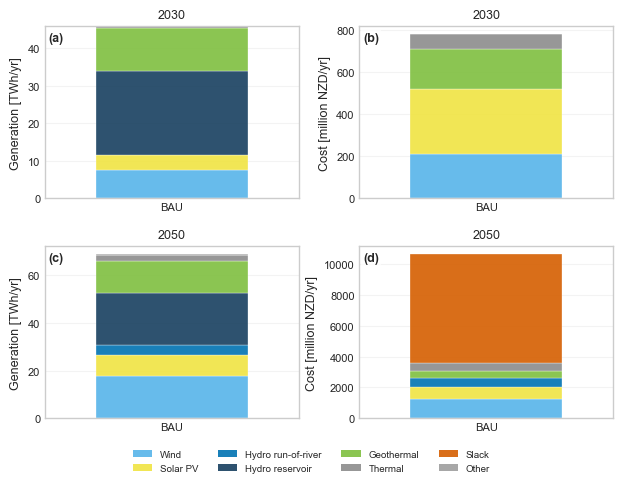

In [19]:
if not comparison_years:
    raise ValueError("None of the requested comparison years are available.")

nrows = len(comparison_years)
fig, axes = plt.subplots(
    nrows,
    2,
    figsize=(WORD_DOUBLE_COL_IN, 2.45 * nrows),
    squeeze=False,
)

used_groups = set()

for row_i, year in enumerate(comparison_years):
    df_y = scenario_comparison[scenario_comparison["year"] == year].copy()

    df_y = df_y[df_y["scenario"].isin(SCENARIO_TECH_LABELS.keys())].copy()

    if df_y.empty:
        raise ValueError(f"No selected scenarios found for year {year}.")

    df_y["_order"] = df_y["scenario"].map(SCENARIO_ORDER_RANK)
    df_y = df_y.sort_values("_order").drop(columns="_order").reset_index(drop=True)

    df_y["label"] = df_y["scenario"].map(SCENARIO_TECH_LABELS).fillna(df_y["scenario"].astype(str))

    generation_group_df = build_generation_group_df(df_y)
    cost_group_df = build_cost_group_df(df_y)

    ax_gen = axes[row_i, 0]
    groups = plot_stacked_bars(
        ax_gen,
        generation_group_df,
        TECH_GROUPS,
        TECH_COLORS_GROUPED,
        df_y["label"].tolist(),
        ylabel="Generation [TWh/yr]",
    )
    used_groups.update(groups)
    panel_label(ax_gen, f"({chr(97 + 2 * row_i)})")
    ax_gen.text(
        0.5,
        1.03,
        str(year),
        transform=ax_gen.transAxes,
        ha="center",
        va="bottom",
        fontsize=9,
        clip_on=False,
    )

    ax_cost = axes[row_i, 1]
    groups = plot_stacked_bars(
        ax_cost,
        cost_group_df,
        TECH_GROUPS,
        TECH_COLORS_GROUPED,
        df_y["label"].tolist(),
        ylabel=COST_AXIS_LABEL,
    )
    used_groups.update(groups)
    panel_label(ax_cost, f"({chr(98 + 2 * row_i)})")
    ax_cost.text(
        0.5,
        1.03,
        str(year),
        transform=ax_cost.transAxes,
        ha="center",
        va="bottom",
        fontsize=9,
        clip_on=False,
    )


# Shared legend
legend_handles = []
legend_labels = []

for group in TECH_GROUPS:
    if group not in used_groups:
        continue

    handle = plt.Rectangle(
        (0, 0),
        1,
        1,
        facecolor=TECH_COLORS_GROUPED.get(group, "#999999"),
        edgecolor="none",
        alpha=0.90,
    )
    legend_handles.append(handle)
    legend_labels.append(group)

fig.legend(
    legend_handles,
    legend_labels,
    loc="lower center",
    bbox_to_anchor=(0.5, 0.01),
    ncol=4,
    frameon=False,
    fontsize=7,
)

plt.tight_layout()
fig.subplots_adjust(top=0.94, bottom=0.20 if nrows == 1 else 0.14, hspace=0.28, wspace=0.24)

years_tag = "_".join(str(year) for year in comparison_years)
fig_path = save_paper_figure(
    fig,
    f"figure_cross_scenario_generation_cost_{years_tag}.png",
)
plt.show()


In [20]:
# Supplementary cross-scenario decomposition
required_plot_helpers = [
    "column_or_zero",
    "clean_technology_group",
    "sum_metric_by_group",
]
missing_plot_helpers = [
    name for name in required_plot_helpers
    if name not in globals()
]
if missing_plot_helpers:
    raise RuntimeError(
        "Run the configuration/helper cell before this figure. "
        f"Missing helpers: {missing_plot_helpers}"
    )

cross_scenario_years_to_plot = years
cross_scenario_export_dir = PAPER_FIGURE_DIR / "cross_scenario_all_years"
cross_scenario_export_dir.mkdir(parents=True, exist_ok=True)


def build_demand_group_df(df_year):
    """Build electricity-use decomposition [TWh/yr]."""
    out = pd.DataFrame(index=df_year.index)

    if demand_breakdown_summary.empty:
        raise ValueError("Demand breakdown is empty. Run the previous section first.")

    demand_y = demand_breakdown_summary[
        demand_breakdown_summary["year"] == int(df_year["year"].iloc[0])
    ].copy()
    demand_y = apply_scenario_order(demand_y)
    demand_y = demand_y.set_index("scenario").reindex(df_year["scenario"])

    mapping = {
        "Base load": "demand_base_load_mwh",
        "Heating": "demand_heating_mwh",
        "EVs": "demand_ev_mwh",
        "Cooking": "demand_cooking_mwh",
        "Process electrification": "demand_process_electrification_mwh",
        "Electrolyser": "electrolyser_input_mwh",
        "PtX auxiliaries": "ptx_aux_electricity_mwh",
        "Other local demand": "demand_other_mwh",
    }

    for group, col in mapping.items():
        if col in demand_y.columns:
            out[group] = demand_y[col].fillna(0.0).values / 1e6
        else:
            out[group] = 0.0

    for group in DEMAND_GROUPS:
        if group not in out.columns:
            out[group] = 0.0

    return out[DEMAND_GROUPS]


def _generator_metric_by_group(df_year, prefix, suffix, group):
    """Sum dynamic carrier columns assigned to one NZ technology group."""
    selected = []
    for column in df_year.columns:
        if not (str(column).startswith(prefix) and str(column).endswith(suffix)):
            continue
        carrier = _norm_carrier(
            str(column)[len(prefix):len(column) - len(suffix)]
        )
        mapped_group = clean_technology_group(carrier)
        if mapped_group == group:
            selected.append(column)

    if not selected:
        return pd.Series(0.0, index=df_year.index, dtype=float)

    return (
        df_year[selected]
        .apply(pd.to_numeric, errors="coerce")
        .fillna(0.0)
        .sum(axis=1)
    )


def build_dispatch_group_df(df_year):
    """Build annual electricity dispatch by NZ technology [TWh/yr]."""
    out = pd.DataFrame(index=df_year.index)

    for group in ["Wind", "Solar PV", *HYDRO_GROUPS, "Geothermal", "Thermal", "Slack", "Other"]:
        out[group] = (
            _generator_metric_by_group(
                df_year,
                prefix="generation_",
                suffix="_mwh",
                group=group,
            )
            / 1e6
        )

    out["BESS"] = column_or_zero(df_year, "bess_discharge_mwh") / 1e6

    if "h2_to_power_mwh" in df_year.columns:
        out["Hydrogen"] = column_or_zero(df_year, "h2_to_power_mwh") / 1e6
    else:
        out["Hydrogen"] = (
            column_or_zero(df_year, "h2_fuel_cell_output_mwh")
            + column_or_zero(df_year, "h2_turbine_output_mwh")
        ) / 1e6

    for group in TECH_GROUPS:
        if group not in out.columns:
            out[group] = 0.0

    return out[TECH_GROUPS]

def build_capacity_group_df(df_year):
    """Build installed power capacity by NZ technology [GW]."""
    out = pd.DataFrame(index=df_year.index)

    for group in ["Wind", "Solar PV", *HYDRO_GROUPS, "Geothermal", "Thermal", "Slack", "Other"]:
        out[group] = (
            _generator_metric_by_group(
                df_year,
                prefix="cap_",
                suffix="_mw",
                group=group,
            )
            / 1e3
        )

    out["BESS"] = column_or_zero(df_year, "cap_bess_mw") / 1e3

    hydrogen_columns = [
        "linkcap_electrolyzer_mw",
        "linkcap_h2_fuel_cell_mw",
        "linkcap_h2_turbine_mw",
    ]
    valid_hydrogen_columns = [
        column for column in hydrogen_columns if column in df_year.columns
    ]
    out["Hydrogen"] = (
        df_year[valid_hydrogen_columns]
        .apply(pd.to_numeric, errors="coerce")
        .fillna(0.0)
        .sum(axis=1)
        / 1e3
        if valid_hydrogen_columns
        else 0.0
    )

    for group in TECH_GROUPS:
        if group not in out.columns:
            out[group] = 0.0

    return out[TECH_GROUPS]

def plot_cross_scenario_supplementary(comparison_year, save_figure=True, show_figure=True):
    df_y = scenario_comparison[scenario_comparison["year"] == comparison_year].copy()

    if df_y.empty:
        raise ValueError(f"No scenario comparison data found for {comparison_year}.")

    df_y = apply_scenario_order(df_y).reset_index(drop=True)
    df_y["label"] = df_y["scenario"].map(SCENARIO_TECH_LABELS).fillna(df_y["scenario"].astype(str))

    demand_group_df = build_demand_group_df(df_y)
    dispatch_group_df = build_dispatch_group_df(df_y)
    capacity_group_df = build_capacity_group_df(df_y)
    cost_group_df = build_cost_group_df(df_y)

    fig, axes = plt.subplots(2, 2, figsize=FIGSIZE_PAPER_2X2)

    used_demand_groups = set()
    used_tech_groups = set()

    used = plot_stacked_bars(
        axes[0, 0],
        demand_group_df,
        DEMAND_GROUPS,
        DEMAND_COLORS_GROUPED,
        df_y["label"].tolist(),
        ylabel="Electricity use [TWh/yr]",
    )
    used_demand_groups.update(used)
    panel_label(axes[0, 0], "(a)")

    used = plot_stacked_bars(
        axes[0, 1],
        dispatch_group_df,
        TECH_GROUPS,
        TECH_COLORS_GROUPED,
        df_y["label"].tolist(),
        ylabel="Dispatch [TWh/yr]",
    )
    used_tech_groups.update(used)
    panel_label(axes[0, 1], "(b)")

    used = plot_stacked_bars(
        axes[1, 0],
        capacity_group_df,
        TECH_GROUPS,
        TECH_COLORS_GROUPED,
        df_y["label"].tolist(),
        ylabel="Capacity [GW]",
    )
    used_tech_groups.update(used)
    panel_label(axes[1, 0], "(c)")

    used = plot_stacked_bars(
        axes[1, 1],
        cost_group_df,
        TECH_GROUPS,
        TECH_COLORS_GROUPED,
        df_y["label"].tolist(),
        ylabel=COST_AXIS_LABEL,
    )
    used_tech_groups.update(used)
    panel_label(axes[1, 1], "(d)")

    fig.text(
        0.5,
        0.975,
        str(comparison_year),
        ha="center",
        va="top",
        fontsize=9,
    )

    # Figure-level legends
    demand_handles = []
    demand_labels = []
    for group in DEMAND_GROUPS:
        if group not in used_demand_groups:
            continue

        demand_handles.append(
            plt.Rectangle(
                (0, 0), 1, 1,
                facecolor=DEMAND_COLORS_GROUPED.get(group, "#999999"),
                edgecolor="none",
                alpha=0.90,
            )
        )
        demand_labels.append(DEMAND_LEGEND_LABELS.get(group, group))

    tech_handles = []
    tech_labels = []

    for group in TECH_GROUPS:
        if group not in used_tech_groups:
            continue

        tech_handles.append(
            plt.Rectangle(
                (0, 0), 1, 1,
                facecolor=TECH_COLORS_GROUPED.get(group, "#999999"),
                edgecolor="none",
                alpha=0.90,
            )
        )
        tech_labels.append(TECH_LEGEND_LABELS.get(group, group))

    leg1 = fig.legend(
        demand_handles,
        demand_labels,
        loc="lower center",
        bbox_to_anchor=(0.5, 0.095),
        ncol=4,
        frameon=False,
        fontsize=6.3,
        columnspacing=1.0,
        handlelength=1.4,
        handletextpad=0.4,
    )
    fig.add_artist(leg1)

    fig.legend(
        tech_handles,
        tech_labels,
        loc="lower center",
        bbox_to_anchor=(0.5, 0.025),
        ncol=4,
        frameon=False,
        fontsize=6.3,
        columnspacing=1.0,
        handlelength=1.4,
        handletextpad=0.4,
    )
    plt.tight_layout()
    fig.subplots_adjust(top=0.93, bottom=0.26, hspace=0.34, wspace=0.24)

    out_path = None
    if save_figure:
        out_path = save_paper_figure(
            fig,
            f"figure_supp_cross_scenario_decomposition_{comparison_year}.png",
            folder=cross_scenario_export_dir,
        )

    if show_figure:
        plt.show()
    else:
        plt.close(fig)

    return out_path


Saved figure: output\output_new_zealand\figures\cross_scenario_all_years\figure_supp_cross_scenario_decomposition_2025.png


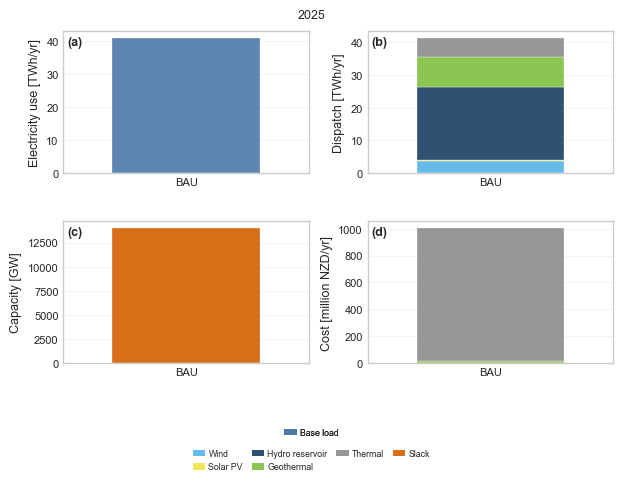

Saved figure: output\output_new_zealand\figures\cross_scenario_all_years\figure_supp_cross_scenario_decomposition_2030.png


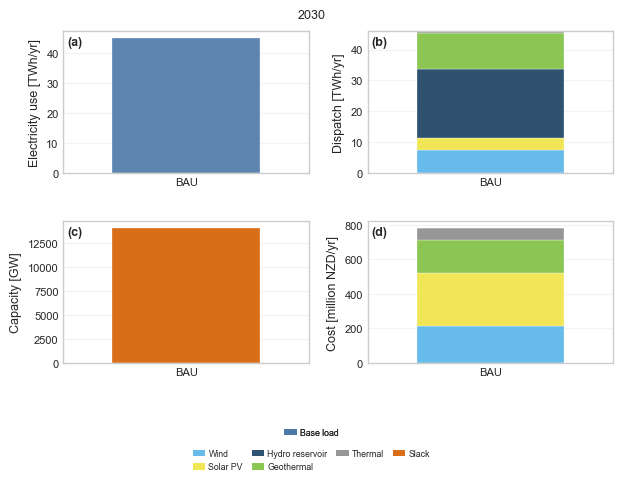

Saved figure: output\output_new_zealand\figures\cross_scenario_all_years\figure_supp_cross_scenario_decomposition_2040.png


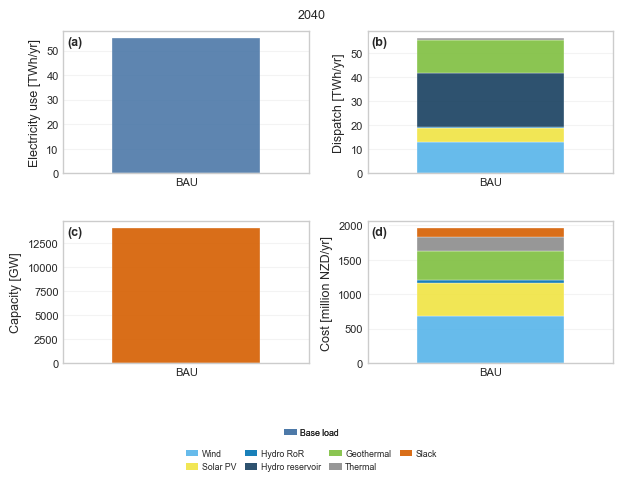

Saved figure: output\output_new_zealand\figures\cross_scenario_all_years\figure_supp_cross_scenario_decomposition_2050.png


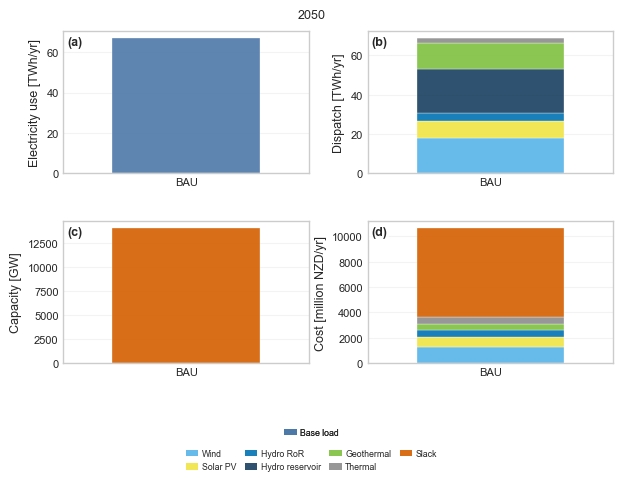

In [21]:
for comparison_year in cross_scenario_years_to_plot:
    plot_cross_scenario_supplementary(comparison_year)


In [22]:
# Former Figure 6 retired: retain only reliability indicators
#
# Storage/flexibility capacity and operation are now reported in the table
# exported by Figure 5 and in each scenario's *_bess_by_year.csv file.
comparison_year = detailed_year
df_y = scenario_comparison[scenario_comparison["year"] == comparison_year].copy()
if df_y.empty:
    raise ValueError(f"No scenario comparison data found for {comparison_year}.")
df_y = apply_scenario_order(df_y).reset_index(drop=True)

reliability_check = pd.DataFrame({
    "scenario": df_y["scenario"],
    "paper_id": df_y["paper_id"] if "paper_id" in df_y.columns else "",
    "year": df_y["year"],
    "slack_generation_gwh": df_y["slack_generation_mwh"].fillna(0.0) / 1e3,
    "curtailment_gwh": df_y["curtailment_total_mwh"].fillna(0.0) / 1e3,
})
display(reliability_check.round(3))


,scenario,paper_id,year,slack_generation_gwh,curtailment_gwh
0,reference,BAU,2050,70.291,1921.486


Saved figure: output\output_new_zealand\figures\cross_scenario_all_years\figure05_system_design_2050.png
Saved figure: output\output_new_zealand\figures\cross_scenario_all_years\figure05_system_design_2050.svg
Saved figure: output\output_new_zealand\figures\cross_scenario_all_years\figure05_system_design_2050.pdf


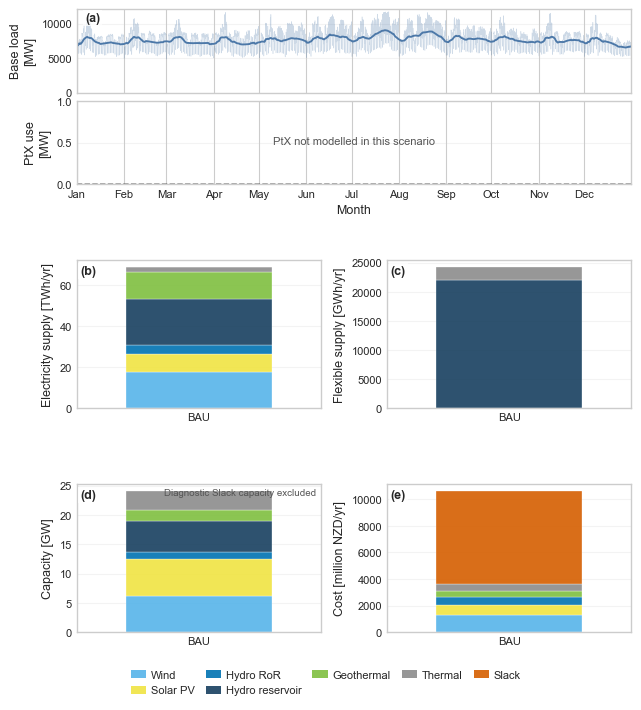

,Scenario,Thermal generation [GWh/yr],BESS discharge [GWh/yr],BESS power capacity [MW],BESS energy capacity [GWh],BESS duration [h],H2-to-power output [GWh/yr],H2 tank/other capacity [GWh],UHS capacity [GWh],BESS equivalent cycles [1/yr]
0,BAU,2197.586,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


Saved flexibility table to: output\output_new_zealand\tables\table_flexibility_requirements_2050.csv


In [23]:
# ─────────────────────────────────────────────────────────────────────────────
# Figure 5 — Demand, electricity supply, flexibility, capacity, and cost
#
# (a) Hourly local-demand components and PtX electricity use
# (b) Annual electricity supply
# (c) Annual flexible electricity supply
# (d) Installed power capacity
# (e) Annual system cost
#
# The former Figure 6 is exported below as a numerical table.
# ─────────────────────────────────────────────────────────────────────────────

import matplotlib.dates as mdates


# ── Configuration ────────────────────────────────────────────────────────────
comparison_year = detailed_year

figure5_export_dir = (
    PAPER_FIGURE_DIR
    / "cross_scenario_all_years"
)

figure5_export_dir.mkdir(
    parents=True,
    exist_ok=True,
)

# Use a PtX-enabled case when available; otherwise show the active reference case.
profile_scenario = next(
    (
        scenario_code
        for scenario_code, package in scenario_results.items()
        if package.get("metadata", {}).get("enable_ptx", False)
    ),
    active_scenario,
)


# ── Validation and scenario ordering ─────────────────────────────────────────
df_y = scenario_comparison[
    scenario_comparison["year"] == comparison_year
].copy()

if df_y.empty:
    raise ValueError(
        f"No scenario comparison data found for {comparison_year}."
    )

df_y = (
    apply_scenario_order(df_y)
    .reset_index(drop=True)
)

df_y["label"] = (
    df_y["scenario"]
    .map(SCENARIO_TECH_LABELS)
    .fillna(
        df_y["scenario"]
        .astype(str)
        .str.replace("_", " ", regex=False)
    )
)


# ── General helpers ──────────────────────────────────────────────────────────


def link_input_series(net, carriers):
    """Aggregate positive p0 electricity input for selected links [MW]."""
    snapshots = pd.Index(net.snapshots)

    if (
        len(net.links) == 0
        or not hasattr(net.links_t, "p0")
    ):
        return pd.Series(
            0.0,
            index=snapshots,
        )

    carriers = set(carriers)

    selected_links = net.links.index[
        net.links["carrier"]
        .astype(str)
        .isin(carriers)
    ]

    if len(selected_links) == 0:
        return pd.Series(
            0.0,
            index=snapshots,
        )

    return (
        net.links_t.p0
        .reindex(
            index=snapshots,
            columns=selected_links,
            fill_value=0.0,
        )
        .clip(lower=0.0)
        .sum(axis=1)
    )


# ── Annual electricity supply ────────────────────────────────────────────────

# ── Annual flexible electricity supply ──────────────────────────────────────
FLEXIBILITY_GROUPS = [
    "Hydro reservoir",
    "Thermal",
    "BESS",
    "Hydrogen",
]

# Diagnostic Slack has intentionally large nominal capacity and is therefore
# excluded only from the installed-capacity panel. Its generation and cost
# remain visible in the corresponding panels and summary tables.
CAPACITY_GROUPS = [
    group for group in TECH_GROUPS
    if group != "Slack"
]


def build_flexibility_group_df(df_year):
    """Build annual flexible electricity supply [GWh/yr]."""
    out = pd.DataFrame(index=df_year.index)

    out["Hydro reservoir"] = (
        _generator_metric_by_group(
            df_year,
            prefix="generation_",
            suffix="_mwh",
            group="Hydro reservoir",
        )
        / 1e3
    )
    out["Thermal"] = (
        _generator_metric_by_group(
            df_year,
            prefix="generation_",
            suffix="_mwh",
            group="Thermal",
        )
        / 1e3
    )
    out["BESS"] = column_or_zero(df_year, "bess_discharge_mwh") / 1e3
    out["Hydrogen"] = column_or_zero(df_year, "h2_to_power_mwh") / 1e3

    return out[FLEXIBILITY_GROUPS]


# ── Installed capacity ───────────────────────────────────────────────────────

# Remove diagnostic Slack from the plotted capacity mix while preserving it in
# scenario_comparison and carrier_diagnostic.
def build_capacity_plot_df(df_year):
    return build_capacity_group_df(df_year)[CAPACITY_GROUPS]

# ── Prepare annual panel data ────────────────────────────────────────────────
dispatch_group_df = build_dispatch_group_df(df_y)
flexibility_group_df = build_flexibility_group_df(df_y)
capacity_group_df = build_capacity_plot_df(df_y)
cost_group_df = build_cost_group_df(df_y)


# ── Prepare hourly demand-component and PtX profiles ─────────────────────────
profile_package = scenario_results[profile_scenario]

if comparison_year not in profile_package["results"]:
    raise ValueError(
        f"{profile_scenario} has no result for {comparison_year}."
    )

profile_result = profile_package["results"][comparison_year]
profile_net = profile_result["network"]


def normalise_profile_index(values):
    """Return a timezone-naive DatetimeIndex for profile alignment."""
    index = pd.DatetimeIndex(
        pd.to_datetime(values)
    )

    if index.tz is not None:
        index = index.tz_localize(None)

    return index


profile_snapshots = normalise_profile_index(
    profile_net.snapshots
)

demand_components_df, demand_components_path, _ = (
    load_demand_components_for_scenario(
        profile_scenario,
        package=profile_package,
    )
)

if (
    demand_components_df.empty
    or "timestamp" not in demand_components_df.columns
    or "year" not in demand_components_df.columns
):
    # NZ reference runs may only export the aggregate electricity load.
    # Use it as one Base-load component so Figure 5 remains self-contained.
    aggregate_load = profile_result["load"].load()
    component_profiles = pd.DataFrame(
        {"base_load": aggregate_load.sum(axis=1).to_numpy()},
        index=aggregate_load.index,
    )
    demand_components_path = Path("aggregate load export")
else:
    component_year = demand_components_df[
        pd.to_numeric(demand_components_df["year"], errors="coerce")
        .eq(int(comparison_year))
    ].copy()

    if component_year.empty:
        aggregate_load = profile_result["load"].load()
        component_profiles = pd.DataFrame(
            {"base_load": aggregate_load.sum(axis=1).to_numpy()},
            index=aggregate_load.index,
        )
        demand_components_path = Path("aggregate load export")
    else:
        component_year["component_key"] = (
            component_year["component"]
            .map(_safe_component_name)
        )
        component_profiles = (
            component_year
            .pivot_table(
                index="timestamp",
                columns="component_key",
                values="demand_mw",
                aggfunc="sum",
                fill_value=0.0,
            )
            .sort_index()
        )

component_profiles.index = normalise_profile_index(
    component_profiles.index
)

# Sum duplicated timestamps, if any, after aggregating zones.
component_profiles = (
    component_profiles
    .groupby(level=0)
    .sum()
    .sort_index()
)

# If the CSV uses another calendar year but preserves the hourly sequence,
# align it by position with the solved network.
if not component_profiles.index.equals(profile_snapshots):
    if len(component_profiles) != len(profile_snapshots):
        raise ValueError(
            "Demand-component profiles cannot be aligned with the solved "
            f"network: {len(component_profiles)} component timestamps versus "
            f"{len(profile_snapshots)} network snapshots."
        )

    component_profiles.index = profile_snapshots

component_profiles = (
    component_profiles
    .apply(pd.to_numeric, errors="coerce")
    .fillna(0.0)
    .clip(lower=0.0)
)

# Stable paper order, followed automatically by any future component.
active_components = [
    component
    for component in component_profiles.columns
    if component_profiles[component].abs().max() > 1e-9
]

preferred_component_order = [
    "base_load",
    "heating",
    "ev",
    "cooking",
    "process_electrification",
    "other",
]

profile_component_order = [
    component
    for component in preferred_component_order
    if component in active_components
]

profile_component_order += sorted(
    component
    for component in active_components
    if component not in profile_component_order
)

if not profile_component_order:
    raise ValueError(
        f"No active electricity-demand components were found for "
        f"{comparison_year} in {demand_components_path}."
    )

component_profiles = component_profiles[
    profile_component_order
]

component_rolling = (
    component_profiles
    .rolling(
        window=168,
        center=True,
        min_periods=24,
    )
    .mean()
)

# PtX remains separate because it is optimised flexible electricity use,
# rather than an exogenous component from demand_components_<scenario>.csv.
electrolyser_use = link_input_series(
    profile_net,
    ["electrolyzer"],
)

ptx_aux_use = link_input_series(
    profile_net,
    ["asu", "dac"],
)

ptx_profile = pd.DataFrame(
    {
        "Electrolyser": electrolyser_use.to_numpy(),
        "PtX auxiliaries": ptx_aux_use.to_numpy(),
    },
    index=profile_snapshots,
)

ptx_profile = (
    ptx_profile
    .sort_index()
    .clip(lower=0.0)
)

ptx_rolling = (
    ptx_profile
    .rolling(
        window=168,
        center=True,
        min_periods=24,
    )
    .mean()
)

ptx_total = (
    ptx_profile["Electrolyser"]
    + ptx_profile["PtX auxiliaries"]
)

ptx_total_rolling = (
    ptx_rolling["Electrolyser"]
    + ptx_rolling["PtX auxiliaries"]
)


# ── Figure layout ────────────────────────────────────────────────────────────
n_profile_axes = len(profile_component_order) + 1
additional_profile_axes = max(0, n_profile_axes - 2)

# Increase figure height as new demand components appear.
figure_height = 7.20 + 0.72 * additional_profile_axes
profile_height_ratio = 1.18 * n_profile_axes / 2.0

fig = plt.figure(
    figsize=(
        WORD_DOUBLE_COL_IN,
        figure_height,
    )
)

outer_gs = fig.add_gridspec(
    nrows=3,
    ncols=2,
    height_ratios=[
        profile_height_ratio,
        1.0,
        1.0,
    ],
    hspace=0.48,
    wspace=0.27,
)

# One strip per local-demand component, followed by a separate PtX strip.
profile_gs = outer_gs[0, :].subgridspec(
    nrows=n_profile_axes,
    ncols=1,
    height_ratios=[1.0] * n_profile_axes,
    hspace=0.10,
)

profile_axes = []

for row_index in range(len(profile_component_order)):
    axis = fig.add_subplot(
        profile_gs[row_index, 0],
        sharex=profile_axes[0] if profile_axes else None,
    )
    profile_axes.append(axis)

ax_a_ptx = fig.add_subplot(
    profile_gs[-1, 0],
    sharex=profile_axes[0],
)

ax_b = fig.add_subplot(outer_gs[1, 0])
ax_c = fig.add_subplot(outer_gs[1, 1])
ax_d = fig.add_subplot(outer_gs[2, 0])
ax_e = fig.add_subplot(outer_gs[2, 1])


# ── (a) Hourly local-demand components and PtX electricity use ───────────────
electrolyser_color = DEMAND_COLORS_GROUPED.get(
    "Electrolyser",
    TECH_COLORS.get(
        "electrolyzer",
        "#00897b",
    ),
)

ptx_aux_color = DEMAND_COLORS_GROUPED.get(
    "PtX auxiliaries",
    TECH_COLORS.get(
        "asu",
        "#80cbc4",
    ),
)

fallback_component_colors = plt.get_cmap("tab10")

for component_index, (axis, component) in enumerate(
    zip(
        profile_axes,
        profile_component_order,
    )
):
    component_label = DEMAND_COMPONENT_LABELS.get(
        component,
        component.replace("_", " ").title(),
    )

    component_color = DEMAND_COMPONENT_COLORS.get(
        component,
        fallback_component_colors(
            component_index % 10
        ),
    )

    # Thin line: hourly profile.
    axis.plot(
        component_profiles.index,
        component_profiles[component],
        color=component_color,
        linewidth=0.35,
        alpha=0.28,
    )

    # Thick line: seven-day rolling average.
    axis.plot(
        component_rolling.index,
        component_rolling[component],
        color=component_color,
        linewidth=1.35,
    )

    axis.set_ylabel(
        f"{component_label}\n[MW]"
    )

    axis.set_ylim(bottom=0.0)

    axis.grid(
        axis="y",
        alpha=0.22,
    )

    axis.set_axisbelow(True)

    axis.tick_params(
        axis="x",
        labelbottom=False,
    )

panel_label(
    profile_axes[0],
    "(a)",
)

# PtX electricity use: stacked hourly areas and seven-day total mean.
ax_a_ptx.fill_between(
    ptx_profile.index,
    0.0,
    ptx_profile["Electrolyser"],
    color=electrolyser_color,
    alpha=0.82,
    linewidth=0.0,
    step="mid",
    label="Electrolyser",
)

ax_a_ptx.fill_between(
    ptx_profile.index,
    ptx_profile["Electrolyser"],
    ptx_total,
    color=ptx_aux_color,
    alpha=0.82,
    linewidth=0.0,
    step="mid",
    label="PtX auxiliaries",
)

ax_a_ptx.plot(
    ptx_total_rolling.index,
    ptx_total_rolling,
    color="black",
    linewidth=1.05,
    linestyle="--",
    label="Total PtX: 7-day mean",
)

ax_a_ptx.set_ylabel(
    "PtX use\n[MW]"
)

ax_a_ptx.set_ylim(bottom=0.0)

ax_a_ptx.set_xlabel(
    "Month"
)

ax_a_ptx.grid(
    axis="y",
    alpha=0.22,
)

ax_a_ptx.set_axisbelow(True)

ax_a_ptx.xaxis.set_major_locator(
    mdates.MonthLocator()
)

ax_a_ptx.xaxis.set_major_formatter(
    mdates.DateFormatter("%b")
)

ax_a_ptx.set_xlim(
    profile_snapshots.min(),
    profile_snapshots.max(),
)

if float(ptx_total.max()) > 1e-6:
    ax_a_ptx.legend(
        loc="upper center",
        bbox_to_anchor=(0.5, -0.36),
        ncol=3,
        frameon=False,
        fontsize=FONT_SIZE_SMALL,
        columnspacing=1.1,
        handlelength=1.5,
        handletextpad=0.4,
    )
else:
    # Keep the PtX panel in the workflow, but make the inactive case explicit
    # instead of showing a misleading 0.00–0.04 MW axis and zero-value legend.
    ax_a_ptx.set_ylim(0.0, 1.0)
    ax_a_ptx.text(
        0.5,
        0.52,
        "PtX not modelled in this scenario",
        transform=ax_a_ptx.transAxes,
        ha="center",
        va="center",
        fontsize=FONT_SIZE_SMALL,
        color="#555555",
    )


# ── (b) Annual electricity supply ───────────────────────────────────────────
used_tech_groups = set()

used = plot_stacked_bars(
    ax_b,
    dispatch_group_df,
    TECH_GROUPS,
    TECH_COLORS_GROUPED,
    df_y["label"].tolist(),
    ylabel="Electricity supply [TWh/yr]",
)

used_tech_groups.update(used)

panel_label(
    ax_b,
    "(b)",
)


# ── (c) Annual flexible electricity supply ──────────────────────────────────
used = plot_stacked_bars(
    ax_c,
    flexibility_group_df,
    FLEXIBILITY_GROUPS,
    TECH_COLORS_GROUPED,
    df_y["label"].tolist(),
    ylabel="Flexible supply [GWh/yr]",
)

used_tech_groups.update(used)

panel_label(
    ax_c,
    "(c)",
)


# ── (d) Installed power capacity ─────────────────────────────────────────────
used = plot_stacked_bars(
    ax_d,
    capacity_group_df,
    CAPACITY_GROUPS,
    TECH_COLORS_GROUPED,
    df_y["label"].tolist(),
    ylabel="Capacity [GW]",
)

used_tech_groups.update(used)

panel_label(
    ax_d,
    "(d)",
)
ax_d.text(
    0.98,
    0.97,
    "Diagnostic Slack capacity excluded",
    transform=ax_d.transAxes,
    ha="right",
    va="top",
    fontsize=FONT_SIZE_SMALL - 1,
    color="#555555",
)


# ── (e) Annual system cost ───────────────────────────────────────────────────
used = plot_stacked_bars(
    ax_e,
    cost_group_df,
    TECH_GROUPS,
    TECH_COLORS_GROUPED,
    df_y["label"].tolist(),
    ylabel=COST_AXIS_LABEL,
)

used_tech_groups.update(used)

panel_label(
    ax_e,
    "(e)",
)


# ── Shared technology legend ─────────────────────────────────────────────────
tech_handles = []
tech_labels = []

for group in TECH_GROUPS:
    if group not in used_tech_groups:
        continue

    tech_handles.append(
        plt.Rectangle(
            (0, 0),
            1,
            1,
            facecolor=TECH_COLORS_GROUPED.get(
                group,
                "#999999",
            ),
            edgecolor="none",
            alpha=0.90,
        )
    )

    tech_labels.append(
        TECH_LEGEND_LABELS.get(
            group,
            group,
        )
    )

fig.legend(
    tech_handles,
    tech_labels,
    loc="lower center",
    bbox_to_anchor=(0.5, 0.018),
    ncol=5,
    frameon=False,
    fontsize=FONT_SIZE_SMALL,
    columnspacing=1.0,
    handlelength=1.4,
    handletextpad=0.4,
)


# ── Final figure spacing ─────────────────────────────────────────────────────
fig.subplots_adjust(
    top=0.985,
    bottom=0.12,
    left=0.105,
    right=0.985,
)


# ── Export Figure 5 ──────────────────────────────────────────────────────────
figure5_paths = []

for extension in [
    "png",
    "svg",
    "pdf",
]:
    figure5_paths.append(
        save_paper_figure(
            fig,
            (
                f"figure05_system_design_"
                f"{comparison_year}.{extension}"
            ),
            folder=figure5_export_dir,
        )
    )

plt.show()


# ─────────────────────────────────────────────────────────────────────────────
# Table replacing the former Figure 6
# ─────────────────────────────────────────────────────────────────────────────
bess_power_mw = column_or_zero(
    df_y,
    "cap_bess_mw",
)

bess_energy_mwh = column_or_zero(
    df_y,
    "energy_bess_mwh",
)

bess_duration_h = (
    bess_energy_mwh
    .div(
        bess_power_mw.replace(
            0.0,
            np.nan,
        )
    )
    .fillna(0.0)
)

flexibility_table = pd.DataFrame(
    {
        "Scenario": df_y["label"],
        "Thermal generation [GWh/yr]": (
            column_or_zero(
                df_y,
                "thermal_generation_mwh",
            )
            / 1e3
        ),
        "BESS discharge [GWh/yr]": (
            column_or_zero(
                df_y,
                "bess_discharge_mwh",
            )
            / 1e3
        ),
        "BESS power capacity [MW]": bess_power_mw,
        "BESS energy capacity [GWh]": (
            bess_energy_mwh
            / 1e3
        ),
        "BESS duration [h]": bess_duration_h,
        "H2-to-power output [GWh/yr]": (
            column_or_zero(
                df_y,
                "h2_to_power_mwh",
            )
            / 1e3
        ),
        "H2 tank/other capacity [GWh]": (
            column_or_zero(
                df_y,
                "h2_storage_total_mwh",
            )
            / 1e3
        ),
        "UHS capacity [GWh]": (
            column_or_zero(
                df_y,
                "uhs_storage_total_mwh",
            )
            / 1e3
        ),
    }
)

flexibility_table["BESS equivalent cycles [1/yr]"] = (
    flexibility_table["BESS discharge [GWh/yr]"]
    .div(
        flexibility_table["BESS energy capacity [GWh]"]
        .replace(0.0, np.nan)
    )
    .fillna(0.0)
)

flexibility_table_path = (
    TABLE_EXPORT_DIR
    / f"table_flexibility_requirements_{comparison_year}.csv"
)

flexibility_table.to_csv(
    flexibility_table_path,
    index=False,
)

display(
    flexibility_table.round(3)
)

print(
    f"Saved flexibility table to: "
    f"{flexibility_table_path}"
)


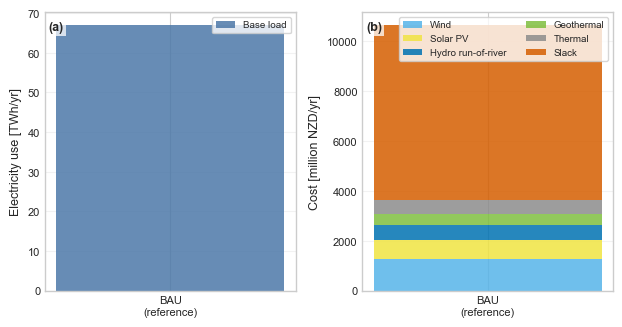

In [24]:
# Demand and cost decomposition figure
if demand_breakdown_summary.empty:
    raise ValueError("Run the demand/cost breakdown cell first.")

demand_y = apply_scenario_order(demand_breakdown_summary[demand_breakdown_summary["year"] == breakdown_year])
demand_y["label"] = [scenario_axis_label(s) for s in demand_y["scenario"]]

x = np.arange(len(demand_y))
fig, axes = plt.subplots(1, 2, figsize=FIGSIZE_2COL)

# (a) Electricity-use decomposition from demand_profiles_scenarios + PtX link use
ax = axes[0]
component_stack = [
    ("demand_base_load_mwh", "Base load", DEMAND_COMPONENT_COLORS.get("base_load", "#4c78a8")),
    ("demand_heating_mwh", "Heating", DEMAND_COMPONENT_COLORS.get("heating", "#f58518")),
    ("demand_ev_mwh", "EVs", DEMAND_COMPONENT_COLORS.get("ev", "#54a24b")),
    ("demand_cooking_mwh", "Cooking", DEMAND_COMPONENT_COLORS.get("cooking", "#b279a2")),
    ("demand_process_electrification_mwh", "Process electrification", DEMAND_COMPONENT_COLORS.get("process_electrification", "#e45756")),
    ("demand_other_mwh", "Other local demand", DEMAND_COMPONENT_COLORS.get("other", "#9e9e9e")),
    ("electrolyser_input_mwh", "Electrolyser", DEMAND_COMPONENT_COLORS.get("electrolyser", TECH_COLORS.get("electrolyzer", "#00897b"))),
    ("ptx_aux_electricity_mwh", "PtX auxiliaries", DEMAND_COMPONENT_COLORS.get("ptx_aux", TECH_COLORS.get("asu", "#80cbc4"))),
]
component_stack = [
    item for item in component_stack
    if item[0] in demand_y.columns and demand_y[item[0]].fillna(0).sum() > 1e-6
]

bottom = np.zeros(len(demand_y))
for col, label, color in component_stack:
    vals = demand_y[col].fillna(0).values / 1e6
    ax.bar(x, vals, bottom=bottom, label=label, color=color, alpha=0.85)
    bottom += vals

ax.set_xticks(x)
ax.set_xticklabels(demand_y["label"], rotation=0, ha="center")
finish_axis(ax, ylabel="Electricity use [TWh/yr]")
ax.legend(frameon=True, ncol=2, fontsize=7)
panel_label(ax, "(a)")

# (b) Approximate cost decomposition
ax = axes[1]
if cost_breakdown_summary.empty:
    ax.text(0.5, 0.5, "No cost breakdown available", ha="center", va="center", transform=ax.transAxes)
else:
    cost_y = cost_breakdown_summary[cost_breakdown_summary["year"] == breakdown_year].copy()
    group_order = TECH_GROUPS
    pivot = (
        cost_y.pivot_table(index="scenario", columns="group", values="total_cost", aggfunc="sum")
        .reindex(demand_y["scenario"])
        .fillna(0.0)
    )
    bottom = np.zeros(len(pivot))
    for group in [g for g in group_order if g in pivot.columns and pivot[g].sum() > 0]:
        vals = pivot[group].values / 1e6
        ax.bar(x, vals, bottom=bottom, label=group, color=TECH_COLORS_GROUPED.get(group, "#999999"), alpha=0.85)
        bottom += vals

ax.set_xticks(x)
ax.set_xticklabels(demand_y["label"], rotation=0, ha="center")
finish_axis(ax, ylabel=COST_AXIS_LABEL)
ax.legend(frameon=True, ncol=2, fontsize=7)
panel_label(ax, "(b)")

plt.tight_layout()
plt.show()


### 3.5 Average system-cost indicators


,scenario,paper_label,model_year,model_objective_usd,local_demand_mwh,flexible_final_use_mwh,total_final_electricity_use_mwh,slack_energy_mwh,slack_cost_usd,slack_cost_share_pct,asce_local_demand_usd_per_mwh,asce_total_final_use_usd_per_mwh,asce_local_excluding_slack_usd_per_mwh,asce_total_excluding_slack_usd_per_mwh
0,reference,reference,2025,9.901091e+08,40819610.18,0.0,40819610.18,0.00,0.000000e+00,0.00,24.26,24.26,24.26,24.26
1,reference,reference,2030,7.664507e+08,45068156.03,0.0,45068156.03,4.07,4.073069e+05,0.05,17.01,17.01,17.00,17.00
2,reference,reference,2040,1.226765e+09,55089319.59,0.0,55089319.59,1354.46,1.354461e+08,11.04,22.27,22.27,19.81,19.81
3,reference,reference,2050,8.937073e+09,66968897.38,0.0,66968897.38,70291.48,7.029148e+09,78.65,133.45,133.45,28.49,28.49


Saved figure: output\output_new_zealand\figures\figure_average_system_cost_2050.png


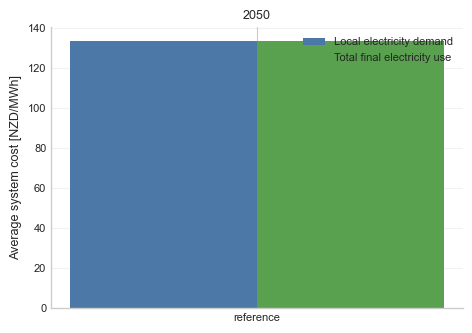

Saved system-cost summary to: output\output_new_zealand\tables\average_system_cost_by_scenario.csv


In [25]:
# Average system cost of electricity by scenario and model year
#
# Indicators:
#   1. ASCE – local demand:
#      model objective / local electricity demand
#
#   2. ASCE – total final electricity use:
#      model objective / (local demand + PtX/flexible final uses)
#
# BESS/storage charging is excluded from final electricity use.

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pathlib import Path
from matplotlib.ticker import FuncFormatter


# ── Configuration ─────────────────────────────────────────────────────────────
COST_CURRENCY = "NZD"

# Flexible electricity uses counted as final consumption.
# Add another carrier here if necessary.
FINAL_USE_PATTERN = (
    r"electroly[sz]er|electrolysis|asu|dac|"
    r"ammonia|methanol|heat_pump|electric_heating"
)

# Storage charging is deliberately excluded from the denominator.
STORAGE_CHARGE_PATTERN = (
    r"bess|battery|storage|store|charge|pumped"
)

cost_plot_year = globals().get(
    "detailed_year",
    2050,
)


# ── Helpers ───────────────────────────────────────────────────────────────────
def _cost_scenario_label(scenario_code):
    if callable(
        globals().get(
            "_short_scenario_label"
        )
    ):
        return _short_scenario_label(
            scenario_code
        )

    text = (
        str(scenario_code)
        .upper()
        .replace("-", "_")
    )

    if "REFERENCE" in text:
        return "Reference"

    if "PTX" in text:
        return "PtX"

    for label in ["BAU", "RT", "RE", "RH"]:
        if label in text.split("_"):
            return label

    return (
        str(scenario_code)
        .replace("_base", "")
        .replace("_BASE", "")
    )


def _annual_snapshot_weights(net, index):
    """Return strictly one-dimensional objective weights."""

    snapshot_weightings = net.snapshot_weightings

    # Extract only the objective column
    try:
        raw_weights = snapshot_weightings["objective"]
    except (KeyError, TypeError, IndexError):
        try:
            raw_weights = snapshot_weightings.objective
        except AttributeError:
            raw_weights = snapshot_weightings

    values = np.asarray(
        raw_weights,
        dtype=float,
    )

    # Extra protection if three columns are still returned
    if values.ndim == 2:
        values = values[:, 0]

    values = values.reshape(-1)

    if len(values) != len(index):
        raise ValueError(
            "Snapshot-weight length mismatch: "
            f"{len(values)} weights for {len(index)} snapshots."
        )

    return pd.Series(
        values,
        index=index,
        dtype=float,
    )


def _local_electricity_load(result):
    """Return total local electricity demand [MW]."""
    load = result.get(
        "load"
    )

    if load is None:
        net = result["network"]

        load = getattr(
            net.loads_t,
            "p_set",
            pd.DataFrame(
                index=net.snapshots
            ),
        )

    if isinstance(
        load,
        pd.Series,
    ):
        output = load.copy()

    else:
        output = (
            load
            .apply(
                pd.to_numeric,
                errors="coerce",
            )
            .fillna(0.0)
            .sum(axis=1)
        )

    return (
        pd.to_numeric(
            output,
            errors="coerce",
        )
        .fillna(0.0)
        .clip(lower=0.0)
    )


def _final_flexible_electricity_use(net):
    """
    Return PtX and other final flexible electricity uses [MW].

    Uses the previously defined electricity-balance helper.
    BESS and other storage charging are excluded.
    """
    if not callable(
        globals().get(
            "_electricity_balance_for_network"
        )
    ):
        return pd.Series(
            0.0,
            index=net.snapshots,
        )

    _, consumption = (
        _electricity_balance_for_network(
            net
        )
    )

    if consumption is None or consumption.empty:
        return pd.Series(
            0.0,
            index=net.snapshots,
        )

    consumption = (
        consumption
        .apply(
            pd.to_numeric,
            errors="coerce",
        )
        .fillna(0.0)
        .clip(lower=0.0)
    )

    final_use_columns = []

    for column in consumption.columns:
        carrier = str(
            column
        )

        is_final_use = bool(
            pd.Series([carrier])
            .str.contains(
                FINAL_USE_PATTERN,
                case=False,
                regex=True,
                na=False,
            )
            .iloc[0]
        )

        is_storage_charging = bool(
            pd.Series([carrier])
            .str.contains(
                STORAGE_CHARGE_PATTERN,
                case=False,
                regex=True,
                na=False,
            )
            .iloc[0]
        )

        if (
            is_final_use
            and not is_storage_charging
        ):
            final_use_columns.append(
                column
            )

    if not final_use_columns:
        return pd.Series(
            0.0,
            index=consumption.index,
        )

    return (
        consumption[
            final_use_columns
        ]
        .sum(axis=1)
    )


def _slack_cost_and_energy(net, weights):
    """Estimate slack generation and its variable cost."""
    if not hasattr(
        net,
        "generators",
    ):
        return 0.0, 0.0

    carriers = (
        net.generators.get(
            "carrier",
            pd.Series(
                "",
                index=net.generators.index,
            ),
        )
        .astype(str)
    )

    slack_generators = (
        net.generators.index[
            carriers.str.contains(
                "slack",
                case=False,
                na=False,
            )
        ]
    )

    generator_dispatch = getattr(
        net.generators_t,
        "p",
        pd.DataFrame(
            index=net.snapshots
        ),
    )

    slack_generators = [
        generator
        for generator in slack_generators
        if generator
        in generator_dispatch.columns
    ]

    if not slack_generators:
        return 0.0, 0.0

    slack_dispatch = (
        generator_dispatch[
            slack_generators
        ]
        .apply(
            pd.to_numeric,
            errors="coerce",
        )
        .fillna(0.0)
        .clip(lower=0.0)
    )

    slack_energy_by_generator = (
        slack_dispatch
        .mul(
            weights,
            axis=0,
        )
        .sum(axis=0)
    )

    marginal_cost = (
        pd.to_numeric(
            net.generators.loc[
                slack_generators,
                "marginal_cost",
            ],
            errors="coerce",
        )
        .fillna(0.0)
    )

    slack_cost = float(
        (
            slack_energy_by_generator
            * marginal_cost
        ).sum()
    )

    slack_energy = float(
        slack_energy_by_generator.sum()
    )

    return (
        slack_cost,
        slack_energy,
    )


# ── Calculate indicators ─────────────────────────────────────────────────────
system_cost_rows = []

for scenario_code, scenario_package in scenario_results.items():

    for model_year, result in (
        scenario_package["results"].items()
    ):
        net = result["network"]

        local_load = (
            _local_electricity_load(
                result
            )
        )

        flexible_final_use = (
            _final_flexible_electricity_use(
                net
            )
        )

        flexible_final_use = (
            flexible_final_use
            .reindex(
                local_load.index
            )
            .fillna(0.0)
        )

        weights = _annual_snapshot_weights(
            net,
            local_load.index,
        )

        local_demand_mwh = float(
            (
                local_load
                * weights
            ).sum()
        )

        flexible_final_use_mwh = float(
            (
                flexible_final_use
                * weights
            ).sum()
        )

        total_final_use_mwh = (
            local_demand_mwh
            + flexible_final_use_mwh
        )

        objective_value = float(
            getattr(
                net,
                "objective",
                np.nan,
            )
        )

        slack_cost_usd, slack_energy_mwh = (
            _slack_cost_and_energy(
                net,
                weights,
            )
        )

        system_cost_excluding_slack = (
            objective_value
            - slack_cost_usd
            if np.isfinite(objective_value)
            else np.nan
        )

        system_cost_rows.append(
            {
                "scenario": scenario_code,
                "paper_label": (
                    _cost_scenario_label(
                        scenario_code
                    )
                ),
                "model_year": int(
                    model_year
                ),
                "model_objective_usd": (
                    objective_value
                ),
                "local_demand_mwh": (
                    local_demand_mwh
                ),
                "flexible_final_use_mwh": (
                    flexible_final_use_mwh
                ),
                "total_final_electricity_use_mwh": (
                    total_final_use_mwh
                ),
                "slack_energy_mwh": (
                    slack_energy_mwh
                ),
                "slack_cost_usd": (
                    slack_cost_usd
                ),
                "slack_cost_share_pct": (
                    100.0
                    * slack_cost_usd
                    / objective_value
                    if objective_value > 0.0
                    else np.nan
                ),
                "asce_local_demand_usd_per_mwh": (
                    objective_value
                    / local_demand_mwh
                    if local_demand_mwh > 0.0
                    else np.nan
                ),
                "asce_total_final_use_usd_per_mwh": (
                    objective_value
                    / total_final_use_mwh
                    if total_final_use_mwh > 0.0
                    else np.nan
                ),
                "asce_local_excluding_slack_usd_per_mwh": (
                    system_cost_excluding_slack
                    / local_demand_mwh
                    if local_demand_mwh > 0.0
                    else np.nan
                ),
                "asce_total_excluding_slack_usd_per_mwh": (
                    system_cost_excluding_slack
                    / total_final_use_mwh
                    if total_final_use_mwh > 0.0
                    else np.nan
                ),
            }
        )


system_cost_summary = (
    pd.DataFrame(
        system_cost_rows
    )
    .sort_values(
        [
            "model_year",
            "paper_label",
        ]
    )
    .reset_index(drop=True)
)

display(
    system_cost_summary.round(2)
)


# ── Plot selected year ────────────────────────────────────────────────────────
plot_data = (
    system_cost_summary.loc[
        system_cost_summary[
            "model_year"
        ].eq(cost_plot_year)
    ]
    .copy()
)

scenario_order = ["Reference"]

plot_data["scenario_order"] = (
    plot_data["paper_label"]
    .map(
        {
            label: position
            for position, label
            in enumerate(scenario_order)
        }
    )
    .fillna(99)
)

plot_data = (
    plot_data
    .sort_values(
        "scenario_order"
    )
)


fig, ax = plt.subplots(
    figsize=(
        globals().get(
            "WORD_SINGLE_COL_IN",
            4.8,
        ),
        3.4,
    )
)

x_positions = np.arange(
    len(plot_data)
)

bar_width = 0.36

ax.bar(
    x_positions - bar_width / 2,
    plot_data[
        "asce_local_demand_usd_per_mwh"
    ],
    width=bar_width,
    color="#4c78a8",
    label="Local electricity demand",
)

ax.bar(
    x_positions + bar_width / 2,
    plot_data[
        "asce_total_final_use_usd_per_mwh"
    ],
    width=bar_width,
    color="#59a14f",
    label="Total final electricity use",
)

ax.set_xticks(
    x_positions
)

ax.set_xticklabels(
    plot_data["paper_label"]
)

ax.set_ylabel(
    f"Average system cost [{COST_CURRENCY}/MWh]"
)

ax.set_title(
    str(cost_plot_year)
)

ax.grid(
    axis="y",
    alpha=0.25,
)

ax.set_axisbelow(True)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

ax.legend(
    frameon=False,
    fontsize=8,
)

fig.tight_layout()

if callable(
    globals().get(
        "save_paper_figure"
    )
):
    average_cost_figure_path = (
        save_paper_figure(
            fig,
            (
                "figure_average_system_cost_"
                f"{cost_plot_year}.png"
            ),
        )
    )

plt.show()


# ── Export ────────────────────────────────────────────────────────────────────
table_export_dir = Path(
    globals().get(
        "TABLE_EXPORT_DIR",
        ".",
    )
)

table_export_dir.mkdir(
    parents=True,
    exist_ok=True,
)

system_cost_summary_path = (
    table_export_dir
    / "average_system_cost_by_scenario.csv"
)

system_cost_summary.to_csv(
    system_cost_summary_path,
    index=False,
)

print(
    "Saved system-cost summary to: "
    f"{system_cost_summary_path}"
)


### 3.6 Transition-pathway dashboard

This comparison is intentionally compact: it shows the build-out, supply mix, flexibility/emissions,
and the H2/PtX scale in one 2×2 panel for BAU, RT, RE, RH and PtX.


Saved figure: output\output_new_zealand\figures\figure_transition_pathways_2050.png


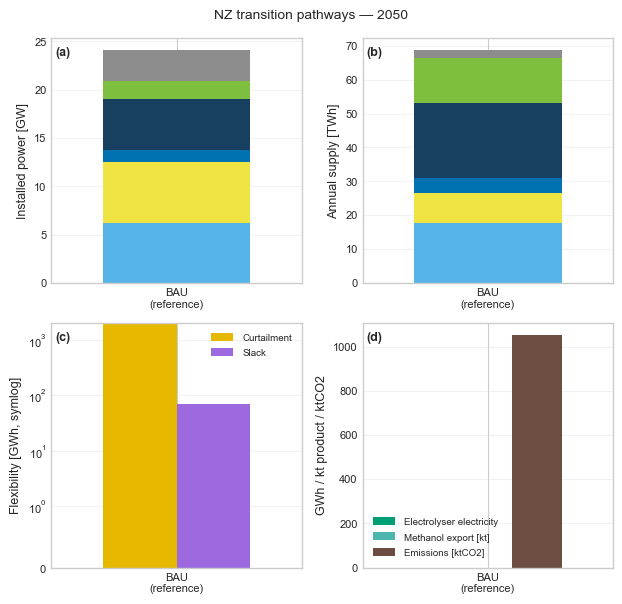

In [26]:
def plot_transition_pathway_dashboard(summary: pd.DataFrame) -> Path | None:
    if summary is None or summary.empty:
        print("Transition-pathway dashboard skipped: no solved scenario summary is available.")
        return None

    target_year = max(summary["year"].astype(int))
    data = apply_scenario_order(summary.loc[summary["year"].astype(int).eq(target_year)].copy())
    codes = data["scenario"].astype(str).tolist()
    labels = [scenario_axis_label(code) for code in codes]
    x = np.arange(len(data))
    fig, axes = plt.subplots(2, 2, figsize=(WORD_DOUBLE_COL_IN, 6.1))

    capacity = pd.DataFrame(index=data.index)
    for group in ["Wind", "Solar PV", "Hydro run-of-river", "Hydro reservoir", "Geothermal", "BESS", "Thermal", "Hydrogen"]:
        capacity[group] = sum_metric_by_group(data, "cap_", "_mw", group)
    capacity = capacity.loc[:, capacity.sum(axis=0).gt(1e-6)] / 1e3
    if not capacity.empty:
        capacity.index = labels
        capacity.plot(kind="bar", stacked=True, ax=axes[0, 0], color=[TECH_COLORS_GROUPED.get(c, "#9E9E9E") for c in capacity.columns], legend=False, width=0.72)
    finish_axis(axes[0, 0], ylabel="Installed power [GW]")
    panel_label(axes[0, 0], "(a)")

    generation = pd.DataFrame(index=data.index)
    for group in ["Wind", "Solar PV", "Hydro run-of-river", "Hydro reservoir", "Geothermal", "BESS", "Thermal", "Hydrogen", "Slack"]:
        generation[group] = sum_metric_by_group(data, "generation_", "_mwh", group)
    generation = generation.loc[:, generation.sum(axis=0).gt(1e-6)] / 1e6
    if not generation.empty:
        generation.index = labels
        generation.plot(kind="bar", stacked=True, ax=axes[0, 1], color=[TECH_COLORS_GROUPED.get(c, "#9E9E9E") for c in generation.columns], legend=False, width=0.72)
    finish_axis(axes[0, 1], ylabel="Annual supply [TWh]")
    panel_label(axes[0, 1], "(b)")

    flexibility = pd.DataFrame(
        {
            "Curtailment": column_or_zero(data, "curtailment_total_mwh") / 1e3,
            "BESS discharge": column_or_zero(data, "bess_discharge_mwh") / 1e3,
            "H2-to-power": column_or_zero(data, "h2_to_power_mwh") / 1e3,
            "Slack": column_or_zero(data, "slack_generation_mwh") / 1e3,
        },
        index=data.index,
    )
    flexibility.index = labels
    flexibility = flexibility.loc[:, flexibility.sum(axis=0).gt(1e-6)]
    if not flexibility.empty:
        flexibility.plot(
            kind="bar", ax=axes[1, 0], width=0.72,
            color=["#E6B800", TECH_COLORS["bess"], TECH_COLORS["h2_fuel_cell"], TECH_COLORS["slack"]],
        )
    else:
        axes[1, 0].text(0.5, 0.5, "No flexibility activity", ha="center", va="center", transform=axes[1, 0].transAxes)
    axes[1, 0].set_yscale("symlog", linthresh=1.0)
    finish_axis(axes[1, 0], ylabel="Flexibility [GWh, symlog]")
    panel_label(axes[1, 0], "(c)")

    scale = pd.DataFrame(
        {
            "Electrolyser electricity": column_or_zero(data, "electrolyzer_input_mwh") / 1e3,
            "Methanol export [kt]": column_or_zero(data, "methanol_export_t") / 1e3,
            "Emissions [ktCO2]": column_or_zero(data, "co2_tons") / 1e3,
        },
        index=data.index,
    )
    scale.index = labels
    scale.plot(kind="bar", ax=axes[1, 1], width=0.72, color=[TECH_COLORS["electrolyzer"], "#4DB6AC", "#6D4C41"])
    finish_axis(axes[1, 1], ylabel="GWh / kt product / ktCO2")
    panel_label(axes[1, 1], "(d)")

    for ax in axes.ravel():
        ax.tick_params(axis="x", labelrotation=0)
        legend = ax.get_legend()
        if legend is not None:
            legend.set_frame_on(False)
            for legend_text in legend.get_texts():
                legend_text.set_fontsize(FONT_SIZE_SMALL - 1)
    fig.suptitle(f"NZ transition pathways — {target_year}", fontsize=FONT_SIZE_BASE + 1)
    fig.tight_layout()
    path = save_paper_figure(fig, f"figure_transition_pathways_{target_year}.png")
    plt.show()
    return path


transition_pathway_figure = plot_transition_pathway_dashboard(scenario_comparison)


## 4. Renewable conditions, critical events and curtailment


### 4.1 Renewable-resource conditions


In [27]:
# Renewable-scarcity helper functions

def _prepare_cf_series(cf_df: pd.DataFrame) -> pd.Series:
    """Average capacity-factor profiles across zones."""
    if cf_df is None or cf_df.empty:
        raise ValueError("No capacity-factor data are available.")

    cf = cf_df.copy()
    if not isinstance(cf.index, pd.DatetimeIndex):
        cf.index = pd.to_datetime(cf.index)

    return cf.mean(axis=1)


def _daily_mean_series(cf_series: pd.Series) -> pd.Series:
    return cf_series.resample("D").mean()


def _monthly_max_consecutive_low_days(
    daily_cf: pd.Series,
    threshold: float,
) -> pd.Series:
    month_labels = [
        "Jan", "Feb", "Mar", "Apr", "May", "Jun",
        "Jul", "Aug", "Sep", "Oct", "Nov", "Dec",
    ]
    result = pd.Series(0.0, index=month_labels)

    for month_num, month_data in daily_cf.groupby(daily_cf.index.month):
        maximum = 0
        current = 0
        for is_low in month_data.lt(threshold):
            current = current + 1 if is_low else 0
            maximum = max(maximum, current)
        result.iloc[month_num - 1] = maximum

    return result


def _longest_true_run(mask: pd.Series) -> tuple[pd.Timestamp | None, pd.Timestamp | None, int]:
    """Return the start, end, and duration of the longest True run."""
    mask = mask.astype(bool)
    best_start = best_end = current_start = None
    best_length = current_length = 0

    for timestamp, value in mask.items():
        if value:
            if current_start is None:
                current_start = timestamp
            current_length += 1
            if current_length > best_length:
                best_start = current_start
                best_end = timestamp
                best_length = current_length
        else:
            current_start = None
            current_length = 0

    return best_start, best_end, best_length


In [28]:
# Combined renewable-scarcity figure
cf_combined_scenario = active_scenario
cf_combined_years = [detailed_year]   # one representative planning year
cf_combined_export_dir = PAPER_FIGURE_DIR / "figure04_capacity_factor_combined"
cf_combined_export_dir.mkdir(parents=True, exist_ok=True)

RESOURCE_LABELS = [
    "Both high",
    "Wind low / Solar high",
    "Solar low / Wind high",
    "Both low",
]
RESOURCE_COLORS = ["#009e73", "#0072b2", "#e69f00", "#d55e00"]


def _resource_calendar_dataframe(wind_daily, solar_daily, wind_threshold, solar_threshold):
    df = pd.DataFrame({"wind": wind_daily, "solar": solar_daily}).dropna().copy()
    df["month"] = df.index.month
    df["day"] = df.index.day
    df["category"] = np.select(
        [
            (df["wind"] >= wind_threshold) & (df["solar"] >= solar_threshold),
            (df["wind"] < wind_threshold) & (df["solar"] >= solar_threshold),
            (df["wind"] >= wind_threshold) & (df["solar"] < solar_threshold),
            (df["wind"] < wind_threshold) & (df["solar"] < solar_threshold),
        ],
        [0, 1, 2, 3],
        default=np.nan,
    )
    return df


def _add_month_separators_embedded(ax, daily_index):
    month_starts = pd.Series(index=daily_index, data=1).resample("MS").first().index
    month_start_days = month_starts.dayofyear.values
    for day in month_start_days:
        ax.axvline(day, color="#bcbcbc", linewidth=0.7, alpha=0.5, zorder=0)
    return ax


def _month_bar_axis(ax, series, color, ylabel, panel):
    month_labels = ["J", "F", "M", "A", "M", "J", "J", "A", "S", "O", "N", "D"]
    month_order = ["Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]
    x = np.arange(len(month_labels))
    vals = series.reindex(month_order).fillna(0.0).values

    ax.bar(x, vals, color=color, alpha=0.90, width=0.78)
    ax.set_xticks(x)
    ax.set_xticklabels(month_labels, fontsize=7)
    finish_axis(ax, xlabel="Month", ylabel=ylabel)
    ax.grid(False)
    ax.yaxis.grid(True, alpha=0.22)
    ax.xaxis.grid(False)
    ax.set_axisbelow(True)
    panel_label(ax, panel)


def _draw_resource_calendar_blocks(ax, calendar_df, panel):
    """
    Draw daily resource-category blocks month by month.

    Each month row spans the same total width, but daily blocks are wider
    in shorter months, so February/April/June/etc. align with 31-day months.
    """
    month_labels = ["Jan", "Feb", "Mar", "Apr", "May", "Jun",
                    "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]

    # Use the actual year to handle leap years correctly.
    plot_year = int(calendar_df.index[0].year)

    max_days_axis = 31.0

    ax.set_xlim(0, max_days_axis)
    ax.set_ylim(-0.5, 11.5)
    ax.invert_yaxis()

    for month_idx in range(12):
        month_num = month_idx + 1
        n_days = monthrange(plot_year, month_num)[1]

        # Daily blocks are stretched so each month row spans 31 axis units.
        cell_width = max_days_axis / n_days
        block_width = cell_width * 0.88
        x_pad = (cell_width - block_width) / 2

        month_df = calendar_df[calendar_df["month"] == month_num]

        for _, row in month_df.iterrows():
            day = int(row["day"])
            cat = int(row["category"])

            x0 = (day - 1) * cell_width + x_pad

            rect = Rectangle(
                (x0, month_idx - 0.34),
                block_width,
                0.68,
                facecolor=RESOURCE_COLORS[cat],
                edgecolor="white",
                linewidth=0.55,
            )
            ax.add_patch(rect)

    ax.set_yticks(np.arange(12))
    ax.set_yticklabels(month_labels, fontsize=8)

    # These are approximate day-of-month reference labels on a 31-day axis.
    ax.set_xticks([0, 4, 9, 14, 19, 24, 30])
    ax.set_xticklabels([1, 5, 10, 15, 20, 25, 31], fontsize=7)

    finish_axis(ax, xlabel="Day of month", ylabel=None)
    ax.grid(False)
    ax.tick_params(axis="both", length=0)

    for spine in ax.spines.values():
        spine.set_visible(False)

    panel_label(ax, panel)


def plot_combined_cf_figure(scenario_code, year, save_figure=True, show_figure=True):
    result = scenario_results[scenario_code]["results"][year]
    wind_cf_local = result["wind_cf"]
    solar_cf_local = result["solar_cf"]

    wind_series_local = _prepare_cf_series(wind_cf_local)
    solar_series_local = _prepare_cf_series(solar_cf_local)
    wind_daily_local = _daily_mean_series(wind_series_local)
    solar_daily_local = _daily_mean_series(solar_series_local)

    wind_streak_local = _monthly_max_consecutive_low_days(wind_daily_local, LOW_WIND_THRESHOLD)
    solar_streak_local = _monthly_max_consecutive_low_days(solar_daily_local, LOW_SOLAR_THRESHOLD)

    scatter_df = pd.DataFrame({"wind": wind_daily_local, "solar": solar_daily_local}).dropna()
    calendar_df = _resource_calendar_dataframe(
        wind_daily_local,
        solar_daily_local,
        LOW_WIND_THRESHOLD,
        LOW_SOLAR_THRESHOLD,
    )

    # Slightly tighter figure, but still enough room for shared legends
    fig = plt.figure(figsize=(7.2, 8.5))
    gs = fig.add_gridspec(
        3, 2,
        height_ratios=[1.00, 0.76, 1.58],
        hspace=0.50,
        wspace=0.24,
    )

    ax_a = fig.add_subplot(gs[0, 0])
    ax_b = fig.add_subplot(gs[0, 1])
    ax_c = fig.add_subplot(gs[1, 0])
    ax_d = fig.add_subplot(gs[1, 1])
    ax_e = fig.add_subplot(gs[2, 0])
    ax_f = fig.add_subplot(gs[2, 1])

    # Colors for threshold panels
    wind_high_color = TECH_COLORS.get("wind", "#5bbcff")
    solar_high_color = "#f2a900"
    low_color = "#d95f5f"

    # (a) Daily wind CF
    day_w = wind_daily_local.index.dayofyear
    colors_w = np.where(
        wind_daily_local.values < LOW_WIND_THRESHOLD,
        low_color,
        wind_high_color,
    )
    ax_a.bar(day_w, wind_daily_local.values, color=colors_w, width=1.0, alpha=0.90)
    ax_a.axhline(LOW_WIND_THRESHOLD, color="black", linestyle="--", linewidth=1)
    ax_a.set_xlim(1, int(day_w.max()))
    ax_a.set_ylim(0, 1.0)
    finish_axis(ax_a, xlabel="Day of year", ylabel="Daily mean wind CF [-]")
    ax_a.grid(False)
    ax_a.yaxis.grid(True, alpha=0.22)
    ax_a.xaxis.grid(False)
    _add_month_separators_embedded(ax_a, wind_daily_local.index)
    panel_label(ax_a, "(a)")

    # (b) Daily solar CF
    day_s = solar_daily_local.index.dayofyear
    colors_s = np.where(
        solar_daily_local.values < LOW_SOLAR_THRESHOLD,
        low_color,
        solar_high_color,
    )
    ax_b.bar(day_s, solar_daily_local.values, color=colors_s, width=1.0, alpha=0.90)
    ax_b.axhline(LOW_SOLAR_THRESHOLD, color="black", linestyle="--", linewidth=1)
    ax_b.set_xlim(1, int(day_s.max()))
    ax_b.set_ylim(0, max(0.32, float(solar_daily_local.max()) * 1.15))
    finish_axis(ax_b, xlabel="Day of year", ylabel="Daily mean solar CF [-]")
    ax_b.grid(False)
    ax_b.yaxis.grid(True, alpha=0.22)
    ax_b.xaxis.grid(False)
    _add_month_separators_embedded(ax_b, solar_daily_local.index)
    panel_label(ax_b, "(b)")

    # (c) Longest low-wind streak per month
    _month_bar_axis(
        ax_c,
        wind_streak_local,
        wind_high_color,
        "Consecutive days",
        "(c)",
    )

    # (d) Longest low-solar streak per month
    _month_bar_axis(
        ax_d,
        solar_streak_local,
        "#d39200",
        "Consecutive days",
        "(d)",
    )

    # (e) Scatter of daily wind vs solar CF
    conditions = [
        (scatter_df["wind"] >= LOW_WIND_THRESHOLD) & (scatter_df["solar"] >= LOW_SOLAR_THRESHOLD),
        (scatter_df["wind"] < LOW_WIND_THRESHOLD) & (scatter_df["solar"] >= LOW_SOLAR_THRESHOLD),
        (scatter_df["wind"] >= LOW_WIND_THRESHOLD) & (scatter_df["solar"] < LOW_SOLAR_THRESHOLD),
        (scatter_df["wind"] < LOW_WIND_THRESHOLD) & (scatter_df["solar"] < LOW_SOLAR_THRESHOLD),
    ]

    for mask, lab, col in zip(conditions, RESOURCE_LABELS, RESOURCE_COLORS):
        ax_e.scatter(
            scatter_df.loc[mask, "wind"],
            scatter_df.loc[mask, "solar"],
            s=18,
            alpha=0.85,
            color=col,
            label=lab,
            linewidths=0,
        )

    ax_e.axvline(LOW_WIND_THRESHOLD, color="black", linestyle="--", linewidth=1)
    ax_e.axhline(LOW_SOLAR_THRESHOLD, color="black", linestyle="--", linewidth=1)
    finish_axis(
        ax_e,
        xlabel="Daily mean wind capacity factor [-]",
        ylabel="Daily mean solar capacity factor [-]",
    )
    ax_e.grid(False)
    ax_e.yaxis.grid(True, alpha=0.22)
    ax_e.xaxis.grid(False)
    panel_label(ax_e, "(e)")

    # (f) Resource category calendar
    _draw_resource_calendar_blocks(ax_f, calendar_df, "(f)")

    # Shared legend for panels (a) and (b), above first row
    threshold_legend_items = [
        Patch(facecolor=wind_high_color, label="Wind at/above threshold"),
        Patch(facecolor=solar_high_color, label="Solar at/above threshold"),
        Patch(facecolor=low_color, label="Below threshold"),
        Line2D([0], [0], color="black", linestyle="--", linewidth=1, label="Threshold"),
    ]
    leg_top = fig.legend(
        handles=threshold_legend_items,
        loc="upper center",
        bbox_to_anchor=(0.5, 0.985),
        ncol=4,
        fontsize=7.8,
        frameon=False,
        columnspacing=1.25,
        handlelength=1.4,
        handletextpad=0.5,
    )
    fig.add_artist(leg_top)

    # Shared legend for panels (e) and (f), just above third row
    resource_legend_items = [
        Patch(facecolor=RESOURCE_COLORS[0], label="Both high"),
        Patch(facecolor=RESOURCE_COLORS[1], label="Wind low / Solar high"),
        Patch(facecolor=RESOURCE_COLORS[2], label="Solar low / Wind high"),
        Patch(facecolor=RESOURCE_COLORS[3], label="Both low"),
    ]
    leg_mid = fig.legend(
        handles=resource_legend_items,
        loc="upper center",
        bbox_to_anchor=(0.5, 0.51),
        ncol=2,
        fontsize=7.8,
        frameon=False,
        columnspacing=1.35,
        handlelength=1.2,
        handletextpad=0.5,
    )
    fig.add_artist(leg_mid)

    if not PAPER_MODE:
        fig.suptitle(
            f"{scenario_label(scenario_code)} – renewable scarcity ({year})",
            fontsize=FONT_SIZE_LABEL + 1,
            y=0.997,
        )
        fig.subplots_adjust(top=0.92, bottom=0.07)
    else:
        fig.subplots_adjust(top=0.92, bottom=0.20)

    out_path = None
    if save_figure:
        out_path = save_paper_figure(
            fig,
            f"figure04_combined_{scenario_code}_{year}.png",
            folder=cf_combined_export_dir,
        )
        out_path = save_paper_figure(
            fig,
            f"figure04_combined_{scenario_code}_{year}.svg",
            folder=cf_combined_export_dir,
        )
        out_path = save_paper_figure(
            fig,
            f"figure04_combined_{scenario_code}_{year}.pdf",
            folder=cf_combined_export_dir,
        )

    if show_figure:
        plt.show()
    else:
        plt.close(fig)

    return out_path



Plotting combined Figure 4 for reference – 2050...
Saved figure: output\output_new_zealand\figures\figure04_capacity_factor_combined\figure04_combined_reference_2050.png
Saved figure: output\output_new_zealand\figures\figure04_capacity_factor_combined\figure04_combined_reference_2050.svg
Saved figure: output\output_new_zealand\figures\figure04_capacity_factor_combined\figure04_combined_reference_2050.pdf


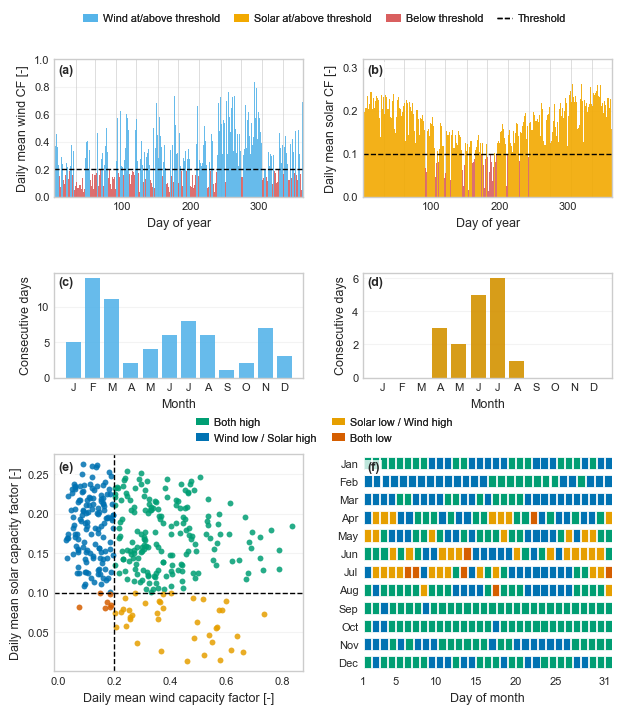

In [29]:
for year in cf_combined_years:
    print(f"\nPlotting combined Figure 4 for {cf_combined_scenario} – {year}...")
    plot_combined_cf_figure(cf_combined_scenario, year)


### 4.2 Longest simultaneous low-wind and low-solar event


In [30]:
# Longest simultaneous low-wind and low-solar event
def identify_simultaneous_low_event(
    wind_cf,
    solar_cf,
    wind_threshold=LOW_WIND_THRESHOLD,
    solar_threshold=LOW_SOLAR_THRESHOLD,
):
    wind_series = wind_cf.mean(axis=1).copy()
    solar_series = solar_cf.mean(axis=1).copy()

    wind_series.index = pd.to_datetime(wind_series.index)
    solar_series.index = pd.to_datetime(solar_series.index)

    wind_daily = wind_series.resample("D").mean()
    solar_daily = solar_series.resample("D").mean()

    low_event_mask = (wind_daily < wind_threshold) & (solar_daily < solar_threshold)
    start, end, duration_days = _longest_true_run(low_event_mask)

    event_table = pd.DataFrame({
        "wind_daily_cf": wind_daily,
        "solar_daily_cf": solar_daily,
        "simultaneous_low": low_event_mask,
    })

    if start is None:
        raise ValueError("No simultaneous low-wind and low-solar event found with the selected thresholds.")

    return {
        "start_day": start,
        "end_day": end,
        "duration_days": duration_days,
        "start_hour": pd.Timestamp(start),
        "end_hour": pd.Timestamp(end) + pd.Timedelta(hours=23),
        "event_table": event_table,
    }


In [31]:
critical_event = identify_simultaneous_low_event(
    wind_cf,
    solar_cf,
    wind_threshold=LOW_WIND_THRESHOLD,
    solar_threshold=LOW_SOLAR_THRESHOLD,
)

critical_event_start = critical_event["start_hour"]
critical_event_end = critical_event["end_hour"]

print("Critical simultaneous low-renewable event:")
print(f"  Start: {critical_event_start}")
print(f"  End:   {critical_event_end}")
print(f"  Duration: {critical_event['duration_days']} days")

display(
    critical_event["event_table"]
    .loc[critical_event["start_day"]:critical_event["end_day"]]
    .round(3)
)

# Export event table for traceability
critical_event_table_path = TABLE_EXPORT_DIR / f"critical_event_daily_table_{base_case_name}_{active_scenario}_{detailed_year}.csv"
critical_event["event_table"].to_csv(critical_event_table_path)
print(f"Saved daily event table to: {critical_event_table_path}")


Critical simultaneous low-renewable event:
  Start: 2050-07-06 00:00:00
  End:   2050-07-07 23:00:00
  Duration: 2 days


,wind_daily_cf,solar_daily_cf,simultaneous_low
index,,,
2050-07-06,0.185,0.098,True
2050-07-07,0.074,0.082,True


Saved daily event table to: output\output_new_zealand\tables\critical_event_daily_table_new_zealand_reference_2050.csv


### 4.3 Critical-event balance and comparable dispatch windows


In [32]:
# Dispatch during the critical low-renewable event
selected_scenarios_for_event = list(scenario_results.keys())

event_year = detailed_year


def _series_like_snapshots(net, value=0.0):
    return pd.Series(float(value), index=pd.to_datetime(net.snapshots))


def _link_input_power_by_carrier(net, carrier: str) -> pd.Series:
    """Positive input power at p0 for links of a given carrier [MW]."""
    if len(net.links) == 0 or not hasattr(net.links_t, "p0"):
        return _series_like_snapshots(net)

    links = net.links.index[net.links["carrier"].astype(str) == carrier]
    if len(links) == 0:
        return _series_like_snapshots(net)

    data = net.links_t.p0.reindex(columns=links, fill_value=0.0)
    return data.clip(lower=0.0).sum(axis=1)


def _link_output_power_by_carrier(net, carrier: str) -> pd.Series:
    """Positive useful output power at p1 for links of a given carrier [MW]."""
    if len(net.links) == 0 or not hasattr(net.links_t, "p1"):
        return _series_like_snapshots(net)

    links = net.links.index[net.links["carrier"].astype(str) == carrier]
    if len(links) == 0:
        return _series_like_snapshots(net)

    data = -net.links_t.p1.reindex(columns=links, fill_value=0.0)
    return data.clip(lower=0.0).sum(axis=1)


def _electricity_balance_for_network(net):
    """
    Return positive electricity supply and negative flexible electricity
    consumption. This avoids hiding BESS charging/electrolyser operation inside
    the positive dispatch stack.
    """
    # Positive generator dispatch, normalised to compact plotting keys so
    # spelling variants do not create duplicated legend entries.
    if len(net.generators) > 0:
        gen_dispatch = (
            net.generators_t.p
            .reindex(
                index=net.snapshots,
                columns=net.generators.index,
                fill_value=0.0,
            )
            .clip(lower=0.0)
        )
        gen_plot_key = net.generators["carrier"].map(dispatch_plot_key)
        supply = gen_dispatch.T.groupby(gen_plot_key).sum().T
    else:
        supply = pd.DataFrame(index=pd.to_datetime(net.snapshots))

    # StorageUnits are split explicitly. Reservoir hydro is positive hydro
    # supply; only assets classified as BESS contribute to BESS discharge and
    # BESS charging.
    bess_charge = _series_like_snapshots(net)

    if len(net.storage_units) > 0:
        storage_power = net.storage_units_t.p.reindex(
            index=net.snapshots,
            columns=net.storage_units.index,
            fill_value=0.0,
        )

        for asset in net.storage_units.index:
            group = storage_unit_group(net.storage_units, asset)
            power = storage_power[asset]

            if group == "BESS":
                supply["bess"] = (
                    supply.get("bess", _series_like_snapshots(net))
                    + power.clip(lower=0.0)
                )
                bess_charge = bess_charge + (
                    -power.clip(upper=0.0)
                )
            elif group == "Hydro reservoir":
                supply["hydro_reservoir"] = (
                    supply.get(
                        "hydro_reservoir",
                        _series_like_snapshots(net),
                    )
                    + power.clip(lower=0.0)
                )

    # Hydrogen-to-power output is positive supply on the electricity side.
    for carrier in ["h2_fuel_cell", "h2_turbine"]:
        output = _link_output_power_by_carrier(net, carrier)
        if output.sum() > 1e-6:
            supply[carrier] = output

    # Flexible electricity uses shown below zero.
    consumption = pd.DataFrame(index=supply.index)
    if bess_charge.sum() > 1e-6:
        consumption["bess_charge"] = bess_charge

    for carrier in ["electrolyzer", "asu", "dac"]:
        input_power = _link_input_power_by_carrier(net, carrier)
        if input_power.sum() > 1e-6:
            consumption[carrier] = input_power

    preferred_supply_order = [
        "wind",
        "solar",
        "hydro_run_of_river",
        "hydro_reservoir",
        "geothermal",
        "bess",
        "h2_fuel_cell",
        "h2_turbine",
        "coal",
        "ccgt",
        "ocgt",
        "gas_cogeneration",
        "gas_peaker",
        "thermal_other",
        "diesel",
        "slack",
    ]
    supply_cols = [c for c in preferred_supply_order if c in supply.columns]
    supply_cols += [c for c in supply.columns if c not in supply_cols]
    supply = supply[supply_cols].clip(lower=0.0)

    preferred_consumption_order = ["bess_charge", "electrolyzer", "asu", "dac"]
    cons_cols = [c for c in preferred_consumption_order if c in consumption.columns]
    cons_cols += [c for c in consumption.columns if c not in cons_cols]
    consumption = consumption[cons_cols].clip(lower=0.0)

    return supply, consumption


def _plot_event_balance(ax, supply_event, consumption_event, load_event, scenario_code, panel=None):
    # Positive electricity supply stack
    supply_cols = [c for c in supply_event.columns if supply_event[c].sum() > 1e-6]
    supply_colors = [TECH_COLORS.get(c, "#999999") for c in supply_cols]

    if supply_cols:
        supply_event[supply_cols].plot.area(
            ax=ax,
            stacked=True,
            color=supply_colors,
            alpha=0.82,
            linewidth=0,
        )

    # Negative flexible electricity use, stacked below zero.
    # Matplotlib's area plot often keeps autoscaling from zero upward, so the
    # y-limits are set explicitly after this block.
    negative_stack = pd.Series(0.0, index=consumption_event.index)
    for col in consumption_event.columns:
        s = consumption_event[col].fillna(0.0)
        if s.sum() <= 1e-6:
            continue

        color_key = "bess" if col == "bess_charge" else col
        lower = -negative_stack.values
        upper = -(negative_stack + s).values

        ax.fill_between(
            s.index,
            lower,
            upper,
            step="mid",
            color=TECH_COLORS.get(color_key, "#999999"),
            alpha=0.46,
            linewidth=0,
            label=clean_technology_label(col),
        )
        negative_stack = negative_stack + s

    # Demand lines
    local_load = load_event
    flexible_use = consumption_event.sum(axis=1) if len(consumption_event.columns) > 0 else pd.Series(0.0, index=load_event.index)
    effective_load = local_load + flexible_use

    local_load.plot(ax=ax, color="black", linewidth=2.1, label="Local electricity demand")
    if hasattr(effective_load, "sum") and flexible_use.sum() > 1e-6:
        effective_load.plot(
            ax=ax, color="black", linewidth=1.5, linestyle="--",
            label="Demand + flexible electricity use"
        )

    # Force the negative part to be visible.
    positive_max = max(
        float(supply_event.sum(axis=1).max()) if not supply_event.empty else 0.0,
        float(effective_load.max()) if hasattr(effective_load, "max") else 0.0,
        1.0,
    )
    negative_max = float(negative_stack.max()) if hasattr(negative_stack, "max") else 0.0
    ymin = -1.12 * negative_max if negative_max > 1e-6 else 0.0
    ymax = 1.10 * positive_max
    ax.set_ylim(ymin, ymax)

    ax.axhline(0, color="black", linewidth=0.8)
    finish_axis(ax, ylabel="Power [MW]")
    ax.text(
        0.015, 0.86,
        scenario_label(scenario_code),
        transform=ax.transAxes,
        ha="left", va="top",
        fontsize=FONT_SIZE_SMALL,
        bbox=dict(facecolor="white", edgecolor="none", alpha=0.75, pad=1.5),
    )

    if panel:
        panel_label(ax, panel)

    # Clean legend labels
    handles, labels = ax.get_legend_handles_labels()
    clean_labels = [clean_technology_label(l) for l in labels]
    by_label = dict(zip(clean_labels, handles))
    ax.legend(
        by_label.values(), by_label.keys(),
        loc="upper center", bbox_to_anchor=(0.5, 1.16),
        ncol=5, fontsize=7, frameon=True
    )


Saved figure: output\output_new_zealand\figures\figure_critical_event_dispatch_negative_loads_2050.png


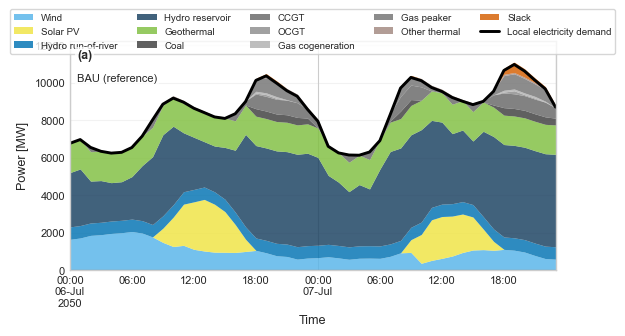

,scenario,paper_label,event_start,event_end,event_demand_mwh,event_supply_mwh,event_flexible_electricity_use_mwh,supply_wind_mwh,supply_solar_mwh,supply_hydro_run_of_river_mwh,supply_hydro_reservoir_mwh,supply_geothermal_mwh,supply_coal_mwh,supply_ccgt_mwh,supply_ocgt_mwh,supply_gas_cogeneration_mwh,supply_gas_peaker_mwh,supply_thermal_other_mwh,supply_slack_mwh
0,reference,BAU (reference),2050-07-06,2050-07-07 23:00:00,407181.432,411754.088,0.0,50948.116,30801.622,31764.166,186943.977,75247.44,5548.961,15600.858,508.929,739.2,8733.463,2941.8,1975.556


Saved event summary to: output\output_new_zealand\tables\critical_event_dispatch_summary_negative_loads_2050.csv


In [33]:
missing_scenarios = [s for s in selected_scenarios_for_event if s not in scenario_results]
if missing_scenarios:
    raise ValueError(f"These scenarios are not available in scenario_results: {missing_scenarios}")


nrows = len(selected_scenarios_for_event)
fig, axes = plt.subplots(nrows, 1, figsize=(WORD_DOUBLE_COL_IN, max(2.25 * nrows, 3.5)), sharex=True)

if nrows == 1:
    axes = [axes]

event_rows = []
panel_letters = [f"({chr(97+i)})" for i in range(nrows)]

for ax, scenario_code, letter in zip(axes, selected_scenarios_for_event, panel_letters):
    package = scenario_results[scenario_code]
    result = package["results"][event_year]
    net = result["network"]

    supply, consumption = _electricity_balance_for_network(net)

    supply_event = supply.loc[critical_event_start:critical_event_end]
    consumption_event = consumption.loc[critical_event_start:critical_event_end]
    load_event = result["load"].sum(axis=1).loc[critical_event_start:critical_event_end]

    _plot_event_balance(
        ax, supply_event, consumption_event, load_event,
        scenario_code=scenario_code,
        panel=letter,
    )

    row = {
        "scenario": scenario_code,
        "paper_label": scenario_label(scenario_code),
        "event_start": critical_event_start,
        "event_end": critical_event_end,
        "event_demand_mwh": float(load_event.sum()),
        "event_supply_mwh": float(supply_event.sum().sum()),
        "event_flexible_electricity_use_mwh": float(consumption_event.sum().sum()) if not consumption_event.empty else 0.0,
    }
    for col in supply_event.columns:
        row[f"supply_{col}_mwh"] = float(supply_event[col].sum())
    for col in consumption_event.columns:
        row[f"negative_{col}_mwh"] = float(consumption_event[col].sum())
    event_rows.append(row)

axes[-1].set_xlabel("Time")

plt.tight_layout()

fig_path = save_paper_figure(fig, f"figure_critical_event_dispatch_negative_loads_{event_year}.png")
plt.show()

event_summary = pd.DataFrame(event_rows)
display(round_numeric_frame(event_summary, 3))

event_summary_path = TABLE_EXPORT_DIR / f"critical_event_dispatch_summary_negative_loads_{event_year}.csv"
event_summary.to_csv(event_summary_path, index=False)
print(f"Saved event summary to: {event_summary_path}")


Favourable summer week selected from reference: 19–26 Dec 2050
Saved figure: output\output_new_zealand\figures\figure_dispatch_critical_event_2050.png


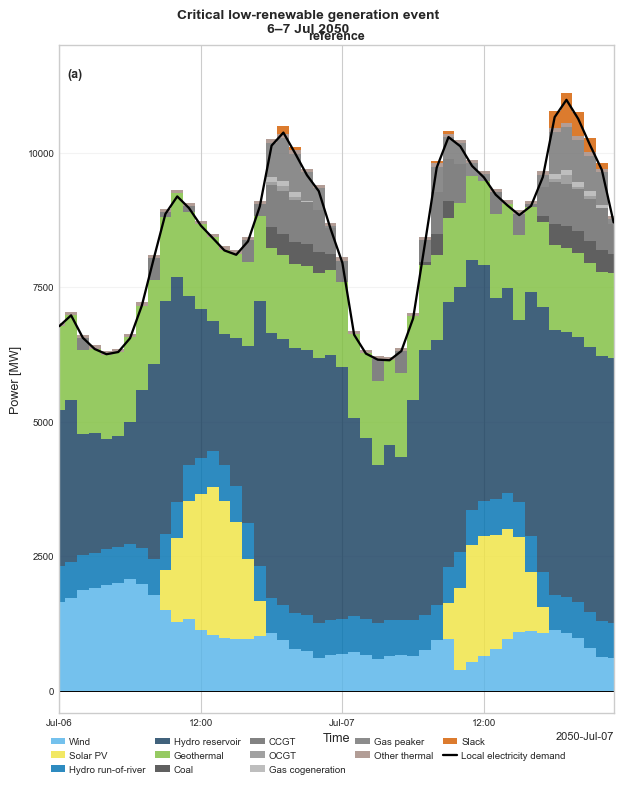

Saved figure to: output\output_new_zealand\figures\figure_dispatch_critical_event_2050.png
  reference: -419.9 to 11998.1 MW
Saved figure: output\output_new_zealand\figures\figure_dispatch_favourable_summer_week_2050.png


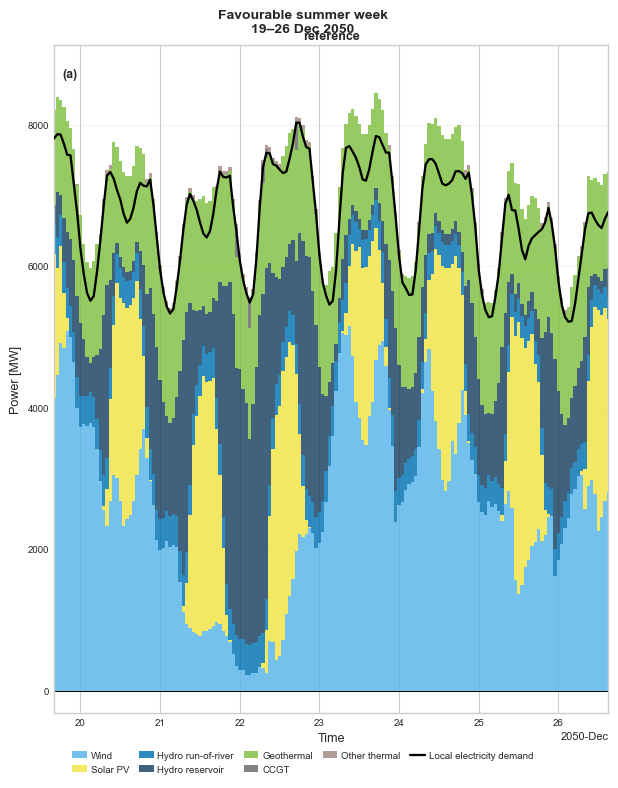

Saved figure to: output\output_new_zealand\figures\figure_dispatch_favourable_summer_week_2050.png
  reference: -319.2 to 9119.7 MW


,scenario,paper_label,period,period_start,period_end,local_demand_mwh,electricity_supply_mwh,flexible_electricity_use_mwh,supply_wind_mwh,supply_solar_mwh,supply_hydro_run_of_river_mwh,supply_hydro_reservoir_mwh,supply_geothermal_mwh,supply_coal_mwh,supply_ccgt_mwh,supply_ocgt_mwh,supply_gas_cogeneration_mwh,supply_gas_peaker_mwh,supply_thermal_other_mwh,supply_slack_mwh
0,reference,reference,critical_event,2050-07-06 00:00:00,2050-07-07 23:00:00,407181.432,411754.088,0.0,50948.116,30801.622,31764.166,186943.977,75247.440,5548.961,15600.858,508.929,739.2,8733.463,2941.800,1975.556
1,reference,reference,summer_week,2050-12-19 16:00:00,2050-12-26 15:00:00,1125178.537,1175968.021,0.0,435010.788,193629.246,66834.813,220541.621,254006.178,0.000,1580.976,0.000,0.0,0.000,4364.399,0.000


Saved dispatch comparison summary to: output\output_new_zealand\tables\dispatch_critical_vs_summer_summary_2050.csv


In [34]:
import inspect
# Two separate dispatch figures:
#   1. Critical low-renewable generation event
#   2. Favourable summer week
#
# Each figure contains one panel per scenario.
# Y-axis scales are shared within:
#   BAU–RT, RE–RH, and PtX separately.

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

from pathlib import Path
from matplotlib.lines import Line2D
from matplotlib.patches import Patch
from matplotlib.ticker import MaxNLocator


# ── Configuration ─────────────────────────────────────────────────────────────
dispatch_comparison_year = globals().get(
    "detailed_year",
    2050,
)

SUMMER_MONTHS = (12, 1, 2)
SUMMER_WINDOW_DAYS = 7

# Leave as None for automatic selection.
# Example:
# SUMMER_WEEK_START = f"{dispatch_comparison_year}-01-15 00:00"
SUMMER_WEEK_START = None

figure_width = globals().get(
    "WORD_DOUBLE_COL_IN",
    7.1,
)

small_font = globals().get(
    "FONT_SIZE_SMALL",
    8,
)


# ── Scenario selection and labels ─────────────────────────────────────────────
def _short_scenario_label(scenario_code):
    """Return BAU, RT, RE, RH or PtX without S-number or _base."""
    text = str(scenario_code).upper().replace("-", "_")

    parts = [part for part in text.split("_") if part]

    if "PTX" in parts or "PTX" in text:
        return "PtX"

    for label in [
        "BAU",
        "RT",
        "RE",
        "RH",
    ]:
        if label in parts:
            return label

    return str(scenario_code).replace("_base", "").replace("_BASE", "")


scenario_order = [
    "BAU",
    "RT",
    "RE",
    "RH",
    "PtX",
]

available_scenarios = list(scenario_results.keys())

dispatch_comparison_scenarios = []

for desired_label in scenario_order:
    matching_scenarios = [
        scenario_code for scenario_code in available_scenarios if _short_scenario_label(scenario_code) == desired_label
    ]

    if not matching_scenarios:
        continue

    # Prefer the base pathway if more than one variant exists.
    matching_scenarios.sort(
        key=lambda scenario_code: (
            not str(scenario_code).upper().endswith("_BASE"),
            str(scenario_code),
        )
    )

    dispatch_comparison_scenarios.append(matching_scenarios[0])


if not dispatch_comparison_scenarios:
    # A single NZ reference export is a valid dispatch-analysis case.
    dispatch_comparison_scenarios = [
        active_scenario if active_scenario in available_scenarios else available_scenarios[0]
    ]


def _scale_group_label(scenario_code):
    label = _short_scenario_label(scenario_code)

    if label in {
        "BAU",
        "RT",
    }:
        return "BAU–RT"

    if label in {
        "RE",
        "RH",
    }:
        return "RE–RH"

    if label == "PtX":
        return "PtX"

    return label


# ── General helpers ───────────────────────────────────────────────────────────
def _naive_datetime_index(values):
    index = pd.DatetimeIndex(pd.to_datetime(values))

    if index.tz is not None:
        index = index.tz_localize(None)

    return index


def _naive_timestamp(value):
    timestamp = pd.Timestamp(value)

    if timestamp.tz is not None:
        timestamp = timestamp.tz_localize(None)

    return timestamp


def _normalise_timeseries_index(values):
    out = values.copy()

    out.index = _naive_datetime_index(out.index)

    return out.sort_index()


def _total_local_load(result):
    load = result["load"]

    if isinstance(
        load,
        pd.Series,
    ):
        return load.copy()

    return load.sum(axis=1)


def _format_period(start, end):
    start = pd.Timestamp(start)
    end = pd.Timestamp(end)

    if start.year == end.year and start.month == end.month:
        return f"{start.day}–{end.day} {start:%b %Y}"

    if start.year == end.year:
        return f"{start.day} {start:%b}–{end.day} {end:%b %Y}"

    return f"{start.day} {start:%b %Y}–{end.day} {end:%b %Y}"


def _snapshot_hours(index):
    index = pd.DatetimeIndex(index)

    if len(index) == 0:
        return pd.Series(
            dtype=float,
            index=index,
        )

    timestamp_series = pd.Series(
        index,
        index=index,
    )

    durations = timestamp_series.shift(-1) - timestamp_series

    typical_duration = durations.dropna().median()

    if pd.isna(typical_duration):
        typical_duration = pd.Timedelta(hours=1)

    durations.iloc[-1] = typical_duration

    return durations.dt.total_seconds().div(3600.0)


# ── Renewable potential for summer-week selection ────────────────────────────
def _renewable_potential_and_load(
    scenario_code,
    model_year,
):
    """
    Return available wind + solar generation and local load [MW].

    Renewable potential is based on installed capacity multiplied
    by p_max_pu, rather than realised dispatch.
    """
    result = scenario_results[scenario_code]["results"][model_year]

    net = result["network"]

    generator_carriers = net.generators["carrier"].astype(str)

    renewable_generators = net.generators.index[
        generator_carriers.str.contains(
            r"wind|solar|pv",
            case=False,
            regex=True,
        )
    ]

    if len(renewable_generators) == 0:
        return None, None

    p_nom_fallback = pd.to_numeric(
        net.generators.get(
            "p_nom",
            pd.Series(
                0.0,
                index=net.generators.index,
            ),
        ),
        errors="coerce",
    ).fillna(0.0)

    p_nom = pd.to_numeric(
        net.generators.get(
            "p_nom_opt",
            pd.Series(
                np.nan,
                index=net.generators.index,
            ),
        ),
        errors="coerce",
    ).fillna(p_nom_fallback)

    p_nom = p_nom.reindex(renewable_generators).fillna(0.0)

    static_p_max_pu = pd.to_numeric(
        net.generators.get(
            "p_max_pu",
            pd.Series(
                1.0,
                index=net.generators.index,
            ),
        ),
        errors="coerce",
    ).fillna(1.0)

    dynamic_p_max_pu = getattr(
        net.generators_t,
        "p_max_pu",
        pd.DataFrame(index=net.snapshots),
    )

    p_max_pu = dynamic_p_max_pu.reindex(
        index=net.snapshots,
        columns=renewable_generators,
    ).copy()

    for generator in renewable_generators:
        p_max_pu[generator] = pd.to_numeric(
            p_max_pu[generator],
            errors="coerce",
        ).fillna(
            float(
                static_p_max_pu.get(
                    generator,
                    1.0,
                )
            )
        )

    renewable_potential = p_max_pu.multiply(
        p_nom,
        axis=1,
    ).sum(axis=1)

    renewable_potential.index = _naive_datetime_index(renewable_potential.index)

    local_load = _total_local_load(result)

    local_load.index = _naive_datetime_index(local_load.index)

    local_load = local_load.reindex(renewable_potential.index).fillna(0.0)

    return (
        renewable_potential.sort_index(),
        local_load.sort_index(),
    )


# Prefer RE for selecting the weather period.
summer_reference_rank = {
    "RE": 0,
    "RH": 1,
    "PtX": 2,
    "RT": 3,
    "BAU": 4,
}

summer_reference_preferences = sorted(
    dispatch_comparison_scenarios,
    key=lambda scenario_code: summer_reference_rank.get(
        _short_scenario_label(scenario_code),
        99,
    ),
)

summer_reference_scenario = None
reference_renewable_potential = None
reference_local_load = None

for candidate in summer_reference_preferences:
    if dispatch_comparison_year not in scenario_results[candidate]["results"]:
        continue

    candidate_potential, candidate_load = _renewable_potential_and_load(
        candidate,
        dispatch_comparison_year,
    )

    if candidate_potential is not None and candidate_potential.max() > 1e-6:
        summer_reference_scenario = candidate

        reference_renewable_potential = candidate_potential

        reference_local_load = candidate_load

        break


if summer_reference_scenario is None:
    raise ValueError("No scenario with wind or solar capacity was found to identify the favourable summer week.")


# ── Select the favourable summer week ────────────────────────────────────────
reference_index = reference_renewable_potential.index

if len(reference_index) < 2:
    raise ValueError("Not enough snapshots to select a summer week.")

snapshot_interval = reference_index.to_series().diff().dropna().median()

if pd.isna(snapshot_interval) or snapshot_interval <= pd.Timedelta(0):
    raise ValueError("Could not determine the snapshot interval.")

summer_window_steps = int(round(pd.Timedelta(days=SUMMER_WINDOW_DAYS) / snapshot_interval))

summer_window_steps = max(
    summer_window_steps,
    1,
)


if SUMMER_WEEK_START is not None:
    summer_week_start = _naive_timestamp(SUMMER_WEEK_START)

    matching_positions = np.flatnonzero(reference_index == summer_week_start)

    if len(matching_positions) == 0:
        raise ValueError(f"SUMMER_WEEK_START={SUMMER_WEEK_START} is not a model snapshot.")

    start_position = int(matching_positions[0])

    end_position = start_position + summer_window_steps - 1

    if end_position >= len(reference_index):
        raise ValueError("The manually selected summer week extends beyond the available snapshots.")

    summer_week_end = reference_index[end_position]

else:
    summer_snapshot_mask = pd.Series(
        reference_index.month.isin(SUMMER_MONTHS).astype(float),
        index=reference_index,
    )

    complete_summer_window = (
        summer_snapshot_mask.rolling(
            window=summer_window_steps,
            min_periods=summer_window_steps,
        )
        .sum()
        .eq(float(summer_window_steps))
    )

    rolling_renewable_potential = reference_renewable_potential.rolling(
        window=summer_window_steps,
        min_periods=summer_window_steps,
    ).sum()

    rolling_local_load = reference_local_load.rolling(
        window=summer_window_steps,
        min_periods=summer_window_steps,
    ).sum()

    favourable_week_score = rolling_renewable_potential.div(
        rolling_local_load.replace(
            0.0,
            np.nan,
        )
    ).where(complete_summer_window)

    valid_scores = favourable_week_score.dropna()

    if valid_scores.empty:
        raise ValueError("No complete seven-day summer window was found.")

    summer_week_end = valid_scores.idxmax()

    end_position = int(reference_index.get_loc(summer_week_end))

    start_position = end_position - summer_window_steps + 1

    summer_week_start = reference_index[start_position]


print(
    "Favourable summer week selected from "
    f"{_short_scenario_label(summer_reference_scenario)}: "
    f"{_format_period(summer_week_start, summer_week_end)}"
)


# ── Period definitions ────────────────────────────────────────────────────────
period_definitions = [
    {
        "key": "critical_event",
        "title": ("Critical low-renewable generation event"),
        "file_stub": "critical_event",
        "start": _naive_timestamp(critical_event_start),
        "end": _naive_timestamp(critical_event_end),
    },
    {
        "key": "summer_week",
        "title": ("Favourable summer week"),
        "file_stub": "favourable_summer_week",
        "start": summer_week_start,
        "end": summer_week_end,
    },
]


# ── Prepare dispatch data ─────────────────────────────────────────────────────
dispatch_period_data = {}
dispatch_comparison_rows = []

for scenario_code in dispatch_comparison_scenarios:
    package = scenario_results[scenario_code]

    if dispatch_comparison_year not in package["results"]:
        raise ValueError(f"{scenario_code} has no result for {dispatch_comparison_year}.")

    result = package["results"][dispatch_comparison_year]

    net = result["network"]

    supply, consumption = _electricity_balance_for_network(net)

    supply = _normalise_timeseries_index(supply).fillna(0.0)

    consumption = _normalise_timeseries_index(consumption).fillna(0.0)

    local_load = _normalise_timeseries_index(_total_local_load(result)).fillna(0.0)

    consumption = consumption.reindex(
        supply.index,
        fill_value=0.0,
    ).fillna(0.0)

    local_load = local_load.reindex(supply.index).fillna(0.0)

    for period in period_definitions:
        period_mask = (supply.index >= period["start"]) & (supply.index <= period["end"])

        supply_period = supply.loc[period_mask].copy()

        consumption_period = consumption.loc[period_mask].copy()

        load_period = local_load.loc[period_mask].copy()

        if supply_period.empty:
            raise ValueError(
                f"No snapshots found for {scenario_code}, {period['title']}: {period['start']} to {period['end']}."
            )

        dispatch_period_data[
            (
                scenario_code,
                period["key"],
            )
        ] = {
            "supply": supply_period,
            "consumption": consumption_period,
            "load": load_period,
        }

        snapshot_hours = _snapshot_hours(supply_period.index)

        supply_energy = supply_period.mul(
            snapshot_hours,
            axis=0,
        )

        consumption_energy = consumption_period.mul(
            snapshot_hours,
            axis=0,
        )

        load_energy = load_period * snapshot_hours

        summary_row = {
            "scenario": scenario_code,
            "paper_label": (_short_scenario_label(scenario_code)),
            "period": period["key"],
            "period_start": (supply_period.index.min()),
            "period_end": (supply_period.index.max()),
            "local_demand_mwh": float(load_energy.sum()),
            "electricity_supply_mwh": float(supply_energy.sum().sum()),
            "flexible_electricity_use_mwh": float(consumption_energy.sum().sum()),
        }

        for column in supply_energy.columns:
            summary_row[f"supply_{column}_mwh"] = float(supply_energy[column].sum())

        for column in consumption_energy.columns:
            summary_row[f"negative_{column}_mwh"] = float(consumption_energy[column].sum())

        dispatch_comparison_rows.append(summary_row)


# ── Period-specific grouped y-axis limits ─────────────────────────────────────
scale_group_members = {}

for scenario_code in dispatch_comparison_scenarios:
    group_label = _scale_group_label(scenario_code)

    scale_group_members.setdefault(
        group_label,
        [],
    ).append(scenario_code)


def _calculate_group_ylim(
    period_key,
    scenario_codes,
):
    positive_max = 1.0
    negative_max = 0.0

    for scenario_code in scenario_codes:
        data = dispatch_period_data[
            (
                scenario_code,
                period_key,
            )
        ]

        supply_period = data["supply"].clip(lower=0.0)

        consumption_period = data["consumption"].clip(lower=0.0)

        load_period = data["load"].clip(lower=0.0)

        flexible_use = consumption_period.sum(axis=1)

        total_supply = supply_period.sum(axis=1)

        total_electricity_use = load_period + flexible_use

        positive_max = max(
            positive_max,
            float(total_supply.max()),
            float(load_period.max()),
            float(total_electricity_use.max()),
        )

        negative_max = max(
            negative_max,
            float(flexible_use.max()),
        )

    upper_limit = 1.08 * positive_max

    if negative_max > 1e-6:
        lower_limit = -1.08 * negative_max
    else:
        # Retain a small margin below zero without
        # forcing zero to the centre of the panel.
        lower_limit = -0.035 * upper_limit

    return (
        lower_limit,
        upper_limit,
    )


period_group_y_limits = {}

for period in period_definitions:
    for (
        group_label,
        scenario_codes,
    ) in scale_group_members.items():
        period_group_y_limits[
            (
                period["key"],
                group_label,
            )
        ] = _calculate_group_ylim(
            period["key"],
            scenario_codes,
        )


# ── Plotting colours and labels ───────────────────────────────────────────────
fallback_colors = {
    "wind": "#56B4E9",
    "solar": "#F0E442",
    "hydro_run_of_river": "#0072B2",
    "hydro_reservoir": "#173F5F",
    "geothermal": "#7FBF3F",
    "bess": "#9C6ADE",
    "h2_fuel_cell": "#E69F00",
    "h2_turbine": "#A65E2E",
    "coal": "#3D3D3D",
    "ccgt": "#666666",
    "ocgt": "#8C8C8C",
    "gas_cogeneration": "#B0B0B0",
    "gas_peaker": "#737373",
    "thermal_other": "#A1887F",
    "diesel": "#8D6E63",
    "slack": "#D55E00",
    "electrolyzer": "#009E73",
    "electrolyser": "#009E73",
    "asu": "#80CBC4",
    "dac": "#4DB6AC",
}

plot_colors = fallback_colors.copy()

plot_colors.update(
    globals().get(
        "TECH_COLORS",
        {},
    )
)


def _dispatch_color(carrier):
    color_key = "bess" if carrier == "bess_charge" else carrier

    return plot_colors.get(
        color_key,
        "#999999",
    )


def _dispatch_legend_label(carrier):
    label_overrides = {
        "bess": "BESS discharge",
        "bess_charge": "BESS charge",
        "electrolyzer": "Electrolyser",
        "electrolyser": "Electrolyser",
        "asu": "ASU",
        "dac": "DAC",
        "h2_fuel_cell": (r"H$_2$ fuel cell"),
        "h2_turbine": (r"H$_2$ turbine"),
        "hydro_run_of_river": "Hydro run-of-river",
        "hydro_reservoir": "Hydro reservoir",
        "geothermal": "Geothermal",
        "coal": "Coal",
        "ccgt": "CCGT",
        "ocgt": "OCGT",
        "gas_cogeneration": "Gas cogeneration",
        "gas_peaker": "Gas peaker",
        "thermal_other": "Other thermal",
        "slack": "Slack",
    }

    if carrier in label_overrides:
        return label_overrides[carrier]

    if callable(globals().get("clean_technology_label")):
        return clean_technology_label(carrier)

    return str(carrier).replace("_", " ").title()


def _finish_dispatch_axis(
    ax,
    ylabel,
):
    if callable(globals().get("finish_axis")):
        finish_axis(
            ax,
            ylabel=ylabel,
        )

    else:
        ax.set_ylabel(ylabel)

        ax.spines["top"].set_visible(False)

        ax.spines["right"].set_visible(False)

    ax.grid(
        axis="y",
        alpha=0.22,
    )

    ax.set_axisbelow(True)

    ax.tick_params(
        labelsize=small_font - 1,
    )


def _add_panel_label(
    ax,
    text,
):
    if callable(globals().get("panel_label")):
        panel_label(
            ax,
            text,
        )

    else:
        ax.text(
            0.01,
            0.97,
            text,
            transform=ax.transAxes,
            ha="left",
            va="top",
            fontsize=small_font,
            fontweight="bold",
        )


# ── Individual panel ──────────────────────────────────────────────────────────
def _plot_dispatch_panel(
    ax,
    supply_period,
    consumption_period,
    load_period,
    y_limits,
    scenario_title,
    panel_text,
):
    active_supply_columns = [
        column for column in supply_period.columns if (supply_period[column].clip(lower=0.0).sum() > 1e-6)
    ]

    if active_supply_columns:
        ax.stackplot(
            supply_period.index,
            *[(supply_period[column].fillna(0.0).clip(lower=0.0).to_numpy()) for column in active_supply_columns],
            colors=[_dispatch_color(column) for column in active_supply_columns],
            alpha=0.82,
            linewidth=0.0,
            step="mid",
        )

    negative_stack = np.zeros(
        len(consumption_period),
        dtype=float,
    )

    for column in consumption_period.columns:
        values = consumption_period[column].fillna(0.0).clip(lower=0.0).to_numpy()

        if values.sum() <= 1e-6:
            continue

        previous_stack = negative_stack.copy()

        negative_stack += values

        ax.fill_between(
            consumption_period.index,
            -previous_stack,
            -negative_stack,
            step="mid",
            color=_dispatch_color(column),
            alpha=0.46,
            linewidth=0.0,
        )

    flexible_use = consumption_period.clip(lower=0.0).sum(axis=1)

    total_electricity_use = load_period + flexible_use

    ax.plot(
        load_period.index,
        load_period,
        color="black",
        linewidth=1.65,
        zorder=5,
    )

    if flexible_use.sum() > 1e-6:
        ax.plot(
            total_electricity_use.index,
            total_electricity_use,
            color="black",
            linewidth=1.20,
            linestyle="--",
            zorder=5,
        )

    ax.axhline(
        0.0,
        color="black",
        linewidth=0.70,
    )

    ax.set_xlim(
        supply_period.index.min(),
        supply_period.index.max(),
    )

    ax.set_ylim(y_limits)

    ax.yaxis.set_major_locator(
        MaxNLocator(
            nbins=5,
        )
    )

    ax.margins(x=0.0)

    _finish_dispatch_axis(
        ax,
        ylabel="Power [MW]",
    )

    ax.set_title(
        scenario_title,
        fontsize=small_font + 1,
        fontweight="semibold",
        pad=4,
    )

    _add_panel_label(
        ax,
        panel_text,
    )

    if ax.get_legend() is not None:
        ax.get_legend().remove()


# ── Legend for each period ────────────────────────────────────────────────────
def _period_legend(
    period_key,
):
    used_supply_carriers = set()
    used_consumption_carriers = set()
    has_flexible_use = False

    for scenario_code in dispatch_comparison_scenarios:
        data = dispatch_period_data[
            (
                scenario_code,
                period_key,
            )
        ]

        for column in data["supply"].columns:
            if data["supply"][column].clip(lower=0.0).sum() > 1e-6:
                used_supply_carriers.add(column)

        for column in data["consumption"].columns:
            if data["consumption"][column].clip(lower=0.0).sum() > 1e-6:
                used_consumption_carriers.add(column)

                has_flexible_use = True

    preferred_supply_order = [
        "wind",
        "solar",
        "hydro_run_of_river",
        "hydro_reservoir",
        "geothermal",
        "bess",
        "h2_fuel_cell",
        "h2_turbine",
        "coal",
        "ccgt",
        "ocgt",
        "gas_cogeneration",
        "gas_peaker",
        "thermal_other",
        "diesel",
        "slack",
    ]

    ordered_supply_carriers = [carrier for carrier in preferred_supply_order if carrier in used_supply_carriers]

    ordered_supply_carriers += sorted(
        carrier for carrier in used_supply_carriers if carrier not in ordered_supply_carriers
    )

    preferred_consumption_order = [
        "bess_charge",
        "electrolyzer",
        "electrolyser",
        "asu",
        "dac",
    ]

    ordered_consumption_carriers = [
        carrier for carrier in preferred_consumption_order if carrier in used_consumption_carriers
    ]

    ordered_consumption_carriers += sorted(
        carrier for carrier in used_consumption_carriers if carrier not in ordered_consumption_carriers
    )

    handles = []
    labels = []
    seen_labels = set()

    for carrier in ordered_supply_carriers:
        label = _dispatch_legend_label(carrier)

        if label in seen_labels:
            continue

        handles.append(
            Patch(
                facecolor=_dispatch_color(carrier),
                edgecolor="none",
                alpha=0.82,
            )
        )

        labels.append(label)

        seen_labels.add(label)

    for carrier in ordered_consumption_carriers:
        label = _dispatch_legend_label(carrier)

        if label in seen_labels:
            continue

        handles.append(
            Patch(
                facecolor=_dispatch_color(carrier),
                edgecolor="none",
                alpha=0.46,
            )
        )

        labels.append(label)

        seen_labels.add(label)

    handles.append(
        Line2D(
            [0],
            [0],
            color="black",
            linewidth=1.65,
        )
    )

    labels.append("Local electricity demand")

    if has_flexible_use:
        handles.append(
            Line2D(
                [0],
                [0],
                color="black",
                linewidth=1.20,
                linestyle="--",
            )
        )

        labels.append("Demand + flexible electricity use")

    return (
        handles,
        labels,
    )


# ── Create one figure per period ──────────────────────────────────────────────
def _make_dispatch_period_figure(
    period,
):
    nrows = len(dispatch_comparison_scenarios)

    figure_height = max(
        2 * nrows + 1.5,
        8,
    )

    fig, axes = plt.subplots(
        nrows=nrows,
        ncols=1,
        figsize=(
            figure_width,
            figure_height,
        ),
        sharex=True,
        squeeze=False,
    )

    axes = axes[:, 0]

    for row_index, scenario_code in enumerate(dispatch_comparison_scenarios):
        data = dispatch_period_data[
            (
                scenario_code,
                period["key"],
            )
        ]

        group_label = _scale_group_label(scenario_code)

        y_limits = period_group_y_limits[
            (
                period["key"],
                group_label,
            )
        ]

        _plot_dispatch_panel(
            ax=axes[row_index],
            supply_period=data["supply"],
            consumption_period=data["consumption"],
            load_period=data["load"],
            y_limits=y_limits,
            scenario_title=(_short_scenario_label(scenario_code)),
            panel_text=(f"({chr(97 + row_index)})"),
        )

    for ax in axes[:-1]:
        ax.tick_params(
            axis="x",
            labelbottom=False,
        )

    date_locator = mdates.AutoDateLocator(
        minticks=4,
        maxticks=7,
    )

    axes[-1].xaxis.set_major_locator(date_locator)

    axes[-1].xaxis.set_major_formatter(mdates.ConciseDateFormatter(date_locator))

    axes[-1].set_xlabel("Time")

    legend_handles, legend_labels = _period_legend(period["key"])

    legend_ncol = min(
        5,
        max(
            1,
            len(legend_labels),
        ),
    )

    legend_rows = int(np.ceil(len(legend_labels) / legend_ncol))

    fig.legend(
        legend_handles,
        legend_labels,
        loc="lower center",
        bbox_to_anchor=(
            0.5,
            0.018,  # sube ligeramente la leyenda
        ),
        ncol=legend_ncol,
        frameon=False,
        fontsize=small_font - 1,
        columnspacing=1.0,
        handlelength=1.5,
        handletextpad=0.4,
    )

    fig.suptitle(
        (f"{period['title']}\n{_format_period(period['start'], period['end'])}"),
        x=0.5,
        y=0.985,
        ha="center",
        va="top",
        fontsize=small_font + 2,
        fontweight="semibold",
    )

    fig.subplots_adjust(
        top=0.94,  # acerca el primer panel al título
        bottom=0.105,  # acerca el último panel a la leyenda
        left=0.105,
        right=0.985,
        hspace=0.25,
    )

    figure_filename = f"figure_dispatch_{period['file_stub']}_{dispatch_comparison_year}.png"

    if callable(globals().get("save_paper_figure")):
        figure_path = save_paper_figure(
            fig,
            figure_filename,
        )

    else:
        figure_path = Path(figure_filename)

        fig.savefig(
            figure_path,
            dpi=300,
            bbox_inches="tight",
        )

    plt.show()

    print(f"Saved figure to: {figure_path}")

    for group_label in scale_group_members:
        limits = period_group_y_limits[
            (
                period["key"],
                group_label,
            )
        ]

        print(f"  {group_label}: {limits[0]:.1f} to {limits[1]:.1f} MW")

    return figure_path


dispatch_figure_paths = {}

for period in period_definitions:
    dispatch_figure_paths[period["key"]] = _make_dispatch_period_figure(period)


# ── Export comparison summary ─────────────────────────────────────────────────
dispatch_comparison_summary = pd.DataFrame(dispatch_comparison_rows)

display(round_numeric_frame(dispatch_comparison_summary, 3))

table_export_dir = Path(
    globals().get(
        "TABLE_EXPORT_DIR",
        ".",
    )
)

table_export_dir.mkdir(
    parents=True,
    exist_ok=True,
)

dispatch_comparison_summary_path = table_export_dir / (
    f"dispatch_critical_vs_summer_summary_{dispatch_comparison_year}.csv"
)

dispatch_comparison_summary.to_csv(
    dispatch_comparison_summary_path,
    index=False,
)

print(f"Saved dispatch comparison summary to: {dispatch_comparison_summary_path}")


### 4.4 Curtailment


In [35]:
# Curtailment calculation

def _get_nominal_capacity_for_curtailment(net, gen_ids):
    """
    Return optimized capacity when available, otherwise nominal capacity.
    Works for both expansion runs and fixed-capacity re-operation.
    """
    gens = net.generators.loc[gen_ids].copy()

    if "p_nom_opt" in gens.columns:
        p_nom = gens["p_nom_opt"].copy()
        p_nom = p_nom.fillna(gens["p_nom"])
    else:
        p_nom = gens["p_nom"].copy()

    return p_nom.astype(float).fillna(0.0)


def build_vre_curtailment_table(net, freq="YS"):
    """
    Build a wind and solar curtailment table.

    Curtailment is calculated as:
        available VRE = p_nom * p_max_pu
        curtailed VRE = max(available VRE - dispatched VRE, 0)

    Parameters
    ----------
    net : pypsa.Network
    freq : str
        "YS" for annual, "MS" for monthly, "D" for daily, "h" for hourly.
    """
    if len(net.generators) == 0:
        return pd.DataFrame()

    rows = []

    vre_carriers = ["wind", "solar"]

    for carrier in vre_carriers:
        gen_ids = net.generators.index[
            net.generators["carrier"].astype(str).str.lower() == carrier
        ].tolist()

        if not gen_ids:
            continue

        # Safer check: do not silently assume p_max_pu = 1 if missing.
        missing_profiles = [g for g in gen_ids if g not in net.generators_t.p_max_pu.columns]
        if missing_profiles:
            raise ValueError(
                f"Missing p_max_pu profiles for {carrier}: {missing_profiles}. "
                "Do not calculate curtailment with assumed p_max_pu = 1.0."
            )

        p_nom = _get_nominal_capacity_for_curtailment(net, gen_ids)

        available = net.generators_t.p_max_pu[gen_ids].clip(lower=0.0).multiply(p_nom, axis=1)
        dispatch = net.generators_t.p[gen_ids].fillna(0.0).clip(lower=0.0)

        curtailed = (available - dispatch).clip(lower=0.0)

        for gen_id in gen_ids:
            bus = net.generators.loc[gen_id, "bus"]

            tmp = pd.DataFrame({
                "available_mwh": available[gen_id],
                "dispatch_mwh": dispatch[gen_id],
                "curtailment_mwh": curtailed[gen_id],
            })

            if freq is not None:
                tmp = tmp.resample(freq).sum()

            for ts, r in tmp.iterrows():
                rows.append({
                    "period": ts,
                    "carrier": carrier,
                    "generator": gen_id,
                    "bus": bus,
                    "available_mwh": float(r["available_mwh"]),
                    "dispatch_mwh": float(r["dispatch_mwh"]),
                    "curtailment_mwh": float(r["curtailment_mwh"]),
                })

    out = pd.DataFrame(rows)

    if out.empty:
        return out

    out["curtailment_share_available_pct"] = np.where(
        out["available_mwh"] > 0,
        100 * out["curtailment_mwh"] / out["available_mwh"],
        np.nan,
    )

    return out


In [36]:
# Curtailment summary tables
curtailment_selection = "all"  # "all", one scenario code, or a list


def _resolve_selection(selection):
    if selection == "all":
        return list(scenario_results.keys())
    if isinstance(selection, str):
        return [selection]
    return list(selection)


curtailment_monthly_tables = []

for scenario_code in _resolve_selection(curtailment_selection):
    package = scenario_results[scenario_code]
    paper_id = package["metadata"].get("paper_id", "")
    label = scenario_label(scenario_code, paper_id=paper_id)

    for year in years:
        net = package["results"][year]["network"]

        # Calculate curtailment only once, at monthly resolution.
        # Annual values are derived below by summing the monthly results.
        monthly_df = build_vre_curtailment_table(net, freq="MS")

        if not monthly_df.empty:
            monthly_df = monthly_df.copy()
            monthly_df["scenario"] = scenario_code
            monthly_df["paper_id"] = paper_id
            monthly_df["scenario_label"] = label
            monthly_df["year"] = year
            monthly_df["month_num"] = monthly_df["period"].dt.month
            monthly_df["month"] = monthly_df["period"].dt.strftime("%b")

            curtailment_monthly_tables.append(monthly_df)


# ---------------------------------------------------------------------
# Monthly results
# ---------------------------------------------------------------------

curtailment_monthly_all = (
    pd.concat(curtailment_monthly_tables, ignore_index=True) if curtailment_monthly_tables else pd.DataFrame()
)

if not curtailment_monthly_all.empty:
    curtailment_monthly_summary = curtailment_monthly_all.groupby(
        [
            "scenario",
            "paper_id",
            "scenario_label",
            "year",
            "month_num",
            "month",
            "carrier",
        ],
        as_index=False,
    )[["available_mwh", "dispatch_mwh", "curtailment_mwh"]].sum()

    curtailment_monthly_summary["curtailment_share_available_pct"] = np.where(
        curtailment_monthly_summary["available_mwh"] > 0,
        100 * curtailment_monthly_summary["curtailment_mwh"] / curtailment_monthly_summary["available_mwh"],
        np.nan,
    )

else:
    curtailment_monthly_summary = pd.DataFrame()


# ---------------------------------------------------------------------
# Annual results derived from the monthly results
# ---------------------------------------------------------------------

if not curtailment_monthly_summary.empty:
    # Annual by technology/carrier
    curtailment_annual_summary = curtailment_monthly_summary.groupby(
        ["scenario", "paper_id", "scenario_label", "year", "carrier"],
        as_index=False,
    )[["available_mwh", "dispatch_mwh", "curtailment_mwh"]].sum()

    curtailment_annual_summary["curtailment_share_available_pct"] = np.where(
        curtailment_annual_summary["available_mwh"] > 0,
        100 * curtailment_annual_summary["curtailment_mwh"] / curtailment_annual_summary["available_mwh"],
        np.nan,
    )

    # Annual total across wind + solar
    curtailment_annual_total = curtailment_annual_summary.groupby(
        ["scenario", "paper_id", "scenario_label", "year"],
        as_index=False,
    )[["available_mwh", "dispatch_mwh", "curtailment_mwh"]].sum()

    curtailment_annual_total["curtailment_share_available_pct"] = np.where(
        curtailment_annual_total["available_mwh"] > 0,
        100 * curtailment_annual_total["curtailment_mwh"] / curtailment_annual_total["available_mwh"],
        np.nan,
    )

else:
    curtailment_annual_summary = pd.DataFrame()
    curtailment_annual_total = pd.DataFrame()


print("Curtailment annual summary rows:", len(curtailment_annual_summary))
print("Curtailment monthly summary rows:", len(curtailment_monthly_summary))

if not curtailment_annual_total.empty:
    display(curtailment_annual_total.head())


Curtailment annual summary rows: 8
Curtailment monthly summary rows: 96


,scenario,paper_id,scenario_label,year,available_mwh,dispatch_mwh,curtailment_mwh,curtailment_share_available_pct
0,reference,BAU,BAU (reference),2025,3.931840e+06,3.931840e+06,4.791212e-11,1.218567e-15
1,reference,BAU,BAU (reference),2030,1.152150e+07,1.146634e+07,5.516146e+04,4.787697e-01
2,reference,BAU,BAU (reference),2040,1.938433e+07,1.897737e+07,4.069596e+05,2.099426e+00
3,reference,BAU,BAU (reference),2050,2.834899e+07,2.642751e+07,1.921486e+06,6.777970e+00


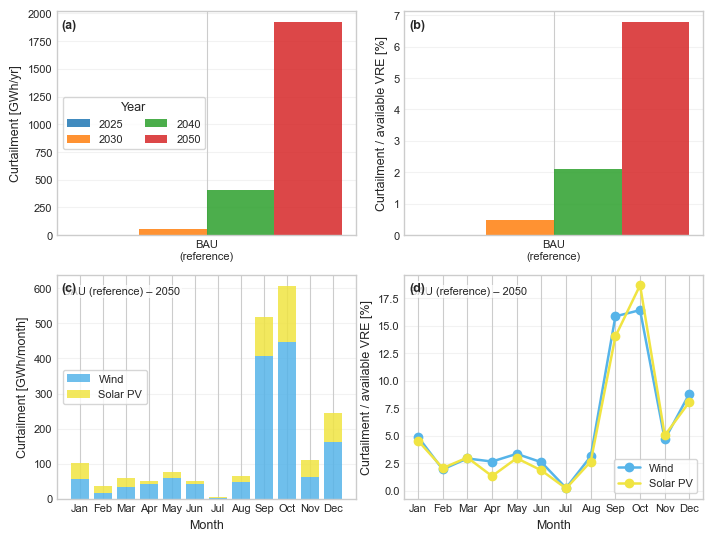

In [37]:
# Curtailment figures
curtailment_focus_scenario = active_scenario
curtailment_focus_year = detailed_year

if curtailment_annual_total.empty:
    raise ValueError("No curtailment summary available. Run the previous cell first.")

# Ordered labels for the annual plots
scenario_order = [s for s in SCENARIO_PLOT_ORDER if s in curtailment_annual_total["scenario"].unique()]
plot_df = curtailment_annual_total.copy()
plot_df["scenario"] = pd.Categorical(plot_df["scenario"], categories=scenario_order, ordered=True)
plot_df = plot_df.sort_values(["scenario", "year"]).copy()
plot_df["x_label"] = [scenario_axis_label(s) for s in plot_df["scenario"]]

unique_scenarios = plot_df[["scenario", "paper_id", "x_label"]].drop_duplicates().sort_values("scenario")
scenario_codes = unique_scenarios["scenario"].tolist()
xlabels = [scenario_axis_label(s) for s in unique_scenarios["scenario"].tolist()]
unique_years = sorted(plot_df["year"].unique())
x = np.arange(len(scenario_codes))
bar_width = 0.8 / max(len(unique_years), 1)

fig, axes = plt.subplots(2, 2, figsize=FIGSIZE_2COL_LARGE)

# (a) Total annual curtailment [GWh/yr]
ax = axes[0, 0]
for i, year in enumerate(unique_years):
    tmp = plot_df[plot_df["year"] == year].set_index("scenario").reindex(scenario_codes)
    values = tmp["curtailment_mwh"].fillna(0).values / 1e3
    ax.bar(x + (i - (len(unique_years)-1)/2) * bar_width, values, width=bar_width, label=str(year), alpha=0.85)
ax.set_xticks(x)
ax.set_xticklabels(xlabels, rotation=0, ha="center")
finish_axis(ax, ylabel="Curtailment [GWh/yr]")
ax.legend(title="Year", ncol=2, frameon=True)
panel_label(ax, "(a)")

# (b) Curtailment share of available VRE [%]
ax = axes[0, 1]
for i, year in enumerate(unique_years):
    tmp = plot_df[plot_df["year"] == year].set_index("scenario").reindex(scenario_codes)
    values = tmp["curtailment_share_available_pct"].fillna(0).values
    ax.bar(x + (i - (len(unique_years)-1)/2) * bar_width, values, width=bar_width, label=str(year), alpha=0.85)
ax.set_xticks(x)
ax.set_xticklabels(xlabels, rotation=0, ha="center")
finish_axis(ax, ylabel="Curtailment / available VRE [%]")
panel_label(ax, "(b)")

# Monthly deep-dive for a selected scenario/year
month_order = ["Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]
monthly_focus = curtailment_monthly_summary[
    (curtailment_monthly_summary["scenario"] == curtailment_focus_scenario) &
    (curtailment_monthly_summary["year"] == curtailment_focus_year)
].copy()
monthly_focus["month"] = pd.Categorical(monthly_focus["month"], categories=month_order, ordered=True)
monthly_focus = monthly_focus.sort_values(["month", "carrier"])

# (c) Monthly curtailment [GWh/month]
ax = axes[1, 0]
if not monthly_focus.empty:
    pivot_gwh = monthly_focus.pivot_table(index="month", columns="carrier", values="curtailment_mwh", aggfunc="sum").fillna(0) / 1e3
    month_x = np.arange(len(pivot_gwh))
    bottom = np.zeros(len(pivot_gwh))
    for carrier in [c for c in ["wind", "solar"] if c in pivot_gwh.columns]:
        vals = pivot_gwh[carrier].values
        ax.bar(month_x, vals, bottom=bottom, color=TECH_COLORS.get(carrier, "#999999"), alpha=0.85, label=clean_technology_label(carrier))
        bottom += vals
    ax.set_xticks(month_x)
    ax.set_xticklabels(pivot_gwh.index.astype(str))
    ax.legend(frameon=True)
finish_axis(ax, xlabel="Month", ylabel="Curtailment [GWh/month]")
ax.tick_params(axis="x", rotation=0)
ax.text(0.02, 0.95, f"{scenario_label(curtailment_focus_scenario)} – {curtailment_focus_year}", transform=ax.transAxes, ha="left", va="top", fontsize=FONT_SIZE_SMALL, bbox=dict(facecolor="white", edgecolor="none", alpha=0.7, pad=1.2))
panel_label(ax, "(c)")

# (d) Monthly curtailment share [%]
ax = axes[1, 1]
if not monthly_focus.empty:
    pivot_pct = monthly_focus.pivot_table(index="month", columns="carrier", values="curtailment_share_available_pct", aggfunc="sum").fillna(0)
    for carrier in [c for c in ["wind", "solar"] if c in pivot_pct.columns]:
        month_x_pct = np.arange(len(pivot_pct))
        ax.plot(month_x_pct, pivot_pct[carrier].values, marker="o", linewidth=1.8, label=clean_technology_label(carrier), color=TECH_COLORS.get(carrier, "#999999"))
    ax.set_xticks(np.arange(len(pivot_pct)))
    ax.set_xticklabels(pivot_pct.index.astype(str))
    ax.legend(frameon=True)
finish_axis(ax, xlabel="Month", ylabel="Curtailment / available VRE [%]")
ax.tick_params(axis="x", rotation=0)
ax.text(0.02, 0.95, f"{scenario_label(curtailment_focus_scenario)} – {curtailment_focus_year}", transform=ax.transAxes, ha="left", va="top", fontsize=FONT_SIZE_SMALL, bbox=dict(facecolor="white", edgecolor="none", alpha=0.7, pad=1.2))
panel_label(ax, "(d)")

plt.tight_layout(rect=[0, 0, 1, 0.98])
plt.show()


## 5. Monthly operation, emissions and hydro


Saved figure: output\output_new_zealand\figures\figure_monthly_system_hydro_reference_2050.png


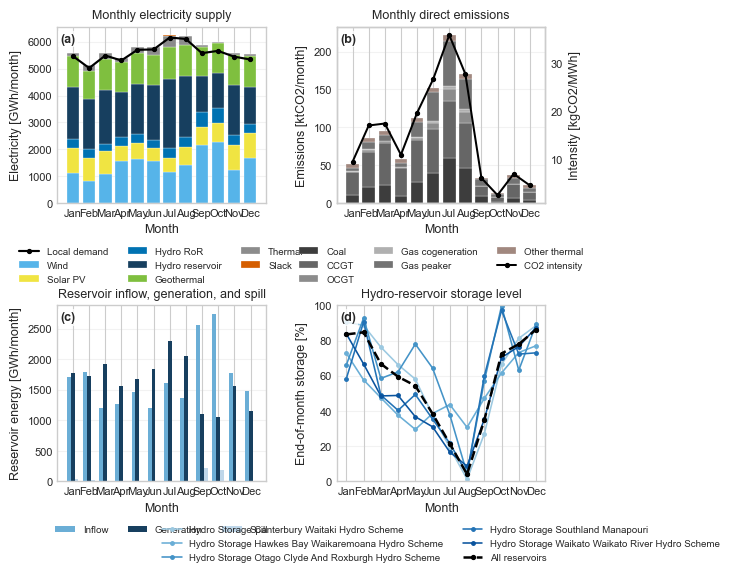

Saved monthly supply table: output\output_new_zealand\tables\monthly\new_zealand_reference_monthly_supply_2050.csv
Saved monthly emissions table: output\output_new_zealand\tables\monthly\new_zealand_reference_monthly_emissions_2050.csv
Saved monthly reservoir table: output\output_new_zealand\tables\monthly\new_zealand_reference_monthly_reservoirs_2050.csv
Saved monthly reservoir SOC table: output\output_new_zealand\tables\monthly\new_zealand_reference_monthly_reservoir_soc_2050.csv


In [ ]:
# Monthly system operation and hydro-reservoir diagnostics
monthly_scenario = active_scenario
monthly_year = detailed_year
monthly_result = scenario_results[monthly_scenario]["results"][monthly_year]
monthly_net = monthly_result["network"]


def _materialise_table(value) -> pd.DataFrame:
    """Load a disk-backed table or copy an in-memory DataFrame."""
    if value is None:
        return pd.DataFrame()
    if hasattr(value, "load"):
        return value.load()
    if isinstance(value, pd.DataFrame):
        return value.copy()
    return pd.DataFrame(value)


def _dynamic_table_or_zero(
    namespace,
    attribute: str,
    snapshots: pd.Index,
    columns: pd.Index,
) -> pd.DataFrame:
    """Load an optional dynamic table and align it to snapshots/assets."""
    try:
        value = getattr(namespace, attribute)
        table = _materialise_table(value)
    except Exception:
        table = pd.DataFrame()

    return table.reindex(
        index=snapshots,
        columns=columns,
        fill_value=0.0,
    ).fillna(0.0)


def _monthly_weights(net) -> pd.Series:
    """Return hourly-equivalent snapshot weights used for energy totals."""
    snapshots = pd.DatetimeIndex(pd.to_datetime(net.snapshots))
    try:
        weight_table = _materialise_table(net.snapshot_weightings)
        for column in ("generators", "objective", "stores"):
            if column in weight_table.columns:
                return (
                    pd.to_numeric(
                        weight_table[column],
                        errors="coerce",
                    )
                    .reindex(snapshots)
                    .fillna(1.0)
                )
    except Exception:
        pass
    return pd.Series(1.0, index=snapshots, dtype=float)


def _monthly_sum(
    values: pd.DataFrame | pd.Series,
    weights: pd.Series,
) -> pd.DataFrame | pd.Series:
    """Convert MW snapshots to weighted monthly MWh."""
    aligned = values.copy()
    aligned.index = pd.DatetimeIndex(pd.to_datetime(aligned.index))
    weighted = aligned.mul(
        weights.reindex(aligned.index).fillna(1.0),
        axis=0,
    )
    return (
        weighted.groupby(weighted.index.month)
        .sum()
        .reindex(
            range(1, 13),
            fill_value=0.0,
        )
    )


def _effective_storage_energy_capacity(
    storage_units: pd.DataFrame,
    assets: pd.Index,
) -> pd.Series:
    """Return energy capacity [MWh] for BESS or hydro StorageUnits."""
    if len(assets) == 0:
        return pd.Series(dtype=float)

    table = storage_units.loc[assets]
    power = _nominal_capacity(
        table,
        "p_nom_opt",
        "p_nom",
    )
    fallback = power * pd.to_numeric(
        table.get(
            "max_hours",
            pd.Series(0.0, index=assets),
        ),
        errors="coerce",
    ).fillna(0.0)

    if "hydro_energy_capacity_mwh" in table.columns:
        explicit = pd.to_numeric(
            table["hydro_energy_capacity_mwh"],
            errors="coerce",
        )
        return explicit.where(
            explicit > 0.0,
            fallback,
        ).fillna(fallback)

    return fallback


monthly_snapshots = pd.DatetimeIndex(pd.to_datetime(monthly_net.snapshots))
monthly_weights = _monthly_weights(monthly_net)

generators_monthly = _materialise_table(monthly_net.generators)
storage_units_monthly = _materialise_table(monthly_net.storage_units)
links_monthly = _materialise_table(monthly_net.links)
carriers_monthly = _materialise_table(monthly_net.carriers)

# ── Monthly electricity supply ────────────────────────────────────────────────
monthly_supply_hourly = pd.DataFrame(
    index=monthly_snapshots,
    dtype=float,
)

if not generators_monthly.empty:
    generator_dispatch_monthly = _dynamic_table_or_zero(
        monthly_net.generators_t,
        "p",
        monthly_snapshots,
        generators_monthly.index,
    ).clip(lower=0.0)

    generator_groups = generators_monthly["carrier"].map(clean_technology_group)
    monthly_supply_hourly = generator_dispatch_monthly.T.groupby(generator_groups).sum().T

bess_assets_monthly = storage_unit_assets(
    monthly_net,
    "BESS",
)
reservoir_assets_monthly = storage_unit_assets(
    monthly_net,
    "Hydro reservoir",
)

storage_power_monthly = _dynamic_table_or_zero(
    monthly_net.storage_units_t,
    "p",
    monthly_snapshots,
    storage_units_monthly.index,
)

for group, assets in [
    ("BESS", bess_assets_monthly),
    ("Hydro reservoir", reservoir_assets_monthly),
]:
    if len(assets) == 0:
        continue
    monthly_supply_hourly[group] = monthly_supply_hourly.get(
        group,
        pd.Series(0.0, index=monthly_snapshots),
    ) + storage_power_monthly[assets].clip(lower=0.0).sum(axis=1)

# Electricity produced by hydrogen conversion links.
if not links_monthly.empty:
    for carrier, group in [
        ("h2_fuel_cell", "Hydrogen"),
        ("h2_turbine", "Hydrogen"),
    ]:
        selected = links_monthly.index[links_monthly["carrier"].astype(str).eq(carrier)]
        if len(selected) == 0:
            continue
        output = (
            (
                -_dynamic_table_or_zero(
                    monthly_net.links_t,
                    "p1",
                    monthly_snapshots,
                    selected,
                )
            )
            .clip(lower=0.0)
            .sum(axis=1)
        )
        monthly_supply_hourly[group] = (
            monthly_supply_hourly.get(
                group,
                pd.Series(0.0, index=monthly_snapshots),
            )
            + output
        )

monthly_supply_gwh = (
    _monthly_sum(
        monthly_supply_hourly,
        monthly_weights,
    )
    / 1e3
)

load_monthly_table = _materialise_table(monthly_result["load"])
load_monthly_table = load_monthly_table.reindex(
    monthly_snapshots,
    fill_value=0.0,
)
local_load_hourly = load_monthly_table.sum(axis=1)
monthly_local_load_gwh = (
    _monthly_sum(
        local_load_hourly,
        monthly_weights,
    )
    / 1e3
)

monthly_bess_charge_gwh = pd.Series(
    0.0,
    index=range(1, 13),
    dtype=float,
)
if len(bess_assets_monthly) > 0:
    monthly_bess_charge_gwh = (
        _monthly_sum(
            -storage_power_monthly[bess_assets_monthly].clip(upper=0.0).sum(axis=1),
            monthly_weights,
        )
        / 1e3
    )

monthly_flexible_use_hourly = pd.Series(
    0.0,
    index=monthly_snapshots,
    dtype=float,
)
if not links_monthly.empty:
    for carrier in [
        "electrolyzer",
        "electrolyser",
        "asu",
        "dac",
    ]:
        selected = links_monthly.index[links_monthly["carrier"].astype(str).eq(carrier)]
        if len(selected) == 0:
            continue
        monthly_flexible_use_hourly = monthly_flexible_use_hourly + _dynamic_table_or_zero(
            monthly_net.links_t,
            "p0",
            monthly_snapshots,
            selected,
        ).clip(lower=0.0).sum(axis=1)

monthly_flexible_use_gwh = (
    _monthly_sum(
        monthly_flexible_use_hourly,
        monthly_weights,
    )
    / 1e3
)
monthly_total_electricity_use_gwh = monthly_local_load_gwh + monthly_flexible_use_gwh + monthly_bess_charge_gwh

# ── Monthly CO2 emissions ─────────────────────────────────────────────────────
monthly_emissions_kt = pd.DataFrame(
    index=range(1, 13),
    dtype=float,
)

if not generators_monthly.empty and "co2_emissions" in carriers_monthly.columns:
    generator_dispatch_for_emissions = _dynamic_table_or_zero(
        monthly_net.generators_t,
        "p",
        monthly_snapshots,
        generators_monthly.index,
    ).clip(lower=0.0)

    carrier_factor = (
        generators_monthly["carrier"]
        .map(
            pd.to_numeric(
                carriers_monthly["co2_emissions"],
                errors="coerce",
            )
        )
        .fillna(0.0)
    )
    efficiency = (
        pd.to_numeric(
            generators_monthly.get(
                "efficiency",
                pd.Series(1.0, index=generators_monthly.index),
            ),
            errors="coerce",
        )
        .replace(0.0, np.nan)
        .fillna(1.0)
    )

    emissions_by_generator = generator_dispatch_for_emissions.multiply(
        carrier_factor / efficiency,
        axis=1,
    )

    emission_plot_keys = []
    for asset in generators_monthly.index:
        key = dispatch_plot_key(generators_monthly.loc[asset, "carrier"])
        if key in {
            "coal",
            "diesel",
            "ccgt",
            "ocgt",
            "gas_cogeneration",
            "gas_peaker",
            "thermal_other",
        }:
            emission_plot_keys.append(key)
        else:
            emission_plot_keys.append("other")

    emissions_grouped_hourly = emissions_by_generator.T.groupby(pd.Index(emission_plot_keys)).sum().T
    monthly_emissions_kt = (
        _monthly_sum(
            emissions_grouped_hourly,
            monthly_weights,
        )
        / 1e3
    )

monthly_total_emissions_t = monthly_emissions_kt.sum(axis=1) * 1e3
monthly_emissions_intensity = (
    1e3 * monthly_total_emissions_t.div((monthly_local_load_gwh * 1e3).replace(0.0, np.nan))
).fillna(0.0)

# ── Monthly reservoir operation and state of charge ───────────────────────────
reservoir_monthly_long = pd.DataFrame()
reservoir_soc_monthly = pd.DataFrame(
    index=range(1, 13),
)

if len(reservoir_assets_monthly) > 0:
    reservoir_inflow = _dynamic_table_or_zero(
        monthly_net.storage_units_t,
        "inflow",
        monthly_snapshots,
        reservoir_assets_monthly,
    ).clip(lower=0.0)
    reservoir_spill = _dynamic_table_or_zero(
        monthly_net.storage_units_t,
        "spill",
        monthly_snapshots,
        reservoir_assets_monthly,
    ).clip(lower=0.0)
    reservoir_generation = storage_power_monthly[reservoir_assets_monthly].clip(lower=0.0)
    reservoir_soc_mwh = _dynamic_table_or_zero(
        monthly_net.storage_units_t,
        "state_of_charge",
        monthly_snapshots,
        reservoir_assets_monthly,
    )

    reservoir_energy_capacity = _effective_storage_energy_capacity(
        storage_units_monthly,
        reservoir_assets_monthly,
    )

    reservoir_inflow_gwh = (
        _monthly_sum(
            reservoir_inflow,
            monthly_weights,
        )
        / 1e3
    )
    reservoir_generation_gwh = (
        _monthly_sum(
            reservoir_generation,
            monthly_weights,
        )
        / 1e3
    )
    reservoir_spill_gwh = (
        _monthly_sum(
            reservoir_spill,
            monthly_weights,
        )
        / 1e3
    )

    reservoir_soc_pct_hourly = 100.0 * reservoir_soc_mwh.divide(
        reservoir_energy_capacity.replace(
            0.0,
            np.nan,
        ),
        axis=1,
    )
    reservoir_soc_monthly = (
        reservoir_soc_pct_hourly.groupby(reservoir_soc_pct_hourly.index.month).last().reindex(range(1, 13))
    )

    aggregate_reservoir_soc = 100.0 * reservoir_soc_mwh.sum(axis=1).div(
        float(reservoir_energy_capacity.sum()) if reservoir_energy_capacity.sum() > 0.0 else np.nan
    )
    reservoir_soc_monthly["All reservoirs"] = (
        aggregate_reservoir_soc.groupby(aggregate_reservoir_soc.index.month).last().reindex(range(1, 13))
    )

    long_rows = []
    for asset in reservoir_assets_monthly:
        for month in range(1, 13):
            long_rows.append(
                {
                    "scenario": monthly_scenario,
                    "year": int(monthly_year),
                    "month": int(month),
                    "asset_id": str(asset),
                    "zone": str(
                        storage_units_monthly.loc[asset].get(
                            "bus",
                            "",
                        )
                    ).replace("elec_", "", 1),
                    "power_capacity_mw": float(
                        _nominal_capacity(
                            storage_units_monthly.loc[[asset]],
                            "p_nom_opt",
                            "p_nom",
                        ).sum()
                    ),
                    "energy_capacity_mwh": float(
                        reservoir_energy_capacity.get(
                            asset,
                            0.0,
                        )
                    ),
                    "inflow_gwh": float(
                        reservoir_inflow_gwh.loc[
                            month,
                            asset,
                        ]
                    ),
                    "generation_gwh": float(
                        reservoir_generation_gwh.loc[
                            month,
                            asset,
                        ]
                    ),
                    "spill_gwh": float(
                        reservoir_spill_gwh.loc[
                            month,
                            asset,
                        ]
                    ),
                    "end_soc_pct": float(
                        reservoir_soc_monthly.loc[
                            month,
                            asset,
                        ]
                    ),
                }
            )
    reservoir_monthly_long = pd.DataFrame(long_rows)

# ── Export monthly tables ──────────────────────────────────────────────────────
monthly_output_dir = TABLE_EXPORT_DIR / "monthly"
monthly_output_dir.mkdir(
    parents=True,
    exist_ok=True,
)

monthly_supply_export = monthly_supply_gwh.copy()
monthly_supply_export.insert(
    0,
    "local_load_gwh",
    monthly_local_load_gwh,
)
monthly_supply_export.insert(
    1,
    "total_electricity_use_gwh",
    monthly_total_electricity_use_gwh,
)
monthly_supply_export.insert(
    2,
    "bess_charge_gwh",
    monthly_bess_charge_gwh,
)
monthly_supply_export.index.name = "month"
monthly_supply_path = monthly_output_dir / f"{base_case_name}_{monthly_scenario}_monthly_supply_{monthly_year}.csv"
monthly_supply_export.to_csv(monthly_supply_path)

monthly_emissions_export = monthly_emissions_kt.copy()
monthly_emissions_export["total_emissions_ktco2"] = monthly_emissions_kt.sum(axis=1)
monthly_emissions_export["emissions_intensity_kgco2_per_mwh"] = monthly_emissions_intensity
monthly_emissions_export.index.name = "month"
monthly_emissions_path = (
    monthly_output_dir / f"{base_case_name}_{monthly_scenario}_monthly_emissions_{monthly_year}.csv"
)
monthly_emissions_export.to_csv(monthly_emissions_path)

if not reservoir_monthly_long.empty:
    reservoir_monthly_path = (
        monthly_output_dir / f"{base_case_name}_{monthly_scenario}_monthly_reservoirs_{monthly_year}.csv"
    )
    reservoir_monthly_long.to_csv(
        reservoir_monthly_path,
        index=False,
    )

    reservoir_soc_export = reservoir_soc_monthly.copy()
    reservoir_soc_export.index.name = "month"
    reservoir_soc_path = (
        monthly_output_dir / f"{base_case_name}_{monthly_scenario}_monthly_reservoir_soc_{monthly_year}.csv"
    )
    reservoir_soc_export.to_csv(
        reservoir_soc_path,
    )

# ── Four-panel monthly figure ─────────────────────────────────────────────────
month_numbers = np.arange(1, 13)
month_labels = [
    "Jan",
    "Feb",
    "Mar",
    "Apr",
    "May",
    "Jun",
    "Jul",
    "Aug",
    "Sep",
    "Oct",
    "Nov",
    "Dec",
]

fig_monthly, axes_monthly = plt.subplots(
    2,
    2,
    figsize=(WORD_DOUBLE_COL_IN, 6.4),
)
ax_dispatch, ax_emissions, ax_hydro, ax_soc = axes_monthly.ravel()

# (a) Monthly electricity supply
monthly_plot_groups = [
    group for group in TECH_GROUPS if group in monthly_supply_gwh.columns and monthly_supply_gwh[group].sum() > 1e-6
]
bottom = np.zeros(12)
for group in monthly_plot_groups:
    values = monthly_supply_gwh[group].to_numpy()
    ax_dispatch.bar(
        month_numbers,
        values,
        bottom=bottom,
        width=0.78,
        color=TECH_COLORS_GROUPED.get(
            group,
            "#999999",
        ),
        label=TECH_LEGEND_LABELS.get(
            group,
            group,
        ),
        edgecolor="white",
        linewidth=0.2,
    )
    bottom += values

ax_dispatch.plot(
    month_numbers,
    monthly_local_load_gwh.to_numpy(),
    color="black",
    linewidth=1.55,
    marker="o",
    markersize=2.8,
    label="Local demand",
)
if (monthly_total_electricity_use_gwh - monthly_local_load_gwh).abs().sum() > 1e-6:
    ax_dispatch.plot(
        month_numbers,
        monthly_total_electricity_use_gwh.to_numpy(),
        color="black",
        linewidth=1.25,
        linestyle="--",
        label="Demand + flexible use",
    )
finish_axis(
    ax_dispatch,
    xlabel="Month",
    ylabel="Electricity [GWh/month]",
)
ax_dispatch.set_xticks(
    month_numbers,
    month_labels,
)
ax_dispatch.legend(
    loc="upper center",
    bbox_to_anchor=(0.5, -0.20),
    ncol=3,
    frameon=False,
    fontsize=FONT_SIZE_SMALL - 1,
)
panel_label(ax_dispatch, "(a)")
ax_dispatch.set_title(
    "Monthly electricity supply",
    fontsize=FONT_SIZE_BASE,
)

# (b) Monthly emissions and intensity
emission_order = [
    "coal",
    "ccgt",
    "ocgt",
    "gas_cogeneration",
    "gas_peaker",
    "thermal_other",
    "diesel",
    "other",
]
emission_labels = {
    "coal": "Coal",
    "ccgt": "CCGT",
    "ocgt": "OCGT",
    "gas_cogeneration": "Gas cogeneration",
    "gas_peaker": "Gas peaker",
    "thermal_other": "Other thermal",
    "diesel": "Diesel",
    "other": "Other",
}
emission_bottom = np.zeros(12)
used_emission_keys = []

for key in emission_order:
    if key not in monthly_emissions_kt.columns or monthly_emissions_kt[key].sum() <= 1e-9:
        continue
    values = monthly_emissions_kt[key].to_numpy()
    ax_emissions.bar(
        month_numbers,
        values,
        bottom=emission_bottom,
        width=0.78,
        color=TECH_COLORS.get(
            key,
            "#999999",
        ),
        label=emission_labels.get(
            key,
            key,
        ),
        edgecolor="white",
        linewidth=0.2,
    )
    emission_bottom += values
    used_emission_keys.append(key)

ax_emissions_intensity = ax_emissions.twinx()
ax_emissions_intensity.plot(
    month_numbers,
    monthly_emissions_intensity.to_numpy(),
    color="black",
    linewidth=1.45,
    marker="o",
    markersize=2.8,
    label="CO2 intensity",
)
finish_axis(
    ax_emissions,
    xlabel="Month",
    ylabel="Emissions [ktCO2/month]",
)
ax_emissions_intensity.set_ylabel(
    "Intensity [kgCO2/MWh]",
)
ax_emissions_intensity.grid(False)
ax_emissions.set_xticks(
    month_numbers,
    month_labels,
)
if used_emission_keys:
    handles_left, labels_left = ax_emissions.get_legend_handles_labels()
    handles_right, labels_right = ax_emissions_intensity.get_legend_handles_labels()
    ax_emissions.legend(
        handles_left + handles_right,
        labels_left + labels_right,
        loc="upper center",
        bbox_to_anchor=(0.5, -0.20),
        ncol=3,
        frameon=False,
        fontsize=FONT_SIZE_SMALL - 1,
    )
else:
    ax_emissions.text(
        0.5,
        0.5,
        "No direct generator CO2 emissions",
        transform=ax_emissions.transAxes,
        ha="center",
        va="center",
        fontsize=FONT_SIZE_SMALL,
        color="#555555",
    )
panel_label(ax_emissions, "(b)")
ax_emissions.set_title(
    "Monthly direct emissions",
    fontsize=FONT_SIZE_BASE,
)

# (c) Monthly reservoir water-energy balance
if len(reservoir_assets_monthly) > 0:
    total_inflow = reservoir_inflow_gwh.sum(axis=1)
    total_generation = reservoir_generation_gwh.sum(axis=1)
    total_spill = reservoir_spill_gwh.sum(axis=1)
    width = 0.24

    ax_hydro.bar(
        month_numbers - width,
        total_inflow.to_numpy(),
        width=width,
        color=TECH_COLORS["hydro_inflow"],
        label="Inflow",
    )
    ax_hydro.bar(
        month_numbers,
        total_generation.to_numpy(),
        width=width,
        color=TECH_COLORS["hydro_reservoir"],
        label="Generation",
    )
    ax_hydro.bar(
        month_numbers + width,
        total_spill.to_numpy(),
        width=width,
        color=TECH_COLORS["hydro_spill"],
        label="Spill",
    )
    ax_hydro.legend(
        loc="upper center",
        bbox_to_anchor=(0.5, -0.20),
        ncol=3,
        frameon=False,
        fontsize=FONT_SIZE_SMALL - 1,
    )
else:
    ax_hydro.text(
        0.5,
        0.5,
        "No hydro-reservoir StorageUnits",
        transform=ax_hydro.transAxes,
        ha="center",
        va="center",
        fontsize=FONT_SIZE_SMALL,
        color="#555555",
    )
finish_axis(
    ax_hydro,
    xlabel="Month",
    ylabel="Reservoir energy [GWh/month]",
)
ax_hydro.set_xticks(
    month_numbers,
    month_labels,
)
panel_label(ax_hydro, "(c)")
ax_hydro.set_title(
    "Reservoir inflow, generation, and spill",
    fontsize=FONT_SIZE_BASE,
)

# (d) End-of-month reservoir state of charge
if len(reservoir_assets_monthly) > 0:
    reservoir_colormap = plt.get_cmap("Blues")
    n_reservoirs = max(
        len(reservoir_assets_monthly),
        1,
    )
    for index, asset in enumerate(reservoir_assets_monthly):
        label = str(asset).replace("hydro_reservoir_", "").replace("_", " ").title()
        ax_soc.plot(
            month_numbers,
            reservoir_soc_monthly[asset],
            color=reservoir_colormap(0.38 + 0.48 * (index / max(n_reservoirs - 1, 1))),
            linewidth=1.15,
            marker="o",
            markersize=2.5,
            label=label,
        )

    ax_soc.plot(
        month_numbers,
        reservoir_soc_monthly["All reservoirs"],
        color="black",
        linewidth=1.8,
        linestyle="--",
        marker="o",
        markersize=2.8,
        label="All reservoirs",
    )
    ax_soc.set_ylim(
        0.0,
        100.0,
    )
    ax_soc.legend(
        loc="upper center",
        bbox_to_anchor=(0.5, -0.20),
        ncol=2,
        frameon=False,
        fontsize=FONT_SIZE_SMALL - 1,
    )
else:
    ax_soc.text(
        0.5,
        0.5,
        "Reservoir state of charge unavailable",
        transform=ax_soc.transAxes,
        ha="center",
        va="center",
        fontsize=FONT_SIZE_SMALL,
        color="#555555",
    )
finish_axis(
    ax_soc,
    xlabel="Month",
    ylabel="End-of-month storage [%]",
)
ax_soc.set_xticks(
    month_numbers,
    month_labels,
)
panel_label(ax_soc, "(d)")
ax_soc.set_title(
    "Hydro-reservoir storage level",
    fontsize=FONT_SIZE_BASE,
)

fig_monthly.subplots_adjust(
    top=0.93,
    bottom=0.22,
    hspace=0.58,
    wspace=0.34,
)
monthly_figure_path = save_paper_figure(
    fig_monthly,
    f"figure_monthly_system_hydro_{monthly_scenario}_{monthly_year}.png",
)
plt.show()

print(f"Saved monthly supply table: {monthly_supply_path}")
print(f"Saved monthly emissions table: {monthly_emissions_path}")
if not reservoir_monthly_long.empty:
    print(f"Saved monthly reservoir table: {reservoir_monthly_path}")
    print(f"Saved monthly reservoir SOC table: {reservoir_soc_path}")


## 6. Hydrogen and underground hydrogen storage


### 6.1 Annual hydrogen/UHS operation and installed assets


In [ ]:
# Hydrogen and UHS operation
analysis_year = detailed_year
HYDROGEN_ANALYSIS_SCENARIO = next(
    (code for code in ["NZE", "RE95", active_scenario] if code in scenario_results),
    active_scenario,
)
n = scenario_results[HYDROGEN_ANALYSIS_SCENARIO]["results"][analysis_year]["network"]
hydrogen_link_carriers = ["electrolyzer", "h2_fuel_cell", "h2_turbine", "uhs_injection", "uhs_withdrawal"]
hydrogen_store_carriers = ["hydrogen_storage", "uhs_storage"]

links_static = materialise_static_table(n, "links")
stores_static = materialise_static_table(n, "stores")
hydrogen_links = (
    links_static.loc[links_static["carrier"].isin(hydrogen_link_carriers)].copy()
    if "carrier" in links_static.columns
    else pd.DataFrame()
)
hydrogen_stores = (
    stores_static.loc[stores_static["carrier"].isin(hydrogen_store_carriers)].copy()
    if "carrier" in stores_static.columns
    else pd.DataFrame()
)

if hydrogen_links.empty and hydrogen_stores.empty:
    print(
        f"No hydrogen/UHS assets in the network for {analysis_year}. "
        f"enable_hydrogen="
        f"{scenario_results[HYDROGEN_ANALYSIS_SCENARIO]['metadata'].get('enable_hydrogen', False)}. "
        "Hydrogen figures are skipped and the notebook continues."
    )
else:

    def _zero_series() -> pd.Series:
        """Return a zero-valued series aligned with the network snapshots."""
        return pd.Series(0.0, index=n.snapshots)

    def _link_input_series(link_index: pd.Index) -> pd.Series:
        """Aggregate electricity input (p0) for the given link indices."""
        if len(link_index) == 0:
            return _zero_series()
        return n.links_t.p0[link_index].clip(lower=0).sum(axis=1)

    def _link_output_series(link_index: pd.Index) -> pd.Series:
        """Aggregate useful output (p0 * efficiency) for the given link indices."""
        if len(link_index) == 0:
            return _zero_series()
        efficiency = links_static.loc[link_index, "efficiency"].fillna(1.0)
        dispatch = n.links_t.p0[link_index].clip(lower=0)
        return dispatch.multiply(efficiency, axis=1).sum(axis=1)

    electrolyzer_links = hydrogen_links.index[hydrogen_links["carrier"] == "electrolyzer"]
    fuel_cell_links = hydrogen_links.index[hydrogen_links["carrier"] == "h2_fuel_cell"]
    turbine_links = hydrogen_links.index[hydrogen_links["carrier"] == "h2_turbine"]
    uhs_injection_links = hydrogen_links.index[hydrogen_links["carrier"] == "uhs_injection"]
    uhs_withdrawal_links = hydrogen_links.index[hydrogen_links["carrier"] == "uhs_withdrawal"]

    electrolyzer_power = _link_input_series(electrolyzer_links)
    hydrogen_production = _link_output_series(electrolyzer_links)
    fuel_cell_power = _link_output_series(fuel_cell_links)
    turbine_power = _link_output_series(turbine_links)
    hydrogen_to_power = fuel_cell_power + turbine_power
    hydrogen_reconversion_input = _link_input_series(fuel_cell_links) + _link_input_series(turbine_links)

    uhs_injection_power = _link_input_series(uhs_injection_links)
    uhs_withdrawal_power = _link_output_series(uhs_withdrawal_links)

    tank_stores = hydrogen_stores.index[hydrogen_stores["carrier"] == "hydrogen_storage"]
    uhs_stores = hydrogen_stores.index[hydrogen_stores["carrier"] == "uhs_storage"]

    tank_inventory = _zero_series() if len(tank_stores) == 0 else n.stores_t.e[tank_stores].sum(axis=1)
    uhs_inventory = _zero_series() if len(uhs_stores) == 0 else n.stores_t.e[uhs_stores].sum(axis=1)
    hydrogen_inventory = tank_inventory + uhs_inventory

    tank_inventory_ton = tank_inventory / H2_LHV_MWH_PER_TON
    uhs_inventory_ton = uhs_inventory / H2_LHV_MWH_PER_TON
    hydrogen_inventory_ton = hydrogen_inventory / H2_LHV_MWH_PER_TON

    fig, axes = plt.subplots(4, 1, figsize=(WORD_DOUBLE_COL_IN, 8.5), sharex=True)

    axes[0].fill_between(
        electrolyzer_power.index,
        0,
        electrolyzer_power,
        color=TECH_COLORS.get("electrolyzer", "#00897b"),
        alpha=0.65,
        label="Electrolyser electricity input",
        step="mid",
    )
    axes[0].plot(
        hydrogen_production.index,
        hydrogen_production,
        color=TECH_COLORS.get("hydrogen_storage", "#26a69a"),
        linewidth=1.8,
        label="Hydrogen production",
    )
    axes[0].fill_between(
        uhs_injection_power.index,
        0,
        uhs_injection_power,
        color=TECH_COLORS.get("uhs_injection", "#1e88e5"),
        alpha=0.35,
        label="UHS injection (H2 -> UHS)",
        step="mid",
    )
    axes[0].set_title(f"Hydrogen/UHS operation {analysis_year}: production and UHS injection", fontsize=12, pad=15)
    axes[0].set_ylabel("Power [MW]", fontsize=11)
    axes[0].legend(loc="best", fontsize=9)
    axes[0].grid(True, alpha=0.3)

    axes[1].fill_between(
        fuel_cell_power.index,
        0,
        fuel_cell_power,
        color=TECH_COLORS.get("h2_fuel_cell", "#ff8f00"),
        alpha=0.65,
        label="Fuel cell electricity output",
        step="mid",
    )
    axes[1].fill_between(
        turbine_power.index,
        fuel_cell_power,
        hydrogen_to_power,
        color=TECH_COLORS.get("h2_turbine", "#6d4c41"),
        alpha=0.65,
        label="H2 turbine electricity output",
        step="mid",
    )
    axes[1].plot(
        hydrogen_reconversion_input.index,
        hydrogen_reconversion_input,
        color="black",
        linewidth=1.5,
        linestyle="--",
        label="Hydrogen input to reconversion",
    )
    axes[1].plot(
        uhs_withdrawal_power.index,
        uhs_withdrawal_power,
        color=TECH_COLORS.get("uhs_withdrawal", "#3949ab"),
        linewidth=1.7,
        label="UHS withdrawal (UHS -> H2)",
    )
    axes[1].set_title(
        f"Hydrogen/UHS operation {analysis_year}: power reconversion and UHS withdrawal", fontsize=12, pad=15
    )
    axes[1].set_ylabel("Power [MW]", fontsize=11)
    axes[1].legend(loc="best", fontsize=9)
    axes[1].grid(True, alpha=0.3)

    axes[2].plot(
        tank_inventory.index,
        tank_inventory,
        color=TECH_COLORS.get("hydrogen_storage", "#26a69a"),
        linewidth=2,
        label="Tank inventory",
    )
    axes[2].plot(
        uhs_inventory.index,
        uhs_inventory,
        color=TECH_COLORS.get("uhs_storage", "#8e24aa"),
        linewidth=2,
        label="UHS inventory",
    )
    axes[2].plot(
        hydrogen_inventory.index,
        hydrogen_inventory,
        color="black",
        linewidth=1.4,
        linestyle="--",
        label="Total H2 inventory",
    )
    axes[2].fill_between(
        tank_inventory.index, 0, tank_inventory, color=TECH_COLORS.get("hydrogen_storage", "#26a69a"), alpha=0.2
    )
    axes[2].fill_between(
        uhs_inventory.index, 0, uhs_inventory, color=TECH_COLORS.get("uhs_storage", "#8e24aa"), alpha=0.15
    )
    axes[2].set_title(f"Hydrogen/UHS operation {analysis_year}: storage inventory", fontsize=12, pad=15)
    axes[2].set_ylabel("Stored energy [MWh]", fontsize=11)
    axes[2].legend(loc="best", fontsize=9)
    axes[2].grid(True, alpha=0.3)

    axes[3].plot(
        tank_inventory_ton.index,
        tank_inventory_ton,
        color=TECH_COLORS.get("hydrogen_storage", "#26a69a"),
        linewidth=2,
        label="Tank inventory",
    )
    axes[3].plot(
        uhs_inventory_ton.index,
        uhs_inventory_ton,
        color=TECH_COLORS.get("uhs_storage", "#8e24aa"),
        linewidth=2,
        label="UHS inventory",
    )
    axes[3].plot(
        hydrogen_inventory_ton.index,
        hydrogen_inventory_ton,
        color="black",
        linewidth=1.4,
        linestyle="--",
        label="Total H2 inventory",
    )
    axes[3].fill_between(
        tank_inventory_ton.index, 0, tank_inventory_ton, color=TECH_COLORS.get("hydrogen_storage", "#26a69a"), alpha=0.2
    )
    axes[3].fill_between(
        uhs_inventory_ton.index, 0, uhs_inventory_ton, color=TECH_COLORS.get("uhs_storage", "#8e24aa"), alpha=0.15
    )
    axes[3].set_title(
        f"Hydrogen/UHS operation {analysis_year}: storage inventory (LHV = {H2_LHV_MWH_PER_TON} MWh/t)",
        fontsize=12,
        pad=15,
    )
    axes[3].set_ylabel("Stored hydrogen [t]", fontsize=11)
    axes[3].set_xlabel("Time", fontsize=11)
    axes[3].legend(loc="best", fontsize=9)
    axes[3].grid(True, alpha=0.3)

    plt.tight_layout()
    plt.show()

    link_capacity_column = "p_nom_opt" if "p_nom_opt" in hydrogen_links.columns else "p_nom"
    link_caps = hydrogen_links[["carrier", "bus0", "bus1", "efficiency"]].copy()
    link_caps["capacity_mw"] = hydrogen_links[link_capacity_column]

    store_caps = pd.DataFrame()
    if not hydrogen_stores.empty:
        store_capacity_column = "e_nom_opt" if "e_nom_opt" in hydrogen_stores.columns else "e_nom"
        store_caps = hydrogen_stores[["carrier", "bus", "standing_loss"]].copy()
        store_caps["energy_capacity_mwh"] = hydrogen_stores[store_capacity_column]

    operation_summary = pd.Series(
        {
            "electrolyser_input_mwh": electrolyzer_power.sum(),
            "hydrogen_production_mwh": hydrogen_production.sum(),
            "uhs_injection_mwh": uhs_injection_power.sum(),
            "uhs_withdrawal_mwh": uhs_withdrawal_power.sum(),
            "hydrogen_reconversion_input_mwh": hydrogen_reconversion_input.sum(),
            "fuel_cell_output_mwh": fuel_cell_power.sum(),
            "h2_turbine_output_mwh": turbine_power.sum(),
            "peak_tank_inventory_mwh": tank_inventory.max(),
            "peak_uhs_inventory_mwh": uhs_inventory.max(),
            "peak_total_h2_inventory_mwh": hydrogen_inventory.max(),
            "peak_tank_inventory_ton": tank_inventory_ton.max(),
            "peak_uhs_inventory_ton": uhs_inventory_ton.max(),
            "peak_total_h2_inventory_ton": hydrogen_inventory_ton.max(),
        },
        name="value",
    ).to_frame()

    display(link_caps.sort_values(["carrier", "capacity_mw"], ascending=[True, False]))
    if not store_caps.empty:
        display(store_caps.sort_values(["carrier", "energy_capacity_mwh"], ascending=[True, False]))
    display(round_numeric_frame(operation_summary, 3))


No hydrogen/UHS assets in the network for 2050. enable_hydrogen=False. Hydrogen figures are skipped and the notebook continues.


### 6.2 Multiscale BESS and hydrogen/UHS operation


No installed BESS assets in reference, 2050. BESS panels are retained as optional placeholders.
No hydrogen/UHS assets in reference, 2050. Hydrogen panels are retained as optional placeholders.
Saved figure: output\output_new_zealand\figures\figure_storage_operation_multiscale_2050.png
Saved figure to: output\output_new_zealand\figures\figure_storage_operation_multiscale_2050.png


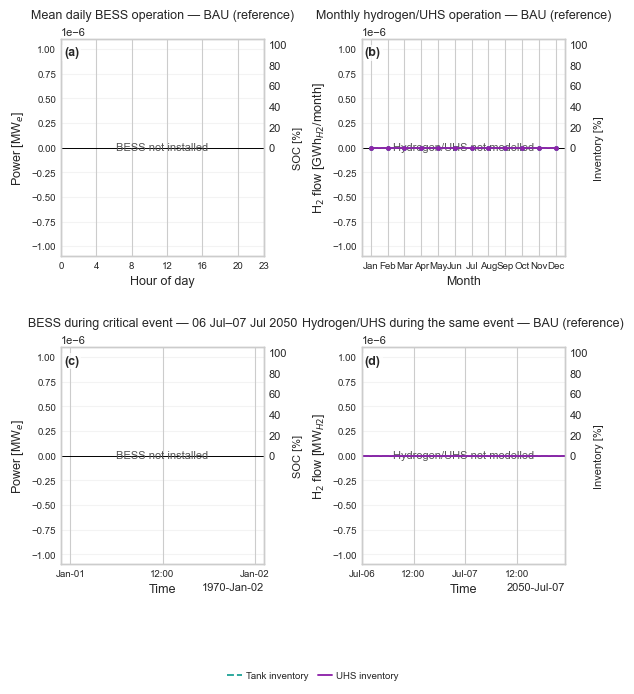

BESS: not installed
Hydrogen/UHS: not modelled


In [ ]:
# Multiscale BESS and hydrogen/UHS operation panel
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from matplotlib.lines import Line2D
from matplotlib.patches import Patch


# ── Configuration ─────────────────────────────────────────────────────────────
operation_year = detailed_year

BESS_SCENARIO = next(
    (code for code in ["RE0", "RE95", "NZE", active_scenario] if code in scenario_results),
    active_scenario,
)
H2_SCENARIO = next(
    (code for code in ["NZE", "RE95", active_scenario] if code in scenario_results),
    active_scenario,
)

# Prefer RT for BESS and RH for H2; fall back to the active scenario when needed.
n_bess = scenario_results[BESS_SCENARIO]["results"][operation_year]["network"]
n_h2 = scenario_results[H2_SCENARIO]["results"][operation_year]["network"]

event_start = pd.Timestamp(critical_event_start)
event_end = pd.Timestamp(critical_event_end)

if event_start.tz is not None:
    event_start = event_start.tz_localize(None)

if event_end.tz is not None:
    event_end = event_end.tz_localize(None)

tech_colors = globals().get("TECH_COLORS", {})
small_font = globals().get("FONT_SIZE_SMALL", 8)
figure_width = globals().get("WORD_DOUBLE_COL_IN", 7.2)

colors = {
    "BESS discharge": tech_colors.get("bess", "#8e5cc7"),
    "BESS charge": tech_colors.get("bess", "#8e5cc7"),
    "BESS SOC": "#4a2373",
    "H2 production": tech_colors.get("electrolyzer", "#00897b"),
    "Tank withdrawal": tech_colors.get("hydrogen_storage", "#26a69a"),
    "UHS withdrawal": tech_colors.get("uhs_withdrawal", "#3949ab"),
    "H2-to-power input": tech_colors.get("h2_fuel_cell", "#ff8f00"),
    "Tank charging": "#80cbc4",
    "UHS injection": tech_colors.get("uhs_injection", "#64b5f6"),
    "Tank inventory": tech_colors.get("hydrogen_storage", "#00897b"),
    "UHS inventory": tech_colors.get("uhs_storage", "#8e24aa"),
}


# ── Extraction helpers ────────────────────────────────────────────────────────
def _normalise(values):
    out = values.copy()
    out.index = pd.DatetimeIndex(pd.to_datetime(out.index))

    if out.index.tz is not None:
        out.index = out.index.tz_localize(None)

    return out.sort_index()


def _zero(net):
    return _normalise(
        pd.Series(
            0.0,
            index=net.snapshots,
        )
    )


def _link_flow(
    net,
    carriers,
    port,
):
    """
    Return positive link input at p0 or useful output at p1 [MW].
    """
    links_static = materialise_static_table(net, "links")
    if "carrier" not in links_static.columns:
        return _zero(net)
    links = links_static.index[links_static["carrier"].astype(str).isin(carriers)]

    if len(links) == 0:
        return _zero(net)

    values = getattr(
        net.links_t,
        port,
    ).reindex(
        index=net.snapshots,
        columns=links,
        fill_value=0.0,
    )

    # PyPSA p1 is negative when energy leaves the link.
    if port == "p1":
        values = -values

    return _normalise(values.clip(lower=0.0).sum(axis=1))


def _effective_capacity(
    table,
    index,
    optimised_column,
    fixed_column,
):
    fixed = pd.to_numeric(
        table.loc[index, fixed_column],
        errors="coerce",
    ).fillna(0.0)

    if optimised_column not in table.columns:
        return fixed

    optimised = pd.to_numeric(
        table.loc[index, optimised_column],
        errors="coerce",
    )

    return optimised.fillna(fixed)


def _store_data(
    net,
    carrier,
):
    """
    Return discharge, charging, inventory percentage, and capacity.

    Store p > 0: discharge.
    Store p < 0: charging.
    """
    stores_static = materialise_static_table(net, "stores")
    if "carrier" not in stores_static.columns:
        return _zero(net), _zero(net), _zero(net), 0.0
    stores = stores_static.index[stores_static["carrier"].astype(str) == carrier]

    if len(stores) == 0:
        zero = _zero(net)

        return (
            zero,
            zero.copy(),
            zero * np.nan,
            0.0,
        )

    power = net.stores_t.p.reindex(
        index=net.snapshots,
        columns=stores,
        fill_value=0.0,
    )

    inventory = net.stores_t.e.reindex(
        index=net.snapshots,
        columns=stores,
        fill_value=0.0,
    ).sum(axis=1)

    energy_capacity = _effective_capacity(
        net.stores,
        stores,
        "e_nom_opt",
        "e_nom",
    ).sum()

    discharge = power.clip(lower=0.0).sum(axis=1)

    charging = -(power.clip(upper=0.0).sum(axis=1))

    if energy_capacity > 0.0:
        inventory_pct = 100.0 * inventory / energy_capacity
    else:
        inventory_pct = inventory * np.nan

    return (
        _normalise(discharge),
        _normalise(charging),
        _normalise(inventory_pct),
        float(energy_capacity),
    )


# ── BESS operation ────────────────────────────────────────────────────────────
bess_units = storage_unit_assets(
    n_bess,
    "BESS",
)
bess_available = False

if len(bess_units) > 0:
    bess_power_by_unit = n_bess.storage_units_t.p.reindex(
        index=n_bess.snapshots,
        columns=bess_units,
        fill_value=0.0,
    )

    bess_soc_mwh = n_bess.storage_units_t.state_of_charge.reindex(
        index=n_bess.snapshots,
        columns=bess_units,
        fill_value=0.0,
    ).sum(axis=1)

    bess_p_nom = _effective_capacity(
        n_bess.storage_units,
        bess_units,
        "p_nom_opt",
        "p_nom",
    )

    bess_max_hours = pd.to_numeric(
        n_bess.storage_units.loc[
            bess_units,
            "max_hours",
        ],
        errors="coerce",
    ).fillna(0.0)

    bess_energy_mwh = float((bess_p_nom * bess_max_hours).sum())

    bess_available = bess_energy_mwh > 0.0 and bess_p_nom.sum() > 0.0
else:
    bess_power_by_unit = pd.DataFrame(
        index=n_bess.snapshots,
    )
    bess_soc_mwh = pd.Series(
        0.0,
        index=n_bess.snapshots,
    )
    bess_p_nom = pd.Series(
        dtype=float,
    )
    bess_energy_mwh = 0.0

# Separate charging and discharging before aggregation. Empty BESS selections
# become zero profiles instead of falling back to hydro StorageUnits.
if bess_available:
    bess_flow = _normalise(
        pd.DataFrame(
            {
                "BESS discharge": (bess_power_by_unit.clip(lower=0.0).sum(axis=1)),
                "BESS charge": (bess_power_by_unit.clip(upper=0.0).sum(axis=1)),
            }
        )
    )

    bess_soc = _normalise(100.0 * bess_soc_mwh / bess_energy_mwh)
else:
    zero_bess = _zero(n_bess)
    bess_flow = _normalise(
        pd.DataFrame(
            {
                "BESS discharge": zero_bess,
                "BESS charge": zero_bess,
            }
        )
    )
    bess_soc = _normalise(zero_bess * np.nan)
    print(
        f"No installed BESS assets in {BESS_SCENARIO}, "
        f"{operation_year}. BESS panels are retained as optional placeholders."
    )


# ── Hydrogen/UHS operation ────────────────────────────────────────────────────
(
    tank_withdrawal,
    tank_charging,
    tank_inventory,
    tank_capacity_mwh,
) = _store_data(
    n_h2,
    "hydrogen_storage",
)

(
    _,
    _,
    uhs_inventory,
    uhs_capacity_mwh,
) = _store_data(
    n_h2,
    "uhs_storage",
)

# All flows are expressed on the H2-energy side:
# sources positive; storage/reconversion uses negative.
h2_flow = _normalise(
    pd.DataFrame(
        {
            "H2 production": _link_flow(
                n_h2,
                [
                    "electrolyzer",
                    "electrolyser",
                ],
                "p1",
            ),
            "Tank withdrawal": tank_withdrawal,
            "UHS withdrawal": _link_flow(
                n_h2,
                ["uhs_withdrawal"],
                "p1",
            ),
            "H2-to-power input": -(
                _link_flow(
                    n_h2,
                    ["h2_fuel_cell"],
                    "p0",
                )
                + _link_flow(
                    n_h2,
                    ["h2_turbine"],
                    "p0",
                )
            ),
            "Tank charging": -tank_charging,
            "UHS injection": -_link_flow(
                n_h2,
                ["uhs_injection"],
                "p0",
            ),
        }
    ).fillna(0.0)
)

h2_inventory = _normalise(
    pd.DataFrame(
        {
            "Tank inventory": tank_inventory,
            "UHS inventory": uhs_inventory,
        }
    )
)

h2_asset_carriers = {
    "electrolyzer",
    "electrolyser",
    "h2_fuel_cell",
    "h2_turbine",
    "uhs_injection",
    "uhs_withdrawal",
}
h2_store_carriers = {
    "hydrogen_storage",
    "uhs_storage",
}

h2_links_static = materialise_static_table(n_h2, "links")
h2_stores_static = materialise_static_table(n_h2, "stores")

h2_available = bool(
    (
        not h2_links_static.empty
        and "carrier" in h2_links_static.columns
        and h2_links_static["carrier"].astype(str).isin(h2_asset_carriers).any()
    )
    or (
        not h2_stores_static.empty
        and "carrier" in h2_stores_static.columns
        and h2_stores_static["carrier"].astype(str).isin(h2_store_carriers).any()
    )
)

if not h2_available:
    print(
        f"No hydrogen/UHS assets in {H2_SCENARIO}, {operation_year}. "
        "Hydrogen panels are retained as optional placeholders."
    )
elif h2_flow.abs().sum().sum() <= 1e-6:
    print(f"Hydrogen/UHS assets exist in {H2_SCENARIO}, {operation_year}, but their operation is zero.")


# ── Mean daily BESS profile ───────────────────────────────────────────────────
bess_daily = bess_flow.copy()
bess_daily["SOC"] = bess_soc
bess_daily["hour"] = bess_daily.index.hour + bess_daily.index.minute / 60.0

bess_mean = bess_daily.groupby("hour").mean()

bess_soc_q25 = bess_daily.groupby("hour")["SOC"].quantile(0.25)

bess_soc_q75 = bess_daily.groupby("hour")["SOC"].quantile(0.75)


# ── Monthly hydrogen flows ────────────────────────────────────────────────────
snapshot_duration = h2_flow.index.to_series().shift(-1) - h2_flow.index.to_series()

typical_duration = snapshot_duration.dropna().median()

if pd.isna(typical_duration):
    typical_duration = pd.Timedelta(hours=1)

snapshot_duration.iloc[-1] = typical_duration

snapshot_hours = snapshot_duration.dt.total_seconds() / 3600.0

h2_monthly = (
    h2_flow.mul(
        snapshot_hours,
        axis=0,
    )
    .groupby(h2_flow.index.month)
    .sum()
    .reindex(
        range(1, 13),
        fill_value=0.0,
    )
    / 1e3
)

h2_inventory_monthly = h2_inventory.groupby(h2_inventory.index.month).last().reindex(range(1, 13)).ffill()


# ── Critical-event data ───────────────────────────────────────────────────────
bess_event_mask = (bess_flow.index >= event_start) & (bess_flow.index <= event_end)

h2_event_mask = (h2_flow.index >= event_start) & (h2_flow.index <= event_end)

bess_event = bess_flow.loc[bess_event_mask]

bess_soc_event = bess_soc.loc[bess_event_mask]

h2_event = h2_flow.loc[h2_event_mask]

h2_inventory_event = h2_inventory.loc[h2_event_mask]

if bess_event.empty:
    fallback_steps = min(
        168,
        len(bess_flow),
    )
    bess_event = bess_flow.iloc[:fallback_steps].copy()
    bess_soc_event = bess_soc.reindex(
        bess_event.index,
    )
    print(
        "The selected critical-event dates do not overlap the BESS network. "
        "The first available seven-day window is shown instead."
    )

if h2_event.empty:
    fallback_steps = min(
        168,
        len(h2_flow),
    )
    h2_event = h2_flow.iloc[:fallback_steps].copy()
    h2_inventory_event = h2_inventory.reindex(
        h2_event.index,
    )
    print(
        "The selected critical-event dates do not overlap the hydrogen network. "
        "The first available seven-day window is shown instead."
    )


# ── Plot helpers ──────────────────────────────────────────────────────────────
def _stack_signed(
    ax,
    frame,
    bars=False,
):
    """
    Stack positive and negative flows independently.

    Positive: production, discharge, withdrawal.
    Negative: charging, injection, reconversion input.
    """
    x = np.arange(1, 13) if bars else frame.index

    positive_bottom = np.zeros(len(frame))

    negative_bottom = np.zeros(len(frame))

    for column in frame.columns:
        raw = frame[column].fillna(0.0).to_numpy()

        positive = raw.sum() >= 0.0

        values = np.clip(
            raw if positive else -raw,
            0.0,
            None,
        )

        if values.sum() <= 1e-9:
            continue

        bottom = positive_bottom if positive else negative_bottom

        alpha = 0.82 if positive else 0.55

        if bars:
            ax.bar(
                x,
                values if positive else -values,
                bottom=(bottom if positive else -bottom),
                width=0.76,
                color=colors[column],
                alpha=alpha,
                linewidth=0.0,
            )
        else:
            ax.fill_between(
                x,
                (bottom if positive else -bottom),
                (bottom + values if positive else -(bottom + values)),
                step="mid",
                color=colors[column],
                alpha=alpha,
                linewidth=0.0,
            )

        if positive:
            positive_bottom += values
        else:
            negative_bottom += values

    # Symmetric primary axis: zero remains at the vertical centre.
    limit = max(
        positive_bottom.max(),
        negative_bottom.max(),
        1e-6,
    )

    ax.set_ylim(
        -1.10 * limit,
        1.10 * limit,
    )


def _format_percentage_axis(
    ax,
    ylabel,
):
    """
    Align 0% with 0 on the symmetric primary axis.

    The negative half is retained internally for alignment but
    negative percentage ticks are not displayed.
    """
    ax.set_ylim(
        -105.0,
        105.0,
    )

    ax.set_yticks([0, 20, 40, 60, 80, 100])

    ax.set_ylabel(
        ylabel,
        fontsize=small_font,
    )

    ax.grid(False)


def _plot_inventory(
    ax,
    inventory,
    x=None,
):
    active = []

    for column, linestyle in [
        ("Tank inventory", "--"),
        ("UHS inventory", "-"),
    ]:
        if inventory[column].notna().sum() == 0:
            continue

        xx = inventory.index if x is None else x

        ax.plot(
            xx,
            inventory[column],
            color=colors[column],
            linestyle=linestyle,
            linewidth=1.35,
            marker=("o" if x is not None else None),
            markersize=2.5,
        )

        active.append(column)

    _format_percentage_axis(
        ax,
        "Inventory [%]",
    )

    return active


def _scenario_label(code):
    if callable(globals().get("scenario_label")):
        return scenario_label(code)

    return code.replace(
        "_base",
        "",
    )


def _add_panel_label(
    ax,
    text,
):
    if callable(globals().get("panel_label")):
        panel_label(
            ax,
            text,
        )
    else:
        ax.text(
            0.01,
            0.98,
            text,
            transform=ax.transAxes,
            ha="left",
            va="top",
            fontweight="bold",
        )


# ── Figure ────────────────────────────────────────────────────────────────────
fig, axes = plt.subplots(
    2,
    2,
    figsize=(
        figure_width,
        7.0,
    ),
)

ax_a, ax_b, ax_c, ax_d = axes.ravel()


# (a) Mean daily BESS operation
_stack_signed(
    ax_a,
    bess_mean[
        [
            "BESS discharge",
            "BESS charge",
        ]
    ],
)

ax_a_soc = ax_a.twinx()

ax_a_soc.fill_between(
    bess_mean.index,
    bess_soc_q25,
    bess_soc_q75,
    color=colors["BESS SOC"],
    alpha=0.10,
    linewidth=0.0,
)

ax_a_soc.plot(
    bess_mean.index,
    bess_mean["SOC"],
    color=colors["BESS SOC"],
    linewidth=1.35,
)

_format_percentage_axis(
    ax_a_soc,
    "SOC [%]",
)

ax_a.set_xlim(
    0.0,
    23.0,
)

ax_a.set_xticks([0, 4, 8, 12, 16, 20, 23])

ax_a.set_xlabel("Hour of day")

ax_a.set_ylabel(r"Power [MW$_e$]")

ax_a.set_title(
    (f"Mean daily BESS operation — {_scenario_label(BESS_SCENARIO)}"),
    fontsize=small_font + 1,
)

_add_panel_label(
    ax_a,
    "(a)",
)
if not bess_available:
    ax_a.text(
        0.5,
        0.5,
        "BESS not installed",
        transform=ax_a.transAxes,
        ha="center",
        va="center",
        fontsize=small_font,
        color="#555555",
    )


# (b) Monthly hydrogen/UHS operation
_stack_signed(
    ax_b,
    h2_monthly,
    bars=True,
)

ax_b_inventory = ax_b.twinx()

active_inventory = _plot_inventory(
    ax_b_inventory,
    h2_inventory_monthly,
    x=np.arange(1, 13),
)

ax_b.set_xticks(
    np.arange(1, 13),
    [
        "Jan",
        "Feb",
        "Mar",
        "Apr",
        "May",
        "Jun",
        "Jul",
        "Aug",
        "Sep",
        "Oct",
        "Nov",
        "Dec",
    ],
)

ax_b.set_xlim(
    0.45,
    12.55,
)

ax_b.set_xlabel("Month")

ax_b.set_ylabel(r"H$_2$ flow [GWh$_{H2}$/month]")

ax_b.set_title(
    (f"Monthly hydrogen/UHS operation — {_scenario_label(H2_SCENARIO)}"),
    fontsize=small_font + 1,
)

_add_panel_label(
    ax_b,
    "(b)",
)
if not h2_available:
    ax_b.text(
        0.5,
        0.5,
        "Hydrogen/UHS not modelled",
        transform=ax_b.transAxes,
        ha="center",
        va="center",
        fontsize=small_font,
        color="#555555",
    )


# (c) BESS during the critical event
_stack_signed(
    ax_c,
    bess_event,
)

ax_c_soc = ax_c.twinx()

ax_c_soc.plot(
    bess_soc_event.index,
    bess_soc_event,
    color=colors["BESS SOC"],
    linewidth=1.35,
)

_format_percentage_axis(
    ax_c_soc,
    "SOC [%]",
)

ax_c.set_xlabel("Time")

ax_c.set_ylabel(r"Power [MW$_e$]")

ax_c.set_title(
    (f"BESS during critical event — {event_start:%d %b}–{event_end:%d %b %Y}"),
    fontsize=small_font + 1,
)

_add_panel_label(
    ax_c,
    "(c)",
)
if not bess_available:
    ax_c.text(
        0.5,
        0.5,
        "BESS not installed",
        transform=ax_c.transAxes,
        ha="center",
        va="center",
        fontsize=small_font,
        color="#555555",
    )


# (d) Hydrogen/UHS during the same critical event
_stack_signed(
    ax_d,
    h2_event,
)

ax_d_inventory = ax_d.twinx()

_plot_inventory(
    ax_d_inventory,
    h2_inventory_event,
)

ax_d.set_xlabel("Time")

ax_d.set_ylabel(r"H$_2$ flow [MW$_{H2}$]")

ax_d.set_title(
    (f"Hydrogen/UHS during the same event — {_scenario_label(H2_SCENARIO)}"),
    fontsize=small_font + 1,
)

_add_panel_label(
    ax_d,
    "(d)",
)
if not h2_available:
    ax_d.text(
        0.5,
        0.5,
        "Hydrogen/UHS not modelled",
        transform=ax_d.transAxes,
        ha="center",
        va="center",
        fontsize=small_font,
        color="#555555",
    )


# Shared axis formatting
for ax in axes.ravel():
    ax.axhline(
        0.0,
        color="black",
        linewidth=0.7,
    )

    ax.grid(
        axis="y",
        alpha=0.22,
    )

    ax.set_axisbelow(True)

    ax.tick_params(
        labelsize=small_font - 1,
    )

    ax.margins(
        x=0.0,
    )


# Critical-event date formatting
for ax in [
    ax_c,
    ax_d,
]:
    locator = mdates.AutoDateLocator(
        minticks=3,
        maxticks=5,
    )

    ax.xaxis.set_major_locator(locator)

    ax.xaxis.set_major_formatter(mdates.ConciseDateFormatter(locator))


# ── Shared legend ─────────────────────────────────────────────────────────────
legend_handles = []

if bess_available:
    legend_handles.extend(
        [
            Patch(
                facecolor=colors["BESS discharge"],
                edgecolor="none",
                alpha=0.82,
                label="BESS discharge (+)",
            ),
            Patch(
                facecolor=colors["BESS charge"],
                edgecolor="none",
                alpha=0.38,
                label="BESS charge (−)",
            ),
            Line2D(
                [0],
                [0],
                color=colors["BESS SOC"],
                linewidth=1.35,
                label="BESS SOC",
            ),
        ]
    )

for column in h2_flow.columns:
    if h2_flow[column].abs().sum() <= 1e-6:
        continue

    positive = h2_flow[column].sum() >= 0.0

    legend_handles.append(
        Patch(
            facecolor=colors[column],
            edgecolor="none",
            alpha=(0.82 if positive else 0.55),
            label=(f"{column} ({'+' if positive else '−'})"),
        )
    )

for column, linestyle in [
    ("Tank inventory", "--"),
    ("UHS inventory", "-"),
]:
    if column not in active_inventory:
        continue

    legend_handles.append(
        Line2D(
            [0],
            [0],
            color=colors[column],
            linestyle=linestyle,
            linewidth=1.35,
            label=column,
        )
    )

if legend_handles:
    fig.legend(
        handles=legend_handles,
        loc="lower center",
        bbox_to_anchor=(
            0.5,
            0.012,
        ),
        ncol=4,
        frameon=False,
        fontsize=small_font - 1,
        columnspacing=1.0,
        handlelength=1.5,
        handletextpad=0.4,
    )

fig.subplots_adjust(
    top=0.94,
    bottom=0.19,
    left=0.10,
    right=0.90,
    hspace=0.42,
    wspace=0.48,
)


# ── Export ────────────────────────────────────────────────────────────────────
if callable(globals().get("save_paper_figure")):
    figure_path = save_paper_figure(
        fig,
        (f"figure_storage_operation_multiscale_{operation_year}.png"),
    )

    print(f"Saved figure to: {figure_path}")

plt.show()

if bess_available:
    print(f"BESS: {bess_p_nom.sum():.2f} MW / {bess_energy_mwh:.2f} MWh")
else:
    print("BESS: not installed")

if h2_available:
    print(f"H2 storage: tank={tank_capacity_mwh / 1e3:.3f} GWh_H2; UHS={uhs_capacity_mwh / 1e3:.3f} GWh_H2")
else:
    print("Hydrogen/UHS: not modelled")


## 7. Weather-year robustness


This optional operation-only workflow freezes a selected long-term design and tests it against alternative meteorological years.


In [41]:
RUN_ROBUSTNESS = False
ROBUSTNESS_WEATHER_YEARS = list(range(2016, 2026))


In [42]:
def run_weather_year_robustness():
    """Re-operate a fixed optimized design across alternative weather years."""
    robustness_scenario_code = active_scenario
    robustness_target_year = detailed_year
    robustness_weather_years = list(ROBUSTNESS_WEATHER_YEARS)

    robustness_cutout_base_dir = Path("data")
    robustness_cutout_prefix = "new_zealand"

    solver_name_robustness = solver_name
    time_limit_robustness = time_limit
    mip_gap_robustness = mip_gap
    threads_robustness = threads
    fallback_to_highs_robustness = fallback_to_highs

    missing_cutouts = []

    for wy in robustness_weather_years:
        p = robustness_cutout_base_dir / f"{robustness_cutout_prefix}_{wy}.nc"
        if not p.exists():
            missing_cutouts.append(p)

    if missing_cutouts:
        raise FileNotFoundError(
            "Some robustness cutouts are missing. Check the folder/path before running:\n"
            + "\n".join(str(p.resolve()) for p in missing_cutouts)
        )

    if robustness_scenario_code not in scenario_results:
        raise KeyError(
            f"{robustness_scenario_code} not found in scenario_results. "
            "Run the selected robustness scenario before running this section."
        )

    base_package = scenario_results[robustness_scenario_code]
    base_result = base_package["results"][robustness_target_year]

    network_netcdf = base_result.get("network_netcdf")
    if network_netcdf is None or not Path(network_netcdf).exists():
        raise FileNotFoundError(
            "The robustness run requires the exported network.nc file. "
            "Set EXPORT_NETWORK_NETCDF=True and rerun the selected base scenario."
        )

    base_net = pypsa.Network(network_netcdf)
    base_nodes = base_result["nodes"].load()

    critical_weather_year_used = base_result.get("weather_year", critical_weather_year)

    print(
        "\nUsing fixed capacities from "
        f"scenario {robustness_scenario_code}, "
        f"model year {robustness_target_year}, "
        f"optimised with weather year {critical_weather_year_used}."
    )

    def _copy_optimized_capacities_to_nominal(net):
        """
        Convert an optimised expansion network into a fixed-capacity operation network.

        This avoids deepcopy errors caused by solver/linopy/Gurobi objects stored
        inside net.model after optimisation.
        """
        with tempfile.TemporaryDirectory() as tmpdir:
            tmp_path = Path(tmpdir) / "fixed_capacity_template.nc"
            exported_path = export_network_netcdf_safe(net, tmp_path, strict=True)
            net_fixed = pypsa.Network(exported_path)

        net = net_fixed

        # Generators
        if len(net.generators) > 0:
            if "p_nom_opt" in net.generators.columns:
                mask = net.generators["p_nom_opt"].notna()
                net.generators.loc[mask, "p_nom"] = net.generators.loc[mask, "p_nom_opt"]

            if "p_nom_extendable" in net.generators.columns:
                net.generators["p_nom_extendable"] = False

        # StorageUnits, e.g. BESS
        if len(net.storage_units) > 0:
            if "p_nom_opt" in net.storage_units.columns:
                mask = net.storage_units["p_nom_opt"].notna()
                net.storage_units.loc[mask, "p_nom"] = net.storage_units.loc[mask, "p_nom_opt"]

            if "p_nom_extendable" in net.storage_units.columns:
                net.storage_units["p_nom_extendable"] = False

        # Links, e.g. transmission, electrolysers, fuel cells, H2 turbines
        if len(net.links) > 0:
            if "p_nom_opt" in net.links.columns:
                mask = net.links["p_nom_opt"].notna()
                net.links.loc[mask, "p_nom"] = net.links.loc[mask, "p_nom_opt"]

            if "p_nom_extendable" in net.links.columns:
                net.links["p_nom_extendable"] = False

        # Stores, e.g. H2 tank / UHS
        if len(net.stores) > 0:
            if "e_nom_opt" in net.stores.columns:
                mask = net.stores["e_nom_opt"].notna()
                net.stores.loc[mask, "e_nom"] = net.stores.loc[mask, "e_nom_opt"]

            if "e_nom_extendable" in net.stores.columns:
                net.stores["e_nom_extendable"] = False

        # Remove any old optimisation model if present
        if hasattr(net, "model"):
            try:
                delattr(net, "model")
            except Exception:
                pass

        return net

    def _replace_vre_profiles_for_weather_year(net, weather_year):
        """
        Replace wind and solar p_max_pu using an existing cutout:
        data/new_zealand_{weather_year}.nc

        This bypasses config.get_case_cutout to avoid creating/downloading new cutouts.
        """
        cutout_path = robustness_cutout_base_dir / f"{robustness_cutout_prefix}_{weather_year}.nc"

        if not cutout_path.exists():
            raise FileNotFoundError(
                f"Cutout not found: {cutout_path.resolve()}\n"
                "Check robustness_cutout_base_dir and robustness_cutout_prefix."
            )

        print(f"Using existing cutout: {cutout_path}")

        cutout = atlite.Cutout(str(cutout_path))

        wind_cf_hist, solar_cf_hist = config.get_vre_profiles_from_cutout(
            cutout=cutout,
            nodes_df=base_nodes,
            method=vre_profile_method,
            wind_turbine=wind_turbine,
            solar_panel=solar_panel,
            solar_orientation=solar_orientation,
        )

        wind_cf = config.map_weather_year(wind_cf_hist, target_year=robustness_target_year)
        solar_cf = config.map_weather_year(solar_cf_hist, target_year=robustness_target_year)

        # Ensure all generator columns exist in p_max_pu
        if net.generators_t.p_max_pu.empty:
            net.generators_t.p_max_pu = pd.DataFrame(
                1.0,
                index=net.snapshots,
                columns=net.generators.index,
            )
        else:
            net.generators_t.p_max_pu = net.generators_t.p_max_pu.reindex(
                index=net.snapshots,
                columns=net.generators.index,
                fill_value=1.0,
            )

        # Replace only VRE profiles
        replaced = []

        for gen_id, row in net.generators.iterrows():
            carrier = str(row.get("carrier", "")).lower()
            zone = str(row.get("bus", "")).replace("elec_", "")

            if carrier == "wind" and zone in wind_cf.columns:
                net.generators_t.p_max_pu[gen_id] = (
                    wind_cf[zone].reindex(net.snapshots).fillna(0.0)
                )
                replaced.append(gen_id)

            elif carrier == "solar" and zone in solar_cf.columns:
                net.generators_t.p_max_pu[gen_id] = (
                    solar_cf[zone].reindex(net.snapshots).fillna(0.0)
                )
                replaced.append(gen_id)

        print(f"Updated VRE profiles for {len(replaced)} generators.")

        return net, wind_cf, solar_cf

    def _build_solver_options_for_robustness(target_solver):
        opts = {}

        if target_solver == "gurobi":
            if time_limit_robustness is not None:
                opts["TimeLimit"] = float(time_limit_robustness)
            if mip_gap_robustness is not None:
                opts["MIPGap"] = float(mip_gap_robustness)
            if threads_robustness is not None:
                opts["Threads"] = int(threads_robustness)

            opts["OutputFlag"] = 0
            opts["LogToConsole"] = 0

        elif target_solver == "highs":
            if time_limit_robustness is not None:
                opts["time_limit"] = float(time_limit_robustness)
            if mip_gap_robustness is not None:
                opts["mip_rel_gap"] = float(mip_gap_robustness)
            if threads_robustness is not None:
                opts["threads"] = int(threads_robustness)

        return opts

    def _run_fixed_capacity_operation(net):
        """
        Optimise operation only, with all capacities fixed.
        """
        opts = _build_solver_options_for_robustness(solver_name_robustness)

        optimize_kwargs = {"solver_name": solver_name_robustness}
        if opts:
            optimize_kwargs["solver_options"] = opts

        extra_fun = getattr(config, "add_custom_constraints", None)

        try:
            if extra_fun is not None:
                status, condition = net.optimize(
                    extra_functionality=extra_fun,
                    **optimize_kwargs,
                )
            else:
                status, condition = net.optimize(**optimize_kwargs)

            used_solver = solver_name_robustness

        except Exception as exc:
            if fallback_to_highs_robustness and solver_name_robustness == "gurobi":
                print(f"Gurobi failed during robustness run: {exc}. Trying HiGHS.")

                fallback_kwargs = {"solver_name": "highs"}
                fallback_opts = _build_solver_options_for_robustness("highs")
                if fallback_opts:
                    fallback_kwargs["solver_options"] = fallback_opts

                if extra_fun is not None:
                    status, condition = net.optimize(
                        extra_functionality=extra_fun,
                        **fallback_kwargs,
                    )
                else:
                    status, condition = net.optimize(**fallback_kwargs)

                used_solver = "highs"
            else:
                raise

        return status, condition, used_solver

    def _generation_by_carrier(net):
        if len(net.generators) == 0:
            return pd.Series(dtype=float)

        gen = (
            net.generators_t.p
            .reindex(columns=net.generators.index, fill_value=0.0)
            .clip(lower=0.0)
        )
        carriers = net.generators["carrier"].astype(str)

        return gen.T.groupby(carriers).sum().T.sum().sort_values(ascending=False)

    def _vre_curtailment_mwh(net):
        if len(net.generators) == 0:
            return 0.0

        total_curtailment = 0.0

        for carrier in ["wind", "solar"]:
            gens = net.generators.index[
                net.generators["carrier"].astype(str).str.lower() == carrier
            ]

            for gen_id in gens:
                p_nom = float(net.generators.loc[gen_id, "p_nom"])
                available = (
                    net.generators_t.p_max_pu[gen_id]
                    .fillna(0.0)
                    .clip(lower=0.0)
                    * p_nom
                )
                actual = net.generators_t.p[gen_id].fillna(0.0).clip(lower=0.0)
                total_curtailment += float((available - actual).clip(lower=0.0).sum())

        return total_curtailment

    def _storage_metrics(net):
        """
        Separate electrochemical batteries from reservoir hydro.

        A StorageUnit is not automatically a BESS: classification is based on
        carrier/source metadata through storage_unit_group().
        """
        metrics = {
            "bess_charge_mwh": 0.0,
            "bess_discharge_mwh": 0.0,
            "bess_energy_capacity_mwh": 0.0,
            "hydro_reservoir_generation_mwh": 0.0,
            "hydro_reservoir_pumping_mwh": 0.0,
            "hydro_reservoir_energy_capacity_mwh": 0.0,
            "hydro_reservoir_inflow_mwh": 0.0,
            "hydro_reservoir_spill_mwh": 0.0,
            "hydro_reservoir_end_soc_pct": np.nan,
            "h2_store_energy_mwh": 0.0,
            "uhs_store_energy_mwh": 0.0,
        }

        if len(net.storage_units) > 0:
            p_table = getattr(net.storage_units_t, "p", pd.DataFrame(index=net.snapshots))
            p_table = p_table.reindex(
                index=net.snapshots,
                columns=net.storage_units.index,
                fill_value=0.0,
            )

            bess_assets = storage_unit_assets(net, "BESS")
            reservoir_assets = storage_unit_assets(net, "Hydro reservoir")

            if len(bess_assets) > 0:
                bess_p = p_table.reindex(columns=bess_assets, fill_value=0.0)
                metrics["bess_charge_mwh"] = float(
                    (-bess_p.clip(upper=0.0)).sum().sum()
                )
                metrics["bess_discharge_mwh"] = float(
                    bess_p.clip(lower=0.0).sum().sum()
                )
                bess_table = net.storage_units.loc[bess_assets]
                bess_power = _nominal_capacity(
                    bess_table,
                    "p_nom_opt",
                    "p_nom",
                )
                metrics["bess_energy_capacity_mwh"] = float(
                    _storage_unit_energy_capacity_mwh(
                        bess_table,
                        bess_power,
                    ).sum()
                )

            if len(reservoir_assets) > 0:
                reservoir_p = p_table.reindex(
                    columns=reservoir_assets,
                    fill_value=0.0,
                )
                metrics["hydro_reservoir_generation_mwh"] = float(
                    reservoir_p.clip(lower=0.0).sum().sum()
                )
                metrics["hydro_reservoir_pumping_mwh"] = float(
                    (-reservoir_p.clip(upper=0.0)).sum().sum()
                )
                reservoir_table = net.storage_units.loc[
                    reservoir_assets
                ]
                reservoir_power = _nominal_capacity(
                    reservoir_table,
                    "p_nom_opt",
                    "p_nom",
                )
                metrics["hydro_reservoir_energy_capacity_mwh"] = float(
                    _storage_unit_energy_capacity_mwh(
                        reservoir_table,
                        reservoir_power,
                    ).sum()
                )

                inflow_table = getattr(
                    net.storage_units_t,
                    "inflow",
                    pd.DataFrame(index=net.snapshots),
                ).reindex(
                    index=net.snapshots,
                    columns=reservoir_assets,
                    fill_value=0.0,
                )
                spill_table = getattr(
                    net.storage_units_t,
                    "spill",
                    pd.DataFrame(index=net.snapshots),
                ).reindex(
                    index=net.snapshots,
                    columns=reservoir_assets,
                    fill_value=0.0,
                )
                soc_table = getattr(
                    net.storage_units_t,
                    "state_of_charge",
                    pd.DataFrame(index=net.snapshots),
                ).reindex(
                    index=net.snapshots,
                    columns=reservoir_assets,
                    fill_value=np.nan,
                )

                metrics["hydro_reservoir_inflow_mwh"] = float(
                    inflow_table.fillna(0.0).sum().sum()
                )
                metrics["hydro_reservoir_spill_mwh"] = float(
                    spill_table.fillna(0.0).sum().sum()
                )

                total_energy = metrics[
                    "hydro_reservoir_energy_capacity_mwh"
                ]
                if total_energy > 0 and not soc_table.empty:
                    final_soc = float(
                        soc_table.iloc[-1].fillna(0.0).sum()
                    )
                    metrics["hydro_reservoir_end_soc_pct"] = (
                        100.0 * final_soc / total_energy
                    )

        if len(net.stores) > 0:
            for _, row in net.stores.iterrows():
                carrier = str(row.get("carrier", "")).lower()
                e_nom = float(row.get("e_nom", 0.0))

                if carrier == "hydrogen_storage":
                    metrics["h2_store_energy_mwh"] += e_nom
                elif carrier == "uhs_storage":
                    metrics["uhs_store_energy_mwh"] += e_nom

        return metrics

    def _h2_link_metrics(net):
        """
        Annual operation of hydrogen-related links.
        Positive p0 is input at bus0. Positive p1 is usually output at bus1
        with sign convention depending on PyPSA. We use p0 for consumption-side
        technologies and -p1 where useful for output-side energy.
        """
        out = {
            "electrolyzer_input_gwh": 0.0,
            "h2_fuel_cell_output_gwh": 0.0,
            "h2_turbine_output_gwh": 0.0,
            "uhs_injection_gwh": 0.0,
            "uhs_withdrawal_gwh": 0.0,
        }

        if len(net.links) == 0:
            return out

        p0 = net.links_t.p0.reindex(columns=net.links.index, fill_value=0.0)
        p1 = net.links_t.p1.reindex(columns=net.links.index, fill_value=0.0)

        for link_id, row in net.links.iterrows():
            carrier = str(row.get("carrier", "")).lower()

            if carrier == "electrolyzer":
                out["electrolyzer_input_gwh"] += float(p0[link_id].clip(lower=0.0).sum() / 1e3)

            elif carrier == "h2_fuel_cell":
                out["h2_fuel_cell_output_gwh"] += float((-p1[link_id]).clip(lower=0.0).sum() / 1e3)

            elif carrier == "h2_turbine":
                out["h2_turbine_output_gwh"] += float((-p1[link_id]).clip(lower=0.0).sum() / 1e3)

            elif carrier == "uhs_injection":
                out["uhs_injection_gwh"] += float(p0[link_id].clip(lower=0.0).sum() / 1e3)

            elif carrier == "uhs_withdrawal":
                out["uhs_withdrawal_gwh"] += float((-p1[link_id]).clip(lower=0.0).sum() / 1e3)

        return out

    def _transmission_metrics(net):
        if len(net.links) == 0:
            return {
                "tx_capacity_mw": 0.0,
                "tx_gross_flow_mwh": 0.0,
                "tx_net_abs_flow_mwh": 0.0,
            }

        tx = net.links[
            (net.links["carrier"].astype(str) == "electricity")
            & net.links["bus0"].astype(str).str.startswith("elec_")
            & net.links["bus1"].astype(str).str.startswith("elec_")
        ]

        if tx.empty:
            return {
                "tx_capacity_mw": 0.0,
                "tx_gross_flow_mwh": 0.0,
                "tx_net_abs_flow_mwh": 0.0,
            }

        p0 = net.links_t.p0.reindex(columns=tx.index, fill_value=0.0)

        # Avoid double-counting fwd/rev pair capacity
        counted_links = []
        for link_id in tx.index:
            name = str(link_id)
            if name.endswith("_rev") and f"{name[:-4]}_fwd" in tx.index:
                continue
            counted_links.append(link_id)

        tx_capacity = float(tx.loc[counted_links, "p_nom"].sum())

        # Gross flow counts all directed flows
        gross_flow = float(p0.clip(lower=0.0).sum().sum())

        # Net absolute flow for fwd/rev pairs where possible
        used = set()
        net_abs_flow = 0.0

        for link_id in tx.index:
            name = str(link_id)

            if name in used:
                continue

            if name.endswith("_fwd") and f"{name[:-4]}_rev" in tx.index:
                rev = f"{name[:-4]}_rev"
                net = p0[link_id].clip(lower=0.0) - p0[rev].clip(lower=0.0)
                net_abs_flow += float(net.abs().sum())
                used.add(link_id)
                used.add(rev)

            elif name.endswith("_rev") and f"{name[:-4]}_fwd" in tx.index:
                continue

            else:
                net_abs_flow += float(p0[link_id].clip(lower=0.0).sum())
                used.add(link_id)

        return {
            "tx_capacity_mw": tx_capacity,
            "tx_gross_flow_mwh": gross_flow,
            "tx_net_abs_flow_mwh": net_abs_flow,
        }

    def _summarise_robustness_result(net, weather_year, status, condition, used_solver):
        load_mwh = float(base_result["load"].sum().sum())

        gen_by_carrier = _generation_by_carrier(net)

        slack_mwh = float(
            gen_by_carrier[
                gen_by_carrier.index.astype(str).str.contains("slack", case=False)
            ].sum()
        )

        thermal_mwh = float(
            gen_by_carrier[
                gen_by_carrier.index.astype(str).str.lower().isin(
                    ["ocgt", "gas", "natural_gas", "diesel"]
                )
            ].sum()
        )

        wind_mwh = float(
            gen_by_carrier[
                gen_by_carrier.index.astype(str).str.lower() == "wind"
            ].sum()
        )

        solar_mwh = float(
            gen_by_carrier[
                gen_by_carrier.index.astype(str).str.lower() == "solar"
            ].sum()
        )

        curtailment_mwh = _vre_curtailment_mwh(net)
        vre_available_mwh = wind_mwh + solar_mwh + curtailment_mwh

        storage = _storage_metrics(net)
        h2_links = _h2_link_metrics(net)
        tx = _transmission_metrics(net)

        objective = float(net.objective) if net.objective is not None else np.nan

        return {
            "weather_year": weather_year,
            "model_year": robustness_target_year,
            "status": status,
            "condition": condition,
            "solver": used_solver,
            "objective": objective,
            "demand_gwh": load_mwh / 1e3,
            "wind_generation_gwh": wind_mwh / 1e3,
            "solar_generation_gwh": solar_mwh / 1e3,
            "thermal_generation_gwh": thermal_mwh / 1e3,
            "slack_gwh": slack_mwh / 1e3,
            "slack_share_pct": 100.0 * slack_mwh / load_mwh if load_mwh > 0 else np.nan,
            "curtailment_gwh": curtailment_mwh / 1e3,
            "curtailment_share_vre_available_pct": (
                100.0 * curtailment_mwh / vre_available_mwh
                if vre_available_mwh > 0 else np.nan
            ),
            "bess_charge_gwh": storage["bess_charge_mwh"] / 1e3,
            "bess_discharge_gwh": storage["bess_discharge_mwh"] / 1e3,
            "bess_energy_capacity_gwh": storage["bess_energy_capacity_mwh"] / 1e3,
            "hydro_reservoir_generation_gwh": (
                storage["hydro_reservoir_generation_mwh"] / 1e3
            ),
            "hydro_reservoir_pumping_gwh": (
                storage["hydro_reservoir_pumping_mwh"] / 1e3
            ),
            "hydro_reservoir_energy_capacity_gwh": (
                storage["hydro_reservoir_energy_capacity_mwh"] / 1e3
            ),
            "hydro_reservoir_inflow_gwh": (
                storage["hydro_reservoir_inflow_mwh"] / 1e3
            ),
            "hydro_reservoir_spill_gwh": (
                storage["hydro_reservoir_spill_mwh"] / 1e3
            ),
            "hydro_reservoir_end_soc_pct": storage[
                "hydro_reservoir_end_soc_pct"
            ],
            "h2_store_energy_gwh": storage["h2_store_energy_mwh"] / 1e3,
            "uhs_store_energy_gwh": storage["uhs_store_energy_mwh"] / 1e3,
            "electrolyzer_input_gwh": h2_links["electrolyzer_input_gwh"],
            "h2_fuel_cell_output_gwh": h2_links["h2_fuel_cell_output_gwh"],
            "h2_turbine_output_gwh": h2_links["h2_turbine_output_gwh"],
            "uhs_injection_gwh": h2_links["uhs_injection_gwh"],
            "uhs_withdrawal_gwh": h2_links["uhs_withdrawal_gwh"],
            "tx_capacity_mw": tx["tx_capacity_mw"],
            "tx_gross_flow_gwh": tx["tx_gross_flow_mwh"] / 1e3,
            "tx_net_abs_flow_gwh": tx["tx_net_abs_flow_mwh"] / 1e3,
        }

    weather_robustness_results = {}
    weather_robustness_summary_rows = []

    for wy in robustness_weather_years:
        print(
            f"\nRobustness run: {robustness_scenario_code}, "
            f"model year {robustness_target_year}, weather year {wy}"
        )

        net_wy = _copy_optimized_capacities_to_nominal(base_net)
        net_wy, wind_cf_wy, solar_cf_wy = _replace_vre_profiles_for_weather_year(net_wy, wy)

        status, condition, used_solver = _run_fixed_capacity_operation(net_wy)

        weather_robustness_results[wy] = {
            "network": net_wy,
            "wind_cf": wind_cf_wy,
            "solar_cf": solar_cf_wy,
            "status": status,
            "condition": condition,
            "solver": used_solver,
        }

        summary_row = _summarise_robustness_result(
            net=net_wy,
            weather_year=wy,
            status=status,
            condition=condition,
            used_solver=used_solver,
        )
        weather_robustness_summary_rows.append(summary_row)

    weather_robustness_summary = (
        pd.DataFrame(weather_robustness_summary_rows)
        .sort_values("weather_year")
        .reset_index(drop=True)
    )

    display(weather_robustness_summary.round(3))

    robustness_output_csv = ROBUSTNESS_EXPORT_DIR / (
        f"weather_robustness_{robustness_scenario_code}_{robustness_target_year}.csv"
    )
    weather_robustness_summary.to_csv(robustness_output_csv, index=False)
    print(f"Saved robustness summary: {robustness_output_csv}")

    fig, ax = plt.subplots(figsize=(9, 4.5))
    ax.bar(
        weather_robustness_summary["weather_year"].astype(str),
        weather_robustness_summary["slack_share_pct"],
    )
    ax.set_title(f"Unserved energy under fixed {robustness_scenario_code} design - {robustness_target_year}")
    ax.set_xlabel("Meteorological year")
    ax.set_ylabel("Slack / demand [%]")
    ax.grid(True, axis="y", alpha=0.3)
    plt.tight_layout()
    plt.show()

    fig, ax = plt.subplots(figsize=(9, 4.5))
    ax.bar(
        weather_robustness_summary["weather_year"].astype(str),
        weather_robustness_summary["curtailment_share_vre_available_pct"],
    )
    ax.set_title(f"Renewable curtailment under fixed {robustness_scenario_code} design - {robustness_target_year}")
    ax.set_xlabel("Meteorological year")
    ax.set_ylabel("Curtailment / available VRE [%]")
    ax.grid(True, axis="y", alpha=0.3)
    plt.tight_layout()
    plt.show()

    fig, ax = plt.subplots(figsize=(9, 4.5))
    ax.plot(
        weather_robustness_summary["weather_year"].astype(str),
        weather_robustness_summary["wind_generation_gwh"],
        marker="o",
        label="Wind",
        color=TECH_COLORS["wind"],
    )
    ax.plot(
        weather_robustness_summary["weather_year"].astype(str),
        weather_robustness_summary["solar_generation_gwh"],
        marker="o",
        label="Solar",
        color=TECH_COLORS["solar"],
    )
    ax.plot(
        weather_robustness_summary["weather_year"].astype(str),
        weather_robustness_summary["hydro_reservoir_generation_gwh"],
        marker="o",
        label="Hydro reservoir",
        color=TECH_COLORS["hydro_reservoir"],
    )
    ax.set_title(f"Renewable generation under fixed {robustness_scenario_code} design - {robustness_target_year}")
    ax.set_xlabel("Meteorological year")
    ax.set_ylabel("Generation [GWh]")
    ax.grid(True, alpha=0.3)
    ax.legend()
    plt.tight_layout()
    plt.show()

    fig, ax = plt.subplots(figsize=(9, 4.5))
    ax.plot(
        weather_robustness_summary["weather_year"].astype(str),
        weather_robustness_summary["bess_discharge_gwh"],
        marker="o",
        label="BESS discharge",
        color=TECH_COLORS["bess"],
    )
    ax.plot(
        weather_robustness_summary["weather_year"].astype(str),
        weather_robustness_summary["hydro_reservoir_generation_gwh"],
        marker="o",
        label="Hydro reservoir generation",
        color=TECH_COLORS["hydro_reservoir"],
    )
    ax.plot(
        weather_robustness_summary["weather_year"].astype(str),
        weather_robustness_summary["h2_fuel_cell_output_gwh"]
        + weather_robustness_summary["h2_turbine_output_gwh"],
        marker="o",
        label="H2-to-power",
        color=TECH_COLORS["h2_fuel_cell"],
    )
    ax.plot(
        weather_robustness_summary["weather_year"].astype(str),
        weather_robustness_summary["uhs_withdrawal_gwh"],
        marker="o",
        label="UHS withdrawal",
        color=TECH_COLORS["uhs_withdrawal"],
    )
    ax.set_title(f"Flexibility use under fixed {robustness_scenario_code} design - {robustness_target_year}")
    ax.set_xlabel("Meteorological year")
    ax.set_ylabel("Annual operation [GWh]")
    ax.grid(True, alpha=0.3)
    ax.legend()
    plt.tight_layout()
    plt.show()

    fig, ax = plt.subplots(figsize=(9, 4.5))
    ax.plot(
        weather_robustness_summary["weather_year"].astype(str),
        weather_robustness_summary["tx_net_abs_flow_gwh"],
        marker="o",
        label="Net absolute flow",
    )
    ax.plot(
        weather_robustness_summary["weather_year"].astype(str),
        weather_robustness_summary["tx_gross_flow_gwh"],
        marker="o",
        label="Gross flow",
    )
    ax.set_title(f"Transmission use under fixed {robustness_scenario_code} design - {robustness_target_year}")
    ax.set_xlabel("Meteorological year")
    ax.set_ylabel("Flow [GWh]")
    ax.grid(True, alpha=0.3)
    ax.legend()
    plt.tight_layout()
    plt.show()
    return weather_robustness_results, weather_robustness_summary


In [43]:
if RUN_ROBUSTNESS:
    weather_robustness_results, weather_robustness_summary = run_weather_year_robustness()
else:
    print(
        "Weather-year robustness is disabled. Set RUN_ROBUSTNESS = True to run it."
    )


Weather-year robustness is disabled. Set RUN_ROBUSTNESS = True to run it.


## 8. Short-term 2025 operation-only counterfactuals

All existing 2025 capacities are frozen. The four cases change only additional PV/BESS capacity and re-optimise operation, making them counterfactual operating cases rather than new long-term scenarios.


### 8.1 Controls and case matrix


In [52]:
# Short-term workflow controls
RUN_SHORT_TERM_SIMULATIONS = False
STRICT_SHORT_TERM_BASELINE_CHECK = True
OVERWRITE_SHORT_TERM_EXPORTS = False

SHORT_TERM_RUN_CASES = [
    "Reference",
    "PV_1GW",
    "PV_2GW",
    "PV_3GW",
    "PV_3GW_BESS",
]

SHORT_TERM_YEAR = 2025

SHORT_TERM_PV_1GW_MW = 1_000.0
SHORT_TERM_PV_2GW_MW = 2_000.0
SHORT_TERM_PV_3GW_MW = 3_000.0

SHORT_TERM_BESS_MW = 500.0
SHORT_TERM_BESS_DURATION_H = 4.0
SHORT_TERM_BESS_EFFICIENCY_STORE = 0.95
SHORT_TERM_BESS_EFFICIENCY_DISPATCH = 0.95
SHORT_TERM_BESS_STANDING_LOSS = 0.0

SHORT_TERM_CASES = {
    "Reference": {
        "label": "Reference",
        "pv_mw": 0.0,
        "bess_mw": 0.0,
    },
    "PV_1GW": {
        "label": "+1 GW PV",
        "pv_mw": SHORT_TERM_PV_1GW_MW,
        "bess_mw": 0.0,
    },
    "PV_2GW": {
        "label": "+2 GW PV",
        "pv_mw": SHORT_TERM_PV_2GW_MW,
        "bess_mw": 0.0,
    },
    "PV_3GW": {
        "label": "+3 GW PV",
        "pv_mw": SHORT_TERM_PV_3GW_MW,
        "bess_mw": 0.0,
    },
    "PV_3GW_BESS": {
        "label": "+3 GW PV + 500 MW BESS",
        "pv_mw": SHORT_TERM_PV_3GW_MW,
        "bess_mw": SHORT_TERM_BESS_MW,
    },
}

SHORT_TERM_OUTPUT_DIR = OUTPUT_ROOT / f"short_term_{SHORT_TERM_YEAR}"
SHORT_TERM_TABLE_DIR = TABLE_EXPORT_DIR / "short_term"
SHORT_TERM_FIGURE_DIR = PAPER_FIGURE_DIR / "short_term"

for folder in (
    SHORT_TERM_OUTPUT_DIR,
    SHORT_TERM_TABLE_DIR,
    SHORT_TERM_FIGURE_DIR,
):
    folder.mkdir(parents=True, exist_ok=True)

### 8.2 Build, solve or load operation-only cases


In [53]:
def _short_term_case_path(case_name: str) -> Path:
    """Return the NetCDF path used by the 2025 workflow."""
    return SHORT_TERM_OUTPUT_DIR / f"{case_name}_{SHORT_TERM_YEAR}.nc"


def _locate_short_term_reference_network(year: int) -> Path:
    """Resolve the solved Reference network within the model workspace."""
    candidates = []

    if "scenario_results" in globals():
        result = scenario_results.get("reference", {}).get("results", {}).get(year, {})
        if result.get("network_netcdf") is not None:
            candidates.append(Path(result["network_netcdf"]))

    candidates.extend(
        [
            SIMULATION_EXPORT_DIR / "reference" / str(year) / "network.nc",
            Path("output") / "output_new_zealand" / "simulations" / "reference" / str(year) / "network.nc",
        ]
    )

    for candidate in candidates:
        if candidate.exists():
            return candidate

    search_root = OUTPUT_ROOT.parent if OUTPUT_ROOT.parent.exists() else Path.cwd()
    matches = list(search_root.rglob(f"reference/{year}/network.nc"))

    if matches:
        return matches[0]

    raise FileNotFoundError(
        f"Could not find a solved Reference network for {year}. Run the long-term Reference export first."
    )


def fresh_network_copy(net):
    """Create a PyPSA copy without retaining a previous Linopy model."""
    with tempfile.TemporaryDirectory() as temp_dir:
        path = Path(temp_dir) / "network_copy.nc"
        net.export_to_netcdf(path)
        return pypsa.Network(path)


def short_term_snapshot_weights(net) -> pd.Series:
    """Return generator snapshot weights."""
    try:
        values = net.snapshot_weightings.generators
        return pd.Series(
            values,
            index=net.snapshots,
            dtype=float,
        )
    except Exception:
        return pd.Series(
            1.0,
            index=net.snapshots,
            dtype=float,
        )


def freeze_capacities(net):
    """Fix expandable assets at their solved capacities."""
    specifications = [
        (
            net.generators,
            "p_nom",
            "p_nom_opt",
            "p_nom_extendable",
        ),
        (
            net.storage_units,
            "p_nom",
            "p_nom_opt",
            "p_nom_extendable",
        ),
        (
            net.links,
            "p_nom",
            "p_nom_opt",
            "p_nom_extendable",
        ),
        (
            net.lines,
            "s_nom",
            "s_nom_opt",
            "s_nom_extendable",
        ),
        (
            net.stores,
            "e_nom",
            "e_nom_opt",
            "e_nom_extendable",
        ),
    ]

    for table, nominal, optimum, extendable in specifications:
        if table is None or table.empty:
            continue

        if optimum in table.columns:
            solved = pd.to_numeric(
                table[optimum],
                errors="coerce",
            )
            table.loc[
                solved.notna(),
                nominal,
            ] = solved.loc[solved.notna()]

        if extendable in table.columns:
            table.loc[:, extendable] = False

    return net


def short_term_demand_share(net) -> pd.Series:
    """Allocate additional assets using annual demand by NZ zone."""
    load = net.loads_t.p_set.reindex(
        index=net.snapshots,
        columns=net.loads.index,
        fill_value=0.0,
    )

    weights = short_term_snapshot_weights(net)
    annual_load = load.multiply(weights, axis=0).sum(axis=0)

    rows = []

    for load_name, energy in annual_load.items():
        bus = str(net.loads.at[load_name, "bus"])

        if bus.startswith("elec_"):
            rows.append(
                {
                    "bus": bus,
                    "energy_mwh": max(float(energy), 0.0),
                }
            )

    if not rows:
        raise ValueError("No electricity demand buses beginning with 'elec_' were found.")

    demand = pd.DataFrame(rows).groupby("bus")["energy_mwh"].sum()
    demand = demand[demand > 0]

    if demand.empty:
        raise ValueError("Annual zonal electricity demand is zero.")

    return demand / demand.sum()


def build_short_term_pv_profiles(
    net,
    demand_share: pd.Series,
) -> pd.DataFrame:
    """Build zone-specific PV profiles from the NZ cutout."""
    nodes_path = Path(
        paths_base.get(
            "csv_nodes",
            Path(case_folder) / "nodes.csv",
        )
    )
    nodes = pd.read_csv(nodes_path, comment="#")

    if "enabled" in nodes.columns:
        enabled = nodes["enabled"].astype(str).str.strip().str.lower().isin({"1", "true", "t", "yes", "y"})
        nodes = nodes.loc[enabled].copy()

    required = {"zone", "lat", "lon"}
    missing = required - set(nodes.columns)

    if missing:
        raise ValueError(f"{nodes_path} is missing required columns: {sorted(missing)}")

    zones = [str(bus).removeprefix("elec_") for bus in demand_share.index]

    nodes["zone"] = nodes["zone"].astype(str).str.strip()
    nodes = nodes[nodes["zone"].isin(zones)].copy()

    missing_nodes = sorted(set(zones) - set(nodes["zone"]))

    if missing_nodes:
        raise ValueError(f"No node coordinates are available for: {missing_nodes}")

    cutout = config.get_case_cutout(
        year=SHORT_TERM_YEAR,
        force_prepare=False,
        base_dir="data",
        case_name=cutout_case_name,
        cutout_file=(f"{cutout_case_name}_{SHORT_TERM_YEAR}.nc"),
        nodes_df=nodes,
    )

    _, solar = config.get_vre_profiles_from_cutout(
        cutout=cutout,
        nodes_df=nodes,
        method=vre_profile_method,
        wind_turbine=wind_turbine,
        solar_panel=solar_panel,
        solar_orientation=solar_orientation,
    )

    general = config.load_general_settings_from_csv(paths_base["csv_general"])
    time_zone = str(general.get("vre_time_zone", "")).strip()

    if time_zone and "vre_utc_offset_hours" in general:
        raise ValueError("Specify only one VRE time-alignment setting in general.csv.")

    if time_zone:
        solar = config.align_vre_profiles_to_timezone(
            solar,
            time_zone,
        )
    elif "vre_utc_offset_hours" in general:
        solar = config.align_vre_profiles_to_local_time(
            solar,
            float(general["vre_utc_offset_hours"]),
        )

    if len(solar) != len(net.snapshots):
        raise ValueError(f"Atlite/PyPSA snapshot mismatch: {len(solar):,} versus {len(net.snapshots):,}.")

    solar = solar.copy()
    solar.index = net.snapshots
    solar = solar.clip(lower=0.0, upper=1.0)

    hourly_cf = solar.groupby(solar.index.hour).mean().mean(axis=1)

    if hourly_cf.loc[12] <= 0 or hourly_cf.loc[0] > 0.01 * hourly_cf.loc[12]:
        raise ValueError("Additional PV profile is not aligned with NZ local clock time.")

    missing_profiles = sorted(set(zones) - set(solar.columns))

    if missing_profiles:
        raise ValueError(f"No Atlite PV profile is available for: {missing_profiles}")

    return solar[zones]


def add_short_term_pv(
    net,
    allocation_mw: pd.Series,
    solar_profiles: pd.DataFrame,
) -> None:
    for bus, capacity_mw in allocation_mw.items():
        if capacity_mw <= 0:
            continue

        zone = str(bus).removeprefix("elec_")
        name = f"short_term_pv_{zone}"

        net.add(
            "Generator",
            name,
            bus=bus,
            carrier="solar",
            p_nom=float(capacity_mw),
            p_nom_extendable=False,
            capital_cost=0.0,
            marginal_cost=0.0,
        )

        net.generators_t.p_max_pu[name] = solar_profiles[zone].reindex(net.snapshots).fillna(0.0)


def add_short_term_bess(
    net,
    allocation_mw: pd.Series,
) -> None:
    for bus, capacity_mw in allocation_mw.items():
        if capacity_mw <= 0:
            continue

        zone = str(bus).removeprefix("elec_")

        net.add(
            "StorageUnit",
            f"short_term_bess_{zone}",
            bus=bus,
            carrier="bess",
            p_nom=float(capacity_mw),
            p_nom_extendable=False,
            max_hours=float(SHORT_TERM_BESS_DURATION_H),
            efficiency_store=float(SHORT_TERM_BESS_EFFICIENCY_STORE),
            efficiency_dispatch=float(SHORT_TERM_BESS_EFFICIENCY_DISPATCH),
            standing_loss=float(SHORT_TERM_BESS_STANDING_LOSS),
            cyclic_state_of_charge=True,
            capital_cost=0.0,
            marginal_cost=0.0,
        )


def short_term_solver_kwargs() -> dict:
    target = globals().get(
        "solver_name",
        "gurobi",
    )
    options = {}

    if target == "gurobi":
        if globals().get("time_limit") is not None:
            options["TimeLimit"] = float(time_limit)

        if globals().get("mip_gap") is not None:
            options["MIPGap"] = float(mip_gap)

        if globals().get("threads") is not None:
            options["Threads"] = int(threads)

        options.update(
            {
                "OutputFlag": 0,
                "LogToConsole": 0,
            }
        )

    elif target == "highs":
        if globals().get("time_limit") is not None:
            options["time_limit"] = float(time_limit)

        if globals().get("mip_gap") is not None:
            options["mip_rel_gap"] = float(mip_gap)

        if globals().get("threads") is not None:
            options["threads"] = int(threads)

    kwargs = {"solver_name": target}

    if options:
        kwargs["solver_options"] = options

    return kwargs


def run_operation_only(net):
    """Re-optimise dispatch with model-specific constraints."""
    callback = getattr(
        config,
        "add_custom_constraints",
        None,
    )
    kwargs = short_term_solver_kwargs()

    if callback is not None:
        return net.optimize(
            extra_functionality=callback,
            **kwargs,
        )

    return net.optimize(**kwargs)


def load_short_term_catalogue() -> dict:
    """Return paths and metadata without retaining networks."""
    catalogue = {}
    manifest_path = SHORT_TERM_OUTPUT_DIR / "manifest.csv"
    manifest = pd.read_csv(manifest_path) if manifest_path.exists() else pd.DataFrame()

    for case_name, settings in SHORT_TERM_CASES.items():
        path = _short_term_case_path(case_name)

        if not path.exists():
            continue

        metadata = dict(settings)
        metadata.update(
            {
                "case": case_name,
                "year": SHORT_TERM_YEAR,
                "network_netcdf": path,
                "bess_mwh": (float(settings["bess_mw"]) * SHORT_TERM_BESS_DURATION_H),
            }
        )

        if not manifest.empty and "case" in manifest.columns:
            row = manifest[manifest["case"].astype(str) == case_name]

            if not row.empty:
                metadata.update(row.iloc[-1].dropna().to_dict())
                metadata["network_netcdf"] = path

        catalogue[case_name] = metadata

    return catalogue


def run_short_term_counterfactuals() -> dict:
    """Solve and export the configured short-term cases."""
    base_path = _locate_short_term_reference_network(SHORT_TERM_YEAR)
    base_raw = pypsa.Network(base_path)

    expected_snapshots = 8_784 if pd.Timestamp(f"{SHORT_TERM_YEAR}-01-01").is_leap_year else 8_760

    if len(base_raw.snapshots) != expected_snapshots:
        raise ValueError(f"Operation-only analysis requires a complete hourly year ({expected_snapshots:,} snapshots).")

    base_net = freeze_capacities(fresh_network_copy(base_raw))
    del base_raw

    demand_share = short_term_demand_share(base_net)

    unknown_cases = set(SHORT_TERM_RUN_CASES) - set(SHORT_TERM_CASES)

    if unknown_cases:
        raise ValueError(f"Unknown short-term cases: {sorted(unknown_cases)}")

    selected_cases = [case_name for case_name in SHORT_TERM_CASES if case_name in SHORT_TERM_RUN_CASES]

    if not selected_cases:
        raise ValueError("SHORT_TERM_RUN_CASES must contain at least one case.")

    needs_pv = any(float(SHORT_TERM_CASES[case_name]["pv_mw"]) > 0 for case_name in selected_cases)

    solar_profiles = (
        build_short_term_pv_profiles(
            base_net,
            demand_share,
        )
        if needs_pv
        else pd.DataFrame()
    )

    allocation_rows = []

    for case_name in selected_cases:
        settings = SHORT_TERM_CASES[case_name]
        pv_mw = float(settings["pv_mw"])
        bess_mw = float(settings["bess_mw"])

        for bus, share in demand_share.items():
            zonal_pv_mw = float(share) * pv_mw
            zonal_bess_mw = float(share) * bess_mw

            allocation_rows.append(
                {
                    "case": case_name,
                    "label": settings["label"],
                    "bus": bus,
                    "demand_share": float(share),
                    "PV_MW": zonal_pv_mw,
                    "BESS_MW": zonal_bess_mw,
                    "BESS_MWh": (zonal_bess_mw * SHORT_TERM_BESS_DURATION_H),
                }
            )

    allocation_table = pd.DataFrame(allocation_rows)

    allocation_table.to_csv(
        SHORT_TERM_TABLE_DIR / f"asset_allocation_{SHORT_TERM_YEAR}.csv",
        index=False,
    )

    allocation_summary = allocation_table.groupby(
        ["case", "label"],
        sort=False,
    )[
        [
            "PV_MW",
            "BESS_MW",
            "BESS_MWh",
        ]
    ].sum()

    display(allocation_summary.round(3))

    rows = []

    for case_name in selected_cases:
        settings = SHORT_TERM_CASES[case_name]
        output_path = _short_term_case_path(case_name)

        if output_path.exists() and not OVERWRITE_SHORT_TERM_EXPORTS:
            print(f"Reusing existing short-term export: {output_path}")
            continue

        net = freeze_capacities(fresh_network_copy(base_net))

        pv_mw = float(settings["pv_mw"])
        bess_mw = float(settings["bess_mw"])

        if pv_mw > 0:
            add_short_term_pv(
                net,
                demand_share * pv_mw,
                solar_profiles,
            )

        if bess_mw > 0:
            add_short_term_bess(
                net,
                demand_share * bess_mw,
            )

        print(f"Solving {settings['label']} ({SHORT_TERM_YEAR})...")

        status, condition = run_operation_only(net)

        if str(status).lower() != "ok" or str(condition).lower() != "optimal":
            raise RuntimeError(f"{settings['label']} failed: status={status}, condition={condition}")

        net.export_to_netcdf(output_path)

        rows.append(
            {
                "case": case_name,
                "label": settings["label"],
                "year": SHORT_TERM_YEAR,
                "pv_mw": pv_mw,
                "bess_mw": bess_mw,
                "bess_mwh": (bess_mw * SHORT_TERM_BESS_DURATION_H),
                "status": status,
                "condition": condition,
                "objective_usd": float(net.objective),
                "network_netcdf": str(output_path),
                "solved_at_utc": (datetime.now(timezone.utc).isoformat()),
            }
        )

        print(f"Saved: {output_path}")

        del net
        gc.collect()

    if rows:
        manifest_path = SHORT_TERM_OUTPUT_DIR / "manifest.csv"
        updated = pd.DataFrame(rows)

        if manifest_path.exists():
            previous = pd.read_csv(manifest_path)
            previous = previous.loc[~previous["case"].astype(str).isin(updated["case"])].copy()

            updated = pd.concat(
                [previous, updated],
                ignore_index=True,
            )

        updated.to_csv(
            manifest_path,
            index=False,
        )

    del base_net
    gc.collect()

    return load_short_term_catalogue()

In [54]:
if RUN_SHORT_TERM_SIMULATIONS:
    short_term_results = run_short_term_counterfactuals()
else:
    short_term_results = load_short_term_catalogue()
    missing_cases = [case for case in SHORT_TERM_CASES if case not in short_term_results]
    if missing_cases:
        print(
            "Short-term simulations were not run and these exports are missing: "
            f"{missing_cases}. Set RUN_SHORT_TERM_SIMULATIONS=True to create them."
        )

short_term_catalogue = pd.DataFrame(short_term_results.values())
if not short_term_catalogue.empty:
    display(short_term_catalogue[[
        column for column in [
            "case", "label", "year", "pv_mw", "bess_mw", "bess_mwh",
            "status", "condition", "network_netcdf",
        ] if column in short_term_catalogue.columns
    ]])


,case,label,year,pv_mw,bess_mw,bess_mwh,status,condition,network_netcdf
0,Reference,Reference,2025,0.0,0.0,0.0,ok,optimal,output\output_new_zealand\short_term_2025\Refe...
1,PV_1GW,+1 GW PV,2025,1000.0,0.0,0.0,ok,optimal,output\output_new_zealand\short_term_2025\PV_1...
2,PV_2GW,+2 GW PV,2025,2000.0,0.0,0.0,ok,optimal,output\output_new_zealand\short_term_2025\PV_2...
3,PV_3GW,+3 GW PV,2025,3000.0,0.0,0.0,ok,optimal,output\output_new_zealand\short_term_2025\PV_3...
4,PV_3GW_BESS,+3 GW PV + 500 MW BESS,2025,3000.0,500.0,2000.0,ok,optimal,output\output_new_zealand\short_term_2025\PV_3...


### 8.3 Validate the short-term Reference against the source network

The operation-only Reference must use the same generator fleet, nominal capacities and availability profiles as the solved long-term Reference. This check runs before short-term summaries and Observatory exports. It does not re-solve or overwrite networks. Existing displayed outputs should not be used until this check passes and the subsequent analysis cells are rerun.

In [55]:
def _generator_baseline_data(net) -> tuple[pd.Series, pd.DataFrame]:
    generators = net.generators.copy()
    base = pd.to_numeric(generators["p_nom"], errors="coerce").fillna(0.0)
    optimum = pd.to_numeric(
        generators.get("p_nom_opt", base), errors="coerce"
    )
    capacities = optimum.fillna(base).astype(float).sort_index()
    availability = net.generators_t.p_max_pu.reindex(
        index=net.snapshots, columns=generators.index
    )
    defaults = pd.to_numeric(
        generators.get("p_max_pu", pd.Series(1.0, index=generators.index)),
        errors="coerce",
    ).fillna(1.0)
    availability = availability.fillna(defaults).astype(float)
    return capacities, availability.reindex(columns=capacities.index)


def validate_short_term_baseline(
    long_term_path: Path, short_term_path: Path
) -> pd.DataFrame:
    long_net = pypsa.Network(long_term_path)
    short_net = pypsa.Network(short_term_path)
    long_cap, long_availability = _generator_baseline_data(long_net)
    short_cap, short_availability = _generator_baseline_data(short_net)
    shared = long_cap.index.intersection(short_cap.index)
    missing = long_cap.index.difference(short_cap.index)
    added = short_cap.index.difference(long_cap.index)
    capacity_diff = (long_cap.loc[shared] - short_cap.loc[shared]).abs()
    availability_diff = (
        long_availability.loc[:, shared] - short_availability.loc[:, shared]
    ).abs()

    def ccgt_gwh(net):
        output = net.generators_t.p.multiply(
            short_term_snapshot_weights(net), axis=0
        ).sum(axis=0)
        ids = net.generators.index[net.generators.carrier.eq("ccgt")]
        return float(output.reindex(ids, fill_value=0).sum() / 1e3)

    def budgets(net):
        if "fuel_budget_group" not in net.generators:
            return {}
        table = net.generators[
            ["fuel_budget_group", "fuel_budget_mwh_th"]
        ].dropna(subset=["fuel_budget_mwh_th"])
        table = table[table.fuel_budget_group.ne("")]
        return table.groupby("fuel_budget_group")["fuel_budget_mwh_th"].first().to_dict()

    row = {
        "long_term_source": str(Path(long_term_path).resolve()),
        "short_term_reference": str(Path(short_term_path).resolve()),
        "same_snapshots": long_net.snapshots.equals(short_net.snapshots),
        "long_term_generators": len(long_cap),
        "short_term_generators": len(short_cap),
        "missing_in_short_term": len(missing),
        "additional_in_short_term": len(added),
        "different_shared_capacities": int((capacity_diff > 1e-5).sum()),
        "different_shared_availability": int(
            (availability_diff.max(axis=0) > 1e-5).sum()
        ),
        "same_fuel_limits": budgets(long_net) == budgets(short_net),
        "long_term_ccgt_gwh": ccgt_gwh(long_net),
        "short_term_ccgt_gwh": ccgt_gwh(short_net),
    }
    report = pd.DataFrame([row])
    display(
        report.drop(columns=["long_term_source", "short_term_reference"])
        .T.rename(columns={0: "value"})
    )
    for label, ids in (("Only long-term", missing), ("Only short-term", added)):
        if len(ids):
            print(f"{label} generator IDs: {list(ids[:12])}")

    valid = (
        row["same_snapshots"]
        and row["missing_in_short_term"] == 0
        and row["additional_in_short_term"] == 0
        and row["different_shared_capacities"] == 0
        and row["different_shared_availability"] == 0
        and row["same_fuel_limits"]
    )
    del long_net, short_net
    gc.collect()
    if not valid:
        message = (
            "Short-term Reference does not match the current long-term Reference. "
            "Regenerate short-term networks before exporting the Observatory data."
        )
        if STRICT_SHORT_TERM_BASELINE_CHECK:
            raise RuntimeError(message)
        print("WARNING:", message)
    return report

short_term_baseline_audit = pd.DataFrame()
if "Reference" in short_term_results:
    short_term_baseline_audit = validate_short_term_baseline(
        _locate_short_term_reference_network(SHORT_TERM_YEAR),
        Path(short_term_results["Reference"]["network_netcdf"]),
    )


,value
same_snapshots,True
long_term_generators,74
short_term_generators,74
missing_in_short_term,0
additional_in_short_term,0
different_shared_capacities,0
different_shared_availability,0
same_fuel_limits,True
long_term_ccgt_gwh,3626.890094
short_term_ccgt_gwh,3626.890094


### 8.4 Corrected annual impact panel

This replaces the duplicated preliminary/corrected cells. Thermal generation now includes `ccgt` correctly, and carrier-level detail is still exported separately.


In [61]:
SHORT_TERM_STACK_ORDER = [
    "Geothermal",
    "Hydro reservoir",
    "Hydro run-of-river",
    "Gas",
    "Coal",
    "Other thermal",
    "Wind",
    "Solar PV",
    "BESS",
    "Hydrogen",
    "Slack",
    "Other",
]

SHORT_TERM_PLOT_COLORS = {
    **TECH_COLORS_GROUPED,
    "Gas": TECH_COLORS["gas"],
    "Coal": TECH_COLORS["coal"],
    "Other thermal": TECH_COLORS["thermal_other"],
}


def short_term_technology_group(value) -> str:
    """Map carriers to the technology detail used in short-term plots."""
    carrier = _norm_carrier(value)

    if "coal" in carrier:
        return "Coal"

    gas_tokens = (
        "ccgt",
        "ocgt",
        "gas",
        "peaker",
        "cogeneration",
        "reciprocating",
    )
    if any(token in carrier for token in gas_tokens):
        return "Gas"

    other_thermal_tokens = (
        "diesel",
        "oil",
        "thermal",
        "bio_",
        "biomass",
        "waste",
    )
    if any(token in carrier for token in other_thermal_tokens):
        return "Other thermal"

    return clean_technology_group(value)


def _short_term_case_label(case_name: str) -> str:
    labels = {
        "PV_3GW_BESS": "+3 GW PV\n+500 MW BESS",
    }
    return labels.get(
        case_name,
        SHORT_TERM_CASES[case_name]["label"],
    )


def _effective_nominal(
    table: pd.DataFrame,
    optimum: str,
    nominal: str,
) -> pd.Series:
    base = pd.to_numeric(
        table.get(
            nominal,
            pd.Series(0.0, index=table.index),
        ),
        errors="coerce",
    ).fillna(0.0)

    if optimum not in table.columns:
        return base

    solved = pd.to_numeric(
        table[optimum],
        errors="coerce",
    )

    return solved.where(
        solved.notna(),
        base,
    ).fillna(0.0)


def _summarise_short_term_network(
    case_name: str,
    metadata: dict,
) -> tuple[dict, list[dict], list[dict]]:
    """Calculate national short-term balances for one case."""
    net = pypsa.Network(
        Path(metadata["network_netcdf"])
    )
    weights = short_term_snapshot_weights(net)

    generators = net.generators.copy()
    dispatch = net.generators_t.p.reindex(
        index=net.snapshots,
        columns=generators.index,
        fill_value=0.0,
    )

    generator_energy = dispatch.multiply(
        weights,
        axis=0,
    ).sum(axis=0)

    generator_groups = generators["carrier"].map(
        short_term_technology_group
    )

    generation_by_group = (
        generator_energy
        .groupby(generator_groups)
        .sum()
        .astype(float)
    )

    carrier_rows = [
        {
            "case": case_name,
            "case_label": metadata["label"],
            "component": "Generator",
            "carrier": str(
                generators.at[name, "carrier"]
            ),
            "operation": "generation",
            "energy_mwh": float(value),
        }
        for name, value in generator_energy.items()
    ]

    bess_charge_mwh = 0.0
    bess_discharge_mwh = 0.0
    hydro_pumping_mwh = 0.0

    storage_units = net.storage_units.copy()

    if not storage_units.empty:
        storage_power = net.storage_units_t.p.reindex(
            index=net.snapshots,
            columns=storage_units.index,
            fill_value=0.0,
        )

        for asset in storage_units.index:
            carrier = str(
                storage_units.at[asset, "carrier"]
            )
            group = short_term_technology_group(
                carrier
            )
            power = storage_power[asset]

            discharge_mwh = float(
                power
                .clip(lower=0.0)
                .multiply(weights)
                .sum()
            )
            charge_mwh = float(
                (-power.clip(upper=0.0))
                .multiply(weights)
                .sum()
            )

            if discharge_mwh:
                generation_by_group.loc[group] = (
                    generation_by_group.get(
                        group,
                        0.0,
                    )
                    + discharge_mwh
                )

            if group == "BESS":
                bess_discharge_mwh += discharge_mwh
                bess_charge_mwh += charge_mwh

            elif group == "Hydro reservoir":
                hydro_pumping_mwh += charge_mwh

            carrier_rows.extend(
                [
                    {
                        "case": case_name,
                        "case_label": metadata["label"],
                        "component": "StorageUnit",
                        "carrier": carrier,
                        "operation": "discharge",
                        "energy_mwh": discharge_mwh,
                    },
                    {
                        "case": case_name,
                        "case_label": metadata["label"],
                        "component": "StorageUnit",
                        "carrier": carrier,
                        "operation": "charge",
                        "energy_mwh": charge_mwh,
                    },
                ]
            )

    demand_mwh = float(
        net.loads_t.p_set.reindex(
            index=net.snapshots,
            columns=net.loads.index,
            fill_value=0.0,
        )
        .multiply(weights, axis=0)
        .to_numpy()
        .sum()
    )

    generator_capacity = _effective_nominal(
        generators,
        "p_nom_opt",
        "p_nom",
    )

    vre_names = generator_groups.index[
        generator_groups.isin(
            {"Wind", "Solar PV"}
        )
    ]

    availability = (
        net.generators_t.p_max_pu.reindex(
            index=net.snapshots,
            columns=vre_names,
            fill_value=0.0,
        )
        .multiply(
            generator_capacity.reindex(vre_names),
            axis=1,
        )
    )

    available_vre_mwh = float(
        availability
        .multiply(weights, axis=0)
        .to_numpy()
        .sum()
    )

    dispatched_vre_mwh = float(
        dispatch.reindex(
            columns=vre_names,
            fill_value=0.0,
        )
        .multiply(weights, axis=0)
        .to_numpy()
        .sum()
    )

    curtailment_mwh = max(
        available_vre_mwh - dispatched_vre_mwh,
        0.0,
    )

    emissions_t = 0.0
    carriers = net.carriers.copy()

    if "co2_emissions" in carriers.columns:
        factors = pd.to_numeric(
            carriers["co2_emissions"],
            errors="coerce",
        ).fillna(0.0)

        efficiency = pd.to_numeric(
            generators.get(
                "efficiency",
                pd.Series(
                    1.0,
                    index=generators.index,
                ),
            ),
            errors="coerce",
        ).replace(
            0.0,
            np.nan,
        ).fillna(1.0)

        emissions_factor = (
            generators["carrier"]
            .map(factors)
            .fillna(0.0)
            / efficiency
        )

        emissions_t = float(
            dispatch
            .multiply(
                emissions_factor,
                axis=1,
            )
            .multiply(weights, axis=0)
            .to_numpy()
            .sum()
        )

    thermal_groups = [
        "Gas",
        "Coal",
        "Other thermal",
    ]

    thermal_mwh = float(
        sum(
            generation_by_group.get(
                group,
                0.0,
            )
            for group in thermal_groups
        )
    )

    slack_mwh = float(
        generation_by_group.get(
            "Slack",
            0.0,
        )
    )

    total_supply_mwh = float(
        generation_by_group.sum()
    )

    charging_mwh = (
        bess_charge_mwh
        + hydro_pumping_mwh
    )

    bess_energy_mwh = float(
        metadata.get(
            "bess_mwh",
            0.0,
        )
    )

    objective_value = pd.to_numeric(
        pd.Series(
            [
                metadata.get(
                    "objective_usd",
                    getattr(
                        net,
                        "objective",
                        np.nan,
                    ),
                )
            ]
        ),
        errors="coerce",
    ).iloc[0]

    summary = {
        "case": case_name,
        "case_label": metadata["label"],
        "year": SHORT_TERM_YEAR,
        "pv_added_mw": float(
            metadata.get("pv_mw", 0.0)
        ),
        "bess_added_mw": float(
            metadata.get("bess_mw", 0.0)
        ),
        "bess_added_mwh": bess_energy_mwh,
        "demand_mwh": demand_mwh,
        "total_supply_mwh": total_supply_mwh,
        "bess_charge_mwh": bess_charge_mwh,
        "bess_discharge_mwh": bess_discharge_mwh,
        "bess_equivalent_cycles": (
            bess_discharge_mwh
            / bess_energy_mwh
            if bess_energy_mwh > 0
            else 0.0
        ),
        "hydro_pumping_mwh": hydro_pumping_mwh,
        "thermal_generation_mwh": thermal_mwh,
        "slack_generation_mwh": slack_mwh,
        "available_vre_mwh": available_vre_mwh,
        "dispatched_vre_mwh": dispatched_vre_mwh,
        "curtailment_mwh": curtailment_mwh,
        "curtailment_pct": (
            100.0
            * curtailment_mwh
            / available_vre_mwh
            if available_vre_mwh > 0
            else 0.0
        ),
        "co2_tons": emissions_t,
        "objective_usd": objective_value,
        "supply_minus_demand_and_charging_mwh": (
            total_supply_mwh
            - demand_mwh
            - charging_mwh
        ),
    }

    group_rows = [
        {
            "case": case_name,
            "case_label": metadata["label"],
            "year": SHORT_TERM_YEAR,
            "technology": group,
            "generation_mwh": float(value),
        }
        for group, value
        in generation_by_group.items()
    ]

    del net
    gc.collect()

    return summary, group_rows, carrier_rows


def analyse_short_term_results(
    catalogue: dict,
) -> tuple[
    pd.DataFrame,
    pd.DataFrame,
    pd.DataFrame,
]:
    summaries = []
    grouped = []
    carriers = []

    for case_name in SHORT_TERM_RUN_CASES:
        if case_name not in catalogue:
            continue

        (
            summary,
            group_rows,
            carrier_rows,
        ) = _summarise_short_term_network(
            case_name,
            catalogue[case_name],
        )

        summaries.append(summary)
        grouped.extend(group_rows)
        carriers.extend(carrier_rows)

    summary_df = pd.DataFrame(summaries)
    grouped_df = pd.DataFrame(grouped)
    carrier_df = pd.DataFrame(carriers)

    if not summary_df.empty:
        summary_df.to_csv(
            SHORT_TERM_TABLE_DIR
            / f"annual_summary_{SHORT_TERM_YEAR}.csv",
            index=False,
        )

        grouped_df.to_csv(
            SHORT_TERM_TABLE_DIR
            / f"generation_by_group_{SHORT_TERM_YEAR}.csv",
            index=False,
        )

        carrier_df.to_csv(
            SHORT_TERM_TABLE_DIR
            / f"generation_by_carrier_{SHORT_TERM_YEAR}.csv",
            index=False,
        )

    return (
        summary_df,
        grouped_df,
        carrier_df,
    )


def plot_short_term_overview(
    summary: pd.DataFrame,
    generation: pd.DataFrame,
) -> Path | None:
    if summary.empty or generation.empty:
        print(
            "Short-term overview skipped: "
            "no solved exports are available."
        )
        return None

    case_order = [
        case_name
        for case_name in SHORT_TERM_RUN_CASES
        if case_name in set(summary["case"])
    ]

    labels = [
        _short_term_case_label(case_name)
        for case_name in case_order
    ]

    generation_pivot = (
        generation.pivot_table(
            index="case",
            columns="technology",
            values="generation_mwh",
            aggfunc="sum",
            fill_value=0.0,
        )
        .reindex(case_order)
        / 1e6
    )

    technology_order = [
        group
        for group in SHORT_TERM_STACK_ORDER
        if group in generation_pivot.columns
    ]

    technology_order.extend(
        column
        for column in generation_pivot.columns
        if column not in technology_order
    )

    generation_pivot = generation_pivot[
        technology_order
    ]

    fig, axes = plt.subplots(
        2,
        2,
        figsize=(
            WORD_DOUBLE_COL_IN,
            5.8,
        ),
    )

    ax = axes[0, 0]

    generation_pivot.plot(
        kind="bar",
        stacked=True,
        ax=ax,
        color=[
            SHORT_TERM_PLOT_COLORS.get(
                group,
                "#9E9E9E",
            )
            for group
            in generation_pivot.columns
        ],
        width=0.72,
        legend=False,
    )

    ax.set_xticklabels(
        labels,
        rotation=0,
    )

    finish_axis(
        ax,
        ylabel="Generation [TWh/yr]",
    )

    panel_label(ax, "(a)")

    ax = axes[0, 1]

    if "Reference" in generation_pivot.index:
        delta = (
            generation_pivot.subtract(
                generation_pivot.loc["Reference"],
                axis=1,
            )
            .drop(index="Reference")
        )

        delta = delta.loc[
            :,
            delta.abs().max() > 0.001,
        ]
    else:
        delta = pd.DataFrame()

    if not delta.empty:
        delta.plot(
            kind="bar",
            ax=ax,
            color=[
                SHORT_TERM_PLOT_COLORS.get(
                    group,
                    "#9E9E9E",
                )
                for group
                in delta.columns
            ],
            width=0.72,
            legend=False,
        )

        ax.set_xticklabels(
            [
                _short_term_case_label(
                    case_name
                )
                for case_name
                in delta.index
            ],
            rotation=0,
        )

    else:
        ax.text(
            0.5,
            0.5,
            "Reference comparison unavailable",
            ha="center",
            va="center",
            transform=ax.transAxes,
        )

    ax.axhline(
        0.0,
        color="black",
        linewidth=0.8,
    )

    finish_axis(
        ax,
        ylabel=(
            "Change vs Reference "
            "[TWh/yr]"
        ),
    )

    panel_label(ax, "(b)")

    summary_indexed = (
        summary
        .set_index("case")
        .reindex(case_order)
    )

    ax = axes[1, 0]

    flexibility = summary_indexed[
        [
            "curtailment_mwh",
            "bess_charge_mwh",
            "bess_discharge_mwh",
            "slack_generation_mwh",
        ]
    ].div(1e3)

    flexibility.columns = [
        "Curtailment",
        "BESS charge",
        "BESS discharge",
        "Slack",
    ]

    flexibility.plot(
        kind="bar",
        ax=ax,
        color=[
            "#E6B800",
            TECH_COLORS["bess_soc"],
            TECH_COLORS["bess"],
            TECH_COLORS["slack"],
        ],
        width=0.72,
    )

    ax.set_xticklabels(
        labels,
        rotation=0,
    )

    finish_axis(
        ax,
        ylabel="Flexibility [GWh/yr]",
    )

    ax.legend(
        frameon=True,
        ncol=2,
    )

    panel_label(ax, "(c)")

    ax = axes[1, 1]

    x = np.arange(
        len(case_order)
    )

    emission_bars = ax.bar(
        x,
        (
            summary_indexed["co2_tons"]
            .to_numpy()
            / 1e3
        ),
        color="#6D4C41",
        width=0.58,
        label="Operational emissions",
    )

    ax.set_xticks(x)

    ax.set_xticklabels(
        labels,
        rotation=0,
    )

    finish_axis(
        ax,
        ylabel=(
            "Operational emissions "
            "[ktCO2/yr]"
        ),
    )

    cost_ax = ax.twinx()

    cost_ax.plot(
        x,
        (
            summary_indexed["objective_usd"]
            .to_numpy()
            / 1e6
        ),
        color="#0072B2",
        marker="o",
        linewidth=1.8,
        label="Operational objective",
    )

    cost_ax.set_ylabel(
        "Operational objective "
        "[million NZD/yr]"
    )

    cost_ax.grid(False)

    ax.legend(
        [
            emission_bars,
            cost_ax.lines[0],
        ],
        [
            "Operational emissions",
            "Operational objective",
        ],
        frameon=True,
    )

    panel_label(ax, "(d)")

    handles = [
        Patch(
            facecolor=(
                SHORT_TERM_PLOT_COLORS.get(
                    group,
                    "#9E9E9E",
                )
            ),
            label=group,
        )
        for group in technology_order
    ]

    fig.legend(
        handles=handles,
        loc="lower center",
        bbox_to_anchor=(
            0.5,
            -0.01,
        ),
        ncol=min(
            5,
            len(handles),
        ),
        frameon=False,
    )

    fig.tight_layout(
        rect=[
            0,
            0.10,
            1,
            1,
        ]
    )

    path = save_paper_figure(
        fig,
        (
            "figure_short_term_overview_"
            f"{SHORT_TERM_YEAR}.png"
        ),
        folder=SHORT_TERM_FIGURE_DIR,
    )

    plt.show()

    return path

In [62]:
test_result = _summarise_short_term_network(
    "Reference",
    short_term_results["Reference"],
)

print(type(test_result), len(test_result))

<class 'tuple'> 3


,case,case_label,year,pv_added_mw,bess_added_mw,bess_added_mwh,demand_mwh,total_supply_mwh,bess_charge_mwh,bess_discharge_mwh,...,hydro_pumping_mwh,thermal_generation_mwh,slack_generation_mwh,available_vre_mwh,dispatched_vre_mwh,curtailment_mwh,curtailment_pct,co2_tons,objective_usd,supply_minus_demand_and_charging_mwh
0,Reference,Reference,2025,0.0,0.0,0.0,4.081961e+07,4.127943e+07,0.000,0.000,...,0.0,1.500106e+07,0.0,3931839.844,3931839.844,0.000,0.000,3496724.274,9.901091e+08,459824.783
1,PV_1GW,+1 GW PV,2025,1000.0,0.0,0.0,4.081961e+07,4.127513e+07,0.000,0.000,...,0.0,1.355078e+07,0.0,5377818.249,5377818.249,0.000,0.000,1995759.579,6.632222e+08,455518.041
2,PV_2GW,+2 GW PV,2025,2000.0,0.0,0.0,4.081961e+07,4.129668e+07,0.000,0.000,...,0.0,1.212672e+07,0.0,6823796.654,6823435.105,361.549,0.005,1160425.051,4.187518e+08,477068.954
3,PV_3GW,+3 GW PV,2025,3000.0,0.0,0.0,4.081961e+07,4.139047e+07,0.000,0.000,...,0.0,1.078305e+07,0.0,8269775.059,8262797.599,6977.460,0.084,603235.624,2.164253e+08,570857.335
4,PV_3GW_BESS,+3 GW PV + 500 MW BESS,2025,3000.0,500.0,2000.0,4.081961e+07,4.148359e+07,145244.862,130683.416,...,0.0,1.073832e+07,0.0,8269775.059,8268104.889,1670.170,0.020,582582.500,2.089519e+08,518733.487


Saved figure: output\output_new_zealand\figures\short_term\figure_short_term_overview_2025.png


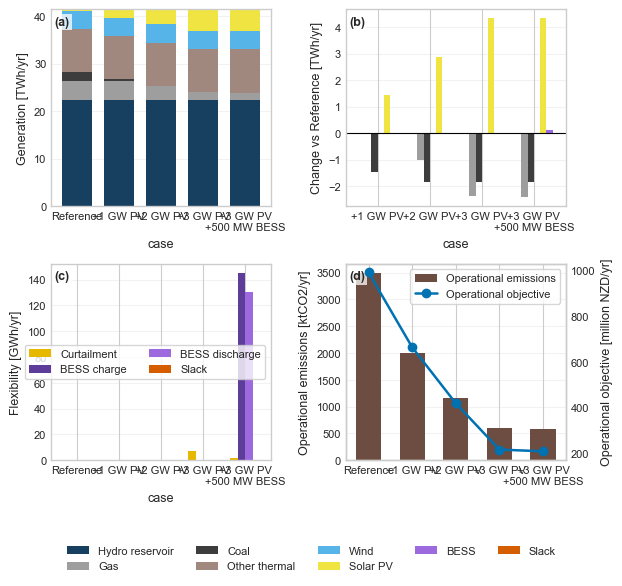

In [63]:
short_term_annual_summary, short_term_generation, short_term_carrier_detail = analyse_short_term_results(
    short_term_results
)
if not short_term_annual_summary.empty:
    display(round_numeric_frame(short_term_annual_summary, 3))
    short_term_overview_path = plot_short_term_overview(
        short_term_annual_summary, short_term_generation
    )


### 8.5 Critical-event and favourable-summer dispatch panels


Short-term cases available for dispatch plots: ['Reference', 'PV_1GW', 'PV_2GW', 'PV_3GW', 'PV_3GW_BESS']
Saved figure: output\output_new_zealand\figures\short_term\figure_short_term_dispatch_summer_week_2025.png


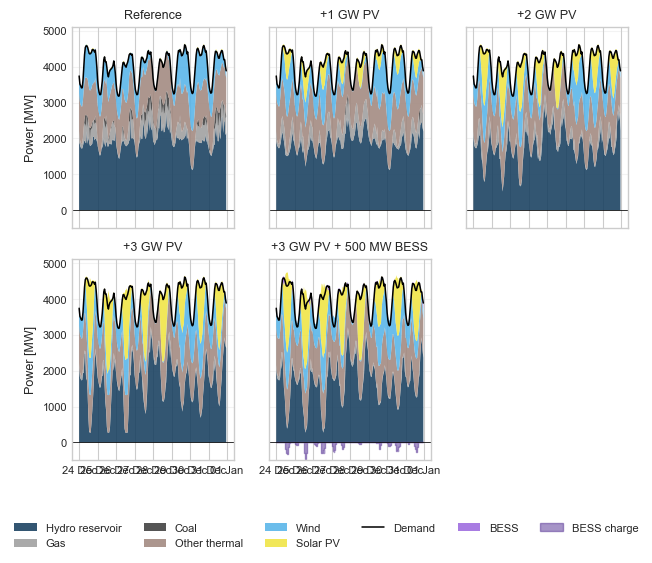

Saved dispatch figure: output\output_new_zealand\figures\short_term\figure_short_term_dispatch_summer_week_2025.png
Saved dispatch summary: output\output_new_zealand\tables\short_term\dispatch_windows_2025.csv


,period,case,case_label,start,end,demand_mwh,supply_hydro_reservoir_mwh,supply_gas_mwh,supply_coal_mwh,supply_other_thermal_mwh,supply_wind_mwh,supply_solar_pv_mwh,supply_bess_mwh,bess_charge_mwh
0,summer_week,Reference,Reference,2025-12-24,2025-12-31 23:00:00,768679.501,374228.768,63417.349,16817.565,201111.36,118416.956,2107.771,NaN,NaN
1,summer_week,PV_1GW,+1 GW PV,2025-12-24,2025-12-31 23:00:00,768679.501,357847.475,56968.138,1085.360,201111.36,118416.956,40477.620,NaN,NaN
2,summer_week,PV_2GW,+2 GW PV,2025-12-24,2025-12-31 23:00:00,768679.501,342678.072,35018.639,NaN,201111.36,118416.956,78847.469,NaN,NaN
3,summer_week,PV_3GW,+3 GW PV,2025-12-24,2025-12-31 23:00:00,768679.501,324242.506,17636.049,NaN,201111.36,118416.956,117217.318,NaN,NaN
4,summer_week,PV_3GW_BESS,+3 GW PV + 500 MW BESS,2025-12-24,2025-12-31 23:00:00,768679.501,324797.052,15759.211,NaN,201111.36,118416.956,117217.318,7432.493,8122.4


In [65]:
def _short_term_dispatch_window(
    network_path: Path,
    start,
    end,
) -> tuple[pd.DataFrame, pd.Series]:
    """Return national dispatch and weights for one window."""
    net = pypsa.Network(
        Path(network_path)
    )

    index = pd.DatetimeIndex(
        net.snapshots
    )

    if index.tz is not None:
        index = index.tz_localize(None)

    start_ts = pd.Timestamp(start)
    end_ts = pd.Timestamp(end)

    if start_ts.tzinfo is not None:
        start_ts = start_ts.tz_localize(
            None
        )

    if end_ts.tzinfo is not None:
        end_ts = end_ts.tz_localize(
            None
        )

    mask = (
        (index >= start_ts)
        & (index <= end_ts)
    )

    selected = net.snapshots[mask]

    if len(selected) == 0:
        raise ValueError(
            "No snapshots fall within "
            f"{start_ts} to {end_ts}."
        )

    frame = pd.DataFrame(
        index=pd.DatetimeIndex(
            index[mask]
        )
    )

    generator_dispatch = (
        net.generators_t.p.reindex(
            index=selected,
            columns=net.generators.index,
            fill_value=0.0,
        )
    )

    generator_dispatch.index = (
        frame.index
    )

    groups = (
        net.generators["carrier"]
        .map(short_term_technology_group)
    )

    for group in groups.dropna().unique():
        assets = groups.index[
            groups == group
        ]

        frame[group] = (
            generator_dispatch.reindex(
                columns=assets,
                fill_value=0.0,
            )
            .sum(axis=1)
        )

    if not net.storage_units.empty:
        storage_power = (
            net.storage_units_t.p.reindex(
                index=selected,
                columns=(
                    net.storage_units.index
                ),
                fill_value=0.0,
            )
        )

        storage_power.index = frame.index

        storage_groups = (
            net.storage_units["carrier"]
            .map(
                short_term_technology_group
            )
        )

        for group in (
            storage_groups
            .dropna()
            .unique()
        ):
            assets = storage_groups.index[
                storage_groups == group
            ]

            power = (
                storage_power.reindex(
                    columns=assets,
                    fill_value=0.0,
                )
                .sum(axis=1)
            )

            frame[group] = (
                frame.get(group, 0.0)
                + power.clip(lower=0.0)
            )

            if group == "BESS":
                frame["BESS charge"] = (
                    power.clip(upper=0.0)
                )

            elif (
                group == "Hydro reservoir"
                and power.min() < -1e-6
            ):
                frame["Hydro pumping"] = (
                    power.clip(upper=0.0)
                )

    load = (
        net.loads_t.p_set.reindex(
            index=selected,
            columns=net.loads.index,
            fill_value=0.0,
        )
        .sum(axis=1)
    )

    load.index = frame.index
    frame["Demand"] = load

    weights = (
        short_term_snapshot_weights(net)
        .reindex(selected)
        .fillna(1.0)
    )

    weights.index = frame.index

    del net
    gc.collect()

    return (
        frame.fillna(0.0),
        weights,
    )


def plot_short_term_dispatch_comparison(
    period_key: str,
    start,
    end,
) -> tuple[
    Path | None,
    pd.DataFrame,
]:
    """Compare available short-term cases on a shared scale."""
    frames = {}
    weights_by_case = {}

    case_order = [
        case_name
        for case_name
        in SHORT_TERM_RUN_CASES
        if case_name
        in SHORT_TERM_CASES
    ]

    for case_name in case_order:
        if case_name not in short_term_results:
            continue

        network_path = Path(
            short_term_results[
                case_name
            ]["network_netcdf"]
        )

        if not network_path.exists():
            print(
                "Missing short-term network: "
                f"{network_path}"
            )
            continue

        frame, weights = (
            _short_term_dispatch_window(
                network_path,
                start,
                end,
            )
        )

        frames[case_name] = frame
        weights_by_case[
            case_name
        ] = weights

    case_names = [
        case_name
        for case_name in case_order
        if case_name in frames
    ]

    if not case_names:
        print(
            "Short-term dispatch panel "
            f"'{period_key}' skipped: "
            "no case exports are available."
        )

        return None, pd.DataFrame()

    positive_order = [
        group
        for group
        in SHORT_TERM_STACK_ORDER
        if any(
            group in frame.columns
            for frame in frames.values()
        )
    ]

    positive_order.extend(
        group
        for frame in frames.values()
        for group in frame.columns
        if (
            group not in positive_order
            and group not in {
                "Demand",
                "BESS charge",
                "Hydro pumping",
            }
        )
    )

    positive_order = list(
        dict.fromkeys(positive_order)
    )

    max_positive = max(
        max(
            float(
                frame.reindex(
                    columns=positive_order,
                    fill_value=0.0,
                )
                .clip(lower=0.0)
                .sum(axis=1)
                .max()
            ),
            float(
                frame["Demand"].max()
            ),
        )
        for frame in frames.values()
    )

    min_negative = min(
        (
            float(
                frame[
                    [
                        column
                        for column in [
                            "BESS charge",
                            "Hydro pumping",
                        ]
                        if column
                        in frame.columns
                    ]
                ]
                .sum(axis=1)
                .min()
            )
            if any(
                column in frame.columns
                for column in [
                    "BESS charge",
                    "Hydro pumping",
                ]
            )
            else 0.0
        )
        for frame in frames.values()
    )

    ncols = 3

    nrows = int(
        np.ceil(
            len(case_names)
            / ncols
        )
    )

    fig, axes = plt.subplots(
        nrows,
        ncols,
        figsize=(
            WORD_DOUBLE_COL_IN,
            2.8 * nrows,
        ),
        sharex=True,
        sharey=True,
        squeeze=False,
    )

    axes = axes.flatten()
    summary_rows = []

    for ax, case_name in zip(
        axes,
        case_names,
    ):
        frame = frames[case_name]

        weights = weights_by_case[
            case_name
        ]

        groups = [
            group
            for group
            in positive_order
            if (
                group in frame.columns
                and frame[group].max()
                > 1e-6
            )
        ]

        if groups:
            ax.stackplot(
                frame.index,
                *[
                    frame[group]
                    .clip(lower=0.0)
                    .to_numpy()
                    for group in groups
                ],
                colors=[
                    SHORT_TERM_PLOT_COLORS.get(
                        group,
                        "#9E9E9E",
                    )
                    for group in groups
                ],
                labels=groups,
                alpha=0.88,
            )

        for column, color in [
            (
                "BESS charge",
                TECH_COLORS["bess_soc"],
            ),
            (
                "Hydro pumping",
                "#6BAED6",
            ),
        ]:
            if column in frame.columns:
                ax.fill_between(
                    frame.index,
                    0.0,
                    frame[column],
                    color=color,
                    alpha=0.55,
                    step="mid",
                    label=column,
                )

        ax.plot(
            frame.index,
            frame["Demand"],
            color="black",
            linewidth=1.1,
            label="Demand",
        )

        ax.axhline(
            0.0,
            color="black",
            linewidth=0.55,
        )

        ax.set_ylim(
            (
                min_negative * 1.08
                if min_negative < 0
                else 0.0
            ),
            (
                max_positive * 1.08
                if max_positive > 0
                else 1.0
            ),
        )

        ax.set_title(
            SHORT_TERM_CASES[
                case_name
            ]["label"],
            fontsize=FONT_SIZE_BASE,
        )

        ax.grid(
            True,
            axis="y",
            alpha=0.22,
        )

        span_hours = (
            frame.index.max()
            - frame.index.min()
        ).total_seconds() / 3600.0

        if span_hours <= 72:
            ax.xaxis.set_major_locator(
                mdates.HourLocator(
                    interval=12
                )
            )

            ax.xaxis.set_major_formatter(
                mdates.DateFormatter(
                    "%d %b\n%H:%M"
                )
            )

        elif span_hours <= 240:
            ax.xaxis.set_major_locator(
                mdates.DayLocator(
                    interval=1
                )
            )

            ax.xaxis.set_major_formatter(
                mdates.DateFormatter(
                    "%d %b"
                )
            )

        else:
            locator = (
                mdates.AutoDateLocator(
                    minticks=3,
                    maxticks=5,
                )
            )

            ax.xaxis.set_major_locator(
                locator
            )

            ax.xaxis.set_major_formatter(
                mdates.ConciseDateFormatter(
                    locator
                )
            )

        row = {
            "period": period_key,
            "case": case_name,
            "case_label": (
                SHORT_TERM_CASES[
                    case_name
                ]["label"]
            ),
            "start": pd.Timestamp(start),
            "end": pd.Timestamp(end),
            "demand_mwh": float(
                frame["Demand"]
                .multiply(weights)
                .sum()
            ),
        }

        for group in groups:
            row[
                "supply_"
                f"{_norm_carrier(group)}"
                "_mwh"
            ] = float(
                frame[group]
                .multiply(weights)
                .sum()
            )

        if "BESS charge" in frame.columns:
            row["bess_charge_mwh"] = float(
                (
                    -frame["BESS charge"]
                )
                .multiply(weights)
                .sum()
            )

        summary_rows.append(row)

    for ax in axes[
        len(case_names):
    ]:
        ax.set_visible(False)

    for ax in axes:
        if (
            ax.get_visible()
            and ax.get_subplotspec()
            .is_first_col()
        ):
            ax.set_ylabel(
                "Power [MW]"
            )

    legend_items = {}

    for ax in axes:
        if not ax.get_visible():
            continue

        handles, labels = (
            ax.get_legend_handles_labels()
        )

        for handle, label in zip(
            handles,
            labels,
        ):
            if (
                label
                and label
                not in legend_items
            ):
                legend_items[label] = (
                    handle
                )

    if legend_items:
        fig.legend(
            list(
                legend_items.values()
            ),
            list(
                legend_items.keys()
            ),
            loc="lower center",
            bbox_to_anchor=(
                0.5,
                -0.005,
            ),
            ncol=min(
                6,
                len(legend_items),
            ),
            frameon=False,
        )

    fig.tight_layout(
        rect=[
            0,
            0.12,
            1,
            1,
        ]
    )

    path = save_paper_figure(
        fig,
        (
            "figure_short_term_dispatch_"
            f"{period_key}_"
            f"{SHORT_TERM_YEAR}.png"
        ),
        folder=SHORT_TERM_FIGURE_DIR,
    )

    plt.show()

    return (
        path,
        pd.DataFrame(summary_rows),
    )


def _same_calendar_window(
    start,
    end,
    target_year: int,
):
    """Map an analysis window to another model year."""
    start_ts = pd.Timestamp(start)
    end_ts = pd.Timestamp(end)

    if start_ts.tzinfo is not None:
        start_ts = start_ts.tz_localize(
            None
        )

    if end_ts.tzinfo is not None:
        end_ts = end_ts.tz_localize(
            None
        )

    def _replace_year(ts, year):
        try:
            return ts.replace(
                year=int(year)
            )

        except ValueError:
            return ts.replace(
                year=int(year),
                day=28,
            )

    mapped_start = _replace_year(
        start_ts,
        target_year,
    )

    mapped_end = _replace_year(
        end_ts,
        target_year,
    )

    if mapped_end < mapped_start:
        mapped_end = _replace_year(
            end_ts,
            target_year + 1,
        )

    return (
        mapped_start,
        mapped_end,
    )


if (
    "short_term_results"
    not in globals()
    or not short_term_results
):
    short_term_results = (
        load_short_term_catalogue()
    )


if not short_term_results:
    raise FileNotFoundError(
        "No short-term exports were found. "
        "Run Section 8.2 first."
    )


print(
    "Short-term cases available "
    "for dispatch plots:",
    [
        case_name
        for case_name
        in SHORT_TERM_RUN_CASES
        if case_name
        in short_term_results
    ],
)


short_term_periods = []


if (
    "critical_event_start"
    in globals()
    and "critical_event_end"
    in globals()
):
    start, end = (
        _same_calendar_window(
            critical_event_start,
            critical_event_end,
            SHORT_TERM_YEAR,
        )
    )

    short_term_periods.append(
        (
            "critical_event",
            start,
            end,
        )
    )


summer_week_added = False


if "period_definitions" in globals():
    for period in period_definitions:
        if (
            period.get("key")
            == "summer_week"
        ):
            start, end = (
                _same_calendar_window(
                    period["start"],
                    period["end"],
                    SHORT_TERM_YEAR,
                )
            )

            short_term_periods.append(
                (
                    "summer_week",
                    start,
                    end,
                )
            )

            summer_week_added = True
            break


if not summer_week_added:
    short_term_periods.append(
        (
            "summer_week",
            pd.Timestamp(
                f"{SHORT_TERM_YEAR}"
                "-12-24 00:00"
            ),
            pd.Timestamp(
                f"{SHORT_TERM_YEAR}"
                "-12-31 23:00"
            ),
        )
    )


dispatch_window_summaries = []
seen_periods = set()


for (
    period_key,
    period_start,
    period_end,
) in short_term_periods:
    if period_key in seen_periods:
        continue

    seen_periods.add(period_key)

    try:
        (
            figure_path,
            period_summary,
        ) = (
            plot_short_term_dispatch_comparison(
                period_key,
                period_start,
                period_end,
            )
        )

    except ValueError as exc:
        print(
            "Short-term dispatch "
            f"'{period_key}' skipped: "
            f"{exc}"
        )

        continue

    if figure_path is not None:
        print(
            "Saved dispatch figure: "
            f"{figure_path}"
        )

    if not period_summary.empty:
        dispatch_window_summaries.append(
            period_summary
        )


short_term_dispatch_summary = (
    pd.concat(
        dispatch_window_summaries,
        ignore_index=True,
    )
    if dispatch_window_summaries
    else pd.DataFrame()
)


if not short_term_dispatch_summary.empty:
    summary_path = (
        SHORT_TERM_TABLE_DIR
        / (
            "dispatch_windows_"
            f"{SHORT_TERM_YEAR}.csv"
        )
    )

    short_term_dispatch_summary.to_csv(
        summary_path,
        index=False,
    )

    print(
        "Saved dispatch summary: "
        f"{summary_path}"
    )

    display(
        round_numeric_frame(
            short_term_dispatch_summary,
            3,
        )
    )

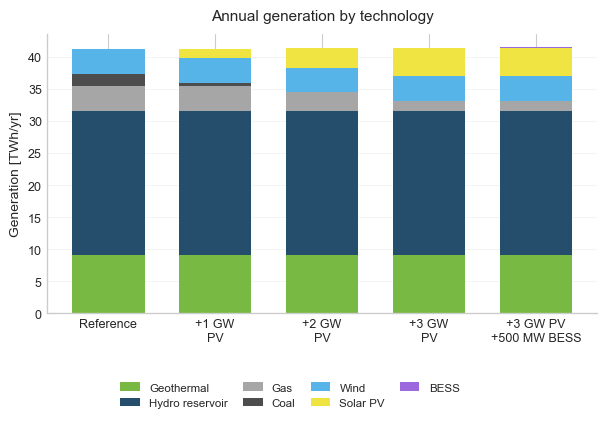

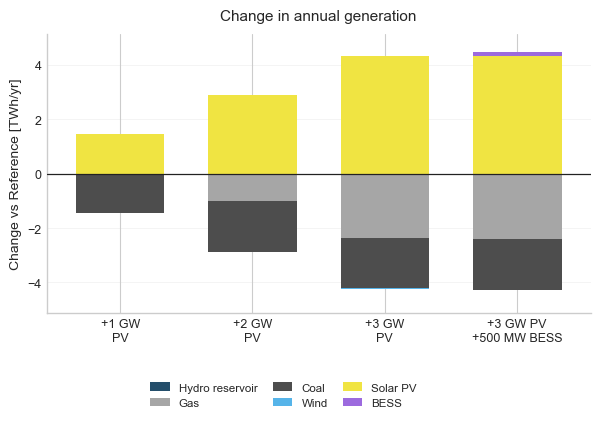

C:\Users\vse23\AppData\Local\Temp\ipykernel_69844\1629181647.py:677: UserWarning:

Glyph 8322 (\N{SUBSCRIPT TWO}) missing from font(s) Arial.

c:\Users\vse23\AppData\Local\anaconda3\envs\pypsa-isolated\Lib\site-packages\IPython\core\pylabtools.py:170: UserWarning:

Glyph 8322 (\N{SUBSCRIPT TWO}) missing from font(s) Arial.



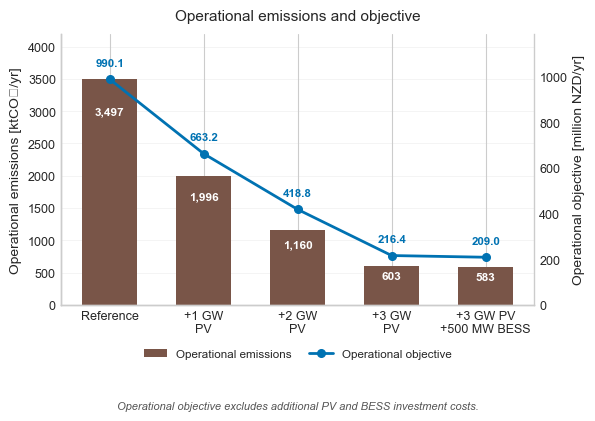

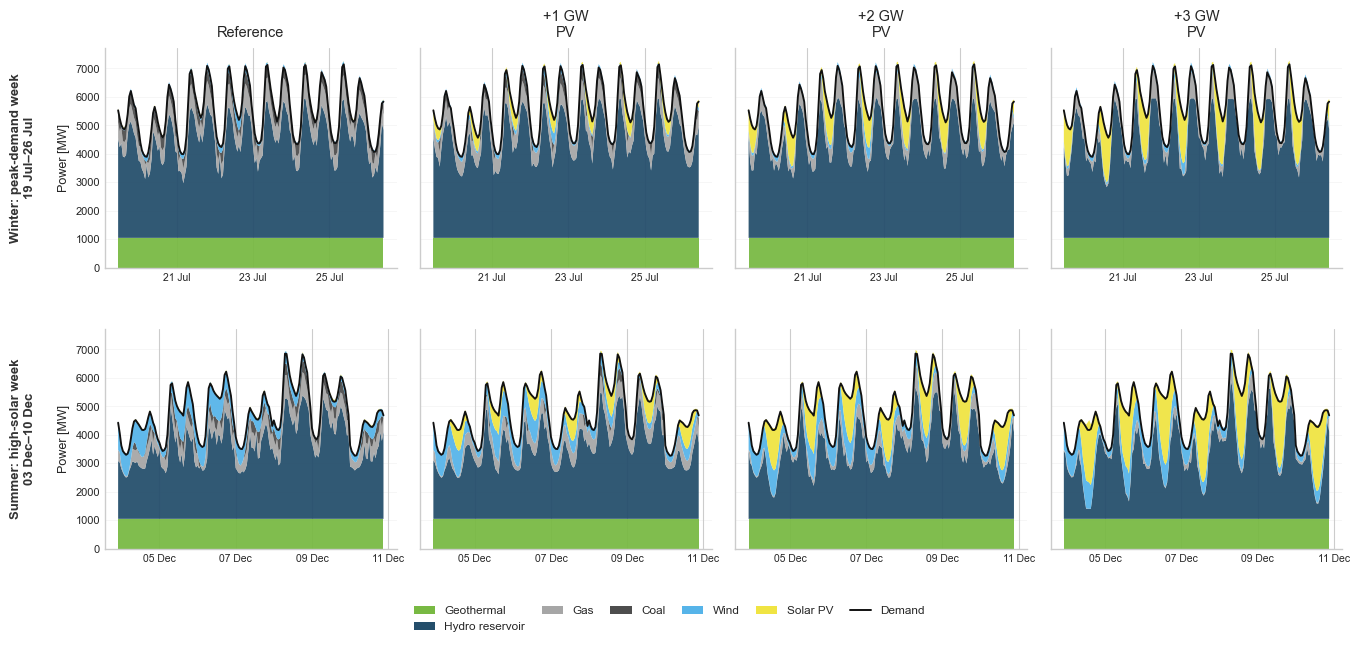

Selected winter week: 19 Jul 2025 to 26 Jul 2025
Selected summer week: 03 Dec 2025 to 10 Dec 2025

Presentation figures created:
  Annual generation: output\output_new_zealand\figures\short_term\figure_annual_generation_by_scenario_2025.png
  Generation change: output\output_new_zealand\figures\short_term\figure_annual_generation_change_2025.png
  Emissions and objective: output\output_new_zealand\figures\short_term\figure_annual_emissions_objective_2025.png
  Winter/summer dispatch: output\output_new_zealand\figures\short_term\figure_seasonal_dispatch_2x4_2025.png


In [ ]:
# ============================================================
# Short-term presentation figures
#
# Outputs:
#   1. Annual generation by technology and scenario.
#   2. Change in annual generation relative to Reference.
#   3. Operational emissions and objective.
#   4. Seasonal hourly dispatch: winter/summer x four PV cases.
# ============================================================

from pathlib import Path
import gc

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

from matplotlib.patches import Patch
from matplotlib.lines import Line2D


# ------------------------------------------------------------
# Configuration
# ------------------------------------------------------------

PRESENTATION_CASES = [
    "Reference",
    "PV_1GW",
    "PV_2GW",
    "PV_3GW",
    "PV_3GW_BESS",
]

PRESENTATION_DISPATCH_CASES = [
    "Reference",
    "PV_1GW",
    "PV_2GW",
    "PV_3GW",
]

PRESENTATION_CASE_LABELS = {
    "Reference": "Reference",
    "PV_1GW": "+1 GW\nPV",
    "PV_2GW": "+2 GW\nPV",
    "PV_3GW": "+3 GW\nPV",
    "PV_3GW_BESS": "+3 GW PV\n+500 MW BESS",
}

PRESENTATION_STACK_ORDER = [
    "Geothermal",
    "Hydro reservoir",
    "Hydro run-of-river",
    "Gas",
    "Coal",
    "Other thermal",
    "Wind",
    "Solar PV",
    "BESS",
    "Hydrogen",
    "Slack",
    "Other",
]

PRESENTATION_COLORS = {
    "Geothermal": "#78B943",
    "Hydro reservoir": "#244E6B",
    "Hydro run-of-river": "#3E708E",
    "Gas": "#A6A6A6",
    "Coal": "#4D4D4D",
    "Other thermal": "#A88F86",
    "Wind": "#56B4E9",
    "Solar PV": "#F0E442",
    "BESS": "#9C6ADE",
    "Hydrogen": "#00A6A6",
    "Slack": "#D55E00",
    "Other": "#C7C7C7",
    "Demand": "#111111",
    "Emissions": "#795548",
    "Objective": "#0072B2",
}

SHORT_TERM_FIGURE_DIR.mkdir(
    parents=True,
    exist_ok=True,
)


# ------------------------------------------------------------
# Correct technology classification
# ------------------------------------------------------------

def short_term_technology_group(value) -> str:
    """Map carriers to short-term presentation groups."""
    carrier = _norm_carrier(value)

    if carrier.startswith("geo") or "geothermal" in carrier:
        return "Geothermal"

    if "coal" in carrier:
        return "Coal"

    gas_tokens = (
        "ccgt",
        "ocgt",
        "gas",
        "peaker",
        "cogeneration",
        "reciprocating",
    )

    if any(token in carrier for token in gas_tokens):
        return "Gas"

    other_thermal_tokens = (
        "diesel",
        "oil",
        "thermal",
        "bio_",
        "biomass",
        "waste",
    )

    if any(token in carrier for token in other_thermal_tokens):
        return "Other thermal"

    return clean_technology_group(value)


# Recalculate summaries from solved NetCDF files.
# No optimisation is rerun.
short_term_annual_summary, short_term_generation, short_term_carrier_detail = (
    analyse_short_term_results(short_term_results)
)


# ------------------------------------------------------------
# Prepare annual tables
# ------------------------------------------------------------

annual_case_order = [
    case
    for case in PRESENTATION_CASES
    if (
        case in set(short_term_annual_summary["case"])
        and case in set(short_term_generation["case"])
    )
]

annual_case_labels = [
    PRESENTATION_CASE_LABELS.get(case, case)
    for case in annual_case_order
]

annual_summary_indexed = (
    short_term_annual_summary
    .drop_duplicates(subset="case", keep="last")
    .set_index("case")
    .reindex(annual_case_order)
)

annual_generation_pivot = (
    short_term_generation
    .pivot_table(
        index="case",
        columns="technology",
        values="generation_mwh",
        aggfunc="sum",
        fill_value=0.0,
    )
    .reindex(annual_case_order)
    .fillna(0.0)
    / 1e6
)

annual_technology_order = [
    technology
    for technology in PRESENTATION_STACK_ORDER
    if (
        technology in annual_generation_pivot.columns
        and float(
            annual_generation_pivot[technology].abs().max()
        ) > 1e-6
    )
]

annual_technology_order += [
    technology
    for technology in annual_generation_pivot.columns
    if (
        technology not in annual_technology_order
        and float(
            annual_generation_pivot[technology].abs().max()
        ) > 1e-6
    )
]

annual_generation_pivot = annual_generation_pivot.reindex(
    columns=annual_technology_order,
    fill_value=0.0,
)


# ------------------------------------------------------------
# Shared annual-figure formatting
# ------------------------------------------------------------

def _format_annual_axis(
    ax,
    ylabel: str,
) -> None:
    ax.set_xlabel("")
    ax.set_ylabel(ylabel, fontsize=10)

    ax.tick_params(
        axis="both",
        labelsize=9,
    )

    ax.grid(
        axis="y",
        alpha=0.22,
        linewidth=0.7,
    )

    ax.set_axisbelow(True)

    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)


# ------------------------------------------------------------
# Figure 1: annual generation by technology and scenario
# ------------------------------------------------------------

def plot_annual_generation_by_scenario() -> Path:
    x = np.arange(len(annual_case_order))
    bottom = np.zeros(len(annual_case_order))

    fig, ax = plt.subplots(
        figsize=(6.4, 4.3),
    )

    for technology in annual_technology_order:
        values = annual_generation_pivot[
            technology
        ].to_numpy(dtype=float)

        ax.bar(
            x,
            values,
            bottom=bottom,
            width=0.68,
            color=PRESENTATION_COLORS.get(
                technology,
                "#BDBDBD",
            ),
            edgecolor="none",
            label=technology,
        )

        bottom += values

    ax.set_xticks(x)
    ax.set_xticklabels(
        annual_case_labels,
        rotation=0,
        ha="center",
    )

    ax.set_title(
        "Annual generation by technology",
        fontsize=11,
        pad=10,
    )

    ax.margins(x=0.05)

    _format_annual_axis(
        ax,
        ylabel="Generation [TWh/yr]",
    )

    legend_handles = [
        Patch(
            facecolor=PRESENTATION_COLORS.get(
                technology,
                "#BDBDBD",
            ),
            edgecolor="none",
            label=technology,
        )
        for technology in annual_technology_order
    ]

    fig.legend(
        handles=legend_handles,
        loc="lower center",
        bbox_to_anchor=(0.5, 0.005),
        ncol=min(4, len(legend_handles)),
        fontsize=8.3,
        frameon=False,
        columnspacing=1.3,
        handlelength=1.7,
    )

    fig.subplots_adjust(
        left=0.12,
        right=0.98,
        top=0.90,
        bottom=0.25,
    )

    output_path = (
        SHORT_TERM_FIGURE_DIR
        / f"figure_annual_generation_by_scenario_{SHORT_TERM_YEAR}.png"
    )

    fig.savefig(
        output_path,
        dpi=300,
        bbox_inches="tight",
        facecolor="white",
    )

    plt.show()

    return output_path


# ------------------------------------------------------------
# Figure 2: change in annual generation
# ------------------------------------------------------------

def plot_annual_generation_change() -> Path:
    if "Reference" not in annual_generation_pivot.index:
        raise ValueError(
            "Reference is required for the generation-change figure."
        )

    delta = annual_generation_pivot.subtract(
        annual_generation_pivot.loc["Reference"],
        axis=1,
    )

    delta = delta.drop(
        index="Reference",
        errors="ignore",
    )

    delta = delta.loc[
        :,
        delta.abs().max(axis=0) > 0.001,
    ]

    delta_case_order = [
        case
        for case in annual_case_order
        if case != "Reference"
        and case in delta.index
    ]

    delta = delta.reindex(delta_case_order)

    plotted_technologies = [
        technology
        for technology in annual_technology_order
        if technology in delta.columns
    ]

    x = np.arange(len(delta_case_order))

    positive_bottom = np.zeros(len(delta_case_order))
    negative_bottom = np.zeros(len(delta_case_order))

    fig, ax = plt.subplots(
        figsize=(6.4, 4.3),
    )

    for technology in plotted_technologies:
        values = delta[
            technology
        ].to_numpy(dtype=float)

        bar_bottom = np.where(
            values >= 0.0,
            positive_bottom,
            negative_bottom,
        )

        ax.bar(
            x,
            values,
            bottom=bar_bottom,
            width=0.67,
            color=PRESENTATION_COLORS.get(
                technology,
                "#BDBDBD",
            ),
            edgecolor="none",
            label=technology,
        )

        positive_bottom += np.where(
            values > 0.0,
            values,
            0.0,
        )

        negative_bottom += np.where(
            values < 0.0,
            values,
            0.0,
        )

    ax.axhline(
        0.0,
        color="#222222",
        linewidth=0.9,
        zorder=5,
    )

    ax.set_xticks(x)

    ax.set_xticklabels(
        [
            PRESENTATION_CASE_LABELS.get(case, case)
            for case in delta_case_order
        ],
        rotation=0,
        ha="center",
    )

    maximum_extent = max(
        float(positive_bottom.max()),
        abs(float(negative_bottom.min())),
    )

    ax.set_ylim(
        -maximum_extent * 1.15,
        maximum_extent * 1.15,
    )

    ax.set_title(
        "Change in annual generation",
        fontsize=11,
        pad=10,
    )

    ax.margins(x=0.06)

    _format_annual_axis(
        ax,
        ylabel="Change vs Reference [TWh/yr]",
    )

    legend_handles = [
        Patch(
            facecolor=PRESENTATION_COLORS.get(
                technology,
                "#BDBDBD",
            ),
            edgecolor="none",
            label=technology,
        )
        for technology in plotted_technologies
    ]

    fig.legend(
        handles=legend_handles,
        loc="lower center",
        bbox_to_anchor=(0.5, 0.005),
        ncol=min(3, len(legend_handles)),
        fontsize=8.3,
        frameon=False,
        columnspacing=1.3,
        handlelength=1.7,
    )

    fig.subplots_adjust(
        left=0.13,
        right=0.98,
        top=0.90,
        bottom=0.25,
    )

    output_path = (
        SHORT_TERM_FIGURE_DIR
        / f"figure_annual_generation_change_{SHORT_TERM_YEAR}.png"
    )

    fig.savefig(
        output_path,
        dpi=300,
        bbox_inches="tight",
        facecolor="white",
    )

    plt.show()

    return output_path


# ------------------------------------------------------------
# Figure 3: operational emissions and objective
# ------------------------------------------------------------

def plot_annual_emissions_and_objective() -> Path:
    x = np.arange(len(annual_case_order))

    emissions = (
        pd.to_numeric(
            annual_summary_indexed["co2_tons"],
            errors="coerce",
        )
        .fillna(0.0)
        .to_numpy(dtype=float)
        / 1e3
    )

    objective = (
        pd.to_numeric(
            annual_summary_indexed["objective_usd"],
            errors="coerce",
        )
        .to_numpy(dtype=float)
        / 1e6
    )

    fig, ax = plt.subplots(
        figsize=(6.4, 4.3),
    )

    emission_bars = ax.bar(
        x,
        emissions,
        width=0.58,
        color=PRESENTATION_COLORS["Emissions"],
        edgecolor="none",
        label="Operational emissions",
        zorder=2,
    )

    ax.set_xticks(x)

    ax.set_xticklabels(
        annual_case_labels,
        rotation=0,
        ha="center",
    )

    ax.set_ylim(
        0.0,
        float(np.nanmax(emissions)) * 1.20,
    )

    ax.set_title(
        "Operational emissions and objective",
        fontsize=11,
        pad=10,
    )

    ax.margins(x=0.06)

    _format_annual_axis(
        ax,
        ylabel="Operational emissions [ktCO₂/yr]",
    )

    objective_ax = ax.twinx()

    objective_line = objective_ax.plot(
        x,
        objective,
        color=PRESENTATION_COLORS["Objective"],
        marker="o",
        markersize=5.5,
        linewidth=2.0,
        label="Operational objective",
        zorder=5,
    )[0]

    objective_ax.set_ylim(
        0.0,
        float(np.nanmax(objective)) * 1.20,
    )

    objective_ax.set_ylabel(
        "Operational objective [million NZD/yr]",
        fontsize=10,
    )

    objective_ax.tick_params(
        axis="y",
        labelsize=9,
    )

    objective_ax.grid(False)
    objective_ax.spines["top"].set_visible(False)

    # Emissions labels are placed inside the bars to avoid
    # overlapping the objective values.
    for bar, value in zip(
        emission_bars,
        emissions,
    ):
        ax.annotate(
            f"{value:,.0f}",
            xy=(
                bar.get_x() + bar.get_width() / 2,
                bar.get_height() * 0.88,
            ),
            ha="center",
            va="top",
            fontsize=8.5,
            color="white",
            fontweight="bold",
        )

    # Objective labels.
    for position, value in zip(
        x,
        objective,
    ):
        objective_ax.annotate(
            f"{value:,.1f}",
            xy=(position, value),
            xytext=(0, 8),
            textcoords="offset points",
            ha="center",
            va="bottom",
            fontsize=8.3,
            color=PRESENTATION_COLORS["Objective"],
            fontweight="bold",
        )

    fig.legend(
        handles=[
            emission_bars,
            objective_line,
        ],
        labels=[
            "Operational emissions",
            "Operational objective",
        ],
        loc="lower center",
        bbox_to_anchor=(0.5, 0.12),
        ncol=2,
        fontsize=8.4,
        frameon=False,
        columnspacing=1.5,
    )

    fig.text(
        0.5,
        0.035,
        "Operational objective excludes additional PV and BESS investment costs.",
        ha="center",
        va="center",
        fontsize=8.0,
        color="#555555",
        style="italic",
    )

    fig.subplots_adjust(
        left=0.13,
        right=0.87,
        top=0.90,
        bottom=0.27,
    )

    output_path = (
        SHORT_TERM_FIGURE_DIR
        / f"figure_annual_emissions_objective_{SHORT_TERM_YEAR}.png"
    )

    fig.savefig(
        output_path,
        dpi=300,
        bbox_inches="tight",
        facecolor="white",
    )

    plt.show()

    return output_path


# ------------------------------------------------------------
# Load full-year hourly dispatch for seasonal comparison
# ------------------------------------------------------------

def _load_short_term_hourly_dispatch(
    network_path: Path,
) -> pd.DataFrame:
    """Return national hourly dispatch from one solved network."""
    net = pypsa.Network(Path(network_path))

    original_snapshots = net.snapshots
    datetime_index = pd.DatetimeIndex(original_snapshots)

    if datetime_index.tz is not None:
        datetime_index = datetime_index.tz_localize(None)

    frame = pd.DataFrame(index=datetime_index)

    generators = net.generators.copy()

    generator_dispatch = net.generators_t.p.reindex(
        index=original_snapshots,
        columns=generators.index,
        fill_value=0.0,
    )

    generator_dispatch.index = datetime_index

    generator_groups = generators["carrier"].map(
        short_term_technology_group
    )

    for technology in generator_groups.dropna().unique():
        assets = generator_groups.index[
            generator_groups == technology
        ]

        frame[technology] = (
            generator_dispatch.reindex(
                columns=assets,
                fill_value=0.0,
            )
            .sum(axis=1)
            .clip(lower=0.0)
        )

    if not net.storage_units.empty:
        storage_units = net.storage_units.copy()

        storage_power = net.storage_units_t.p.reindex(
            index=original_snapshots,
            columns=storage_units.index,
            fill_value=0.0,
        )

        storage_power.index = datetime_index

        storage_groups = storage_units["carrier"].map(
            short_term_technology_group
        )

        for technology in storage_groups.dropna().unique():
            assets = storage_groups.index[
                storage_groups == technology
            ]

            power = storage_power.reindex(
                columns=assets,
                fill_value=0.0,
            ).sum(axis=1)

            positive_supply = power.clip(lower=0.0)

            if technology in frame.columns:
                frame[technology] = (
                    frame[technology] + positive_supply
                )
            else:
                frame[technology] = positive_supply

    demand = net.loads_t.p_set.reindex(
        index=original_snapshots,
        columns=net.loads.index,
        fill_value=0.0,
    ).sum(axis=1)

    demand.index = datetime_index
    frame["Demand"] = demand

    del net
    gc.collect()

    return frame.fillna(0.0)


def _best_complete_week(
    series: pd.Series,
    allowed_months: set[int],
) -> tuple[pd.Timestamp, pd.Timestamp]:
    """Select the highest-energy complete 168-hour window."""
    series = series.sort_index().astype(float)

    rolling_energy = series.rolling(
        window=168,
        min_periods=168,
    ).sum()

    candidates = []

    for position in range(
        167,
        len(rolling_energy),
    ):
        end = rolling_energy.index[position]
        start = rolling_energy.index[position - 167]

        if (
            start.month in allowed_months
            and end.month in allowed_months
            and pd.notna(rolling_energy.iloc[position])
        ):
            candidates.append(
                (
                    float(rolling_energy.iloc[position]),
                    start,
                    end,
                )
            )

    if not candidates:
        raise ValueError(
            "No complete seven-day window was found."
        )

    _, start, end = max(
        candidates,
        key=lambda item: item[0],
    )

    return pd.Timestamp(start), pd.Timestamp(end)


# ------------------------------------------------------------
# Figure 4: winter/summer hourly dispatch, 2 x 4
# ------------------------------------------------------------

def plot_seasonal_dispatch_comparison(
    catalogue: dict,
) -> Path:
    """
    Compare Reference and 1–3 GW PV during:
      - the highest-demand winter week;
      - the highest-solar summer week.
    """
    dispatch_by_case = {}

    for case_name in PRESENTATION_DISPATCH_CASES:
        if case_name not in catalogue:
            print(
                f"Dispatch case unavailable: {case_name}"
            )
            continue

        dispatch_by_case[case_name] = (
            _load_short_term_hourly_dispatch(
                Path(catalogue[case_name]["network_netcdf"])
            )
        )

    missing_cases = [
        case
        for case in PRESENTATION_DISPATCH_CASES
        if case not in dispatch_by_case
    ]

    if missing_cases:
        raise ValueError(
            f"Missing dispatch cases: {missing_cases}"
        )

    reference_dispatch = dispatch_by_case["Reference"]
    pv_3gw_dispatch = dispatch_by_case["PV_3GW"]

    winter_start, winter_end = _best_complete_week(
        reference_dispatch["Demand"],
        allowed_months={6, 7, 8},
    )

    if "Solar PV" not in pv_3gw_dispatch.columns:
        raise ValueError(
            "Solar PV dispatch is unavailable in the PV_3GW case."
        )

    summer_start, summer_end = _best_complete_week(
        pv_3gw_dispatch["Solar PV"],
        allowed_months={1, 2, 12},
    )

    periods = [
        (
            "Winter: peak-demand week",
            winter_start,
            winter_end,
        ),
        (
            "Summer: high-solar week",
            summer_start,
            summer_end,
        ),
    ]

    period_frames = {}

    for row_index, (_, start, end) in enumerate(periods):
        for case_name in PRESENTATION_DISPATCH_CASES:
            frame = dispatch_by_case[case_name]

            period_frames[
                (row_index, case_name)
            ] = frame.loc[
                (frame.index >= start)
                & (frame.index <= end)
            ].copy()

    active_technologies = [
        technology
        for technology in PRESENTATION_STACK_ORDER
        if any(
            technology in frame.columns
            and float(frame[technology].max()) > 1e-6
            for frame in period_frames.values()
        )
    ]

    maximum_power = max(
        max(
            float(
                frame.reindex(
                    columns=active_technologies,
                    fill_value=0.0,
                )
                .clip(lower=0.0)
                .sum(axis=1)
                .max()
            ),
            float(frame["Demand"].max()),
        )
        for frame in period_frames.values()
    )

    fig, axes = plt.subplots(
        2,
        4,
        figsize=(13.6, 6.5),
        sharey=True,
    )

    fig.patch.set_facecolor("white")

    for row_index, (
        period_name,
        period_start,
        period_end,
    ) in enumerate(periods):

        for column_index, case_name in enumerate(
            PRESENTATION_DISPATCH_CASES
        ):
            ax = axes[row_index, column_index]

            frame = period_frames[
                (row_index, case_name)
            ]

            technologies = [
                technology
                for technology in active_technologies
                if (
                    technology in frame.columns
                    and float(frame[technology].max()) > 1e-6
                )
            ]

            if technologies:
                ax.stackplot(
                    frame.index,
                    *[
                        frame[technology]
                        .clip(lower=0.0)
                        .to_numpy()
                        for technology in technologies
                    ],
                    colors=[
                        PRESENTATION_COLORS.get(
                            technology,
                            "#BDBDBD",
                        )
                        for technology in technologies
                    ],
                    labels=technologies,
                    alpha=0.94,
                    linewidth=0.0,
                )

            ax.plot(
                frame.index,
                frame["Demand"],
                color=PRESENTATION_COLORS["Demand"],
                linewidth=1.35,
                label="Demand",
                zorder=10,
            )

            ax.set_ylim(
                0.0,
                maximum_power * 1.06,
            )

            ax.grid(
                axis="y",
                alpha=0.20,
                linewidth=0.6,
            )

            ax.set_axisbelow(True)

            ax.spines["top"].set_visible(False)
            ax.spines["right"].set_visible(False)

            ax.tick_params(
                axis="y",
                labelsize=8,
            )

            ax.xaxis.set_major_locator(
                mdates.DayLocator(interval=2)
            )

            ax.xaxis.set_major_formatter(
                mdates.DateFormatter("%d %b")
            )

            ax.tick_params(
                axis="x",
                labelsize=7.5,
                rotation=0,
            )

            if row_index == 0:
                ax.set_title(
                    PRESENTATION_CASE_LABELS.get(
                        case_name,
                        case_name,
                    ),
                    fontsize=10.5,
                    pad=8,
                )

            if column_index == 0:
                ax.set_ylabel(
                    "Power [MW]",
                    fontsize=9,
                )

        row_label = (
            f"{period_name}\n"
            f"{period_start:%d %b}–{period_end:%d %b}"
        )

        axes[row_index, 0].text(
            -0.28,
            0.50,
            row_label,
            transform=axes[row_index, 0].transAxes,
            ha="center",
            va="center",
            rotation=90,
            fontsize=9.5,
            fontweight="bold",
            color="#333333",
        )

    legend_handles = [
        Patch(
            facecolor=PRESENTATION_COLORS.get(
                technology,
                "#BDBDBD",
            ),
            edgecolor="none",
            label=technology,
        )
        for technology in active_technologies
    ]

    legend_handles.append(
        Line2D(
            [0],
            [0],
            color=PRESENTATION_COLORS["Demand"],
            linewidth=1.4,
            label="Demand",
        )
    )

    fig.legend(
        handles=legend_handles,
        loc="lower center",
        bbox_to_anchor=(0.5, 0.005),
        ncol=min(6, len(legend_handles)),
        fontsize=8.5,
        frameon=False,
        columnspacing=1.4,
        handlelength=1.8,
    )

    fig.subplots_adjust(
        left=0.085,
        right=0.995,
        top=0.92,
        bottom=0.15,
        wspace=0.08,
        hspace=0.28,
    )

    output_path = (
        SHORT_TERM_FIGURE_DIR
        / f"figure_seasonal_dispatch_2x4_{SHORT_TERM_YEAR}.png"
    )

    fig.savefig(
        output_path,
        dpi=300,
        bbox_inches="tight",
        facecolor="white",
    )

    plt.show()

    print(
        "Selected winter week:",
        f"{winter_start:%d %b %Y} to {winter_end:%d %b %Y}",
    )

    print(
        "Selected summer week:",
        f"{summer_start:%d %b %Y} to {summer_end:%d %b %Y}",
    )

    return output_path


# ------------------------------------------------------------
# Generate figures
# ------------------------------------------------------------

annual_generation_figure_path = (
    plot_annual_generation_by_scenario()
)

annual_generation_change_figure_path = (
    plot_annual_generation_change()
)

annual_emissions_objective_figure_path = (
    plot_annual_emissions_and_objective()
)

seasonal_dispatch_figure_path = (
    plot_seasonal_dispatch_comparison(
        short_term_results
    )
)

print("\nPresentation figures created:")

print(
    "  Annual generation:",
    annual_generation_figure_path,
)

print(
    "  Generation change:",
    annual_generation_change_figure_path,
)

print(
    "  Emissions and objective:",
    annual_emissions_objective_figure_path,
)

print(
    "  Winter/summer dispatch:",
    seasonal_dispatch_figure_path,
)

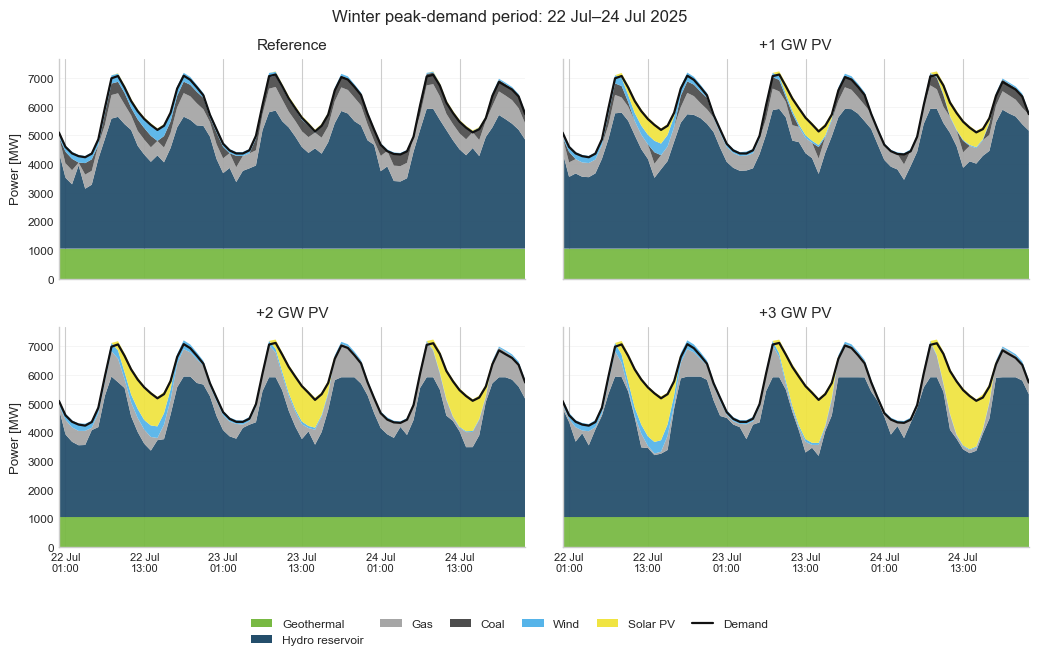

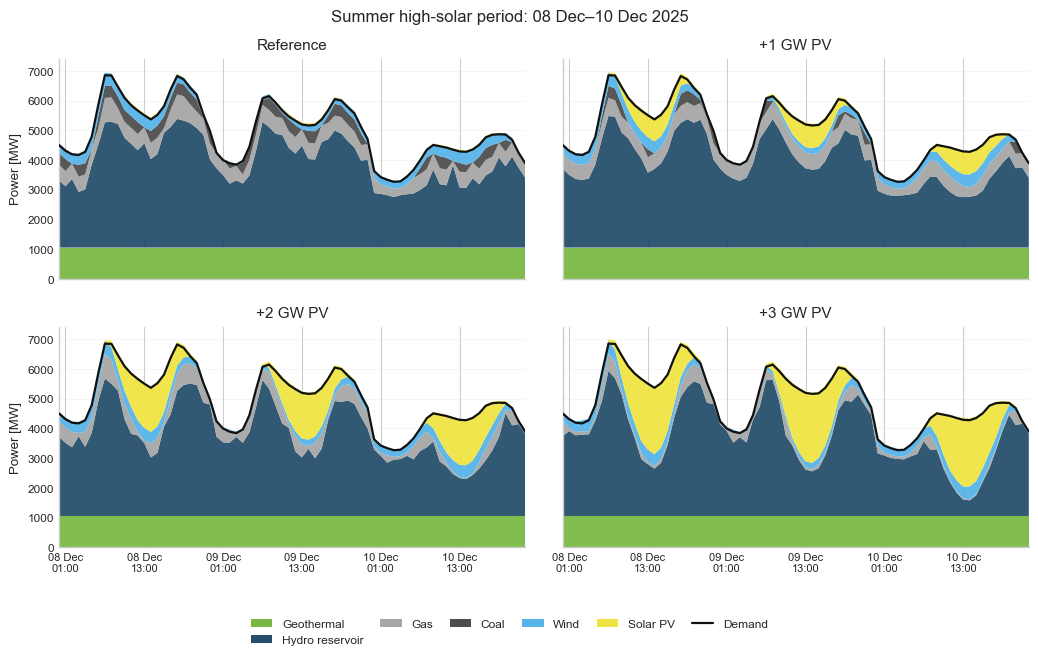


Seasonal dispatch figures created:
  Winter: output\output_new_zealand\figures\short_term\figure_dispatch_winter_72h_2025.png
  Summer: output\output_new_zealand\figures\short_term\figure_dispatch_summer_72h_2025.png

Selected winter period: 22 Jul 2025 00:00 to 24 Jul 2025 23:00
Selected summer period: 08 Dec 2025 00:00 to 10 Dec 2025 23:00


In [71]:
# ============================================================
# Seasonal 72-hour dispatch figures
#
# Creates two separate 2x2 figures:
#   1. Winter: highest-demand three-day period.
#   2. Summer: highest-solar three-day period.
# ============================================================

from pathlib import Path
import gc

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

from matplotlib.patches import Patch
from matplotlib.lines import Line2D


# ------------------------------------------------------------
# Configuration
# ------------------------------------------------------------

DISPATCH_CASES_72H = [
    "Reference",
    "PV_1GW",
    "PV_2GW",
    "PV_3GW",
]

DISPATCH_CASE_LABELS_72H = {
    "Reference": "Reference",
    "PV_1GW": "+1 GW PV",
    "PV_2GW": "+2 GW PV",
    "PV_3GW": "+3 GW PV",
}

DISPATCH_STACK_ORDER_72H = [
    "Geothermal",
    "Hydro reservoir",
    "Hydro run-of-river",
    "Gas",
    "Coal",
    "Other thermal",
    "Wind",
    "Solar PV",
    "BESS",
    "Hydrogen",
    "Slack",
    "Other",
]

DISPATCH_COLORS_72H = {
    "Geothermal": "#78B943",
    "Hydro reservoir": "#244E6B",
    "Hydro run-of-river": "#3E708E",
    "Gas": "#A6A6A6",
    "Coal": "#4D4D4D",
    "Other thermal": "#A88F86",
    "Wind": "#56B4E9",
    "Solar PV": "#F0E442",
    "BESS": "#9C6ADE",
    "Hydrogen": "#00A6A6",
    "Slack": "#D55E00",
    "Other": "#C7C7C7",
    "Demand": "#111111",
}

SHORT_TERM_FIGURE_DIR.mkdir(
    parents=True,
    exist_ok=True,
)


# ------------------------------------------------------------
# Technology classification
# ------------------------------------------------------------

def short_term_technology_group(value) -> str:
    """Map carriers to short-term technology groups."""
    carrier = _norm_carrier(value)

    if carrier.startswith("geo") or "geothermal" in carrier:
        return "Geothermal"

    if "coal" in carrier:
        return "Coal"

    gas_tokens = (
        "ccgt",
        "ocgt",
        "gas",
        "peaker",
        "cogeneration",
        "reciprocating",
    )

    if any(token in carrier for token in gas_tokens):
        return "Gas"

    other_thermal_tokens = (
        "diesel",
        "oil",
        "thermal",
        "bio_",
        "biomass",
        "waste",
    )

    if any(token in carrier for token in other_thermal_tokens):
        return "Other thermal"

    return clean_technology_group(value)


# ------------------------------------------------------------
# Load national hourly dispatch
# ------------------------------------------------------------

def _load_hourly_dispatch_72h(
    network_path: Path,
) -> pd.DataFrame:
    """Return full-year national hourly dispatch."""
    net = pypsa.Network(Path(network_path))

    original_snapshots = net.snapshots
    datetime_index = pd.DatetimeIndex(original_snapshots)

    if datetime_index.tz is not None:
        datetime_index = datetime_index.tz_localize(None)

    frame = pd.DataFrame(index=datetime_index)

    # Generator dispatch.
    generators = net.generators.copy()

    generator_dispatch = net.generators_t.p.reindex(
        index=original_snapshots,
        columns=generators.index,
        fill_value=0.0,
    )

    generator_dispatch.index = datetime_index

    generator_groups = generators["carrier"].map(
        short_term_technology_group
    )

    for technology in generator_groups.dropna().unique():
        assets = generator_groups.index[
            generator_groups == technology
        ]

        frame[technology] = (
            generator_dispatch.reindex(
                columns=assets,
                fill_value=0.0,
            )
            .sum(axis=1)
            .clip(lower=0.0)
        )

    # Positive storage-unit dispatch.
    if not net.storage_units.empty:
        storage_units = net.storage_units.copy()

        storage_power = net.storage_units_t.p.reindex(
            index=original_snapshots,
            columns=storage_units.index,
            fill_value=0.0,
        )

        storage_power.index = datetime_index

        storage_groups = storage_units["carrier"].map(
            short_term_technology_group
        )

        for technology in storage_groups.dropna().unique():
            assets = storage_groups.index[
                storage_groups == technology
            ]

            positive_supply = (
                storage_power.reindex(
                    columns=assets,
                    fill_value=0.0,
                )
                .sum(axis=1)
                .clip(lower=0.0)
            )

            if technology in frame.columns:
                frame[technology] = (
                    frame[technology] + positive_supply
                )
            else:
                frame[technology] = positive_supply

    # National electricity demand.
    demand = net.loads_t.p_set.reindex(
        index=original_snapshots,
        columns=net.loads.index,
        fill_value=0.0,
    ).sum(axis=1)

    demand.index = datetime_index
    frame["Demand"] = demand

    del net
    gc.collect()

    return frame.fillna(0.0)


# ------------------------------------------------------------
# Select complete three-day periods
# ------------------------------------------------------------

def _best_three_day_period(
    hourly_series: pd.Series,
    allowed_months: set[int],
) -> tuple[pd.Timestamp, pd.Timestamp]:
    """
    Select the complete three-day period with the highest energy.

    Daily totals are used so that the resulting window begins
    at 00:00 and ends at 23:00.
    """
    hourly_series = hourly_series.sort_index().astype(float)

    daily_energy = hourly_series.resample("D").sum()

    rolling_three_days = daily_energy.rolling(
        window=3,
        min_periods=3,
    ).sum()

    candidates = []

    for end_day, value in rolling_three_days.dropna().items():
        start_day = end_day - pd.Timedelta(days=2)

        if (
            start_day.month in allowed_months
            and end_day.month in allowed_months
        ):
            candidates.append(
                (
                    float(value),
                    pd.Timestamp(start_day),
                    pd.Timestamp(end_day),
                )
            )

    if not candidates:
        raise ValueError(
            "No complete three-day period was found."
        )

    _, start_day, final_day = max(
        candidates,
        key=lambda item: item[0],
    )

    period_start = start_day.normalize()

    period_end = (
        final_day.normalize()
        + pd.Timedelta(hours=23)
    )

    return period_start, period_end


# ------------------------------------------------------------
# Plot one seasonal 2x2 figure
# ------------------------------------------------------------

def _plot_dispatch_72h(
    dispatch_by_case: dict[str, pd.DataFrame],
    period_start: pd.Timestamp,
    period_end: pd.Timestamp,
    period_title: str,
    file_stub: str,
) -> Path:
    """Plot four short-term cases over one 72-hour period."""
    period_frames = {}

    for case_name in DISPATCH_CASES_72H:
        frame = dispatch_by_case[case_name]

        selected = frame.loc[
            (frame.index >= period_start)
            & (frame.index <= period_end)
        ].copy()

        if selected.empty:
            raise ValueError(
                f"No snapshots are available for {case_name} "
                f"between {period_start} and {period_end}."
            )

        period_frames[case_name] = selected

    active_technologies = [
        technology
        for technology in DISPATCH_STACK_ORDER_72H
        if any(
            technology in frame.columns
            and float(frame[technology].max()) > 1e-6
            for frame in period_frames.values()
        )
    ]

    maximum_power = max(
        max(
            float(
                frame.reindex(
                    columns=active_technologies,
                    fill_value=0.0,
                )
                .clip(lower=0.0)
                .sum(axis=1)
                .max()
            ),
            float(frame["Demand"].max()),
        )
        for frame in period_frames.values()
    )

    fig, axes = plt.subplots(
        2,
        2,
        figsize=(10.6, 6.6),
        sharex=True,
        sharey=True,
    )

    axes = axes.flatten()
    fig.patch.set_facecolor("white")

    for ax, case_name in zip(
        axes,
        DISPATCH_CASES_72H,
    ):
        frame = period_frames[case_name]

        technologies = [
            technology
            for technology in active_technologies
            if (
                technology in frame.columns
                and float(frame[technology].max()) > 1e-6
            )
        ]

        ax.stackplot(
            frame.index,
            *[
                frame[technology]
                .clip(lower=0.0)
                .to_numpy()
                for technology in technologies
            ],
            colors=[
                DISPATCH_COLORS_72H.get(
                    technology,
                    "#BDBDBD",
                )
                for technology in technologies
            ],
            labels=technologies,
            alpha=0.94,
            linewidth=0.0,
        )

        ax.plot(
            frame.index,
            frame["Demand"],
            color=DISPATCH_COLORS_72H["Demand"],
            linewidth=1.6,
            label="Demand",
            zorder=10,
        )

        ax.set_title(
            DISPATCH_CASE_LABELS_72H[case_name],
            fontsize=11,
            pad=7,
        )

        ax.set_ylim(
            0.0,
            maximum_power * 1.06,
        )

        ax.set_xlim(
            period_start,
            period_end,
        )

        ax.xaxis.set_major_locator(
            mdates.HourLocator(interval=12)
        )

        ax.xaxis.set_major_formatter(
            mdates.DateFormatter("%d %b\n%H:%M")
        )

        ax.tick_params(
            axis="x",
            labelsize=8,
            rotation=0,
        )

        ax.tick_params(
            axis="y",
            labelsize=8.5,
        )

        ax.grid(
            axis="y",
            alpha=0.20,
            linewidth=0.65,
        )

        ax.set_axisbelow(True)

        ax.spines["top"].set_visible(False)
        ax.spines["right"].set_visible(False)

    axes[0].set_ylabel(
        "Power [MW]",
        fontsize=9.5,
    )

    axes[2].set_ylabel(
        "Power [MW]",
        fontsize=9.5,
    )

    fig.suptitle(
        (
            f"{period_title}: "
            f"{period_start:%d %b}–{period_end:%d %b %Y}"
        ),
        fontsize=12,
        y=0.985,
    )

    legend_handles = [
        Patch(
            facecolor=DISPATCH_COLORS_72H.get(
                technology,
                "#BDBDBD",
            ),
            edgecolor="none",
            label=technology,
        )
        for technology in active_technologies
    ]

    legend_handles.append(
        Line2D(
            [0],
            [0],
            color=DISPATCH_COLORS_72H["Demand"],
            linewidth=1.6,
            label="Demand",
        )
    )

    fig.legend(
        handles=legend_handles,
        loc="lower center",
        bbox_to_anchor=(0.5, 0.005),
        ncol=min(6, len(legend_handles)),
        fontsize=8.6,
        frameon=False,
        columnspacing=1.4,
        handlelength=1.8,
    )

    fig.subplots_adjust(
        left=0.075,
        right=0.99,
        top=0.91,
        bottom=0.17,
        wspace=0.08,
        hspace=0.22,
    )

    output_path = (
        SHORT_TERM_FIGURE_DIR
        / f"{file_stub}_{SHORT_TERM_YEAR}.png"
    )

    fig.savefig(
        output_path,
        dpi=300,
        bbox_inches="tight",
        facecolor="white",
    )

    plt.show()

    return output_path


# ------------------------------------------------------------
# Load cases and select periods
# ------------------------------------------------------------

dispatch_72h_by_case = {}

for dispatch_case in DISPATCH_CASES_72H:
    if dispatch_case not in short_term_results:
        raise ValueError(
            f"Short-term result unavailable: {dispatch_case}"
        )

    dispatch_72h_by_case[dispatch_case] = (
        _load_hourly_dispatch_72h(
            Path(
                short_term_results[
                    dispatch_case
                ]["network_netcdf"]
            )
        )
    )

# Winter: highest-demand three-day period.
winter_72h_start, winter_72h_end = (
    _best_three_day_period(
        dispatch_72h_by_case["Reference"]["Demand"],
        allowed_months={6, 7, 8},
    )
)

# Summer: highest-solar three-day period.
if (
    "Solar PV"
    not in dispatch_72h_by_case["PV_3GW"].columns
):
    raise ValueError(
        "Solar PV dispatch is unavailable in PV_3GW."
    )

summer_72h_start, summer_72h_end = (
    _best_three_day_period(
        dispatch_72h_by_case["PV_3GW"]["Solar PV"],
        allowed_months={1, 2, 12},
    )
)


# ------------------------------------------------------------
# Generate separate winter and summer figures
# ------------------------------------------------------------

winter_dispatch_72h_path = _plot_dispatch_72h(
    dispatch_by_case=dispatch_72h_by_case,
    period_start=winter_72h_start,
    period_end=winter_72h_end,
    period_title="Winter peak-demand period",
    file_stub="figure_dispatch_winter_72h",
)

summer_dispatch_72h_path = _plot_dispatch_72h(
    dispatch_by_case=dispatch_72h_by_case,
    period_start=summer_72h_start,
    period_end=summer_72h_end,
    period_title="Summer high-solar period",
    file_stub="figure_dispatch_summer_72h",
)


print("\nSeasonal dispatch figures created:")

print(
    "  Winter:",
    winter_dispatch_72h_path,
)

print(
    "  Summer:",
    summer_dispatch_72h_path,
)

print(
    "\nSelected winter period:",
    f"{winter_72h_start:%d %b %Y %H:%M}",
    "to",
    f"{winter_72h_end:%d %b %Y %H:%M}",
)

print(
    "Selected summer period:",
    f"{summer_72h_start:%d %b %Y %H:%M}",
    "to",
    f"{summer_72h_end:%d %b %Y %H:%M}",
)

## 9. SERG Observatory exports


### 9.1 Scenario-level aggregate files


In [66]:
# Scenario-level aggregate exports
#
# These compact CSV files restore the convenient v5-style outputs while the
# detailed scenario/year bundles remain the source of truth. They are rebuilt
# from disk-backed exports and therefore do not require rerunning simulations.


def _existing_columns(df, exact=(), prefixes=()):
    """Return requested columns that exist, preserving DataFrame order."""
    selected = [column for column in exact if column in df.columns]
    selected += [
        column
        for column in df.columns
        if column not in selected
        and any(column.startswith(prefix) for prefix in prefixes)
    ]
    return selected


def _write_scenario_summary(df, scenario_dir, prefix, suffix):
    """Write one compact scenario-level table."""
    path = scenario_dir / f"{prefix}_{suffix}.csv"
    df.to_csv(path, index=False)
    return path


def _weights_for_network(net, component="stores"):
    """Return snapshot weights aligned with a disk-backed network."""
    try:
        values = getattr(net.snapshot_weightings, component)
        return pd.Series(values, index=net.snapshots, dtype=float)
    except Exception:
        return pd.Series(1.0, index=net.snapshots, dtype=float)


def _bess_duration_summary(scenario_code, package):
    """Build BESS power, energy, throughput, and cycling by duration."""
    rows = []

    for year, result in sorted(package["results"].items()):
        net = result["network"]
        storage_units = net.storage_units.copy()

        if storage_units.empty:
            continue

        assets = pd.Index([
            asset
            for asset in storage_units.index
            if storage_unit_group(storage_units, asset) == "BESS"
        ])
        storage_units = storage_units.loc[assets]

        assets = storage_units.index
        if len(assets) == 0:
            continue

        power = _nominal_capacity(storage_units, "p_nom_opt", "p_nom")
        duration = storage_units.get(
            "max_hours",
            pd.Series(0.0, index=assets),
        ).fillna(0.0)
        energy = power * duration

        try:
            operation = net.storage_units_t.p.reindex(
                index=net.snapshots,
                columns=assets,
                fill_value=0.0,
            )
        except Exception:
            operation = pd.DataFrame(0.0, index=net.snapshots, columns=assets)

        weights = _weights_for_network(net, "stores")
        discharge = operation.clip(lower=0.0).multiply(weights, axis=0).sum(axis=0)
        charge = (-operation.clip(upper=0.0)).multiply(weights, axis=0).sum(axis=0)

        asset_table = pd.DataFrame({
            "duration_h": duration,
            "power_capacity_mw": power,
            "energy_capacity_mwh": energy,
            "annual_charge_mwh": charge,
            "annual_discharge_mwh": discharge,
        })

        grouped = asset_table.groupby("duration_h", as_index=False).sum()
        grouped.insert(0, "year", int(year))
        grouped.insert(0, "scenario", scenario_code)
        grouped["equivalent_cycles_per_year"] = (
            grouped["annual_discharge_mwh"]
            .div(grouped["energy_capacity_mwh"].replace(0.0, np.nan))
            .fillna(0.0)
        )
        rows.append(grouped)

    if not rows:
        return pd.DataFrame(columns=[
            "scenario", "year", "duration_h", "power_capacity_mw",
            "energy_capacity_mwh", "annual_charge_mwh",
            "annual_discharge_mwh", "equivalent_cycles_per_year",
        ])

    return pd.concat(rows, ignore_index=True).sort_values(["year", "duration_h"])


def export_aggregated_scenario_summaries():
    """Rebuild convenient aggregate CSV files beneath each scenario folder."""
    written = []

    for scenario_code, package in scenario_results.items():
        scenario_dir = RESULT_BUNDLE_ROOT / scenario_code
        scenario_dir.mkdir(parents=True, exist_ok=True)
        prefix = f"{base_case_name}_{scenario_code}"

        summary = scenario_comparison[
            scenario_comparison["scenario"].astype(str) == str(scenario_code)
        ].copy()
        summary = summary.sort_values("year").reset_index(drop=True)

        if summary.empty:
            continue

        identifiers = _existing_columns(
            summary,
            exact=["scenario", "paper_id", "year"],
        )

        # Capacity: generating/storage power plus BESS energy capacity.
        capacity_columns = identifiers + _existing_columns(
            summary,
            exact=["energy_bess_mwh"],
            prefixes=["cap_"],
        )
        written.append(_write_scenario_summary(
            summary[capacity_columns], scenario_dir, prefix, "capacity_by_year"
        ))

        # CO2 and intensity indicators.
        co2_columns = identifiers + _existing_columns(
            summary,
            exact=["co2_tons", "co2_cap_tons", "co2_intensity_t_per_mwh"],
        )
        written.append(_write_scenario_summary(
            summary[co2_columns], scenario_dir, prefix, "co2_by_year"
        ))

        # Demand: annual total/peak plus the component decomposition when available.
        demand_columns = identifiers + _existing_columns(
            summary,
            exact=["demand_mwh", "peak_demand_mw", "electrolyser_input_mwh", "ptx_aux_electricity_mwh"],
        )
        demand_table = summary[demand_columns].copy()
        if "demand_breakdown_summary" in globals() and not demand_breakdown_summary.empty:
            component_rows = demand_breakdown_summary[
                demand_breakdown_summary["scenario"].astype(str) == str(scenario_code)
            ].copy()
            component_columns = [
                column for column in component_rows.columns
                if column.startswith("demand_") or column in [
                    "scenario", "year", "local_demand_mwh", "total_electricity_use_mwh"
                ]
            ]
            component_rows = component_rows[component_columns].drop_duplicates(["scenario", "year"])
            demand_table = demand_table.merge(component_rows, on=["scenario", "year"], how="left")
        written.append(_write_scenario_summary(
            demand_table, scenario_dir, prefix, "demand_by_year"
        ))

        # Annual supply, storage operation, slack, and curtailment.
        dispatch_columns = identifiers + _existing_columns(
            summary,
            exact=[
                "thermal_generation_mwh", "bess_charge_mwh", "bess_discharge_mwh",
                "h2_to_power_mwh", "slack_generation_mwh",
                "curtailment_wind_mwh", "curtailment_solar_mwh", "curtailment_total_mwh",
            ],
            prefixes=["generation_"],
        )
        written.append(_write_scenario_summary(
            summary[dispatch_columns], scenario_dir, prefix, "dispatch_by_year"
        ))

        # Link capacities and annual energy flows.
        link_columns = identifiers + _existing_columns(
            summary,
            exact=[
                "electrolyzer_input_mwh", "h2_fuel_cell_output_mwh",
                "h2_turbine_output_mwh", "h2_to_power_mwh",
                "uhs_injection_mwh", "uhs_withdrawal_mwh",
                "asu_electricity_mwh", "dac_electricity_mwh",
                "ammonia_synthesis_h2_input_mwh", "methanol_synthesis_h2_input_mwh",
            ],
            prefixes=["linkcap_"],
        )
        written.append(_write_scenario_summary(
            summary[link_columns], scenario_dir, prefix, "links_by_year"
        ))

        # Store capacities, separated from Link power capacity.
        store_columns = identifiers + _existing_columns(
            summary,
            exact=[
                "h2_storage_total_mwh", "uhs_storage_total_mwh",
                "ammonia_storage_t", "methanol_storage_t",
            ],
            prefixes=["store_"],
        )
        written.append(_write_scenario_summary(
            summary[store_columns], scenario_dir, prefix, "stores_by_year"
        ))

        # PtX activity and product exports.
        ptx_columns = identifiers + _existing_columns(
            summary,
            exact=[
                "enable_ptx", "electrolyzer_input_mwh", "asu_electricity_mwh",
                "dac_electricity_mwh", "ptx_aux_electricity_mwh",
                "ammonia_synthesis_h2_input_mwh", "methanol_synthesis_h2_input_mwh",
                "ammonia_export_t", "methanol_export_t",
                "ammonia_storage_t", "methanol_storage_t",
            ],
        )
        written.append(_write_scenario_summary(
            summary[ptx_columns], scenario_dir, prefix, "ptx_summary_by_year"
        ))

        # Solver/objective summary, augmented from the manifest when possible.
        solver_columns = identifiers + _existing_columns(
            summary,
            exact=["status", "condition", "objective", "cost_per_mwh"],
        )
        solver_table = summary[solver_columns].copy()
        if "scenario_summary" in globals() and not scenario_summary.empty:
            manifest_rows = scenario_summary[
                scenario_summary["scenario"].astype(str) == str(scenario_code)
            ].copy()
            manifest_columns = [
                column for column in [
                    "scenario", "year", "solver", "weather_year",
                    "network_netcdf_exported", "bundle_dir"
                ]
                if column in manifest_rows.columns
            ]
            manifest_rows = manifest_rows[manifest_columns].drop_duplicates(["scenario", "year"])
            solver_table = solver_table.merge(manifest_rows, on=["scenario", "year"], how="left")
        written.append(_write_scenario_summary(
            solver_table, scenario_dir, prefix, "solver_summary"
        ))

        # New diagnostic requested for fast comparison of BESS types and use.
        bess_table = _bess_duration_summary(scenario_code, package)
        written.append(_write_scenario_summary(
            bess_table, scenario_dir, prefix, "bess_by_year"
        ))

    print(f"Rebuilt {len(written)} scenario-level aggregate CSV files.")
    return written


In [67]:
aggregated_summary_paths = []
if EXPORT_AGGREGATED_SUMMARIES:
    aggregated_summary_paths = export_aggregated_scenario_summaries()
else:
    print("Scenario-level aggregate exports are disabled.")


NameError: name 'scenario_results' is not defined

### 9.2 Data-driven dashboard tables

These exports are generated directly from the same tables and time series used by the notebook plots. They are the reproducible data contract for the SERG Observatory; the web layer should visualise them without recalculating model results.


In [ ]:
# Reproducible data contract for the SERG Observatory.
#
# Everything below is generated from notebook/model outputs already loaded in
# scenario_results, scenario_comparison and short_term_results. No manual
# post-processing is required outside this notebook.

OBSERVATORY_EXPORT_DIR = OUTPUT_ROOT / "observatory"
OBSERVATORY_LT_DIR = OBSERVATORY_EXPORT_DIR / "long_term"
OBSERVATORY_ST_DIR = OBSERVATORY_EXPORT_DIR / "short_term"

for folder in (OBSERVATORY_EXPORT_DIR, OBSERVATORY_LT_DIR, OBSERVATORY_ST_DIR):
    folder.mkdir(parents=True, exist_ok=True)


def _observatory_grouped_year_table(
    summary: pd.DataFrame,
    builder,
    value_column: str,
    unit: str,
) -> pd.DataFrame:
    """Apply one existing notebook plot-data builder to every model year."""
    frames = []

    if summary is None or summary.empty:
        return pd.DataFrame(
            columns=["scenario", "paper_id", "year", "technology", value_column, "unit"]
        )

    for model_year in sorted(pd.to_numeric(summary["year"], errors="coerce").dropna().astype(int).unique()):
        subset = summary[pd.to_numeric(summary["year"], errors="coerce").eq(model_year)].copy()
        subset = apply_scenario_order(subset).reset_index(drop=True)
        if subset.empty:
            continue

        grouped = builder(subset).reset_index(drop=True)
        identifiers = subset[["scenario", "paper_id", "year"]].reset_index(drop=True)
        wide = pd.concat([identifiers, grouped], axis=1)

        long = wide.melt(
            id_vars=["scenario", "paper_id", "year"],
            var_name="technology",
            value_name=value_column,
        )
        long["unit"] = unit
        frames.append(long)

    return pd.concat(frames, ignore_index=True) if frames else pd.DataFrame()


def _observatory_flexibility_table(summary: pd.DataFrame) -> pd.DataFrame:
    """Tidy annual BESS, H2/UHS, curtailment and thermal metrics."""
    metric_units = {
        "cap_bess_mw": "MW",
        "energy_bess_mwh": "MWh",
        "bess_charge_mwh": "MWh/yr",
        "bess_discharge_mwh": "MWh/yr",
        "linkcap_electrolyzer_mw": "MW",
        "linkcap_h2_fuel_cell_mw": "MW",
        "linkcap_h2_turbine_mw": "MW",
        "h2_to_power_mwh": "MWh/yr",
        "electrolyzer_input_mwh": "MWh/yr",
        "uhs_injection_mwh": "MWh/yr",
        "uhs_withdrawal_mwh": "MWh/yr",
        "h2_storage_total_mwh": "MWh",
        "uhs_storage_total_mwh": "MWh",
        "curtailment_total_mwh": "MWh/yr",
        "thermal_generation_mwh": "MWh/yr",
        "slack_generation_mwh": "MWh/yr",
    }

    if summary is None or summary.empty:
        return pd.DataFrame()

    metrics = [metric for metric in metric_units if metric in summary.columns]
    if not metrics:
        return pd.DataFrame()

    identifiers = [column for column in ["scenario", "paper_id", "year"] if column in summary.columns]
    long = summary[identifiers + metrics].melt(
        id_vars=identifiers,
        value_vars=metrics,
        var_name="metric",
        value_name="value",
    )
    long["unit"] = long["metric"].map(metric_units)
    return apply_scenario_order(long)


def _observatory_long_term_dispatch() -> pd.DataFrame:
    """Export exactly the critical/summer dispatch data used by the LT figures."""
    if "dispatch_period_data" not in globals() or not dispatch_period_data:
        return pd.DataFrame()

    paper_lookup = (
        scenario_comparison[["scenario", "paper_id"]]
        .drop_duplicates("scenario")
        .set_index("scenario")["paper_id"]
        .to_dict()
        if "scenario_comparison" in globals() and not scenario_comparison.empty
        else {}
    )

    frames = []
    export_year = int(globals().get("dispatch_comparison_year", detailed_year))

    for (scenario_code, period_key), payload in dispatch_period_data.items():
        supply = payload["supply"].copy()
        consumption = payload["consumption"].copy()
        load = payload["load"].copy()

        for carrier in supply.columns:
            values = pd.to_numeric(supply[carrier], errors="coerce").fillna(0.0)
            frames.append(pd.DataFrame({
                "scenario": scenario_code,
                "paper_id": paper_lookup.get(scenario_code, scenario_code),
                "year": export_year,
                "period": period_key,
                "timestamp": values.index,
                "direction": "supply",
                "carrier": carrier,
                "power_mw": values.clip(lower=0.0).to_numpy(),
                "signed_power_mw": values.clip(lower=0.0).to_numpy(),
            }))

        for carrier in consumption.columns:
            values = pd.to_numeric(consumption[carrier], errors="coerce").fillna(0.0).clip(lower=0.0)
            frames.append(pd.DataFrame({
                "scenario": scenario_code,
                "paper_id": paper_lookup.get(scenario_code, scenario_code),
                "year": export_year,
                "period": period_key,
                "timestamp": values.index,
                "direction": "flexible_use",
                "carrier": carrier,
                "power_mw": values.to_numpy(),
                "signed_power_mw": (-values).to_numpy(),
            }))

        demand = pd.to_numeric(load, errors="coerce").fillna(0.0).clip(lower=0.0)
        frames.append(pd.DataFrame({
            "scenario": scenario_code,
            "paper_id": paper_lookup.get(scenario_code, scenario_code),
            "year": export_year,
            "period": period_key,
            "timestamp": demand.index,
            "direction": "demand",
            "carrier": "demand",
            "power_mw": demand.to_numpy(),
            "signed_power_mw": demand.to_numpy(),
        }))

    if not frames:
        return pd.DataFrame()

    out = pd.concat(frames, ignore_index=True)
    out["timestamp"] = pd.to_datetime(out["timestamp"]).dt.strftime("%Y-%m-%dT%H:%M:%S")
    return out


def _observatory_short_term_dispatch() -> pd.DataFrame:
    """Export the four operation-only cases for the same calendar windows as LT."""
    if not globals().get("short_term_results"):
        return pd.DataFrame()

    periods = list(globals().get("short_term_periods", []))
    if not periods:
        return pd.DataFrame()

    frames = []

    for case_name, metadata in short_term_results.items():
        network_path = Path(metadata["network_netcdf"])
        if not network_path.exists():
            continue

        for period_key, start, end in periods:
            try:
                frame, _ = _short_term_dispatch_window(network_path, start, end)
            except ValueError as exc:
                print(f"Observatory ST export skipped for {case_name}/{period_key}: {exc}")
                continue

            for carrier in frame.columns:
                values = pd.to_numeric(frame[carrier], errors="coerce").fillna(0.0)

                if carrier == "Demand":
                    direction = "demand"
                    power = values.clip(lower=0.0)
                    signed = power
                elif carrier in {"BESS charge", "Hydro pumping"}:
                    direction = "flexible_use"
                    power = (-values.clip(upper=0.0))
                    signed = -power
                else:
                    direction = "supply"
                    power = values.clip(lower=0.0)
                    signed = power

                frames.append(pd.DataFrame({
                    "case": case_name,
                    "case_label": metadata.get("label", SHORT_TERM_CASES.get(case_name, {}).get("label", case_name)),
                    "year": int(SHORT_TERM_YEAR),
                    "period": period_key,
                    "timestamp": frame.index,
                    "direction": direction,
                    "carrier": carrier,
                    "power_mw": power.to_numpy(),
                    "signed_power_mw": signed.to_numpy(),
                }))

    if not frames:
        return pd.DataFrame()

    out = pd.concat(frames, ignore_index=True)
    out["timestamp"] = pd.to_datetime(out["timestamp"]).dt.strftime("%Y-%m-%dT%H:%M:%S")
    return out


def _observatory_storage_profiles():
    """
    Export the multiscale BESS and H2/UHS analysis for every LT scenario.

    Returns:
      - mean daily BESS operation/SOC
      - monthly H2/UHS flows and inventories
      - critical-event storage/H2 operation
    """
    daily_frames = []
    monthly_frames = []
    critical_frames = []

    export_year = int(globals().get("operation_year", detailed_year))
    critical_start = pd.Timestamp(globals().get("critical_event_start"))
    critical_end = pd.Timestamp(globals().get("critical_event_end"))
    if critical_start.tzinfo is not None:
        critical_start = critical_start.tz_localize(None)
    if critical_end.tzinfo is not None:
        critical_end = critical_end.tz_localize(None)

    for scenario_code, package in scenario_results.items():
        if export_year not in package["results"]:
            continue

        net = package["results"][export_year]["network"]

        # ---- BESS
        bess_units = storage_unit_assets(net, "BESS")
        if len(bess_units) > 0:
            power = net.storage_units_t.p.reindex(
                index=net.snapshots,
                columns=bess_units,
                fill_value=0.0,
            )
            power = _materialise_table(power) if hasattr(power, "load") else power.copy()
            power.index = pd.DatetimeIndex(pd.to_datetime(power.index))
            if power.index.tz is not None:
                power.index = power.index.tz_localize(None)

            soc = net.storage_units_t.state_of_charge.reindex(
                index=net.snapshots,
                columns=bess_units,
                fill_value=0.0,
            )
            soc = _materialise_table(soc) if hasattr(soc, "load") else soc.copy()
            soc.index = power.index

            storage_static = materialise_static_table(net, "storage_units")
            p_nom = _effective_capacity(storage_static, bess_units, "p_nom_opt", "p_nom")
            max_hours = pd.to_numeric(
                storage_static.loc[bess_units, "max_hours"],
                errors="coerce",
            ).fillna(0.0)
            bess_energy_mwh = float((p_nom * max_hours).sum())

            flow = pd.DataFrame({
                "BESS discharge": power.clip(lower=0.0).sum(axis=1),
                "BESS charge": power.clip(upper=0.0).sum(axis=1),
            })
            soc_pct = (
                100.0 * soc.sum(axis=1) / bess_energy_mwh
                if bess_energy_mwh > 0
                else pd.Series(np.nan, index=power.index)
            )

            daily = flow.copy()
            daily["BESS SOC"] = soc_pct
            daily["hour"] = daily.index.hour + daily.index.minute / 60.0
            daily = daily.groupby("hour", as_index=False).mean(numeric_only=True)
            daily_long = daily.melt(id_vars="hour", var_name="metric", value_name="value")
            daily_long.insert(0, "year", export_year)
            daily_long.insert(0, "scenario", scenario_code)
            daily_long["unit"] = np.where(
                daily_long["metric"].eq("BESS SOC"),
                "%",
                "MW",
            )
            daily_frames.append(daily_long)

            mask = (flow.index >= critical_start) & (flow.index <= critical_end)
            critical = flow.loc[mask].copy()
            critical["BESS SOC"] = soc_pct.loc[mask]
            if not critical.empty:
                critical_long = (
                    critical.reset_index(names="timestamp")
                    .melt(id_vars="timestamp", var_name="metric", value_name="value")
                )
                critical_long.insert(0, "year", export_year)
                critical_long.insert(0, "scenario", scenario_code)
                critical_long["unit"] = np.where(
                    critical_long["metric"].eq("BESS SOC"),
                    "%",
                    "MW",
                )
                critical_frames.append(critical_long)

        # ---- Hydrogen and UHS
        tank_withdrawal, tank_charging, tank_inventory, _ = _store_data(
            net,
            "hydrogen_storage",
        )
        _, _, uhs_inventory, _ = _store_data(
            net,
            "uhs_storage",
        )

        h2_flow = _normalise(pd.DataFrame({
            "H2 production": _link_flow(net, ["electrolyzer", "electrolyser"], "p1"),
            "Tank withdrawal": tank_withdrawal,
            "UHS withdrawal": _link_flow(net, ["uhs_withdrawal"], "p1"),
            "H2-to-power input": -(
                _link_flow(net, ["h2_fuel_cell"], "p0")
                + _link_flow(net, ["h2_turbine"], "p0")
            ),
            "Tank charging": -tank_charging,
            "UHS injection": -_link_flow(net, ["uhs_injection"], "p0"),
        }).fillna(0.0))

        h2_inventory = _normalise(pd.DataFrame({
            "Tank inventory": tank_inventory,
            "UHS inventory": uhs_inventory,
        }).fillna(0.0))

        if h2_flow.abs().sum().sum() > 1e-9 or h2_inventory.abs().sum().sum() > 1e-9:
            durations = h2_flow.index.to_series().shift(-1) - h2_flow.index.to_series()
            typical = durations.dropna().median()
            if pd.isna(typical):
                typical = pd.Timedelta(hours=1)
            durations.iloc[-1] = typical
            hours = durations.dt.total_seconds() / 3600.0

            monthly_flow = (
                h2_flow.mul(hours, axis=0)
                .groupby(h2_flow.index.month)
                .sum()
                .reindex(range(1, 13), fill_value=0.0)
                / 1e3
            )
            monthly_inventory = (
                h2_inventory
                .groupby(h2_inventory.index.month)
                .mean()
                .reindex(range(1, 13))
            )

            for metric in monthly_flow.columns:
                table = pd.DataFrame({
                    "scenario": scenario_code,
                    "year": export_year,
                    "month": monthly_flow.index,
                    "metric": metric,
                    "value": monthly_flow[metric].to_numpy(),
                    "unit": "GWh/month",
                })
                monthly_frames.append(table)

            for metric in monthly_inventory.columns:
                table = pd.DataFrame({
                    "scenario": scenario_code,
                    "year": export_year,
                    "month": monthly_inventory.index,
                    "metric": metric,
                    "value": monthly_inventory[metric].to_numpy(),
                    "unit": "%",
                })
                monthly_frames.append(table)

            mask = (h2_flow.index >= critical_start) & (h2_flow.index <= critical_end)
            if mask.any():
                h2_critical = pd.concat(
                    [h2_flow.loc[mask], h2_inventory.reindex(h2_flow.index).loc[mask]],
                    axis=1,
                )
                h2_critical_long = (
                    h2_critical.reset_index(names="timestamp")
                    .melt(id_vars="timestamp", var_name="metric", value_name="value")
                )
                h2_critical_long.insert(0, "year", export_year)
                h2_critical_long.insert(0, "scenario", scenario_code)
                inventory_metrics = {"Tank inventory", "UHS inventory"}
                h2_critical_long["unit"] = np.where(
                    h2_critical_long["metric"].isin(inventory_metrics),
                    "%",
                    "MW",
                )
                critical_frames.append(h2_critical_long)

    daily = pd.concat(daily_frames, ignore_index=True) if daily_frames else pd.DataFrame()
    monthly = pd.concat(monthly_frames, ignore_index=True) if monthly_frames else pd.DataFrame()
    critical = pd.concat(critical_frames, ignore_index=True) if critical_frames else pd.DataFrame()

    if not critical.empty and "timestamp" in critical.columns:
        critical["timestamp"] = pd.to_datetime(critical["timestamp"]).dt.strftime("%Y-%m-%dT%H:%M:%S")

    return daily, monthly, critical


# ---- Long-term annual tables: reuse the same builders as the notebook figures.
lt_system_summary = scenario_comparison.copy()
lt_capacity_by_technology = _observatory_grouped_year_table(
    scenario_comparison,
    build_capacity_group_df,
    value_column="capacity_gw",
    unit="GW",
)
lt_generation_by_technology = _observatory_grouped_year_table(
    scenario_comparison,
    build_dispatch_group_df,
    value_column="generation_twh",
    unit="TWh/yr",
)
lt_flexibility_annual = _observatory_flexibility_table(scenario_comparison)

lt_bess_by_duration_parts = []
for scenario_code, package in scenario_results.items():
    table = _bess_duration_summary(scenario_code, package)
    if not table.empty:
        lt_bess_by_duration_parts.append(table)
lt_bess_by_duration = (
    pd.concat(lt_bess_by_duration_parts, ignore_index=True)
    if lt_bess_by_duration_parts
    else pd.DataFrame()
)

lt_dispatch_timeseries = _observatory_long_term_dispatch()
lt_bess_daily, lt_hydrogen_monthly, lt_storage_critical = _observatory_storage_profiles()

lt_export_tables = {
    "system_summary.csv": lt_system_summary,
    "capacity_by_technology.csv": lt_capacity_by_technology,
    "generation_by_technology.csv": lt_generation_by_technology,
    "flexibility_annual.csv": lt_flexibility_annual,
    "bess_by_duration.csv": lt_bess_by_duration,
    "dispatch_timeseries.csv": lt_dispatch_timeseries,
    "bess_daily_profile.csv": lt_bess_daily,
    "hydrogen_monthly.csv": lt_hydrogen_monthly,
    "storage_critical_event.csv": lt_storage_critical,
}

for filename, table in lt_export_tables.items():
    if table is not None and not table.empty:
        table.to_csv(OBSERVATORY_LT_DIR / filename, index=False)


# ---- Short-term tables: annual summaries plus the hourly comparison windows.
st_annual_summary = globals().get("short_term_annual_summary", pd.DataFrame()).copy()
st_generation_by_group = globals().get("short_term_generation", pd.DataFrame()).copy()
st_dispatch_summary = globals().get("short_term_dispatch_summary", pd.DataFrame()).copy()
st_dispatch_timeseries = _observatory_short_term_dispatch()

st_export_tables = {
    "annual_summary.csv": st_annual_summary,
    "generation_by_group.csv": st_generation_by_group,
    "dispatch_summary.csv": st_dispatch_summary,
    "dispatch_timeseries.csv": st_dispatch_timeseries,
}

for filename, table in st_export_tables.items():
    if table is not None and not table.empty:
        table.to_csv(OBSERVATORY_ST_DIR / filename, index=False)


observatory_web_exports = {
    "lt_system_summary": OBSERVATORY_LT_DIR / "system_summary.csv",
    "lt_capacity_by_technology": OBSERVATORY_LT_DIR / "capacity_by_technology.csv",
    "lt_generation_by_technology": OBSERVATORY_LT_DIR / "generation_by_technology.csv",
    "lt_flexibility_annual": OBSERVATORY_LT_DIR / "flexibility_annual.csv",
    "lt_bess_by_duration": OBSERVATORY_LT_DIR / "bess_by_duration.csv",
    "lt_dispatch_timeseries": OBSERVATORY_LT_DIR / "dispatch_timeseries.csv",
    "lt_bess_daily_profile": OBSERVATORY_LT_DIR / "bess_daily_profile.csv",
    "lt_hydrogen_monthly": OBSERVATORY_LT_DIR / "hydrogen_monthly.csv",
    "lt_storage_critical_event": OBSERVATORY_LT_DIR / "storage_critical_event.csv",
    "st_annual_summary": OBSERVATORY_ST_DIR / "annual_summary.csv",
    "st_generation_by_group": OBSERVATORY_ST_DIR / "generation_by_group.csv",
    "st_dispatch_summary": OBSERVATORY_ST_DIR / "dispatch_summary.csv",
    "st_dispatch_timeseries": OBSERVATORY_ST_DIR / "dispatch_timeseries.csv",
}

observatory_web_export_status = pd.DataFrame([
    {
        "dataset": name,
        "path": str(path),
        "exists": path.exists(),
        "size_kb": round(path.stat().st_size / 1024, 1) if path.exists() else 0.0,
    }
    for name, path in observatory_web_exports.items()
])

display(observatory_web_export_status)


NameError: name 'scenario_comparison' is not defined

### 9.3 Harmonised KPI table and dataset manifest


In [ ]:
OBSERVATORY_EXPORT_DIR = OUTPUT_ROOT / "observatory"
OBSERVATORY_EXPORT_DIR.mkdir(parents=True, exist_ok=True)


def _metric_unit(metric: str) -> str:
    """Infer dashboard units from metric names, checking compound units first."""
    name = str(metric).lower()

    if name.endswith("_usd_per_mwh") or name.endswith("cost_per_mwh"):
        return "NZD/MWh"
    if name.endswith("_t_per_mwh") or "co2_intensity_t_per_mwh" in name:
        return "tCO2/MWh"
    if name.endswith("_mwh_per_ton"):
        return "MWh/t"
    if name.endswith("_pct") or "share_pct" in name:
        return "%"
    if name.endswith("_mwh"):
        return "MWh"
    if name.endswith("_gwh"):
        return "GWh"
    if name.endswith("_mw"):
        return "MW"
    if name.endswith("_tons") or name.endswith("_tonnes"):
        return "t"
    if name.endswith("_usd") or name == "objective":
        return "NZD/yr"
    return ""


def _wide_to_observatory_kpis(table: pd.DataFrame, model_type: str, id_columns: list[str]) -> pd.DataFrame:
    if table is None or table.empty:
        return pd.DataFrame()
    identifiers = [column for column in id_columns if column in table.columns]
    numeric = [column for column in table.select_dtypes(include=[np.number]).columns if column not in identifiers]
    if not numeric:
        return pd.DataFrame()
    long = table.melt(id_vars=identifiers, value_vars=numeric, var_name="metric", value_name="value")
    long.insert(0, "model_type", model_type)
    long["unit"] = long["metric"].map(_metric_unit)
    return long


observatory_kpi_tables = []
if "scenario_comparison" in globals() and not scenario_comparison.empty:
    observatory_kpi_tables.append(
        _wide_to_observatory_kpis(
            scenario_comparison,
            "long_term_capacity_expansion",
            ["scenario", "paper_id", "year"],
        )
    )
if "short_term_annual_summary" in globals() and not short_term_annual_summary.empty:
    observatory_kpi_tables.append(
        _wide_to_observatory_kpis(
            short_term_annual_summary,
            "short_term_operation_only",
            ["case", "case_label", "year"],
        )
    )

valid_observatory_kpi_tables = [table for table in observatory_kpi_tables if not table.empty]
observatory_kpis = (
    pd.concat(valid_observatory_kpi_tables, ignore_index=True)
    if valid_observatory_kpi_tables
    else pd.DataFrame()
)
observatory_kpi_path = OBSERVATORY_EXPORT_DIR / "serg_observatory_kpis.csv"
if not observatory_kpis.empty:
    observatory_kpis.to_csv(observatory_kpi_path, index=False)

dataset_candidates = {
    "scenario_input_audit": TABLE_EXPORT_DIR / "scenario_input_audit.csv",
    "scenario_node_audit": TABLE_EXPORT_DIR / "scenario_node_audit.csv",
    "ptx_monthly_demand_audit": TABLE_EXPORT_DIR / "ptx_monthly_demand_audit.csv",
    "long_term_scenario_comparison": globals().get("comparison_path"),
    "long_term_cost_breakdown": TABLE_EXPORT_DIR / "cost_breakdown_by_scenario_year.csv",
    "long_term_demand_breakdown": TABLE_EXPORT_DIR / "demand_breakdown_by_scenario_year.csv",
    "critical_event_summary": globals().get("event_summary_path"),
    "dispatch_period_summary": globals().get("dispatch_comparison_summary_path"),
    "monthly_supply": globals().get("monthly_supply_path"),
    "monthly_emissions": globals().get("monthly_emissions_path"),
    "short_term_annual_summary": SHORT_TERM_TABLE_DIR / f"annual_summary_{SHORT_TERM_YEAR}.csv",
    "short_term_generation": SHORT_TERM_TABLE_DIR / f"generation_by_group_{SHORT_TERM_YEAR}.csv",
    "short_term_dispatch_windows": SHORT_TERM_TABLE_DIR / f"dispatch_windows_{SHORT_TERM_YEAR}.csv",
    "observatory_kpis": observatory_kpi_path,
}

# Add the reproducible web-facing tables generated in Section 9.2.
if "observatory_web_exports" in globals():
    dataset_candidates.update(observatory_web_exports)

manifest_rows = []
for dataset, candidate in dataset_candidates.items():
    if candidate is None:
        continue
    path = Path(candidate)
    if path.exists():
        manifest_rows.append(
            {
                "dataset": dataset,
                "path": str(path),
                "format": path.suffix.lstrip(".").lower(),
                "updated_at_utc": datetime.now(timezone.utc).isoformat(),
            }
        )

observatory_manifest = pd.DataFrame(manifest_rows)
observatory_manifest_path = OBSERVATORY_EXPORT_DIR / "dataset_manifest.csv"
observatory_manifest.to_csv(observatory_manifest_path, index=False)
(OBSERVATORY_EXPORT_DIR / "dataset_manifest.json").write_text(
    json.dumps(manifest_rows, indent=2), encoding="utf-8"
)
display(observatory_manifest)
print(f"Observatory KPI export: {observatory_kpi_path}")
print(f"Observatory dataset manifest: {observatory_manifest_path}")


,dataset,path,format,updated_at_utc
0,scenario_input_audit,output\output_new_zealand\tables\scenario_inpu...,csv,2026-11-25T08:20:58.614496+00:00
1,scenario_node_audit,output\output_new_zealand\tables\scenario_node...,csv,2026-11-25T08:20:58.616498+00:00
2,ptx_monthly_demand_audit,output\output_new_zealand\tables\ptx_monthly_d...,csv,2026-11-25T08:20:58.616498+00:00
3,long_term_scenario_comparison,output\output_new_zealand\tables\scenario_comp...,csv,2026-11-25T08:20:58.617488+00:00
4,critical_event_summary,output\output_new_zealand\tables\critical_even...,csv,2026-11-25T08:20:58.617488+00:00
5,dispatch_period_summary,output\output_new_zealand\tables\dispatch_crit...,csv,2026-11-25T08:20:58.619493+00:00
6,monthly_supply,output\output_new_zealand\tables\monthly\new_z...,csv,2026-11-25T08:20:58.620498+00:00
7,monthly_emissions,output\output_new_zealand\tables\monthly\new_z...,csv,2026-11-25T08:20:58.621477+00:00
8,short_term_annual_summary,output\output_new_zealand\tables\short_term\an...,csv,2026-11-25T08:20:58.621477+00:00
9,short_term_generation,output\output_new_zealand\tables\short_term\ge...,csv,2026-11-25T08:20:58.621477+00:00


Observatory KPI export: output\output_new_zealand\observatory\serg_observatory_kpis.csv
Observatory dataset manifest: output\output_new_zealand\observatory\dataset_manifest.csv


### 9.4 Notebook health check


In [ ]:
health_checks = [
    {
        "workflow": "Long-term catalogue",
        "status": "ready" if bool(globals().get("scenario_results")) else "missing",
        "detail": f"{len(globals().get('scenario_results', {}))} scenario(s)",
    },
    {
        "workflow": "Long-term model years",
        "status": "ready" if bool(globals().get("common_export_years")) else "missing",
        "detail": ", ".join(map(str, globals().get("common_export_years", []))),
    },
    {
        "workflow": "Five-scenario input design",
        "status": "ready" if len(globals().get("scenario_input_audit", [])) == 5 else "partial",
        "detail": f"{len(globals().get('scenario_input_audit', []))}/5 scenarios",
    },
    {
        "workflow": "Short-term counterfactuals",
        "status": "ready" if len(globals().get("short_term_results", {})) == len(SHORT_TERM_CASES) else "partial",
        "detail": f"{len(globals().get('short_term_results', {}))}/{len(SHORT_TERM_CASES)} cases",
    },
    {
        "workflow": "Observatory web tables",
        "status": (
            "ready"
            if "observatory_web_export_status" in globals()
            and not observatory_web_export_status.empty
            and bool(observatory_web_export_status["exists"].all())
            else "partial"
        ),
        "detail": (
            f"{int(observatory_web_export_status['exists'].sum())}/"
            f"{len(observatory_web_export_status)} datasets"
            if "observatory_web_export_status" in globals()
            and not observatory_web_export_status.empty
            else "not generated"
        ),
    },
    {
        "workflow": "SERG Observatory",
        "status": "ready" if observatory_manifest_path.exists() else "missing",
        "detail": str(observatory_manifest_path),
    },
]
display(pd.DataFrame(health_checks))


,workflow,status,detail
0,Long-term catalogue,ready,1 scenario(s)
1,Long-term model years,ready,"2025, 2030, 2040, 2050"
2,Five-scenario input design,partial,1/5 scenarios
3,Short-term counterfactuals,ready,4/4 cases
4,Observatory web tables,partial,9/13 datasets
5,SERG Observatory,ready,output\output_new_zealand\observatory\dataset_...


## 10. EMI observed generation validation

Place monthly files `YYYYMM_Generation_MD.csv` in `model/data_nz_generation/generation_md/`. **Run only the cell below** once the 2025 files have been downloaded. It reads the solved `Reference/2025/network.nc` directly; no new optimisation is launched. Its **only exported file** is `output/output_new_zealand/observatory/nz_generation_validation.xlsx`, with annual, monthly, hourly, plant-audit and coverage sheets. Observed 2026 data are included without claiming model validation for 2026.

Source: [Electricity Authority EMI, Generation output by plant](https://www.emi.ea.govt.nz/Wholesale/Datasets/Generation/Generation_MD). `Generation_MD` is estimated *metered grid injection* (not system demand) in kWh per trading period; its coverage and technology classification are not automatically identical to the model. **Hourly clock alignment remains provisional** until the model timestamp convention is checked.

,fuel_code,tech_code
10,ELE,BAT
125,WIN,ONW



EMI validation workbook: C:\Users\vse23\OneDrive - University of Canterbury\Vicente\Analysis\0_PyPSA-Isolated\model\output\output_new_zealand\observatory\nz_generation_validation.xlsx
Loaded: 21 months | observed year(s): [np.int32(2025), np.int32(2026)]
Model: Reference 2025 (output\output_new_zealand\simulations\reference\2025\network.nc)


,year,technology,observed_mwh,modelled_mwh,bias_pct,months_loaded,comparison_ready
0,2025,Coal,1169190.1,1851529.8,58.4,12,True
1,2025,Gas,3653983.1,3626946.3,-0.7,12,True
2,2025,Geothermal,9192258.3,9175705.8,-0.2,12,True
3,2025,Hydro,23050990.8,22346532.7,-3.1,12,True
4,2025,Other thermal,21986.8,346880.6,1477.7,12,True
5,2025,Slack,NaN,0.0,NaN,12,True
6,2025,Solar,209535.8,90957.9,-56.6,12,True
7,2025,Unmapped,13242.5,NaN,NaN,12,False
8,2025,Wind,3663986.2,3840881.9,4.8,12,True
9,2026,Coal,444712.0,NaN,NaN,9,False


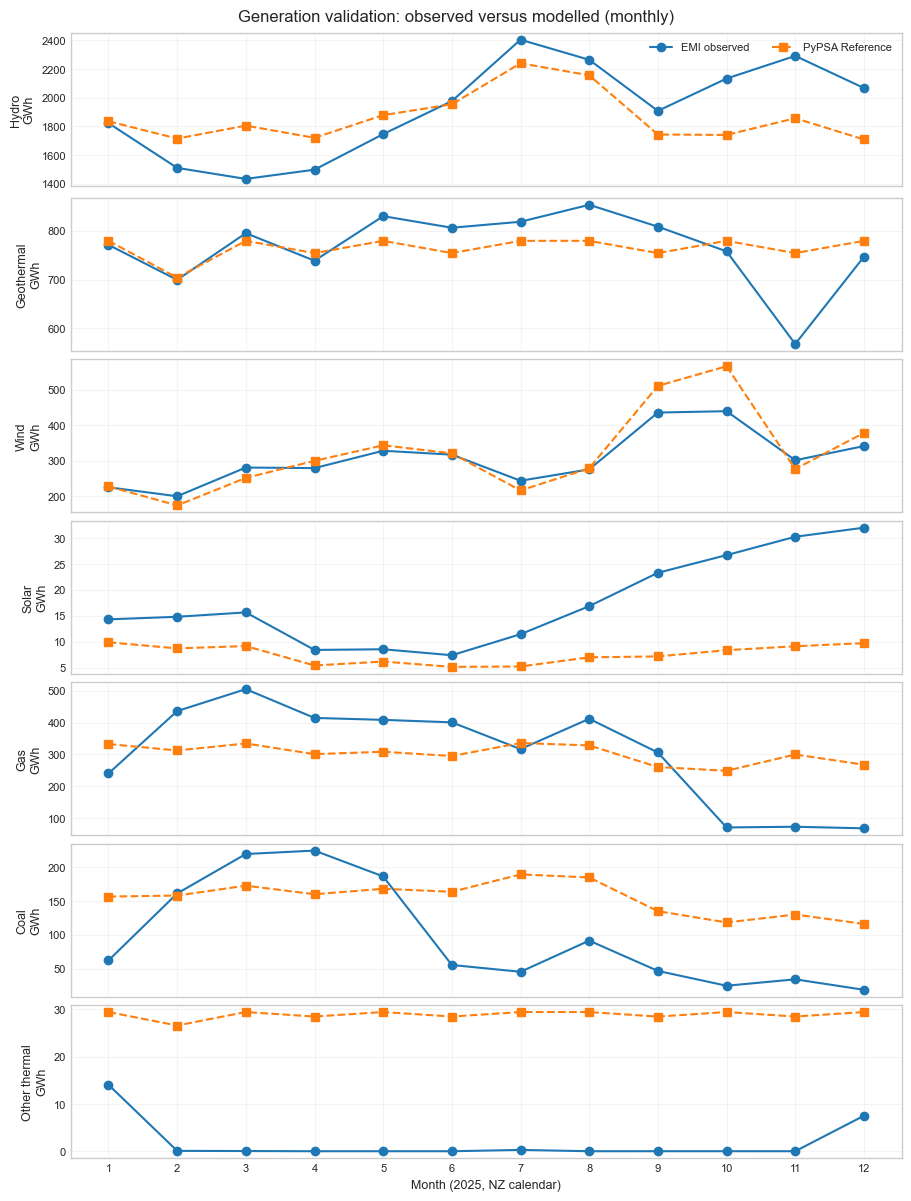

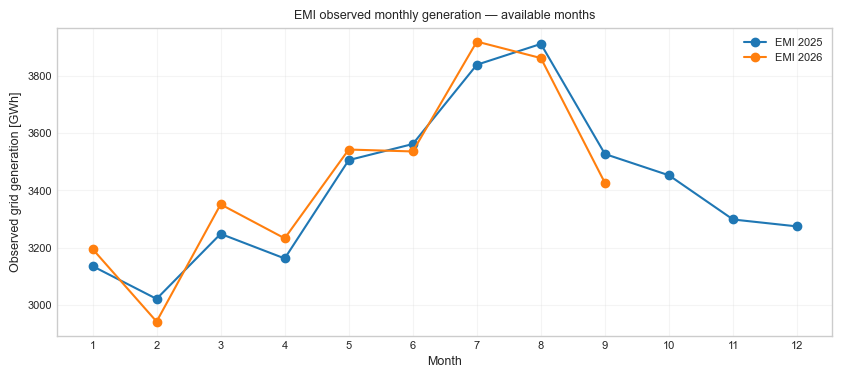

In [ ]:
# EMI generation validation — self-contained cell (no solver run).
# INPUT : model/data_nz_generation/generation_md/YYYYMM_Generation_MD.csv
# OUTPUT: model/output/output_new_zealand/observatory/nz_generation_validation.xlsx
from pathlib import Path
from datetime import datetime, timezone
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import pypsa
from IPython.display import display

EMI_DIR = Path('data_nz_generation') / 'generation_md'
VALIDATION_OUTPUT = Path('output') / 'output_new_zealand' / 'observatory' / 'nz_generation_validation.xlsx'
VALIDATION_NETWORK_YEAR = 2025
VALIDATION_YEARS = (2025, 2026)  # 2026 is observed-only until its Reference network exists.
# Model snapshots are timezone-naive NZ local-clock hours.
MODEL_TIME_ZONE = "Pacific/Auckland"


def _emi_technology(fuel, tech):
    """Keep unrecognised codes visible rather than forcing them into a technology."""
    s = ' '.join([str(fuel).upper(), str(tech).upper()])
    if any(x in s for x in ('HYD', 'WATER')): return 'Hydro'
    if 'GEO' in s: return 'Geothermal'
    if any(x in s for x in ('WND', 'WIND')): return 'Wind'
    if any(x in s for x in ('SOL', 'PHOTOVOLTAIC', ' PV ')): return 'Solar'
    if any(x in s for x in ('COAL', ' COAL ', ' COL ')): return 'Coal'
    if any(x in s for x in ('GAS', 'LPG', 'NATURAL')): return 'Gas'
    if any(x in s for x in ('DIESEL', ' OIL', 'WOOD', 'BIO', 'COGEN', 'THERM')): return 'Other thermal'
    return 'Unmapped'


def _model_technology(carrier):
    s = str(carrier).strip().lower()
    if s == 'slack': return 'Slack'
    if s.startswith('hydro'): return 'Hydro'
    if 'geo' in s: return 'Geothermal'
    if 'wind' in s: return 'Wind'
    if s.startswith(('solar', 'pv')): return 'Solar'
    if 'coal' in s: return 'Coal'
    if any(x in s for x in ('ccgt', 'ocgt', 'gas')): return 'Gas'
    if any(x in s for x in ('diesel', 'cogeneration', 'bio', 'oil')): return 'Other thermal'
    return 'Other modelled'


def _read_emi_month(path):
    """One EMI file: kWh per half-hour trading period -> hourly MWh and plant-year MWh."""
    raw = pd.read_csv(path, comment='#', low_memory=False)
    raw.columns = [str(c).strip() for c in raw.columns]
    name_lookup = {str(c).lower(): c for c in raw.columns}
    required = ('trading_date', 'poc_code', 'gen_code', 'fuel_code', 'tech_code')
    missing = [c for c in required if c not in name_lookup]
    if missing:
        raise ValueError(f'{path.name}: missing EMI columns: {missing}')
    raw = raw.rename(columns={name_lookup[c]: c for c in required})
    tp_cols = sorted([c for c in raw.columns if re.fullmatch(r'TP\d{1,2}', c, re.I)],
                     key=lambda c: int(c[2:]))
    if not tp_cols:
        raise ValueError(f'{path.name}: missing TP1..TP48/50 columns')
    raw['trading_date'] = pd.to_datetime(raw['trading_date'], format='%Y-%m-%d', errors='coerce').dt.normalize()
    if raw['trading_date'].isna().any():
        raise ValueError(f'{path.name}: invalid Trading_date')
    raw['technology'] = [_emi_technology(f, t) for f, t in zip(raw.fuel_code, raw.tech_code)]
    for c in tp_cols:
        raw[c] = pd.to_numeric(raw[c], errors='coerce')
    # Sum trading-period energy; missing TP49/50 on normal days is expected.
    raw['observed_mwh'] = raw[tp_cols].sum(axis=1, min_count=1) / 1000.0
    plant = (raw.groupby(['trading_date', 'poc_code', 'gen_code', 'fuel_code', 'tech_code', 'technology'],
                         dropna=False, as_index=False)['observed_mwh'].sum())
    long = raw[['trading_date', 'technology'] + tp_cols].melt(
        id_vars=['trading_date', 'technology'], value_vars=tp_cols,
        var_name='tp', value_name='kwh').dropna(subset=['kwh'])
    long['tp_number'] = long['tp'].str.extract(r'(\d+)').astype('int16')
    start_nz = long['trading_date'].dt.tz_localize('Pacific/Auckland')
    long['timestamp_utc'] = (start_nz + pd.to_timedelta((long['tp_number'] - 1) * 30, unit='min'))\
        .dt.tz_convert('UTC').dt.floor('h').dt.tz_localize(None)
    long['mwh'] = long['kwh'] / 1000.0
    hourly = long.groupby(['timestamp_utc', 'technology'], as_index=False)['mwh'].sum()
    return plant, hourly


def _model_generation_hourly(net):
    frames = []
    for table_name, timeseries_name in [('generators', 'generators_t'),
                                        ('storage_units', 'storage_units_t')]:
        table = getattr(net, table_name)
        pnl = getattr(net, timeseries_name)
        if len(table) == 0 or 'p' not in pnl:
            continue
        p = pnl.p.copy()
        # Positive StorageUnit p is generation/discharge. Charging is not generation.
        p = p.clip(lower=0).rename(columns=table['carrier'].map(_model_technology).to_dict())
        by_tech = p.T.groupby(level=0).sum().T
        frames.append(by_tech)
    if not frames:
        raise ValueError('The Reference network has no generator dispatch results.')
    grouped = pd.concat(frames, axis=1).T.groupby(level=0).sum().T
    grouped.index = pd.to_datetime(grouped.index)
    # All model snapshots are hourly (MWh = MW * 1 h).
    if (grouped.index.to_series().diff().dropna() != pd.Timedelta(hours=1)).any():
        raise ValueError('This validation cell expects an hourly Reference network.')
    hourly = (
        grouped.rename_axis("timestamp_local")
        .stack()
        .rename("modelled_mwh")
        .rename_axis(index=["timestamp_local", "technology"])
        .reset_index()
    )
    local = pd.DatetimeIndex(hourly["timestamp_local"])
    # DST has one repeated and one nonexistent local hour. Exclude these two
    # ambiguous clock labels from hourly comparisons, but keep their energy
    # in the annual and monthly model totals.
    hourly["timestamp_utc"] = (
        local.tz_localize(MODEL_TIME_ZONE, ambiguous="NaT", nonexistent="NaT")
        .tz_convert("UTC")
        .tz_localize(None)
    )
    return hourly[["timestamp_local", "timestamp_utc", "technology", "modelled_mwh"]]


def _comparison_table(observed, modelled, keys):
    out = pd.merge(observed, modelled, how='outer', on=keys)
    # Missing technology in either source is genuinely zero generation, provided
    # both datasets cover the time interval. Missing YEARS/MONTHS stay NaN below.
    out['observed_mwh'] = pd.to_numeric(out['observed_mwh'], errors='coerce')
    out['modelled_mwh'] = pd.to_numeric(out['modelled_mwh'], errors='coerce')
    return out


emi_files = sorted(p for p in EMI_DIR.glob('*_Generation_MD.csv')
                   if re.match(r'^\d{6}_Generation_MD\.csv$', p.name, re.I)
                   and int(p.name[:4]) in VALIDATION_YEARS)
if not emi_files:
    print(f'EMI validation: no YYYYMM_Generation_MD.csv files in {EMI_DIR.resolve()}')
    print('Add the monthly EMI files and rerun only this cell. No workbook was written.')
else:
    # Never overwrite a valid workbook with an incomplete load caused by a CSV error.
    plants_by_month, hours_by_month = [], []
    months_found = set()
    for path in emi_files:
        month_id = path.name[:6]
        if month_id in months_found:
            raise ValueError(f'Duplicate EMI month: {month_id}')
        months_found.add(month_id)
        plants, hourly = _read_emi_month(path)
        plants_by_month.append(plants)
        hours_by_month.append(hourly)
    observed_plants = pd.concat(plants_by_month, ignore_index=True)
    observed_hours = pd.concat(hours_by_month, ignore_index=True)\
        .groupby(['timestamp_utc', 'technology'], as_index=False)['mwh'].sum()\
        .rename(columns={'mwh': 'observed_mwh'})
    observed_plants['year'] = observed_plants.trading_date.dt.year
    observed_plants['month'] = observed_plants.trading_date.dt.month
    obs_monthly = observed_plants.groupby(['year', 'month', 'technology'], as_index=False)['observed_mwh'].sum()
    obs_annual = observed_plants.groupby(['year', 'technology'], as_index=False)['observed_mwh'].sum()

    net_candidates = [Path('output') / 'output_new_zealand' / 'simulations' / 'reference'
                      / str(VALIDATION_NETWORK_YEAR) / 'network.nc', Path('network.nc')]
    net_path = next((p for p in net_candidates if p.exists()), None)
    if net_path is None:
        print('Reference network.nc not found; exporting observed generation only.')
        model_hours = pd.DataFrame({
            "timestamp_local": pd.Series(dtype="datetime64[ns]"),
            "timestamp_utc": pd.Series(dtype="datetime64[ns]"),
            "technology": pd.Series(dtype="str"),
            "modelled_mwh": pd.Series(dtype="float64"),
        })
        hydro_year = ''
    else:
        net_val = pypsa.Network(net_path)
        model_hours = _model_generation_hourly(net_val)
        hydro_year = net_val.meta.get('hydrology_year', '') if isinstance(net_val.meta, dict) else ''
        # Network hydrology year may instead be an optional custom property.
        hydro_year = getattr(net_val, '_hydrology_year', hydro_year)
        del net_val

    model_hours["year"] = model_hours["timestamp_local"].dt.year
    model_hours["month"] = model_hours["timestamp_local"].dt.month
    model_monthly = model_hours.groupby(['year', 'month', 'technology'], as_index=False)['modelled_mwh'].sum()
    model_annual = model_hours.groupby(['year', 'technology'], as_index=False)['modelled_mwh'].sum()

    monthly = _comparison_table(obs_monthly, model_monthly, ['year', 'month', 'technology'])
    annual = _comparison_table(obs_annual, model_annual, ['year', 'technology'])
    available_months = sorted((int(x[:4]), int(x[4:])) for x in months_found)
    coverage = pd.DataFrame(available_months, columns=['year', 'month'])
    coverage['file_available'] = True
    monthly = monthly.merge(coverage, how='outer', on=['year', 'month'])
    # If a month is not uploaded, modelled energy must NOT be compared with 0 MWh.
    monthly['comparison_ready'] = monthly['file_available'].eq(True) & monthly['modelled_mwh'].notna()
    monthly.loc[~monthly['file_available'].eq(True), 'observed_mwh'] = np.nan
    monthly['difference_mwh'] = (monthly['modelled_mwh'] - monthly['observed_mwh'])\
        .where(monthly['comparison_ready'])
    monthly['bias_pct'] = (100 * monthly['difference_mwh'] /
                           monthly['observed_mwh'].replace(0, np.nan))
    monthly = monthly.sort_values(['year', 'month', 'technology']).reset_index(drop=True)
    coverage_count = coverage.groupby('year')['month'].nunique().rename('months_loaded')
    annual = annual.merge(coverage_count, on='year', how='left')
    annual['complete_year'] = annual['months_loaded'].eq(12)
    annual['comparison_ready'] = annual['complete_year'] & annual['modelled_mwh'].notna()
    annual['difference_mwh'] = (annual['modelled_mwh'] - annual['observed_mwh'])\
        .where(annual['comparison_ready'])
    annual['bias_pct'] = 100 * annual['difference_mwh'] / annual['observed_mwh'].replace(0, np.nan)
    annual = annual.sort_values(['year', 'technology']).reset_index(drop=True)

    model_utc_hours = model_hours.dropna(subset=["timestamp_utc"])
    hourly = _comparison_table(
        observed_hours,
        model_utc_hours[["timestamp_utc", "technology", "modelled_mwh"]],
        ["timestamp_utc", "technology"],
    )
    # DST clock-transition hours were excluded from the model's UTC mapping.
    # Compact *wide* layout: one timestamp per row for easy web chart consumption.
    hourly = hourly.pivot(index='timestamp_utc', columns='technology',
                          values=['observed_mwh', 'modelled_mwh'])
    hourly.columns = [f'{kind.replace("_mwh", "")}_{tech.lower().replace(" ", "_")}_mwh'
                      for kind, tech in hourly.columns]
    hourly = hourly.sort_index().reset_index()
    hourly.insert(1, "timestamp_basis", "NZ_local_model_converted_to_UTC_DST_exclusions")
    observed_plants = observed_plants.groupby(
        ['year', 'poc_code', 'gen_code', 'fuel_code', 'tech_code', 'technology'],
        dropna=False, as_index=False)['observed_mwh'].sum()

    quality_rows = []
    for y in VALIDATION_YEARS:
        have = {m for yr, m in available_months if yr == y}
        for m in range(1, 13):
            quality_rows.append({'year': y, 'month': m, 'file': f'{y}{m:02d}_Generation_MD.csv',
                                 'present': m in have})
    quality = pd.DataFrame(quality_rows)
    unknown = observed_plants[observed_plants.technology == 'Unmapped']
    if not unknown.empty:
        print('WARNING: Unmapped EMI fuel/technology codes; inspect the plants sheet:')
        display(unknown[['fuel_code', 'tech_code']].drop_duplicates())

    metadata = pd.DataFrame([
        ('source', 'Electricity Authority EMI / Generation_MD'),
        ('source_url', 'https://www.emi.ea.govt.nz/Wholesale/Datasets/Generation/Generation_MD'),
        ('source_unit', 'kWh per trading period; converted to MWh'),
        ('model_network_path', str(net_path) if net_path else 'not found'),
        ('model_year', VALIDATION_NETWORK_YEAR),
        ('hydrology_year', hydro_year if pd.notna(hydro_year) else ''),
        ('months_loaded', ', '.join(sorted(months_found))),
        ('observed_time_zone', 'Pacific/Auckland; converted to UTC for hourly records'),
        ("model_time_zone", "NZ local clock (Pacific/Auckland); UTC mapped for hourly EMI"),
        ('annual_monthly_note', 'Calendar-year/month energy; full-year bias only if 12 EMI months loaded'),
        ("hourly_note", "DST transition hours excluded from UTC comparisons; no hourly scores reported"),
        ('technology_note', 'Hydro includes StorageUnit discharges; Slack excluded from physical generation comparisons'),
        ('coverage_note', 'EMI generation is estimated grid injection; distributed PV and network boundary may differ'),
        ('generated_at_utc', datetime.now(timezone.utc).isoformat()),
    ], columns=['item', 'value'])

    VALIDATION_OUTPUT.parent.mkdir(parents=True, exist_ok=True)
    with pd.ExcelWriter(VALIDATION_OUTPUT, engine='openpyxl', datetime_format='yyyy-mm-dd hh:mm') as writer:
        metadata.to_excel(writer, sheet_name='metadata', index=False)
        annual.to_excel(writer, sheet_name='annual', index=False)
        monthly.to_excel(writer, sheet_name='monthly', index=False)
        hourly.to_excel(writer, sheet_name='hourly', index=False)
        observed_plants.to_excel(writer, sheet_name='plants', index=False)
        quality.to_excel(writer, sheet_name='coverage', index=False)
        for sheet in writer.book:
            sheet.freeze_panes = 'A2'
            sheet.auto_filter.ref = sheet.dimensions
            sample_rows = list(sheet.iter_rows(min_row=1, max_row=min(sheet.max_row, 300),
                                               values_only=True))
            from openpyxl.utils import get_column_letter
            for number, values in enumerate(zip(*sample_rows), start=1):
                max_chars = max((len(str(v)) if v is not None else 0 for v in values), default=10)
                sheet.column_dimensions[get_column_letter(number)].width = min(45, max(13, max_chars + 2))

    print(f'\nEMI validation workbook: {VALIDATION_OUTPUT.resolve()}')
    print(f'Loaded: {len(months_found)} months | observed year(s): {sorted(obs_annual.year.unique())}')
    if net_path:
        print(f'Model: Reference {VALIDATION_NETWORK_YEAR} ({net_path})')
    display(annual[['year', 'technology', 'observed_mwh', 'modelled_mwh', 'bias_pct',
                    'months_loaded', 'comparison_ready']].round(1))

    # Figure 1 — Monthly energy, observed vs modelled, Reference 2025.
    plot_data = monthly[(monthly.year == VALIDATION_NETWORK_YEAR) &
                        (monthly.comparison_ready) &
                        (~monthly.technology.isin(['Slack', 'Unmapped', 'Other modelled']))]
    if not plot_data.empty:
        groups = [g for g in ('Hydro', 'Geothermal', 'Wind', 'Solar', 'Gas', 'Coal', 'Other thermal')
                  if g in set(plot_data.technology)]
        fig, axs = plt.subplots(len(groups), 1, figsize=(9, max(3, 1.7*len(groups))),
                                sharex=True, constrained_layout=True)
        axs = np.atleast_1d(axs)
        for ax, tech in zip(axs, groups):
            p = plot_data[plot_data.technology == tech].sort_values('month')
            ax.plot(p.month, p.observed_mwh / 1000, 'o-', label='EMI observed')
            ax.plot(p.month, p.modelled_mwh / 1000, 's--', label='PyPSA Reference')
            ax.set_ylabel(f'{tech}\nGWh')
            ax.grid(alpha=.2)
        axs[0].legend(ncol=2, loc='upper right')
        axs[-1].set_xticks(range(1, 13))
        axs[-1].set_xlabel('Month (2025, NZ calendar)')
        fig.suptitle('Generation validation: observed versus modelled (monthly)', fontsize=12)
        plt.show()

    # Figure 2 — Observed recent-year evolution, no 2026 model validation implied.
    obs_plot = obs_monthly[obs_monthly.technology.isin(['Hydro', 'Geothermal', 'Wind', 'Solar', 'Gas', 'Coal'])]
    if not obs_plot.empty:
        fig, ax = plt.subplots(figsize=(10, 4))
        for y in sorted(obs_plot.year.unique()):
            series = obs_plot[obs_plot.year == y].groupby('month')['observed_mwh'].sum()
            ax.plot(series.index, series / 1000, marker='o', label=f'EMI {y}')
        ax.set(xticks=range(1, 13), xlabel='Month', ylabel='Observed grid generation [GWh]',
               title='EMI observed monthly generation — available months')
        ax.legend()
        ax.grid(alpha=.2)
        plt.show()


### 10.1 Thermal fuel budget and 2025 calibration audit
Review generator dispatch, gas-fuel input and electricity emissions directly from the saved Reference network. An optional `fuel_limits.csv` in `input_new_zealand/` is enforced by `config_fuel_limits.py` during optimisation. An observed generation mix is a validation benchmark, not a fuel-supply constraint. Do not interpret CO₂ as CO₂e without matching scope.

In [ ]:
def audit_thermal_calibration(net_path: Path, targets: dict | None = None) -> pd.DataFrame:
    """Summarise thermal generation, fuel inputs and direct combustion CO2."""
    net = pypsa.Network(net_path)
    weights = net.snapshot_weightings.generators.reindex(net.snapshots)
    generation = net.generators_t.p.multiply(weights, axis=0).sum(axis=0)
    meta = net.generators.reindex(generation.index)
    fuel_factor = pd.to_numeric(
        meta["carrier"].map(net.carriers["co2_emissions"]), errors="coerce"
    ).fillna(0.0)
    efficiency = pd.to_numeric(meta["efficiency"], errors="coerce")
    carrier = meta["carrier"].astype(str)
    gas = {"ccgt", "ocgt", "gas_peaker", "gas_cogeneration"}
    coal = {"coal"}
    thermal = gas | coal | {"diesel", "diesel_peaker", "other_cogeneration"}
    rows = []
    for group, selected in (
        ("Gas", carrier.isin(gas)),
        ("Coal", carrier.isin(coal)),
        ("Other thermal", carrier.isin(thermal - gas - coal)),
    ):
        output = generation[selected]
        eff = efficiency[selected]
        valid = eff.gt(0) & eff.notna()
        if not valid.all():
            raise ValueError(f"Invalid generation efficiency in {group}.")
        rows.append({
            "fuel": group,
            "generation_gwh": output.sum() / 1e3,
            "fuel_input_pj": (output / eff).sum() * 3.6e-6,
            "combustion_ktco2": (output * fuel_factor[selected] / eff).sum() / 1e3,
        })
    result = pd.DataFrame(rows)
    observed = targets or {"Gas": 3654.0, "Coal": 1169.0}
    result["emi_generation_gwh"] = result["fuel"].map(observed)
    result["generation_bias_pct"] = (
        100 * (result["generation_gwh"] / result["emi_generation_gwh"] - 1)
    )
    if "fuel_budget_group" in meta.columns:
        budgets = meta[["fuel_budget_group", "fuel_budget_mwh_th"]].copy()
        budgets = budgets[budgets["fuel_budget_group"].notna()]
        budgets = budgets[budgets["fuel_budget_group"].ne("")]
        if not budgets.empty:
            print("Configured fuel budgets (PJ):")
            display(
                (budgets.groupby("fuel_budget_group")["fuel_budget_mwh_th"].first()
                 * 3.6e-6).rename("PJ").to_frame()
            )
    print(f"Input network: {net_path}")
    print(f"Total electricity demand: {net.loads_t.p_set.sum().sum() / 1e6:.3f} TWh")
    display(result.round(2))
    return result


# Run without solving; uses the currently exported long-term Reference.
THERMAL_AUDIT_YEAR = 2025
thermal_reference_path = _locate_short_term_reference_network(THERMAL_AUDIT_YEAR)
thermal_calibration_audit = audit_thermal_calibration(thermal_reference_path)


Configured fuel budgets (PJ):


,PJ
fuel_budget_group,
natural_gas,27.0


Input network: output\output_new_zealand\simulations\reference\2025\network.nc
Total electricity demand: 40.820 TWh


,fuel,generation_gwh,fuel_input_pj,combustion_ktco2,emi_generation_gwh,generation_bias_pct
0,Gas,3626.95,27.00,1515.00,3654.0,-0.74
1,Coal,1851.53,20.18,1911.65,1169.0,58.39
2,Other thermal,346.88,1.25,70.07,NaN,NaN


In [ ]:
# Check CO2 units against the active Reference network and costs.csv.
from pathlib import Path


def audit_carrier_emission_factors(network_path: Path, costs_path: str) -> pd.DataFrame:
    net = pypsa.Network(network_path)
    costs = pd.read_csv(costs_path, comment="#")
    generic = costs.loc[
        costs["cost_key"].astype(str).str.strip().str.lower()
        == costs["technology"].astype(str).str.strip().str.lower()
    ].copy()
    generic["technology"] = generic["technology"].astype(str).str.strip().str.lower()
    generic = generic.drop_duplicates(subset="technology", keep="last")
    factors = pd.to_numeric(generic.set_index("technology")["co2_emissions"], errors="coerce")
    current = pd.to_numeric(net.carriers["co2_emissions"], errors="coerce")
    rows = []
    for technology in ("ccgt", "coal", "gas_peaker", "ocgt", "geothermal"):
        if technology not in current.index or technology not in factors.index:
            continue
        source = float(factors.loc[technology])
        active = float(current.loc[technology])
        rows.append({
            "carrier": technology,
            "csv_tco2_per_mwh_th": source,
            "network_tco2_per_mwh_th": active,
            "match": np.isclose(source, active, rtol=1e-8, atol=1e-10),
        })
    result = pd.DataFrame(rows)
    if not result.empty and not result["match"].all():
        raise ValueError("Network carrier CO2 factors differ from generic costs.csv factors.")
    print("Emissions: fuel-combustion CO2 only; excludes geothermal process CO2/CO2e.")
    display(result)
    return result


carrier_emission_audit = audit_carrier_emission_factors(
    _locate_short_term_reference_network(2025), paths_base["csv_costs"]
)


Emissions: fuel-combustion CO2 only; excludes geothermal process CO2/CO2e.


,carrier,csv_tco2_per_mwh_th,network_tco2_per_mwh_th,match
0,ccgt,0.202,0.202,True
1,coal,0.341,0.341,True
2,gas_peaker,0.202,0.202,True
3,ocgt,0.202,0.202,True
